# NB06 CLEAN — Musanga satellite abundance and spatial structure (V3.1)

**New reproducible workflow; previous 83-cell NB06 is archived unchanged.** Goal: combine Sentinel-2 seasonal signals (S), 64D annual embeddings (E), and native 4.77 m PlanetScope structure (P) to predict UAV-derived Musanga canopy fraction.

**Research sequence**
1. Reproduce S2-only, E-only, S2+E 50 m baseline from frozen reference cells, forest- and abundance-balanced; distinguish 400 m buffered spatial folds (where R² ~0.6 was obtained) from **strict LOFO**, which was considerably harder.
2. Test spatial context of 64D embeddings with a genuine **2D CNN**, matched against an embedding pointwise baseline on *identical held-out 50 m cells*.
3. Train the **actual UAV-style ResNet18 U-Net** with Planet B/G/R/NIR native 4.77 m patches, comparing train-only global scaling, per-tile scaling and dual reflectance. Model changes documented, not silently substituting the previous small Planet U-Net.
4. Evaluate aggregation onto **common** 10, 30, 50, 75, 100, 125 m grids, not old tile-local cells.
5. Evaluate learned S/E/P branches and all seven input combinations on the same cells/folds, with high-cover bias/recall, equal-forest MAE/R² and calibration.

**Immutable rules:** Baego, MOS (both mosaics held out together), Yangambi, Yoko. Four independent held-out forests. No held-out label leakage; strict reference & footprint comparisons. UAV maps are pseudo-labels, not independent ground truth. Threshold for high cover = 40%. Each stage saves its own inputs, manifests, predictions, models and validation tables.

**Status:** Step 1 runnable below; Steps 2–5 are locked experiment protocols, to be implemented after the baseline is verified. This deliberate division avoids another sprawling experimental notebook.

**Evaluation update (2026-10-26):** primary scores are forest-balanced GLOBAL R², MAE, RMSE and bias, not the arithmetic mean of forest-specific R². Block 04 is the common-cell Planet versus S2+EMB comparison. Existing training data, seeds, checkpoints and predictors remain unchanged.


## 00 — Mount Drive, then locate and validate actual inputs

This cell mounts Google Drive automatically when no known Musanga workspace is visible, **before** searching outputs. If Drive is mounted but caches are missing, it prints an inventory and stops. It never fabricates input files or regenerates imagery.


In [ ]:
# 00 — DRIVE must already be mounted
from pathlib import Path
import numpy as np,pandas as pd,os,json,hashlib
from IPython.display import display
# Original Musanga notebooks accept BOTH workspace locations. Never create an empty
# output folder until an existing source tree is identified.
# 00A — Drive preflight: mounting MUST precede any file inventory.
# Only invoke Colab mount when the expected workspace is not already visible.
KNOWN_FINALS=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
              Path('/content/drive/MyDrive/Musanga/Final')]
if not any(f.is_dir() for f in KNOWN_FINALS):
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            'This notebook expects Google Colab with Google Drive connected. '
            'No Musanga workspace is visible in the current Python runtime.') from exc
    print('Musanga workspace not visible: mounting Google Drive now.',flush=True)
    drive.mount('/content/drive')
assert Path('/content/drive/MyDrive').is_dir(),(
    'Drive mount did not expose /content/drive/MyDrive. '
    'Inspect Colab Drive authorization and mount status.')
print('Drive mounted:',Path('/content/drive/MyDrive').is_dir())
ROOTS=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1'),
       Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1')]
SITES=('Baego','MOS','Yangambi','Yoko');KEYS=['site','mosaic','row','col'];HIGH=.4
inventory=[]
for root in ROOTS:
    base=root/'06_spatial_planet_embeddings'
    inventory.append(dict(root=str(root),root_exists=root.is_dir(),
        legacy06_exists=base.is_dir(),
        spatial_file=(base/'10_full_spatial_features_50m.parquet').is_file(),
        target09=(base/'09_uav_targets_50m.parquet').is_file(),
        combined_50m=len(list((base/'11_spatial_ablation_50m/inputs').glob('combined_50m_*.parquet'))),
        legacy_lofo=len(list((base/'11_spatial_ablation_50m/fold_predictions').glob('*/LEAVE_FOREST_OUT_*_B0_S2_EMB.parquet')))))
print('READ-ONLY INPUT INVENTORY (no new extraction):')
display(pd.DataFrame(inventory))
usable=[row for row in inventory if row['combined_50m']>0]
if len(usable)!=1:
    raise FileNotFoundError(
        'Expected exactly one existing 11A satellite cache across known Musanga workspaces. '
        'Cannot reproduce the 50 m baseline without its predictor table. '
        'Copy the input inventory above and identify the workspace if you need help. '
        f'Found {len(usable)} candidates; will not invent or silently regenerate inputs.')
root=Path(usable[0]['root'])
BASE=root/'06_spatial_planet_embeddings'
B11=BASE/'11_spatial_ablation_50m'
OUT=BASE/'CLEAN_NB06';OUT.mkdir(parents=True,exist_ok=True)
spatial_file=BASE/'10_full_spatial_features_50m.parquet'
target09=BASE/'09_uav_targets_50m.parquet'
if spatial_file.is_file():
    reference=pd.read_parquet(spatial_file)
    assert 'target_fraction' in reference
    if 'accepted' in reference:
        reference=reference[reference.accepted.astype(bool)].copy()
    print('Independent source: Section 10 accepted table',spatial_file)
elif target09.is_file():
    reference=pd.read_parquet(target09)
    assert 'mean_probability' in reference
    reference=reference.rename(columns={'mean_probability':'target_fraction'})
    print('Independent source: Section 09 UAV target table',target09)
else:
    reference=None
    print('Neither Section 09 nor Section 10 target file is present.')
    print('Will validate the 11A cache internally (unique keys, finite targets, fixed')
    print('site counts, complete predictor masks) but cannot independently confirm')
    print('its UAV targets against a separate source.')
if reference is not None:
    assert not reference.duplicated(KEYS).any()
    reference=reference.sort_values(KEYS).reset_index(drop=True)
ref={}
for site in SITES:
    matches=sorted((B11/'fold_predictions').glob(
        f'*/LEAVE_FOREST_OUT_{site}_B0_S2_EMB.parquet'))
    if len(matches)==1:
        z=pd.read_parquet(matches[0],columns=KEYS+['observed','predicted'])
        ref[site]=z.sort_values(KEYS).reset_index(drop=True)
    else:
        print('Archive B0 LOFO file not required:',site,'found',len(matches),
              '— using available reference/checks instead')
candidates=sorted((B11/'inputs').glob('combined_50m_*.parquet'));found=[]
for path in candidates:
    d=pd.read_parquet(path)
    if d.duplicated(KEYS).any() or 'target_fraction' not in d:continue
    satellite=[c for c in d if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__','EMB_ANNUAL__'))]
    planet=[f'PLANET_{q}_{b}' for q in ('mean','std') for b in ('B','G','R','N')]
    planet += [f'PLANET_texture_{b}' for b in ('NIR_CV_r1','NIR_CV_r3','NIR_CV_r7','NIR_highpass')]
    context=[f'EMB_{q}_{j:02d}' for q in ('mean','sd') for j in range(1,65)]
    count=[f'S2_QUARTERLY_3YR__{i:02d}' for i in (11,22,33,44)]
    required=satellite+planet+context
    if not set(required+count).issubset(d.columns):continue
    good=np.isfinite(d[required].to_numpy('float32')).all(1)&(d[count].to_numpy('float32')>=1).all(1)&d.target_fraction.between(0,1).to_numpy()
    d=d.loc[good].sort_values(KEYS).reset_index(drop=True)
    # The authoritative reference does not depend on completed model fits.
    if reference is not None:
        # Section 09 may contain MORE cells than Section 10 (which filtered patches).
        check=reference[reference.set_index(KEYS).index.isin(
            d.set_index(KEYS).index)].reset_index(drop=True)
        agree=(len(check)==len(d) and d[KEYS].equals(check[KEYS])
               and np.allclose(d.target_fraction,check.target_fraction,rtol=0,atol=1e-6))
    else:
        # No independent source: strict 11A coverage and known historical sample count.
        expected={'Baego':480,'MOS':11494,'Yangambi':1383,'Yoko':1097}
        agree=(len(d)==14454 and d.groupby('site').size().to_dict()==expected
               and d[KEYS].notna().all().all() and {'x','y'}.issubset(d.columns)
               and np.isfinite(d[['x','y','target_fraction']].to_numpy(float)).all())
    # If available, also cross-validate the original held-out predictions.
    if agree:
        for forest,b in ref.items():
            a=d.loc[d.site==forest,KEYS+['target_fraction']].reset_index(drop=True)
            if len(a)!=len(b) or not a[KEYS].equals(b[KEYS]) or not np.allclose(
                    a.target_fraction,b.observed,rtol=0,atol=1e-6):
                agree=False
                break
    if agree:found.append((path,d))
assert len(found)==1,('No unique complete cached 11A table passed validation',
    'Candidate files:',[str(p) for p in candidates],
    'Independent reference:',str(spatial_file) if spatial_file.exists() else str(target09) if target09.exists() else 'not available')
SOURCE,D=found[0]
assert len(D)==14454 and {'x','y'}.issubset(D.columns)
FEATURES={'S2':[c for c in D if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__'))],
          'EMB':[c for c in D if c.startswith('EMB_ANNUAL__')]}
assert len(FEATURES['EMB'])==64
FEATURES['S2_EMB']=FEATURES['S2']+FEATURES['EMB']
D.to_parquet(OUT/'frozen_50m_reference.parquet',index=False)
print('Frozen',len(D),'matched 50m cells; source:',SOURCE)
print('Reference verification:', 'independent UAV target cross-check' if reference is not None else '11A internal checks only')
print('Predictors:',{k:len(v) for k,v in FEATURES.items()})
display(D.groupby('site').size())





## 01 — Reproducible balanced satellite baseline (S2, E, S2+E)

Use identical 50 m targets and features, three spatial-block folds (400 m, 150 m buffer) **and** four LOFO splits. HGB five-member ensembles, train cap 1500 per forest, target 25% high Musanga ≥40% per selected training forest when available, plus balanced draws among remaining abundance bins. All held-out cells retained. **Do not pool MOS-dominated observations for model selection.**

**Baseline provenance note:** previous ~0.6 spatial R² cannot be assumed for this exact reimplementation. Reproduction is judged by new output, not hard-coded scores.


In [ ]:
# 01A — splits and balanced training selection (no held-out labels in sampling)
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
threadpool_limits(1)
SEED=20261026;CAP=1500;MEMBERS=5
MAX_NEW_FITS=3   # Smoke-test. Switch to None to complete 105 fits.
PARAM=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,min_samples_leaf=35,
           l2_regularization=2,early_stopping=False)
CFG=dict(version='NB06_CLEAN_S2EMB_v1',source=str(SOURCE),n=len(D),seed=SEED,
         cap=CAP,members=MEMBERS,model=PARAM,feature_lengths={k:len(v) for k,v in FEATURES.items()})
RUN=OUT/'01_satellite'/hashlib.sha256(json.dumps(CFG,sort_keys=True).encode()).hexdigest()[:16]
RUN.mkdir(parents=True,exist_ok=True)
cf=RUN/'config.json'
if cf.exists():assert json.loads(cf.read_text())==CFG
else:cf.write_text(json.dumps(CFG,indent=2))
y=D.target_fraction.to_numpy(float);site=D.site.to_numpy();xy=D[['x','y']].to_numpy(float)
bx=np.floor(xy[:,0]/400).astype('int64');by=np.floor(xy[:,1]/400).astype('int64')
fold=np.mod(bx*73856093+by*19349663,3)
FOLDS=[('SPATIAL',str(i)) for i in range(3)]+[('LOFO',s) for s in SITES]
def split(kind,hold):
    test=(fold==int(hold)) if kind=='SPATIAL' else (site==hold)
    allowed=~test
    if kind=='SPATIAL':
        for forest in SITES:
            it=np.flatnonzero(test&(site==forest));tr=np.flatnonzero(allowed&(site==forest))
            if len(it) and len(tr):
                near=cKDTree(xy[it]).query(xy[tr],k=1)[0]<150
                allowed[tr[near]]=False
    if kind=='LOFO':assert not (site[allowed]==hold).any()
    return np.flatnonzero(allowed),np.flatnonzero(test)
def draw_balanced(pool,seed):
    rng=np.random.default_rng(seed);selected=[]
    for forest in SITES:
        ix=pool[site[pool]==forest]
        if not len(ix):continue
        cap=min(CAP,len(ix))
        if len(ix)<=cap:selected.extend(ix.tolist());continue
        labels=np.digitize(y[ix],[.10,.20,.40]);bins={b:ix[labels==b] for b in range(4)}
        n=min(len(bins[3]),int(np.ceil(cap*.25)))
        pick=rng.choice(bins[3],n,replace=False).tolist() if n else []
        bins[3]=np.setdiff1d(bins[3],pick)
        while len(pick)<cap:
            active=[b for b in bins if len(bins[b])]
            assert active
            for b in active:
                n=min(len(bins[b]),max(1,(cap-len(pick))//len(active)),cap-len(pick))
                if n:
                    take=rng.choice(bins[b],n,replace=False)
                    pick.extend(take.tolist());bins[b]=np.setdiff1d(bins[b],take)
                if len(pick)==cap:break
        selected.extend(pick)
    return np.array(sorted(selected),dtype=int)
print('Ready:',len(FOLDS),'validation folds',len(FEATURES),'predictor families')


In [ ]:
# 01B — checkpointed model fits, fixed fold membership and held-out data
jobs=[(kind,hold,family,m) for kind,hold in FOLDS for family in FEATURES for m in range(MEMBERS)]
new=0
for kind,hold,family,m in jobs:
    train,test=split(kind,hold)
    f=RUN/f'{kind}_{hold}_{family}_m{m}.npz'
    if f.is_file():
        with np.load(f,allow_pickle=False) as z:
            assert np.array_equal(z['test_index'],test) and len(z['pred'])==len(test)
        continue
    if MAX_NEW_FITS is not None and new>=MAX_NEW_FITS:break
    indices=draw_balanced(train,SEED+107*m+sum(map(ord,hold))+len(family)*13)
    X=D[FEATURES[family]].to_numpy('float32')
    estimator=HistGradientBoostingRegressor(random_state=SEED+m,**PARAM)
    estimator.fit(X[indices],y[indices]);pred=np.clip(estimator.predict(X[test]),0,1)
    with open(f.with_suffix('.partial'),'wb') as dest:
        np.savez_compressed(dest,test_index=test,pred=pred.astype('float32'))
    os.replace(f.with_suffix('.partial'),f)
    new+=1;print('Finished',kind,hold,family,'member',m,flush=True)
print('Completed',len(list(RUN.glob('*.npz'))),'of',len(jobs),'fits in',RUN)


In [ ]:
# 01C — final metrics ONLY after all 5 ensemble members exist per case
out=[]
for kind,hold in FOLDS:
    train,test=split(kind,hold)
    for family in FEATURES:
        files=[RUN/f'{kind}_{hold}_{family}_m{m}.npz' for m in range(MEMBERS)]
        if not all(f.exists() for f in files):continue
        preds=[]
        for f in files:
            with np.load(f,allow_pickle=False) as z:
                assert np.array_equal(z['test_index'],test)
                preds.append(z['pred'].astype(float))
        prediction=np.mean(preds,axis=0)
        for forest in SITES:
            mask=site[test]==forest
            if not mask.any():continue
            a=y[test][mask];b=prediction[mask];e=b-a;high=a>=HIGH
            out.append(dict(scheme=kind,holdout=hold,model=family,forest=forest,n=len(a),
                 MAE_pp=100*np.mean(np.abs(e)),R2=1-np.sum(e**2)/np.sum((a-a.mean())**2) if np.var(a)>0 else np.nan,
                 bias_pp=100*e.mean(),high_n=int(high.sum()),
                 high_bias_pp=100*e[high].mean() if high.any() else np.nan,
                 high_recall=np.mean(b[high]>=HIGH) if high.any() else np.nan,
                 mean_target=a.mean(),target_var=a.var(),mse=np.mean(e*e),
                 rmse_squared_pp2=10000*np.mean(e*e)))
RES=pd.DataFrame(out)
assert len(RES)>0,'No complete ensemble yet; continue 01B with MAX_NEW_FITS=None'
print('Per-forest results; LOFO contains exactly one held-out forest each:')
display(RES.round(3))
rows=[]
for (scheme,hold,model),g in RES.groupby(['scheme','holdout','model']):
    u=g.mean_target.mean();var=np.mean(g.target_var+(g.mean_target-u)**2)
    rows.append(dict(scheme=scheme,holdout=hold,model=model,n_forests=len(g),
                     equal_forest_MAE_pp=g.MAE_pp.mean(),equal_forest_R2=1-g.mse.mean()/var,
                     mean_forest_R2=g.R2.mean(),
                     equal_forest_RMSE_pp=float(np.sqrt(g.mse.mean())*100),
                     equal_forest_bias_pp=float(g.bias_pp.mean())))
SUMMARY=pd.DataFrame(rows)
print('Primary: forest-balanced GLOBAL metrics (mean-forest R2 is diagnostic only):')
display(SUMMARY.round(3))
RES.to_csv(RUN/'validation_by_forest.csv',index=False)
SUMMARY.to_csv(RUN/'validation_summary.csv',index=False)
print('Saved',RUN)

# 01C — PRIMARY SCHEME-LEVEL GLOBAL summary: concatenate exactly one held-out
# prediction per reference cell, then weight the FOUR forests equally.
# Per-fold R² above is diagnostic only (LOFO per fold = one site).
scheme_rows01=[];forest_rows01=[]
for scheme in ('SPATIAL','LOFO'):
    holds=[h for k,h in FOLDS if k==scheme]
    for model in FEATURES:
        predall=np.full(len(D),np.nan,dtype='float64')
        for hold in holds:
            _,test=split(scheme,hold)
            files=[RUN/f'{scheme}_{hold}_{model}_m{m}.npz' for m in range(MEMBERS)]
            if not all(x.exists() for x in files):break
            arr=[]
            for path in files:
                with np.load(path,allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'],test)
                    arr.append(z['pred'].astype(float))
            assert np.isnan(predall[test]).all(), 'Duplicate held-out predictions'
            predall[test]=np.mean(arr,axis=0)
        if not np.isfinite(predall).all():
            print('01C global incomplete:',scheme,model,'— no global score');continue
        by_forest=[]
        for forest in SITES:
            mask=site==forest
            actual=y[mask];estimate=predall[mask]
            error=estimate-actual;high=actual>=HIGH
            by_forest.append(dict(scheme=scheme,model=model,forest=forest,
                n=int(mask.sum()),ref_mean=float(actual.mean()),ref_var=float(actual.var()),
                mse=float(np.mean(error**2)),MAE_pp=float(100*np.abs(error).mean()),
                bias_pp=float(100*error.mean()),
                high_n=int(high.sum()),
                high_bias_pp=float(100*error[high].mean()) if high.any() else np.nan,
                high_recall=float(np.mean(estimate[high]>=HIGH)) if high.any() else np.nan))
        forest_rows01.extend(by_forest)
        frame=pd.DataFrame(by_forest)
        common_mu=float(frame.ref_mean.mean())
        common_var=float(np.mean(frame.ref_var+(frame.ref_mean-common_mu)**2))
        mos=frame[frame.forest=='MOS'].iloc[0]
        scheme_rows01.append(dict(scheme=scheme,model=model,n_cells=len(D),n_forests=len(frame),
            equal_forest_global_R2=float(1-frame.mse.mean()/common_var),
            equal_forest_MAE_pp=float(frame.MAE_pp.mean()),
            equal_forest_RMSE_pp=float(100*np.sqrt(frame.mse.mean())),
            equal_forest_bias_pp=float(frame.bias_pp.mean()),
            MOS_high_bias_pp=float(mos.high_bias_pp),
            MOS_high_recall=float(mos.high_recall)))
if scheme_rows01:
    GLOBAL01=pd.DataFrame(scheme_rows01).sort_values(['scheme','model'])
    FOREST01=pd.DataFrame(forest_rows01)
    print('PRIMARY: COMPLETE SCHEME GLOBAL EQUAL-FOREST METRICS (not mean forest R²)')
    display(GLOBAL01.round(3))
    GLOBAL01.to_csv(RUN/'01C_global_equal_forest_complete.csv',index=False)
    FOREST01.to_csv(RUN/'01C_complete_scheme_per_forest.csv',index=False)
else:
    print('No complete global validation scheme yet; rerun 01B with MAX_NEW_FITS=None.')


## 01D — Paired observed–predicted scatterplots and *actual* abundance-balance audit

**Plots:** S2, EMB and S2+EMB in three rows; buffered spatial-block CV and strict LOFO in two columns. All predictions are reconstructed from the **five saved ensemble-member NPZ files**. Each test cell appears **exactly once per model and validation scheme**, and the same stratified display subsample is used for all models (up to 350 test cells per forest). Display sampling is **only for the graphic**; the statistics use **every held-out cell**, with equal-forest weights (not MOS-dominated pooled metrics). Each scatterplot includes the 1:1 line, a forest-balanced binned response curve, equal-forest R² / MAE, and a shared 0–100% axis.

**Abundance audit:** reproduce the exact deterministic `draw_balanced()` selections that trained each ensemble member, then compare full eligible training pools with the actual sampled training sets across the four abundance strata (`<10%`, `10–20%`, `20–40%`, `≥40%`). The sampler balances forests via per-forest caps and *increases representation of high-abundance cells where available*; it does **not guarantee equal numbers in every abundance bin** (particularly for forests below the cap). Show both aggregate and **per-training-forest** percentages. This does not re-fit models or require additional imagery.

Run after **01C** in the same Colab session. PNG + PDF figures and CSV tables are saved beneath `RUN / 'figures'`.


In [ ]:
# 01D — reproducible paired scatterplot and actual training-abundance audit; CPU only
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FIG01D = RUN / 'figures'
FIG01D.mkdir(parents=True, exist_ok=True)
MODEL_ORDER = ['S2', 'EMB', 'S2_EMB']
FOREST_ORDER = list(SITES)
COLOR01D = dict(zip(FOREST_ORDER, ['#3575B7', '#D18B31', '#2B9D80', '#9A63A8']))
MAX_DISPLAY_PER_FOREST = 350
ABUNDANCE_EDGES = np.array([0, .10, .20, .40, 1.0000001])
ABUNDANCE_NAMES = ['0–10%', '10–20%', '20–40%', '≥40%']

# Reconstruct exactly the held-out ensemble mean used by 01C.
frames = []
for scheme in ('SPATIAL', 'LOFO'):
    blocks = [x for x in FOLDS if x[0] == scheme]
    for _, holdout in blocks:
        train_ix, test_ix = split(scheme, holdout)
        for model in MODEL_ORDER:
            sources = [RUN / f'{scheme}_{holdout}_{model}_m{m}.npz'
                       for m in range(MEMBERS)]
            assert all(p.is_file() for p in sources), (
                'Complete 01B before plotting', scheme, holdout, model,
                [str(p) for p in sources if not p.is_file()])
            members = []
            for source in sources:
                with np.load(source, allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'], test_ix), (
                        'Prediction/holdout mismatch', source)
                    members.append(z['pred'].astype('float32'))
            pred = np.mean(np.stack(members), axis=0)
            frames.append(pd.DataFrame({
                'scheme': scheme, 'holdout': str(holdout),
                'model': model, 'row_id': test_ix,
                'forest': site[test_ix], 'observed': y[test_ix],
                'predicted': pred
            }))
PLOT01D = pd.concat(frames, ignore_index=True)
assert np.isfinite(PLOT01D[['observed', 'predicted']].to_numpy()).all()
for scheme in ('SPATIAL', 'LOFO'):
    for model in MODEL_ORDER:
        g = PLOT01D[(PLOT01D.scheme == scheme) & (PLOT01D.model == model)]
        assert len(g) == len(D) and g.row_id.nunique() == len(D), (
            'Expected each reference cell exactly once per validation scheme',
            scheme, model, len(g), g.row_id.nunique(), len(D))
        assert np.array_equal(np.sort(g.row_id.to_numpy()), np.arange(len(D)))

# Forest-equal metrics on ALL test cells (unbalanced MOS counts do not dominate).
rows01d = []
for (scheme, model), g in PLOT01D.groupby(['scheme', 'model'], sort=False):
    per_forest = []
    for forest in FOREST_ORDER:
        a = g.loc[g.forest == forest, 'observed'].to_numpy(float)
        b = g.loc[g.forest == forest, 'predicted'].to_numpy(float)
        e = b - a
        per_forest.append(dict(forest=forest, n=len(a),
            mean_target=a.mean(), target_variance=a.var(),
            MSE=np.square(e).mean(), MAE_pp=100*np.abs(e).mean(),
            R2=(1-np.square(e).sum()/np.square(a-a.mean()).sum()
                if a.var() > 0 else np.nan)))
    f = pd.DataFrame(per_forest).set_index('forest').loc[FOREST_ORDER]
    mean_y = f.mean_target.mean()
    forest_equal_variance = np.mean(
        f.target_variance.to_numpy() + (f.mean_target.to_numpy()-mean_y)**2)
    rows01d.append(dict(scheme=scheme, model=model,
        equal_forest_R2=1-f.MSE.mean()/forest_equal_variance,
        equal_forest_MAE_pp=f.MAE_pp.mean(),
        mean_forest_R2=f.R2.mean(),
        n_test=len(g)))
METRICS01D = pd.DataFrame(rows01d)
print('Full-test-cell metrics (not plotted subset):')
display(METRICS01D.round(3))

# Same display cells for ALL models; fixed number from each forest.
rng = np.random.default_rng(20261026)
display_ids = []
for forest in FOREST_ORDER:
    candidates = np.flatnonzero(site == forest)
    count = min(MAX_DISPLAY_PER_FOREST, len(candidates))
    display_ids.extend(rng.choice(candidates, count, replace=False).tolist())
display_ids = np.asarray(sorted(display_ids), dtype=int)
fig, axs = plt.subplots(3, 2, figsize=(12.6, 16.0),
                         sharex=True, sharey=True, constrained_layout=True)
for row, model in enumerate(MODEL_ORDER):
    for col, scheme in enumerate(('SPATIAL', 'LOFO')):
        ax = axs[row, col]
        g = PLOT01D[(PLOT01D.scheme == scheme) &
                    (PLOT01D.model == model)].set_index('row_id')
        sub = g.loc[display_ids]
        for forest in FOREST_ORDER:
            f = sub[sub.forest == forest]
            ax.scatter(100*f.observed, 100*f.predicted,
                       s=12, alpha=.32, rasterized=True,
                       color=COLOR01D[forest], label=forest)
        ax.plot([0, 100], [0, 100], linestyle='--', color='black',
                linewidth=1, alpha=.65)
        # Show a forest-balanced response by observed abundance, using all
        # held-out cells, NOT the display-only sampling.
        bins = np.arange(0, 1.00001, .10)
        by_forest=[]
        for forest in FOREST_ORDER:
            a = g[g.forest == forest]
            k = np.minimum(np.digitize(a.observed, bins, right=False)-1, 9)
            for q in range(10):
                z = a.iloc[np.flatnonzero(k == q)]
                if len(z):
                    by_forest.append((q, forest, float(z.observed.mean()),
                                      float(z.predicted.mean())))
        curve = pd.DataFrame(by_forest, columns=['bin','forest','obs','pred'])
        line = curve.groupby('bin', as_index=False)[['obs','pred']].mean()
        ax.plot(100*line.obs, 100*line.pred, 'o-', color='#171717',
                markersize=4, linewidth=2, label='Forest-equal binned mean')
        metric = METRICS01D[(METRICS01D.scheme == scheme) &
                            (METRICS01D.model == model)].iloc[0]
        ax.set_title(f'{model} — {scheme} holdout\\n'
            f"equal-forest R²={metric.equal_forest_R2:.3f}  "
            f"MAE={metric.equal_forest_MAE_pp:.2f} pp",
            fontsize=11)
        ax.set_xlim(0,100); ax.set_ylim(0,100)
        ax.grid(alpha=.12)
        if col==0: ax.set_ylabel('Predicted Musanga cover (%)')
        if row==2: ax.set_xlabel('Observed UAV-derived Musanga cover (%)')
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=5,fontsize=9)
fig.suptitle('Satellite abundance: buffered spatial CV versus forest transfer\\n'
             'Matched 50 m reference cells; equal-forest visualization',
             fontsize=14)
png01d=FIG01D/'01D_spatial_vs_LOFO_obs_pred.png'
pdf01d=FIG01D/'01D_spatial_vs_LOFO_obs_pred.pdf'
fig.savefig(png01d,dpi=200,bbox_inches='tight')
fig.savefig(pdf01d,bbox_inches='tight')
plt.show();plt.close(fig)

# Audit training populations and the EXACT member-specific sampled indices.
# NO test labels used to choose training examples.
audit=[]
for scheme,hold in FOLDS:
    eligible,heldout=split(scheme,hold)
    for member in range(MEMBERS):
        for model in MODEL_ORDER:
            indices=draw_balanced(
                eligible, SEED+107*member+sum(map(ord,hold))+len(model)*13)
            for population,ix in [('Eligible pool',eligible),
                                  ('Actual selected',indices)]:
                for forest in FOREST_ORDER:
                    values=y[ix[site[ix]==forest]]
                    if not len(values):continue
                    classes=np.minimum(np.digitize(values,ABUNDANCE_EDGES)-1,3)
                    counts=np.bincount(classes,minlength=4)
                    for j,name in enumerate(ABUNDANCE_NAMES):
                        audit.append(dict(scheme=scheme,holdout=str(hold),
                            model=model,member=member,forest=forest,
                            population=population,bin=name,n=int(counts[j]),
                            forest_total=len(values),
                            fraction=float(counts[j]/len(values))))
AUDIT01D=pd.DataFrame(audit)
# Avoid counting the same eligible reference population repeatedly across
# the five ensemble members/models when summarizing distributions.
audit_summary = (AUDIT01D.groupby(
    ['scheme','population','bin'],as_index=False)
    .agg(mean_forest_fraction=('fraction','mean')))
print('Abundance by training scheme and population (mean across available forests / folds / members):')
display(audit_summary.pivot_table(index=['scheme','population'],
    columns='bin',values='mean_forest_fraction').mul(100).round(1))
print('Actual sampled training proportions for each training forest — LOFO folds:')
per_site01d = (AUDIT01D[(AUDIT01D.scheme=='LOFO') &
                        (AUDIT01D.population=='Actual selected')]
               .groupby(['holdout','forest','bin'],as_index=False)
               .agg(mean_percent=('fraction',lambda x:100*x.mean())))
display(per_site01d.pivot_table(index=['holdout','forest'],
    columns='bin',values='mean_percent').round(1))

# Abundance figure: equal-weighted mean forest share, not absolute pixel counts.
f,ax=plt.subplots(figsize=(9,4.7),layout='constrained')
selected=audit_summary[audit_summary.scheme=='LOFO']
labels=['Eligible pool','Actual selected']
xx=np.arange(2)
bottom=np.zeros(2)
for j,name in enumerate(ABUNDANCE_NAMES):
    vals=np.array([float(selected[(selected.population==p)&
                        (selected.bin==name)].mean_forest_fraction.iloc[0])
                    for p in labels])*100
    ax.bar(xx,vals,bottom=bottom,label=name)
    bottom+=vals
ax.set_xticks(xx,labels)
ax.set_ylim(0,100);ax.set_ylabel('Mean abundance-bin share within forest (%)')
ax.set_title('LOFO: eligible vs actually selected training-cell abundance')
ax.legend(title='UAV-derived cover',bbox_to_anchor=(1.02,1),loc='upper left')
balance_png=FIG01D/'01D_abundance_balance_LOFO.png'
f.savefig(balance_png,dpi=200,bbox_inches='tight')
plt.show();plt.close(f)
METRICS01D.to_csv(FIG01D/'01D_full_support_metrics.csv',index=False)
AUDIT01D.to_csv(FIG01D/'01D_abundance_actual_draws.csv',index=False)
PLOT01D.to_parquet(FIG01D/'01D_all_cell_holdout_predictions.parquet',index=False)
print('01D figures:',png01d,pdf01d,balance_png,sep='\\n  ')
print('No fitting performed. Display-only sampling does not affect metrics.')



## 02A — Native 10 m Earth-embedding spatial neighborhoods (cached only)

**Input:** the same frozen 14,454 50 m reference cell centers as Stage 1 and four annual 64D embedding rasters already extracted in NB04. **No new Earth Engine request.** Extract **9×9 pixels ×64 bands** (90×90 m context at the actual 10 m resolution), centered on each 50 m sample center, with CRS-aware positioning and source valid-data masks. One reusable indexed memmap cache, stable config, progress checkpoint and source-file checks. Source raster coordinates are never inferred from the 50 m row/column numbers.

**Important:** a 50 m target cell overlaps multiple native 10 m embedding pixels. Stage 2 compares the 2D model with a *center-only ablation using the identical CNN network*. The pre-existing HGB embedding model is an additional operational baseline, not an architecture-matched control.

Run **02A once** after 00/01A; it needs no GPU. Source data remain read-only.


In [ ]:
# 02A — Cache 64x9x9 native embedding context per frozen 50 m reference cell.
from pathlib import Path
import os,json,hashlib
import numpy as np,pandas as pd,rasterio
from rasterio.windows import Window
from rasterio.warp import transform as crs_transform
from IPython.display import display
EMB_SOURCE02 = root/'04_satellite_predictors/input_layers/EMB_ANNUAL'
YEARS02={'Baego':2023,'MOS':2024,'Yangambi':2024,'Yoko':2020}
P02=9
EMBFILES02={s:EMB_SOURCE02/f'{s}_EMB_ANNUAL_{YEARS02[s]}_10m.tif' for s in SITES}
for site02,f in EMBFILES02.items():
    assert f.is_file(),('Missing annual embedding raster',site02,f)
CONFIG02A=dict(version='clean_stage2_native_embedding_9x9_v1',
   source50=str(SOURCE),n_cells=len(D),patch=P02,
   source={k:dict(path=str(f),size=f.stat().st_size,
                 mtime_ns=f.stat().st_mtime_ns) for k,f in EMBFILES02.items()})
KEY02A=hashlib.sha256(json.dumps(CONFIG02A,sort_keys=True).encode()).hexdigest()[:16]
CACHE02=OUT/'02_embedding_context'/KEY02A
CACHE02.mkdir(parents=True,exist_ok=True)
cfg02=CACHE02/'config.json'
if cfg02.exists():assert json.loads(cfg02.read_text())==CONFIG02A
else:cfg02.write_text(json.dumps(CONFIG02A,indent=2))
ARR02=CACHE02/'embedding_64x9x9.npy'
MASK02=CACHE02/'valid_9x9.npy'
STATUS02=CACHE02/'complete_indices.npy'
# Initialize restartable arrays only once; avoid holding all spatial patches in RAM.
if not ARR02.exists():
    arr02=np.lib.format.open_memmap(ARR02,mode='w+',dtype='float16',
                                  shape=(len(D),64,P02,P02))
    arr02.flush();del arr02
if not MASK02.exists():
    valid02=np.lib.format.open_memmap(MASK02,mode='w+',dtype='uint8',
                                    shape=(len(D),P02,P02))
    valid02.flush();del valid02
if not STATUS02.exists():
    done02=np.lib.format.open_memmap(STATUS02,mode='w+',dtype='uint8',shape=(len(D),))
    done02[:]=0;done02.flush();del done02
patch02=np.load(ARR02,mmap_mode='r+')
valid02=np.load(MASK02,mmap_mode='r+')
done02=np.load(STATUS02,mmap_mode='r+')
assert patch02.shape==(len(D),64,P02,P02)
assert valid02.shape==(len(D),P02,P02)
assert done02.shape==(len(D),)
for forest02 in SITES:
    ids02=np.flatnonzero(site==forest02)
    pending02=ids02[done02[ids02]==0]
    if not len(pending02):
        print('CACHED 02A:',forest02,len(ids02));continue
    with rasterio.open(EMBFILES02[forest02]) as src02:
        assert src02.count==64 and abs(src02.res[0]-10)<.1
        positions02=xy[pending02]
        sourcecrs02=str(D.crs.iloc[pending02[0]]) if 'crs' in D else 'EPSG:32635'
        if sourcecrs02!=str(src02.crs):
            xtrans02,ytrans02=crs_transform(sourcecrs02,src02.crs,
                            positions02[:,0].tolist(),positions02[:,1].tolist())
            positions02=np.column_stack([xtrans02,ytrans02])
        for j,(k,(x02,y02)) in enumerate(zip(pending02,positions02)):
            col02,row02=(~src02.transform)*(float(x02),float(y02))
            col02=int(np.floor(col02));row02=int(np.floor(row02))
            tile02=src02.read(window=Window(col02-4,row02-4,P02,P02),
                     boundless=True,masked=True,out_dtype='float32')
            good02=~np.ma.getmaskarray(tile02).any(axis=0)
            data02=np.ma.filled(tile02,0).astype('float32')
            good02 &= np.isfinite(data02).all(axis=0)
            assert good02.sum()>=25,('Too little native embedding context',forest02,int(k),int(good02.sum()))
            data02[:,~good02]=0
            patch02[k]=data02.astype('float16')
            valid02[k]=good02.astype('uint8')
            done02[k]=1
            if (j+1)%250==0:
                patch02.flush();valid02.flush();done02.flush()
                print('02A',forest02,j+1,'/',len(pending02),flush=True)
    patch02.flush();valid02.flush();done02.flush()
    print('02A completed',forest02,'cells',len(ids02),flush=True)
assert np.all(done02==1),('Incomplete native embedding cache',int(np.sum(done02)),len(D))
print('02A native 10 m embeddings ready:',CACHE02)
display(pd.DataFrame([dict(site=s,n=int((site==s).sum()),
       mean_valid_fraction=float(valid02[site==s].mean())) for s in SITES]))


## 02B — Controlled 2D embedding CNN versus center-only embedding CNN

**Two equally sized models, same samples, same model architecture and same 50 m target cells:**
- `CENTER`: only the center 64-dimensional embedding vector is available, repeated across the 9×9 patch (a control for parameter count and architecture).
- `SPATIAL`: the genuine 64×9×9 embedding neighborhood with its arrangement intact. Small spatial CNN encodes local structure.

Train-only band standardization, **identical forest- and abundance-balanced draws from Stage 1**, masked pixel inputs, strict 400 m buffered SPATIAL folds and 4-forest LOFO. Repeat **five independent members** to compare ensemble means fairly to existing Stage 1 HGB five-member ensembles. Fresh GPU sessions are supported via read-only .npy memmap cache and restartable .npz predictions. One fold/variant/member fit per invocation by default; set `MAX_NEW_FITS02B=None` for all 70 fits.

**Interpretation warning:** A 9×9 patch is 90×90 m; neighboring 50 m targets have overlapping embedding patches. Buffered spatial CV excludes nearby *training centers*, but patches can still overlap beyond the buffer boundaries if all edges are not excluded. The 150 m buffer exceeds a 90 m patch diameter and normally prevents train/test patch overlap. Forest LOFO is fully geographically independent.


In [ ]:
# 02B — 2D embedding spatial CNN vs 64D-center-only controlled CNN.
from pathlib import Path
import os,json,hashlib,random,time
import numpy as np,pandas as pd,torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from IPython.display import display
assert 'CACHE02' in globals() and 'RUN' in globals() and 'draw_balanced' in globals()
assert np.all(np.load(CACHE02/'complete_indices.npy',mmap_mode='r')==1), 'Complete 02A first'
DEVICE02=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED02=20261026
EPOCHS02=25
BATCH02=128
LR02=.0006
MEMBERS02=5
MAX_NEW_FITS02B=1  # Smoke test; set None to complete both variants × 7 folds × 5 members.
VARIANTS02=('CENTER','SPATIAL')
CONF02=dict(version='NB06_emb_2d_spatial_control_v1',input_cache=CACHE02.name,
   seed=SEED02,epochs=EPOCHS02,batch=BATCH02,lr=LR02,members=MEMBERS02,
   forest_balanced=True,abundance_sampling='identical_stage01_draw_balanced',
   variants=list(VARIANTS02),patch='64x9x9_native10m',
   teacher='frozen_matched_50m_UAV_probability')
RUN02=OUT/'02_embedding_context_CNN'/hashlib.sha256(
   json.dumps(CONF02,sort_keys=True).encode()).hexdigest()[:16]
RUN02.mkdir(parents=True,exist_ok=True)
cc02=RUN02/'config.json'
if cc02.exists():assert json.loads(cc02.read_text())==CONF02
else:cc02.write_text(json.dumps(CONF02,indent=2))
torch.set_num_threads(2)
X02=np.load(CACHE02/'embedding_64x9x9.npy',mmap_mode='r')
VM02=np.load(CACHE02/'valid_9x9.npy',mmap_mode='r')
assert X02.shape==(len(D),64,9,9) and VM02.shape==(len(D),9,9)

def training_norm02(train_idx):
    # Only train-forest samples contribute. Robust per-band pixel distribution.
    selected=train_idx[::max(1,len(train_idx)//700)]
    chunk=np.asarray(X02[selected],dtype='float32')
    valid=np.asarray(VM02[selected],dtype=bool)
    sample=chunk.transpose(1,0,2,3).reshape(64,-1)
    ok=valid.ravel()
    data=sample[:,ok]
    mid=np.median(data,axis=1)
    scale=np.maximum((np.percentile(data,90,axis=1)-
                      np.percentile(data,10,axis=1))/2,.001)
    assert np.isfinite(mid).all() and np.isfinite(scale).all()
    return mid.astype('float32'),scale.astype('float32')

class EmbTiles02(Dataset):
    def __init__(self,ids,variant,norm,augment):
        self.ids=np.asarray(ids,dtype=int)
        self.variant=variant
        self.mid,self.scale=[z[:,None,None] for z in norm]
        self.augment=augment
    def __len__(self):return len(self.ids)
    def __getitem__(self,j):
        idx=int(self.ids[j])
        x=np.array(X02[idx],dtype='float32',copy=True)
        valid=np.asarray(VM02[idx],dtype=bool)
        if self.variant=='CENTER':
            x=np.broadcast_to(x[:,4:5,4:5],(64,9,9)).copy()
            # Control uses identical 2D conv network but no neighboring features.
            valid=np.full((9,9),bool(valid[4,4]))
        x=np.clip((x-self.mid)/self.scale,-3,3)
        x[:,~valid]=0
        if self.augment:
            if random.random()<.5:x=x[:,:,::-1]
            if random.random()<.5:x=x[:,::-1,:]
            x=np.rot90(x,random.randrange(4),axes=(1,2))
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.tensor(y[idx],dtype=torch.float32))

class EmbCNN02(nn.Module):
    def __init__(self):
        super().__init__()
        self.feat=nn.Sequential(
            nn.Conv2d(64,32,3,padding=1),nn.ReLU(inplace=True),
            nn.Conv2d(32,32,3,padding=1),nn.ReLU(inplace=True),
            nn.Conv2d(32,32,3,padding=1),nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),nn.Flatten())
        self.head=nn.Sequential(nn.Linear(32,32),nn.ReLU(inplace=True),
                                nn.Linear(32,1),nn.Sigmoid())
    def forward(self,x):return self.head(self.feat(x)).squeeze(1)

def fit02(scheme,hold,variant,member,train,test):
    seed=SEED02+sum(map(ord,hold))+member*107
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    # SAME selected training row ids for both variants and Stage 1 HGB member.
    selected=draw_balanced(train,SEED+107*member+sum(map(ord,hold))+
                           len('EMB')*13)
    norm=training_norm02(train)
    train_loader=DataLoader(EmbTiles02(selected,variant,norm,True),
         batch_size=BATCH02,shuffle=True,num_workers=0)
    test_loader=DataLoader(EmbTiles02(test,variant,norm,False),
         batch_size=BATCH02,shuffle=False,num_workers=0)
    net=EmbCNN02().to(DEVICE02)
    optim=torch.optim.AdamW(net.parameters(),lr=LR02,weight_decay=.001)
    for epoch in range(EPOCHS02):
        net.train();sq=0;n=0
        for x,z in train_loader:
            x=x.to(DEVICE02);z=z.to(DEVICE02)
            optim.zero_grad(set_to_none=True)
            yp=net(x);loss=torch.square(yp-z).mean()
            loss.backward();optim.step()
            sq+=float(loss.item())*len(z);n+=len(z)
        if epoch==0 or (epoch+1)%5==0:
            print(f'02B {scheme} {hold} {variant} m{member} epoch {epoch+1}/{EPOCHS02} MSE={sq/n:.5f}',flush=True)
    net.eval();pred=[]
    with torch.inference_mode():
        for x,z in test_loader:
            pred.append(net(x.to(DEVICE02)).cpu().numpy().astype('float32'))
    return np.concatenate(pred),net,norm,selected

new02=0
for scheme,hold in FOLDS:
    tr,te=split(scheme,hold)
    for variant in VARIANTS02:
        for member in range(MEMBERS02):
            dest=RUN02/f'{scheme}_{hold}_{variant}_m{member}.npz'
            if dest.is_file():
                with np.load(dest,allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'],te)
                    assert len(z['pred'])==len(te)
                continue
            if MAX_NEW_FITS02B is not None and new02>=MAX_NEW_FITS02B:break
            assert DEVICE02.type=='cuda','GPU required for new 02B fitting'
            start=time.monotonic()
            pred,model,norm,selected=fit02(scheme,hold,variant,member,tr,te)
            partial=dest.with_suffix('.partial')
            with open(partial,'wb') as f:
                np.savez_compressed(f,test_index=te.astype('int32'),pred=pred)
            os.replace(partial,dest)
            torch.save(dict(state=model.state_dict(),config=CONF02,
                 norm_median=norm[0],norm_scale=norm[1],
                 selected_training_index=selected),
                 RUN02/f'{scheme}_{hold}_{variant}_m{member}.pt')
            new02+=1
            print('02B SAVED',scheme,hold,variant,member,
                  'seconds',round(time.monotonic()-start,1),flush=True)
        if MAX_NEW_FITS02B is not None and new02>=MAX_NEW_FITS02B:break
    if MAX_NEW_FITS02B is not None and new02>=MAX_NEW_FITS02B:break
print('02B outputs',RUN02,'completed',len(list(RUN02.glob('*.npz'))),
      'of',len(FOLDS)*len(VARIANTS02)*MEMBERS02)



## 02C — Exact-cell HGB versus embedding CNN evaluation

CPU-only. Wait until all 5 members of a fold/model are cached; incomplete folds are excluded, not quietly ranked. Match Stage 1 `EMB`, `S2_EMB` predictions with `CENTER` and `SPATIAL` CNN on the **same test row indices**. Report forest-specific MAE/R² and MOS high-cover bias/recall; then aggregate all three SPATIAL folds or all four LOFO holdouts to the same **equal-forest** metrics as 01D. Paired scatterplots are made only if the complete 7-fold experiment is available.


In [ ]:
# 02C — controlled spatial-embedding benefit on exact frozen holdout cells.
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
OUT02C=RUN02/'evaluation';OUT02C.mkdir(parents=True,exist_ok=True)
families02={'HGB_EMB':('01','EMB'),'HGB_S2_EMB':('01','S2_EMB'),
            'CNN_CENTER':('02','CENTER'),'CNN_SPATIAL':('02','SPATIAL')}
records02=[]
for scheme,hold in FOLDS:
    tr,te=split(scheme,hold)
    for family,(origin,variant) in families02.items():
        directory=RUN if origin=='01' else RUN02
        sources=[directory/f'{scheme}_{hold}_{variant}_m{member}.npz'
                 for member in range(5)]
        if not all(f.is_file() for f in sources):continue
        preds=[]
        for file in sources:
            with np.load(file,allow_pickle=False) as z:
                assert np.array_equal(z['test_index'],te)
                preds.append(z['pred'].astype(float))
        yp=np.mean(preds,axis=0)
        records02.extend(dict(scheme=scheme,holdout=hold,model=family,
            row_id=int(k),forest=site[k],observed=float(y[k]),
            predicted=float(pred)) for k,pred in zip(te,yp))
RESULT02=pd.DataFrame(records02)
assert len(RESULT02),'No complete 5-member ensemble; finish 02B'
site_rows02=[];aggregate02=[]
for (scheme,model),g in RESULT02.groupby(['scheme','model']):
    # Require complete out-of-fold coverage before computing global metrics.
    if len(g)!=len(D) or g.row_id.nunique()!=len(D):continue
    fresults=[]
    for forest in SITES:
        z=g[g.forest==forest];obs=z.observed.to_numpy();pred=z.predicted.to_numpy()
        err=pred-obs;high=obs>=HIGH
        fresults.append(dict(scheme=scheme,model=model,forest=forest,n=len(z),
            MAE_pp=100*np.abs(err).mean(),R2=1-np.square(err).sum()/np.square(obs-obs.mean()).sum() if np.var(obs)>0 else np.nan,
            bias_pp=100*err.mean(),high_n=int(high.sum()),
            high_bias_pp=100*err[high].mean() if high.any() else np.nan,
            high_recall=float(np.mean(pred[high]>=HIGH)) if high.any() else np.nan,
            mu=obs.mean(),var=obs.var(),mse=np.square(err).mean()))
    site_rows02.extend(fresults)
    df=pd.DataFrame(fresults);mu=df.mu.mean()
    variance=np.mean(df['var']+(df.mu-mu)**2)
    mos=df[df.forest=='MOS'].iloc[0]
    aggregate02.append(dict(scheme=scheme,model=model,
         equal_forest_MAE_pp=df.MAE_pp.mean(),
         equal_forest_R2=1-df.mse.mean()/variance,
         mean_forest_R2=df.R2.mean(),
         equal_forest_RMSE_pp=100*np.sqrt(df.mse.mean()),
         equal_forest_bias_pp=df.bias_pp.mean(),
         MOS_high_bias_pp=mos.high_bias_pp,
         MOS_high_recall=mos.high_recall))
if aggregate02:
    SUMMARY02=pd.DataFrame(aggregate02).sort_values(['scheme','model'])
    SITE02=pd.DataFrame(site_rows02).sort_values(['scheme','model','forest'])
    print('COMPLETE scheme/model combinations only:')
    display(SUMMARY02.round(3))
    display(SITE02.round(3))
    SUMMARY02.to_csv(OUT02C/'02C_equal_forest_comparison.csv',index=False)
    SITE02.to_csv(OUT02C/'02C_per_forest_metrics.csv',index=False)
    valid=SUMMARY02.pivot(index='scheme',columns='model',values='equal_forest_R2')
    if {'CNN_CENTER','CNN_SPATIAL'}.issubset(valid.columns):
        print('2D spatial minus center-only R² (positive = beneficial):')
        display((valid.CNN_SPATIAL-valid.CNN_CENTER).rename('delta_R2').to_frame().round(3))
    for scheme in ('SPATIAL','LOFO'):
        rows=SUMMARY02[SUMMARY02.scheme==scheme]
        if not len(rows):continue
        fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
        ax.bar(rows.model,rows.equal_forest_MAE_pp)
        ax.set(title=f'Embedding spatial context — {scheme}',ylabel='Equal-forest MAE (pp)')
        ax.tick_params(axis='x',rotation=20)
        path=OUT02C/f'02C_{scheme}_equal_forest_MAE.png'
        fig.savefig(path,dpi=180);plt.show();plt.close(fig)
else:
    print('No entire validation scheme completed yet; partial model scores intentionally withheld.')
print('02C results:',OUT02C)



## 02D — Spatial-neighborhood summary ablation (same HGB and folds as Block 1)

**Question:** does the arrangement of 64-dimensional annual Earth embeddings improve prediction beyond the point-embedding baseline?

This complementary *CPU-only* test uses the **already cached native 10 m embedding patches from 02A**. It evaluates the center 64D embedding against 3×3, 5×5 and 9×9 neighborhood mean/SD features (context approximately 30, 50 and 90 m wide). The native patch CNN comparison remains in 02B–02C; 02D is a cheaper transparent test of local heterogeneity.

**Controls:** identical frozen 50 m UAV pseudo-labels, spatial folds, LOFO forests, HGB hyperparameters, and abundance-balanced training *indices* across variants. Spatial features use embedding images only—never target neighborhoods. No new satellite downloads. Models and predictions are checkpointed; existing outputs are not overwritten. Setting `MAX_NEW_FITS02D=None` completes all jobs after the short smoke test.

**Interpretation:** neighborhood *statistics* do not preserve the full 2D spatial arrangement, unlike 02B. Compare their improvement to the learned 2D embedding CNN before claiming a spatial-pattern benefit.

In [ ]:
# 02D — Paired HGB context ablation from the frozen, cached 10 m EMB lattice.
# No changes to Blocks 00/01/01D or to existing 02A–02C output files.
from pathlib import Path
import numpy as np, pandas as pd, json, hashlib, os
from sklearn.ensemble import HistGradientBoostingRegressor
from IPython.display import display
assert 'CACHE02' in globals() and 'RUN' in globals() and 'FOLDS' in globals()
assert np.all(np.load(CACHE02/'complete_indices.npy',mmap_mode='r')==1), 'Run 02A to completion first'
patch02d=np.load(CACHE02/'embedding_64x9x9.npy',mmap_mode='r')
mask02d=np.load(CACHE02/'valid_9x9.npy',mmap_mode='r')
assert patch02d.shape==(len(D),64,9,9)
assert mask02d.shape==(len(D),9,9)
assert np.all(mask02d[:,4,4]), 'All center pixels must be valid for paired comparison'
SCALES02D=(3,5,9)
VERSION02D='clean_emb_context_HGB_v1'
CONF02D=dict(version=VERSION02D,source=str(SOURCE),patch_cache=CACHE02.name,
             scales=list(SCALES02D),folds=FOLDS,seed=SEED,members=MEMBERS,
             parameter=PARAM,paired_draw_seed_rule='EMB')
KEY02D=hashlib.sha256(json.dumps(CONF02D,sort_keys=True).encode()).hexdigest()[:16]
RUN02D=OUT/'02_embedding_summary_ablation'/KEY02D
RUN02D.mkdir(parents=True,exist_ok=True)
configfile02d=RUN02D/'config.json'
if configfile02d.exists():
    assert json.loads(configfile02d.read_text())==json.loads(json.dumps(CONF02D)), 'Context experiment fingerprint conflict'
else:
    configfile02d.write_text(json.dumps(CONF02D,indent=2))
# Extract only finite embedding-image predictors, not UAV targets.
# Full 64x9x9 patches remain on disk; feature matrices are modest in size.
FEATURE02D={}
center02d=np.asarray(patch02d[:,:,4,4],dtype='float32')
FEATURE02D['CENTER64']=center02d
for width02d in SCALES02D:
    lo02d=(9-width02d)//2;hi02d=lo02d+width02d
    # Chunking avoids materializing a full ~300 MB float32 patch cube.
    summary02d=np.empty((len(D),128),dtype='float32')
    for begin02d in range(0,len(D),256):
        end02d=min(begin02d+256,len(D))
        a=np.asarray(patch02d[begin02d:end02d,:,lo02d:hi02d,lo02d:hi02d],dtype='float32')
        v=np.asarray(mask02d[begin02d:end02d,lo02d:hi02d,lo02d:hi02d],dtype=bool)
        count=v.sum(axis=(1,2)).astype('float32')
        assert np.all(count>=max(1,width02d*width02d//3)), 'Insufficient neighborhood coverage'
        mu=(a*v[:,None]).sum(axis=(2,3))/count[:,None]
        var=(((a-mu[:,:,None,None])**2)*v[:,None]).sum(axis=(2,3))/count[:,None]
        summary02d[begin02d:end02d,:64]=mu
        summary02d[begin02d:end02d,64:]=np.sqrt(np.maximum(var,0))
    FEATURE02D[f'CENTER_PLUS_{width02d}x{width02d}']=np.column_stack((center02d,summary02d))
assert all(np.isfinite(a).all() for a in FEATURE02D.values()), 'Non-finite context feature'
print('02D feature variants:',{k:v.shape for k,v in FEATURE02D.items()})
MAX_NEW_FITS02D=2  # Set None after smoke test to finish 7 folds x 4 variants x 5 members.
job02d=[(kind,hold,family,m) for kind,hold in FOLDS for family in FEATURE02D for m in range(MEMBERS)]
new02d=0
for kind,hold,family,m in job02d:
    train,test=split(kind,hold)
    dest=RUN02D/f'{kind}_{hold}_{family}_m{m}.npz'
    if dest.exists():
        with np.load(dest,allow_pickle=False) as z:
            assert np.array_equal(z['test_index'],test) and len(z['pred'])==len(test)
        continue
    if MAX_NEW_FITS02D is not None and new02d>=MAX_NEW_FITS02D:break
    # Same sampled indices for every context treatment and EMB model (Block 01).
    selected=draw_balanced(train,SEED+107*m+sum(map(ord,hold))+len('EMB')*13)
    model=HistGradientBoostingRegressor(random_state=SEED+m,**PARAM)
    X=FEATURE02D[family]
    model.fit(X[selected],y[selected])
    pred=np.clip(model.predict(X[test]),0,1).astype('float32')
    temp=dest.with_suffix('.partial')
    with temp.open('wb') as f:
        np.savez_compressed(f,test_index=test.astype('int32'),pred=pred)
    os.replace(temp,dest)
    new02d+=1
    print('02D SAVED',kind,hold,family,m,flush=True)
print('02D:',len(list(RUN02D.glob('*.npz'))),'/',len(job02d),'prediction files; folder:',RUN02D)


## 02E — Complete-case evaluation of embedding context

Aggregate only once **every member and held-out fold** is present for a validation scheme. Compare center-only and neighborhood-summary treatments on exactly the same observations, with equal-forest weighting; report MOS high-cover bias and recall. Saved comparisons remain separate from Block 1.D.

In [ ]:
# 02E — All-fold paired evaluation; avoids ranking incomplete smoke tests.
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
rows02e=[]
for scheme in ('SPATIAL','LOFO'):
    holds=[h for k,h in FOLDS if k==scheme]
    for family in FEATURE02D:
        pred_full=np.full(len(D),np.nan,dtype='float64')
        for hold in holds:
            _,test=split(scheme,hold)
            paths=[RUN02D/f'{scheme}_{hold}_{family}_m{m}.npz' for m in range(MEMBERS)]
            if not all(p.exists() for p in paths):break
            pp=[]
            for p in paths:
                with np.load(p,allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'],test)
                    pp.append(z['pred'].astype('float64'))
            assert np.isnan(pred_full[test]).all(), 'Duplicate held-out index'
            pred_full[test]=np.mean(pp,axis=0)
        if not np.isfinite(pred_full).all():
            print('INCOMPLETE',scheme,family,'— no score published');continue
        for forest in SITES:
            ix=site==forest
            obs=y[ix];pr=pred_full[ix];err=pr-obs;high=obs>=HIGH
            rows02e.append(dict(scheme=scheme,variant=family,forest=forest,n=int(ix.sum()),
                 MAE_pp=float(100*np.abs(err).mean()),
                 R2=float(1-(err**2).sum()/((obs-obs.mean())**2).sum()) if obs.var()>0 else np.nan,
                 bias_pp=float(100*err.mean()),high_n=int(high.sum()),
                 high_bias_pp=float(100*err[high].mean()) if high.any() else np.nan,
                 high_recall=float(np.mean(pr[high]>=HIGH)) if high.any() else np.nan,
                 mse=float((err**2).mean()),mean=float(obs.mean()),variance=float(obs.var())))
if rows02e:
    detail02e=pd.DataFrame(rows02e)
    overall02e=[]
    for (scheme,variant),g in detail02e.groupby(['scheme','variant']):
        assert len(g)==len(SITES)
        mu=g['mean'].mean()
        total_var=np.mean(g.variance+(g['mean']-mu)**2)
        mos=g[g.forest=='MOS'].iloc[0]
        overall02e.append(dict(scheme=scheme,variant=variant,
           equal_forest_MAE_pp=float(g.MAE_pp.mean()),
           equal_forest_R2=float(1-g.mse.mean()/total_var),
           equal_forest_RMSE_pp=float(100*np.sqrt(g.mse.mean())),
           equal_forest_bias_pp=float(g.bias_pp.mean()),
           MOS_high_bias_pp=float(mos.high_bias_pp),
           MOS_high_recall=float(mos.high_recall)))
    total02e=pd.DataFrame(overall02e).sort_values(['scheme','equal_forest_MAE_pp'])
    display(total02e.round(3));display(detail02e.round(3))
    total02e.to_csv(RUN02D/'02E_equal_forest_metrics.csv',index=False)
    detail02e.to_csv(RUN02D/'02E_forest_metrics.csv',index=False)
    for scheme,g in total02e.groupby('scheme'):
        if not (g.variant=='CENTER64').any():continue
        control=float(g.loc[g.variant=='CENTER64','equal_forest_MAE_pp'].iloc[0])
        d=g.copy();d['MAE_improvement_pp']=control-d.equal_forest_MAE_pp
        display(d[['scheme','variant','MAE_improvement_pp']].round(3))
else:
    print('02E: No validation scheme complete yet. Set MAX_NEW_FITS02D=None and rerun 02D.')


## 03 — PlanetScope 4.77 m: frozen tiles, original ResNet18 U-Net architecture

**Goal:** Test whether genuine canopy-scale structure helps recover Musanga fractional cover and transfers to unseen forests. This replaces the original *placeholder* but leaves Blocks 00–02E and their saved outputs unchanged.

The 83-cell legacy notebook **already extracted 422 accepted, 64×64 native Planet B/G/R/NIR tiles**, co-registered to full-mosaic M2 UAV pseudo-label probabilities. Reuse these tiles; do not re-extract imagery or labels.

**Model identity:** `segmentation_models_pytorch.Unet(encoder_name="resnet18", ...)` — the same ResNet18 U-Net **architecture** as NB02B/NB03, now with **four Planet bands** and a single probability output. This is **not** the small custom U-Net used in legacy Block 13C and is **not** a direct fine-tune of the frozen three-channel UAV checkpoint: input spectral domain, resolution and number of channels have changed. The Planet model is initialized with an ImageNet-pretrained ResNet18 encoder where available; training on Planet teacher patches is a new task. No UAV checkpoint weights are silently transferred.

**Evaluation:** strict **leave-one-forest-out** (Baego, MOS including both mosaics, Yangambi, Yoko) and the geographically buffered folds frozen in legacy Block 13C.1. Training-only per-band scaling, masked teacher loss, train-forest-balanced sampling; no test-forest labels used in fitting, preprocessing or model selection. `MAX_NEW_FITS03=1` is the pilot, set to `None` for all LOFO folds.

**Three planned radiometry variants:** (1) GLOBAL train-only robust scaling, (2) PER_TILE relative scaling, (3) DUAL four absolute + four relative bands. Start with **GLOBAL** to establish the canonical ResNet18 baseline. Later variants remain explicit separate runs; no silent architecture substitutions.

**Important limitations:** Dataset is small and overlaps with teacher-generated labels. Evaluation measures Planet-to-UAV agreement, not independently observed tree cover. The native tile-local spatial support is not identical to Block 01's frozen 50 m reference grid; do not directly rank R² or MAE across them until matched-support evaluation in Block 04.

### 03A — Reuse original 422 dense Planet/UAV tiles and verify splits (CPU)

Audit paths, 4-channel Planet inputs, teacher probability and valid-pixel masks; reconstruct original buffered/LOFO splits without any new data processing.

In [ ]:
# 03A — Cache audit; copied contract and split geometry from legacy NB06 13C.1
from pathlib import Path
import numpy as np,pandas as pd,json,hashlib
from scipy.spatial import cKDTree
from IPython.display import display
DENSE03=root/'06_spatial_planet_embeddings/13_dense_planet_unet'
TILES03=DENSE03/'13B_tiles/31631cfae43b39ab'
MAN03=TILES03/'tile_manifest_progress.csv'
assert MAN03.is_file(),('Missing existing dense Planet tiles',MAN03)
T03=pd.read_csv(MAN03)
assert len(T03)==480 and T03.saved.astype(str).str.lower().eq('true').all(), 'Original tile extraction incomplete'
T03=T03[T03.accepted.astype(str).str.lower().eq('true')].copy()
T03=T03.sort_values(['site','mosaic','row0','col0']).reset_index(drop=True)
assert len(T03)==422 and not T03.tile_id.duplicated().any()
T03['tile_path']=[str(TILES03/rec.site/Path(rec.mosaic).stem/(rec.tile_id+'.npz')) for rec in T03.itertuples(index=False)]
assert all(Path(p).is_file() for p in T03.tile_path)
assert (T03.crs=='EPSG:32635').all(), 'Historic coordinate contract changed'
FORESTS03=['Baego','MOS','Yangambi','Yoko']
assert set(T03.site)==set(FORESTS03)
# Read sample data to confirm the Planet/teacher channel ordering and units.
for forest in FORESTS03:
    idx=int(np.flatnonzero(T03.site.to_numpy()==forest)[0])
    with np.load(T03.tile_path.iloc[idx],allow_pickle=False) as z:
        assert {'planet','probability','valid'}.issubset(z.files),(forest,z.files)
        assert z['planet'].shape==(4,64,64) and z['probability'].shape==(64,64) and z['valid'].shape==(64,64)
        valid=z['valid'].astype(bool);target=z['probability'][valid]
        assert valid.sum()>100 and np.isfinite(target).all()
        assert np.nanmin(target)>=0 and np.nanmax(target)<=1
        print(f'03A {forest}: planet range {np.nanmin(z["planet"]):.4f}–{np.nanmax(z["planet"]):.4f}; target {target.mean():.3f}')
BLOCK03=1200.;BUFFER03=305.28;SEED03=20261025
coords03=T03[['west','south','east','north']].to_numpy(float)
bx03=np.floor(T03.centre_x.to_numpy(float)/BLOCK03).astype('int64')
by03=np.floor(T03.centre_y.to_numpy(float)/BLOCK03).astype('int64')
T03['spatial_fold']=np.mod(bx03*73856093+by03*19349663,3).astype('int8')
def rect_distance03(A,B):
    dx=np.maximum(np.maximum(A[:,None,0]-B[None,:,2],B[None,:,0]-A[:,None,2]),0)
    dy=np.maximum(np.maximum(A[:,None,1]-B[None,:,3],B[None,:,1]-A[:,None,3]),0)
    return np.hypot(dx,dy)
def split03(scheme,hold):
    ss=T03.site.to_numpy()
    test=(T03.spatial_fold.to_numpy()==int(hold)) if scheme=='BLOCK_BUFFERED' else (ss==hold)
    train=~test
    if scheme=='BLOCK_BUFFERED':
        for forest in FORESTS03:
            te=np.flatnonzero(test&(ss==forest));tr=np.flatnonzero(train&(ss==forest))
            if len(te) and len(tr):
                dist=rect_distance03(coords03[tr],coords03[te])
                train[tr[dist.min(axis=1)<BUFFER03]]=False
    a=np.flatnonzero(train);b=np.flatnonzero(test)
    assert len(a)>25 and len(b)>5
    if scheme=='LEAVE_FOREST_OUT':assert not (ss[a]==hold).any()
    return a,b
LOFO03=[('LEAVE_FOREST_OUT',s) for s in FORESTS03]
BLOCKED03=[('BLOCK_BUFFERED',str(k)) for k in range(3)]
SPLITS03=LOFO03+BLOCKED03
audit03=[]
for scheme,hold in SPLITS03:
    tr,te=split03(scheme,hold)
    audit03.append(dict(scheme=scheme,holdout=hold,n_train=len(tr),n_test=len(te),
       **{f'test_{s}':int((T03.site.iloc[te]==s).sum()) for s in FORESTS03}))
print('Frozen 13C geographical splits reused:')
display(pd.DataFrame(audit03))
OUT03=OUT/'03_planet_resnet18';OUT03.mkdir(parents=True,exist_ok=True)
T03.to_csv(OUT03/'03A_accepted_tiles.csv',index=False)
pd.DataFrame(audit03).to_csv(OUT03/'03A_folds.csv',index=False)


### 03B — Four-band ResNet18 U-Net training on frozen PlanetScope tiles (GPU)

ResNet18 U-Net, native 4.77 m predictions, masked MSE, train-forest balanced sampling, checkpointed per held-out fold. A GPU is required for new training only. Keep the baseline `GLOBAL` until the four LOFO forests have completed.

In [ ]:
%pip -q install segmentation-models-pytorch
# 03B — ResNet18 4-band U-Net; train-only global radiometry; resumable LOFO.
import os,random,time,json,hashlib
import numpy as np,pandas as pd,torch
from torch.utils.data import Dataset,DataLoader,WeightedRandomSampler
import segmentation_models_pytorch as smp
from IPython.display import display
DEVICE03=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED03B=20261026;EPOCHS03=30;BATCH03=16;LR03=0.0003
VARIANT03='GLOBAL'
assert VARIANT03=='GLOBAL','Only GLOBAL baseline is implemented; do not silently change normalization'
MAX_NEW_FITS03=1  # Set None after one-fold pilot is checked.
RUN_BLOCKED03=False # Strict forest LOFO first. Set True for buffered folds later.
FOLDS03=LOFO03+(BLOCKED03 if RUN_BLOCKED03 else [])
CONF03=dict(version='NB06_Planet_ResNet18_4band_v1',source_manifest=str(MAN03),
        tile_root=str(TILES03),tile_count=len(T03),variant=VARIANT03,
        model='SMP_Unet_ResNet18_4in_1out_ImageNetEncoder',
        epochs=EPOCHS03,batch=BATCH03,lr=LR03,seed=SEED03B,
        splits=FOLDS03,buffer_m=BUFFER03,training='masked_MSE_forest_balanced')
RUNID03=hashlib.sha256(json.dumps(CONF03,sort_keys=True).encode()).hexdigest()[:16]
RUN03=OUT03/RUNID03;RUN03.mkdir(parents=True,exist_ok=True)
confpath03=RUN03/'config.json'
if confpath03.exists():
    assert json.loads(confpath03.read_text())==json.loads(json.dumps(CONF03))
else:confpath03.write_text(json.dumps(CONF03,indent=2))
torch.set_num_threads(2)
def norm03(ids):
    # Sample training tiles only, valid pixels only. Never include held-out forest.
    sample=ids[::max(1,len(ids)//120)]
    acc=[[] for _ in range(4)]
    for k in sample:
        with np.load(T03.tile_path.iloc[int(k)],allow_pickle=False) as z:
            x=z['planet'].astype('float32');v=z['valid'].astype(bool)
        v &= np.isfinite(x).all(axis=0)
        for b in range(4):acc[b].append(x[b,::4,::4][v[::4,::4]])
    med=[];scale=[]
    for band in acc:
        a=np.concatenate(band)
        assert len(a)>100 and np.isfinite(a).all()
        q10,q50,q90=np.percentile(a,[10,50,90])
        med.append(q50);scale.append(max((q90-q10)/2,1e-3))
    return np.array(med,'float32'),np.array(scale,'float32')
class PlanetTiles03(Dataset):
    def __init__(self,ids,norm,augment):
        self.ids=np.asarray(ids,dtype=int);self.med=norm[0][:,None,None]
        self.scale=norm[1][:,None,None];self.augment=augment
    def __len__(self):return len(self.ids)
    def __getitem__(self,j):
        k=int(self.ids[j])
        with np.load(T03.tile_path.iloc[k],allow_pickle=False) as z:
            x=z['planet'].astype('float32');y=z['probability'].astype('float32')
            valid=z['valid'].astype('float32')
        good=(valid>0)&np.isfinite(x).all(axis=0)
        x=np.clip((x-self.med)/self.scale,-3,3)
        x[:,~good]=0;valid[~good]=0
        if self.augment:
            if random.random()<.5:x=x[:,:,::-1];y=y[:,::-1];valid=valid[:,::-1]
            if random.random()<.5:x=x[:,::-1,:];y=y[::-1,:];valid=valid[::-1,:]
            krot=random.randrange(4)
            x=np.rot90(x,krot,axes=(1,2));y=np.rot90(y,krot);valid=np.rot90(valid,krot)
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y[None])),
                torch.from_numpy(np.ascontiguousarray(valid[None])))
class PlanetResNet18UNet03(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights='imagenet',
                          in_channels=4,classes=1)
    def forward(self,x):return self.net(x)
def fit03(scheme,hold,tr,te):
    seed=SEED03B+sum(map(ord,hold))+(100 if scheme=='LEAVE_FOREST_OUT' else 0)
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    norm=norm03(tr)
    ss=T03.site.iloc[tr].to_numpy()
    ns={s:int((ss==s).sum()) for s in np.unique(ss)}
    weights=torch.tensor([1/ns[s] for s in ss],dtype=torch.double)
    sampler=WeightedRandomSampler(weights,num_samples=len(tr),replacement=True)
    loader=DataLoader(PlanetTiles03(tr,norm,True),batch_size=BATCH03,
        sampler=sampler,num_workers=0)
    testloader=DataLoader(PlanetTiles03(te,norm,False),batch_size=BATCH03,
        shuffle=False,num_workers=0)
    model=PlanetResNet18UNet03().to(DEVICE03)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR03,weight_decay=.001)
    history=[]
    for ep in range(EPOCHS03):
        model.train();num=den=0.
        for x,y,mask in loader:
            x=x.to(DEVICE03);y=y.to(DEVICE03);mask=mask.to(DEVICE03)
            optimizer.zero_grad(set_to_none=True)
            p=torch.sigmoid(model(x));loss=(((p-y)**2)*mask).sum()/mask.sum().clamp_min(1)
            loss.backward();optimizer.step()
            count=float(mask.sum().item())
            num+=float(loss.item())*count;den+=count
        history.append(dict(epoch=ep+1,train_masked_MSE=num/max(den,1)))
        if ep==0 or (ep+1)%5==0:
            print(f'03B {scheme}/{hold} epoch {ep+1}/{EPOCHS03} MSE={num/max(den,1):.6f}',flush=True)
    model.eval();pred=[]
    with torch.inference_mode():
        for x,_,_ in testloader:
            p=torch.sigmoid(model(x.to(DEVICE03)))
            pred.append(p[:,0].cpu().numpy().astype('float16'))
    return np.concatenate(pred),model,norm,history
completed03=0
for scheme,hold in FOLDS03:
    tr,te=split03(scheme,hold)
    file=RUN03/f'{scheme}_{hold}_predictions.npz'
    if file.is_file():
        with np.load(file,allow_pickle=False) as z:
            assert np.array_equal(z['tile_index'],te) and z['prediction'].shape==(len(te),64,64)
        print('CACHED',scheme,hold,flush=True);continue
    if MAX_NEW_FITS03 is not None and completed03>=MAX_NEW_FITS03:break
    assert DEVICE03.type=='cuda','GPU required for new Planet ResNet18 fits'
    t=time.monotonic()
    pred,model,norm,history=fit03(scheme,hold,tr,te)
    temp=file.with_suffix('.partial')
    with open(temp,'wb') as f:np.savez_compressed(f,tile_index=te.astype('int32'),prediction=pred)
    os.replace(temp,file)
    torch.save(dict(state=model.state_dict(),normalization_median=norm[0],
        normalization_scale=norm[1],configuration=CONF03),
        RUN03/f'{scheme}_{hold}_model.pt')
    pd.DataFrame(history).to_csv(RUN03/f'{scheme}_{hold}_history.csv',index=False)
    completed03+=1
    print('SAVED',hold,'seconds',round(time.monotonic()-t,1),flush=True)
print('03B saved predictions:',len(list(RUN03.glob('*_predictions.npz'))),'/',len(FOLDS03),'|',RUN03)


### 03C — Strict forest-holdout evaluation at native 4.77 m (CPU)

Scores are masked to the original accepted Planet–UAV overlap; report macro forest MAE, bias, cover discrimination and MOS high-cover errors. These native-pixel metrics are **not directly comparable with Block 01's 50 m metrics**. The next Block 04 will enforce exactly matched spatial support.

In [ ]:
# 03C — Native Planet/UAV dense heldout accuracy, no retraining.
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
rows03=[]
for forest in FORESTS03:
    path=RUN03/f'LEAVE_FOREST_OUT_{forest}_predictions.npz'
    if not path.exists():
        print('INCOMPLETE:',forest,'— run 03B with MAX_NEW_FITS03=None')
        continue
    _,te=split03('LEAVE_FOREST_OUT',forest)
    with np.load(path,allow_pickle=False) as z:
        ix=z['tile_index'];pred=z['prediction'].astype('float32')
    assert np.array_equal(ix,te)
    obs=[];hat=[];tile_y=[];tile_p=[]
    for j,k in enumerate(te):
        with np.load(T03.tile_path.iloc[int(k)],allow_pickle=False) as z:
            ref=z['probability'].astype('float32');mask=z['valid'].astype(bool)
        mask&=np.isfinite(ref)&np.isfinite(pred[j])
        assert mask.sum()>100
        obs.append(ref[mask]);hat.append(pred[j][mask])
        tile_y.append(float(ref[mask].mean()));tile_p.append(float(pred[j][mask].mean()))
    ytrue=np.concatenate(obs);ypred=np.concatenate(hat)
    diff=ypred-ytrue;high=ytrue>=.4
    tiles_obs=np.array(tile_y);tiles_pred=np.array(tile_p)
    rows03.append(dict(forest=forest,n_tiles=len(te),n_valid_pixels=len(ytrue),
        native_MAE_pp=100*np.abs(diff).mean(),native_RMSE_pp=100*np.sqrt(np.square(diff).mean()),
        native_bias_pp=100*diff.mean(),
        native_R2=1-np.square(diff).sum()/np.square(ytrue-ytrue.mean()).sum() if ytrue.var()>0 else np.nan,
        high_n_pixels=int(high.sum()),high_bias_pp=100*diff[high].mean() if high.any() else np.nan,
        high_recall=float((ypred[high]>=.4).mean()) if high.any() else np.nan,
        tile_cover_MAE_pp=100*np.mean(np.abs(tiles_pred-tiles_obs)),
        native_mse=float(np.square(diff).mean()),native_obs_mean=float(ytrue.mean()),
        native_obs_variance=float(ytrue.var()),
        tile_mse=float(np.square(tiles_pred-tiles_obs).mean()),
        tile_obs_mean=float(tiles_obs.mean()),tile_obs_variance=float(tiles_obs.var()),
        tile_cover_bias_pp=float(100*(tiles_pred-tiles_obs).mean())))
if rows03:
    METRICS03=pd.DataFrame(rows03)
    display(METRICS03.round(3))
    METRICS03.to_csv(RUN03/'03C_native_LOFO_by_forest.csv',index=False)
    if len(METRICS03)==len(FORESTS03):
        # One globally shared reference mean, equal weight to each forest.
        # Do NOT average forest-specific R2 values (Yangambi has very low variance).
        def balance03(frame,prefix):
            mean_col=f'{prefix}_obs_mean';var_col=f'{prefix}_obs_variance'
            mse_col=f'{prefix}_mse'
            mu=float(frame[mean_col].mean())
            variance=float(np.mean(frame[var_col]+(frame[mean_col]-mu)**2))
            mse=float(frame[mse_col].mean())
            return dict(equal_forest_global_R2=float(1-mse/variance) if variance>0 else np.nan,
                        equal_forest_RMSE_pp=float(100*np.sqrt(mse)),
                        equal_forest_MAE_pp=float(frame['native_MAE_pp' if prefix=='native' else 'tile_cover_MAE_pp'].mean()),
                        equal_forest_bias_pp=float(frame['native_bias_pp' if prefix=='native' else 'tile_cover_bias_pp'].mean()),
                        reference_mean_pct=float(100*mu))
        overall03=pd.DataFrame([dict(support='native_4p77m',**balance03(METRICS03,'native')),
                                dict(support='tile_64px_mean',**balance03(METRICS03,'tile'))])
        print('PRIMARY GLOBAL FOREST-BALANCED METRICS (do not average site R²):')
        display(overall03.round(3))
        overall03.to_csv(RUN03/'03C_equal_forest_global_metrics.csv',index=False)
        print('EQUAL FOREST average native MAE:',round(METRICS03.native_MAE_pp.mean(),3),'pp')
        print('EQUAL FOREST average tile cover MAE:',round(METRICS03.tile_cover_MAE_pp.mean(),3),'pp')
        print('MOS high-cover bias:',round(float(METRICS03.loc[METRICS03.forest=='MOS','high_bias_pp'].iloc[0]),3),'pp')
        fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
        ax.bar(METRICS03.forest,METRICS03.native_MAE_pp)
        ax.set(ylabel='Native pixel MAE (pp)',title='Planet ResNet18 U-Net: independent forest holdouts')
        fig.savefig(RUN03/'03C_LOFO_forest_MAE.png',dpi=180);plt.show();plt.close(fig)
    else:print('Partial report only; no complete four-forest ranking yet.')
else:print('Run 03B to produce the first held-out fold before evaluation.')


## 04 — Matched Planet aggregation to the frozen 50 m evaluation cells

**Primary comparison:** exact common geographical support, **same held-out cells**, **same four forest weights** and **same UAV-derived target** as Block 01. This is a CPU-only analysis using the **saved four LOFO Planet models**. It does not extract new Planet data or retrain a model.

**04A** aggregates native Planet predictions and cached native-resolution teacher labels into D's exact 50×50 m reference cell footprints, using geospatial raster reprojection and valid-area overlap. Coverage below 75% is excluded. A second diagnostic compares the aggregated Planet teacher against the frozen reference target; the two can differ because the original Planet/UAV overlap masks are not identical to the complete UAV cells.

**04B** compares the resulting 50 m Planet predictions and the original S2+EMB LOFO predictions on the exact **same cell IDs**. Equal-forest **global R²** uses a shared reference mean (not mean site R²); report also balanced MAE, RMSE, bias and MOS high cover. If a forest has zero matched cells, do not publish an equal-forest global metric.

**Limitation:** Existing Planet training tiles cover only a subset of the frozen 14,454 reference cells. The matched comparison is therefore a *coverage-qualified subset experiment*, not an evaluation over the complete satellite map. Report sample sizes and teacher/reference discrepancy before interpreting model differences.

### 04A — Native Planet to frozen 50 m cells (CPU; area-weighted)

In [ ]:
# 04A — Area-weighted GLOBAL PLANET aggregation onto D's exact frozen 50 m grid.
# Reuse all four LOFO held-out Planet 64x64 arrays. No GPU and no retraining.
import numpy as np,pandas as pd,rasterio,math
from rasterio.transform import from_origin
from rasterio.warp import reproject
from rasterio.enums import Resampling
from shapely.geometry import box
from IPython.display import display
from collections import defaultdict
assert all((RUN03/f'LEAVE_FOREST_OUT_{f}_predictions.npz').exists() for f in FORESTS03), 'Run all four LOFO 03B fits first'
assert {'x','y','site','target_fraction'}.issubset(D.columns)
# Exact 50m reference cell support is centered at D.x,D.y, not arbitrary snapped tiles.
# This implementation uses polygon-overlap weighting of Planet tiles onto reference cells.
CELL04=50.;MIN_COVER04=.75
MAX_REFERENCE04=None # Optional diagnostic: e.g. 1000 cells, otherwise all D rows
assert MIN_COVER04>0 and MIN_COVER04<=1
OUT04=OUT/'04_matched_50m_planet';OUT04.mkdir(parents=True,exist_ok=True)
work04=D.copy().reset_index(drop=True)
if MAX_REFERENCE04 is not None:
    work04=work04.groupby('site',group_keys=False).head(MAX_REFERENCE04).copy()
# Sort reference cells within each forest for fast bounding-box queries.
from scipy.spatial import cKDTree
indices04={f:work04.index[work04.site==f].to_numpy() for f in FORESTS03}
trees04={f:cKDTree(work04.loc[indices04[f],['x','y']].to_numpy(float)) for f in FORESTS03}
sumref04=np.zeros(len(D),'float64')
sumpred04=np.zeros(len(D),'float64')
sumarea04=np.zeros(len(D),'float64')
overlap04=np.zeros(len(D),'uint16')
# Numerator/denominator are surface integrals, so incomplete-support pixels cannot be mistaken for negatives.
# For subpixel alignment: reproject each 64x64 tile to cells centered on the frozen 50m target locations.
# Each candidate cell has an EXACT 50m spatial footprint; clip area to the source tile geometry.
# Weighted average is valid-data-weighted and independently area-weighted for each tile.
for forest in FORESTS03:
    _,te=split03('LEAVE_FOREST_OUT',forest)
    with np.load(RUN03/f'LEAVE_FOREST_OUT_{forest}_predictions.npz',allow_pickle=False) as z:
        assert np.array_equal(z['tile_index'],te)
        pred_all=z['prediction'].astype('float32')
    for j,k in enumerate(te):
        rec=T03.iloc[int(k)]
        w,s,e,n=(float(rec[t]) for t in ('west','south','east','north'))
        # Bounding-box query: only frozen reference centers within 25m of tile boundary.
        matches=trees04[forest].query_ball_point([(w+e)/2,(s+n)/2],r=math.hypot(e-w,n-s)/2+CELL04)
        if not matches:continue
        with np.load(rec.tile_path,allow_pickle=False) as pack:
            truth=pack['probability'].astype('float32')
            valid=pack['valid'].astype(bool)
        prediction=pred_all[j]
        good=valid&np.isfinite(truth)&np.isfinite(prediction)
        if not good.any():continue
        # This source tile has 64x64 native Planet pixels spanning recorded geospatial footprint.
        src_t=from_origin(w,n,(e-w)/64,(n-s)/64)
        source=np.stack([np.where(good,truth,0),np.where(good,prediction,0),good.astype('float32')])
        footprint=box(w,s,e,n)
        for local in matches:
            rid=int(indices04[forest][local]);cx=float(D.at[rid,'x']);cy=float(D.at[rid,'y'])
            target=box(cx-25,cy-25,cx+25,cy+25)
            inter=target.intersection(footprint)
            area=inter.area
            if area<=0:continue
            dst=np.zeros((3,1,1),dtype='float32')
            # average resampling returns mean of valid source values, including valid-fraction band.
            # For partial edge cells, multiply by exact tile/cell footprint intersection area.
            reproject(source,dst,src_transform=src_t,dst_transform=from_origin(cx-25,cy+25,50,50),
                      src_crs='EPSG:32635',dst_crs='EPSG:32635',
                      resampling=Resampling.average,src_nodata=None,dst_nodata=np.nan)
            validity=float(np.clip(dst[2,0,0],0,1)) if np.isfinite(dst).all() else 0.0
            # Average reprojected source value is weighted by local valid fraction.
            area_valid=area*validity
            if area_valid<=0:continue
            sumarea04[rid]+=area_valid
            sumref04[rid]+=float(dst[0,0,0])*area
            sumpred04[rid]+=float(dst[1,0,0])*area
            overlap04[rid]+=1
    print('04A collected',forest,':',int((sumarea04[indices04[forest]]>0).sum()),'reference cells',flush=True)
# Overlapping, duplicated Planet-tile source footprints would inflate area support;
# do not hide this by clipping coverage. Flag and stop instead.
assert np.all(sumarea04 <= CELL04**2*(1+0.02)),(
    'Overlapping Planet tile coverage at the same frozen cell. Inspect site/mosaic ownership, do not double count.',
    int(np.sum(sumarea04>CELL04**2*1.02)))
coverage04=sumarea04/(CELL04**2)
valid04=coverage04>=MIN_COVER04
match04=D.loc[valid04,['site','mosaic','row','col','x','y','target_fraction']].copy()
match04['planet_teacher_pct']=100*sumref04[valid04]/sumarea04[valid04]
match04['planet_predicted_pct']=100*sumpred04[valid04]/sumarea04[valid04]
match04['planet_coverage']=coverage04[valid04]
match04['overlap_tile_count']=overlap04[valid04]
match04['reference_pct']=100*match04.target_fraction
match04['planet_teacher_minus_frozen_ref_pp']=match04.planet_teacher_pct-match04.reference_pct
match04.to_parquet(OUT04/'04A_planet_matched_frozen_50m_cells.parquet',index=False)
print('Matched Planet/50m reference coverage:',len(match04),'of',len(D))
display(match04.groupby('site').agg(n=('site','size'),coverage_mean=('planet_coverage','mean'),
       reference_discrepancy_pp=('planet_teacher_minus_frozen_ref_pp','mean')))
print('DATA-SUPPORT WARNING: Planet tile labels may differ from frozen reference due to different valid masks,')
print('so direct 50m reference scores must show teacher-vs-frozen-reference discrepancy.')


### 04B — Equal-forest global matched-cell model comparison (CPU)

In [ ]:
# 04B — Exact-cell global performance: Planet and S2+EMB LOFO on identical frozen 50 m reference cells.
# No fitting. Even if matched-cell coverage is sparse, report its size and representation.
import numpy as np,pandas as pd
from IPython.display import display
assert 'match04' in globals() and len(match04)>0, 'Run 04A first; no acceptable reference cells.'
primary04=match04.copy()
# Rebuild the *same* 01B predictions from its five cached LOFO members.
baseline04={}
for forest in FORESTS03:
    _,te=split('LOFO',forest)
    files=[RUN/f'LOFO_{forest}_S2_EMB_m{m}.npz' for m in range(MEMBERS)]
    if not all(p.exists() for p in files):
        print('Cannot compare baseline: missing five LOFO members for',forest)
        baseline04={};break
    preds=[]
    for file in files:
        with np.load(file,allow_pickle=False) as z:
            assert np.array_equal(z['test_index'],te)
            preds.append(z['pred'].astype(float))
    baseline04.update({int(k):float(p) for k,p in zip(te,np.mean(preds,axis=0))})
if len(baseline04)==len(D):
    # Preserve the original source-row indices to avoid a merge that changes cell membership.
    assert primary04.index.is_unique
    primary04['S2_EMB_predicted_pct']=100*np.array([baseline04[int(k)] for k in primary04.index])
else:
    print('Baseline not complete; Planet-only evaluation remains possible. Rerun 01B with MAX_NEW_FITS=None.')
def aggregate04(g,column):
    site_rows=[]
    for forest in FORESTS03:
        z=g[g.site==forest]
        if not len(z):continue
        yv=z.reference_pct.to_numpy()/100
        pv=z[column].to_numpy()/100
        err=pv-yv;hi=yv>=.4
        site_rows.append(dict(site=forest,n=len(z),mu=float(yv.mean()),variance=float(yv.var()),
            mse=float(np.square(err).mean()),MAE_pp=100*np.abs(err).mean(),
            bias_pp=100*err.mean(),high_n=int(hi.sum()),
            high_bias_pp=100*err[hi].mean() if hi.any() else np.nan,
            high_recall=float((pv[hi]>=.4).mean()) if hi.any() else np.nan))
    t=pd.DataFrame(site_rows)
    if len(t)!=len(FORESTS03):
        print('INCOMPLETE equal-forest comparison for',column,': represented forests',t.site.tolist())
        return t,None
    mu=t.mu.mean()
    var=np.mean(t.variance+(t.mu-mu)**2)
    mos=t[t.site=='MOS'].iloc[0]
    total=dict(model=column,n_cells=len(g),n_forests=len(t),
        equal_forest_global_R2=1-t.mse.mean()/var if var>0 else np.nan,
        equal_forest_MAE_pp=t.MAE_pp.mean(),
        equal_forest_RMSE_pp=100*np.sqrt(t.mse.mean()),
        equal_forest_bias_pp=t.bias_pp.mean(),
        MOS_high_bias_pp=mos.high_bias_pp,
        MOS_high_recall=mos.high_recall)
    return t,total
details=[];globals04=[]
for name in ['planet_predicted_pct']+(['S2_EMB_predicted_pct'] if 'S2_EMB_predicted_pct' in primary04 else []):
    t,globalrow=aggregate04(primary04,name)
    t['model']=name;details.append(t)
    if globalrow:globals04.append(globalrow)
DETAIL04=pd.concat(details,ignore_index=True)
display(DETAIL04.round(3))
if globals04:
    GLOBAL04=pd.DataFrame(globals04)
    print('PRIMARY GLOBAL FOREST-BALANCED METRICS — EXACT SAME HELD-OUT 50m CELLS')
    display(GLOBAL04.round(3))
    GLOBAL04.to_csv(OUT04/'04B_equal_forest_global_matched_50m.csv',index=False)
else:
    print('No global equal-forest score: insufficient matched coverage in one or more forests.')
DETAIL04.to_csv(OUT04/'04B_per_forest_matched_50m.csv',index=False)
primary04.to_parquet(OUT04/'04B_exact_matched_predictions_50m.parquet',index=False)
print('Matched predictions saved:',OUT04)


### 04C — Optional Planet multi-resolution aggregation (10–125 m; CPU)

This supplementary diagnostic aggregates **native Planet pixels and UAV teacher probabilities together**, using globally snapped grids at 10, 30, 50, 75, 100 and 125 m within each original tile. It reports equal-forest global R², MAE, RMSE, bias and MOS high-cover statistics. **Tile-local boundary coverage means these results are not the exact shared-cell comparison** provided by 04B; report the two separately.

In [ ]:
# 04C — Multi-resolution native Planet/teacher evaluation on globally snapped metric grids.
# Diagnostic only: source is the SAME accepted 64x64 Planet tiles; its support differs
# from the frozen 50m D reference. Do not rank against 01 until exact matched 04B.
from rasterio.warp import reproject
from rasterio.enums import Resampling
from rasterio.transform import from_origin
SCALES04C=(10,30,50,75,100,125)
# Valid area cover within the exact Planet tile footprint; do not count mostly unsupported cells.
MIN_VALID04C=.75
records04c=[]
for forest in FORESTS03:
    _,te=split03('LEAVE_FOREST_OUT',forest)
    with np.load(RUN03/f'LEAVE_FOREST_OUT_{forest}_predictions.npz',allow_pickle=False) as z:
        assert np.array_equal(z['tile_index'],te)
        preds=z['prediction'].astype('float32')
    buff={scale:[[],[]] for scale in SCALES04C}
    for j,k in enumerate(te):
        tile=T03.iloc[int(k)]
        west,south,east,north=[float(tile[t]) for t in ('west','south','east','north')]
        with np.load(tile.tile_path,allow_pickle=False) as z:
            obs=z['probability'].astype('float32')
            mask=z['valid'].astype(bool)
        mask&=np.isfinite(obs)&np.isfinite(preds[j])
        src=from_origin(west,north,(east-west)/64,(north-south)/64)
        layers=np.stack([np.where(mask,obs,0),np.where(mask,preds[j],0),mask.astype('float32')]).astype('float32')
        for scale in SCALES04C:
            left=np.floor(west/scale)*scale;top=np.ceil(north/scale)*scale
            nx=int(np.ceil((east-left)/scale));ny=int(np.ceil((top-south)/scale))
            dst=np.zeros((3,ny,nx),dtype='float32')
            reproject(layers,dst,src_transform=src,dst_transform=from_origin(left,top,scale,scale),
                src_crs='EPSG:32635',dst_crs='EPSG:32635',
                resampling=Resampling.average,src_nodata=None,dst_nodata=np.nan)
            xlo=left+np.arange(nx)*scale;xhi=xlo+scale
            yhi=top-np.arange(ny)*scale;ylo=yhi-scale
            fx=np.maximum(0,np.minimum(xhi,east)-np.maximum(xlo,west))/scale
            fy=np.maximum(0,np.minimum(yhi,north)-np.maximum(ylo,south))/scale
            complete=(fy[:,None]*fx[None,:])>=.95
            # Valid fraction and full tile footprint both required.
            good=complete&np.isfinite(dst).all(axis=0)&(dst[2]>=MIN_VALID04C)
            if good.any():
                buff[scale][0].append((dst[0][good]/dst[2][good]).astype('float32'))
                buff[scale][1].append((dst[1][good]/dst[2][good]).astype('float32'))
    for scale,(ys,ps) in buff.items():
        if not ys:continue
        obs=np.concatenate(ys);pred=np.concatenate(ps)
        err=pred-obs;high=obs>=HIGH
        records04c.append(dict(scale_m=scale,forest=forest,n=len(obs),mu=float(obs.mean()),
            variance=float(obs.var()),mse=float(np.mean(err**2)),
            MAE_pp=float(100*np.mean(np.abs(err))),bias_pp=float(100*err.mean()),
            high_n=int(high.sum()),high_bias_pp=float(100*err[high].mean()) if high.any() else np.nan,
            high_recall=float(np.mean(pred[high]>=HIGH)) if high.any() else np.nan))
sites04c=pd.DataFrame(records04c)
sites04c.to_csv(OUT04/'04C_multiscale_tile_support_per_forest.csv',index=False)
globalrows04c=[]
for scale,g in sites04c.groupby('scale_m'):
    if len(g)!=len(FORESTS03):continue
    mu=g.mu.mean();variance=float(np.mean(g.variance+(g.mu-mu)**2))
    mos=g[g.forest=='MOS'].iloc[0]
    globalrows04c.append(dict(scale_m=scale,n_forests=len(g),
        equal_forest_global_R2=float(1-g.mse.mean()/variance) if variance>0 else np.nan,
        equal_forest_MAE_pp=float(g.MAE_pp.mean()),
        equal_forest_RMSE_pp=float(100*np.sqrt(g.mse.mean())),
        equal_forest_bias_pp=float(g.bias_pp.mean()),
        MOS_high_bias_pp=float(mos.high_bias_pp),MOS_high_recall=float(mos.high_recall)))
global04c=pd.DataFrame(globalrows04c)
print('PLANET MULTISCALE GLOBAL BALANCED — diagnostic TILE support, NOT matched baseline 50m')
display(global04c.round(3))
global04c.to_csv(OUT04/'04C_multiscale_tile_support_global.csv',index=False)


## 05 — Fixed-weight Planet fusion on strictly held-out 50 m predictions

**One low-cost, leakage-safe exploratory test before investing in learned fusion.** The Planet and S2+EMB components are the existing predictions from their respective leave-one-forest-out models, neither of which has trained on its own held-out forest. We test a **predeclared 25% Planet + 75% S2+EMB** blend as the sole primary candidate. A **50/50 blend** is shown only as a sensitivity check. There is **no learned weight, regression, or threshold fitted to the outer held-out targets**, so no second-level training leaks validation labels.

If we later train a stacking/fusion model, it will require **nested inner cross-fitting within each outer training forest split**, which is a separate experiment and cannot be inferred just by fitting weights to these four saved LOFO sets.

All summaries report equal-forest **global** R², MAE, RMSE, bias and MOS high-cover bias/recall on the **same 14,023 50 m reference cells**. We also report paired per-forest MAE changes and held-out residual correlation to assess whether the Planet component contributes complementary information.

**Caution:** Four forests are only four independent transfer domains; a favorable result is exploratory rather than definitive proof that fusion generalizes to additional sites. We do not select whichever weight happens to look best.

## 05 — Learned S/E/P fusion and seven ablations (final stage)

After each independent component has passed its validation gate, test S, E, P, SE, SP, EP, SEP under **the same four LOFO held-out forests, identical geographic footprints and reference targets**. S2 supplies seasonality, embeddings supply 2D context, Planet supplies 4.77 m canopy structure. Feature fusion weights are learned; avoid forcing hand-picked contributions. Select on equal-forest accuracy AND MOS high-cover recall/bias, not just Yangambi's low prevalence. Four forests are four independent transfer tests, not thousands of independent field sites.

**Do not add experimental cells above these locked stage contracts.** Implement one self-contained, cached stage at a time after the previous stage is verified.


### 05A — Predeclared fixed-weight fusion (CPU; existing held-out 50 m maps only)
**Fresh Colab session:** Run **05A** first (it mounts Google Drive and loads the saved 04B comparison), then **05B**. No need to execute Blocks 00–04 or retrain anything. 05B uses the in-memory result from 05A.


In [ ]:
# 05A — PRE-REGISTERED, TRAINING-FREE, FOREST-HOLDOUT ENSEMBLE.
# All component predictions were generated by models excluding their test forest.
# Blending requires NO fitting. Weights are declared before inspecting blend scores.
# Do NOT tune/reselect weights on these four outer test forests.
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
import json,hashlib
# Fresh-Colab bootstrap: no prior notebook cells required.
ROOTS05=[
    Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1'),
    Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1')
]
if not any((root/'06_spatial_planet_embeddings/CLEAN_NB06/04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet').is_file() for root in ROOTS05):
    from google.colab import drive
    drive.mount('/content/drive')
available05=[
    root/'06_spatial_planet_embeddings/CLEAN_NB06'
    for root in ROOTS05
    if (root/'06_spatial_planet_embeddings/CLEAN_NB06/04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet').is_file()
]
assert len(available05)==1,(
    'Cannot unambiguously find saved 04B held-out comparison. '
    'Run 04B first if the cached parquet is missing.',available05)
OUT=available05[0]
FORESTS03=['Baego','MOS','Yangambi','Yoko']
HIGH=0.4
print('05A: fresh-session bootstrap OK; using saved output:',OUT,flush=True)
FUSION05_DIR=OUT/'05_prespecified_fusion'
FUSION05_DIR.mkdir(parents=True,exist_ok=True)
FUSION05_VERSION='fixed_weight_heldout_50m_v1'
# Exactly one primary predeclared fusion and one sensitivity comparison.
PRIMARY_ALPHA05=0.25 # weight on Planet; remaining 0.75 on S2+EMB.
SENSITIVITY_ALPHA05=0.50 # descriptive robustness check, NOT optimized.
assert 0<PRIMARY_ALPHA05<1 and 0<SENSITIVITY_ALPHA05<1
SOURCE05=OUT/'04_matched_50m_planet'/'04B_exact_matched_predictions_50m.parquet'
assert SOURCE05.is_file(),('Run Block 04B to create exact matched 50m results',SOURCE05)
P05=pd.read_parquet(SOURCE05)
COLS05=['site','mosaic','row','col','reference_pct','planet_predicted_pct','S2_EMB_predicted_pct']
assert set(COLS05).issubset(P05.columns),('Missing exact-cell comparison predictors',set(COLS05)-set(P05.columns))
assert len(P05)==14023,('Expected validated 14,023 matched cells; review input changes',len(P05))
assert set(P05.site)==set(FORESTS03)
assert not P05.duplicated(['site','mosaic','row','col']).any()
assert P05[COLS05[4:]].notna().all().all()
assert P05[COLS05[4:]].apply(lambda s:s.between(0,100)).all().all()
SOURCE_HASH05=hashlib.sha256(pd.util.hash_pandas_object(
    P05[COLS05].sort_values(['site','mosaic','row','col']).reset_index(drop=True),
    index=False).values.tobytes()).hexdigest()
CONTRACT05=dict(version=FUSION05_VERSION,source=str(SOURCE05),
   source_sha256=SOURCE_HASH05,n_cells=len(P05),
   primary_planet_weight=PRIMARY_ALPHA05,sensitivity_planet_weight=SENSITIVITY_ALPHA05,
   validation='Four pre-existing strict LOFO held-out component predictions',
   evaluation='Equal-forest global metrics, same frozen 50m observed cells',
   model_selection='No fitted weights, no test-label calibration, no threshold tuning')
contract_file05=FUSION05_DIR/'05A_config.json'
if contract_file05.exists():
    assert json.loads(contract_file05.read_text())==CONTRACT05,'Fusion sources or weights changed; inspect'
else:
    contract_file05.write_text(json.dumps(CONTRACT05,indent=2))
base05=P05['S2_EMB_predicted_pct'].to_numpy('float64')
planet05=P05['planet_predicted_pct'].to_numpy('float64')
P05['FUSION_25pct_Planet']=((1-PRIMARY_ALPHA05)*base05+PRIMARY_ALPHA05*planet05)
P05['FUSION_50pct_Planet']=((1-SENSITIVITY_ALPHA05)*base05+SENSITIVITY_ALPHA05*planet05)
# Reuse the exact Block 04B metric function (or restore it from existing outputs).
def metrics05(df,name):
    groups=[]
    for forest in FORESTS03:
        g=df[df.site==forest]
        assert len(g)>0,('Empty validation forest',forest)
        obs=g.reference_pct.to_numpy(float)/100.
        yp=g[name].to_numpy(float)/100.
        err=yp-obs;hi=obs>=HIGH
        groups.append(dict(forest=forest,n=len(g),observed_mean=float(obs.mean()),
            observed_variance=float(obs.var()),mse=float(np.mean(err**2)),
            MAE_pp=float(100*np.mean(abs(err))),bias_pp=float(100*err.mean()),
            high_n=int(hi.sum()),high_bias_pp=float(100*err[hi].mean()) if hi.any() else np.nan,
            high_recall=float(np.mean(yp[hi]>=HIGH)) if hi.any() else np.nan))
    siteframe=pd.DataFrame(groups)
    mu=float(siteframe.observed_mean.mean())
    variance=float(np.mean(siteframe.observed_variance+(siteframe.observed_mean-mu)**2))
    mos=siteframe[siteframe.forest=='MOS'].iloc[0]
    return siteframe,dict(model=name,n_cells=len(df),n_forests=len(siteframe),
        equal_forest_global_R2=float(1-siteframe.mse.mean()/variance),
        equal_forest_MAE_pp=float(siteframe.MAE_pp.mean()),
        equal_forest_RMSE_pp=float(100*np.sqrt(siteframe.mse.mean())),
        equal_forest_bias_pp=float(siteframe.bias_pp.mean()),
        MOS_high_bias_pp=float(mos.high_bias_pp),MOS_high_recall=float(mos.high_recall))
testcases05=['S2_EMB_predicted_pct','planet_predicted_pct',
             'FUSION_25pct_Planet','FUSION_50pct_Planet']
overall05=[];sites05=[]
for name in testcases05:
    f,g=metrics05(P05,name);f['model']=name;sites05.append(f);overall05.append(g)
SUMMARY05=pd.DataFrame(overall05)
SITES05=pd.concat(sites05,ignore_index=True)
control05=SUMMARY05.iloc[0]
SUMMARY05['delta_MAE_vs_S2EMB_pp']=SUMMARY05.equal_forest_MAE_pp-control05.equal_forest_MAE_pp
SUMMARY05['delta_R2_vs_S2EMB']=SUMMARY05.equal_forest_global_R2-control05.equal_forest_global_R2
print('05A PRIMARY TEST: fixed Planet weight of 25%; 50% is descriptive sensitivity.')
print('Weights not chosen using held-out labels. These are NOT nested trained-stacking results.')
display(SUMMARY05.round(3))
display(SITES05.round(3))
SUMMARY05.to_csv(FUSION05_DIR/'05A_fixed_fusion_equal_forest_global.csv',index=False)
SITES05.to_csv(FUSION05_DIR/'05A_fixed_fusion_by_forest.csv',index=False)
P05.to_parquet(FUSION05_DIR/'05A_fixed_fusion_all_matched_cells.parquet',index=False)
# Per-forest signed change in absolute error. Forests—not the 14,023 spatial cells—
# are the meaningful independent transfer domains.
forestchange05=[]
for forest in FORESTS03:
    g=P05[P05.site==forest]
    baseline=np.abs(g.S2_EMB_predicted_pct-g.reference_pct).mean()
    fusion=np.abs(g.FUSION_25pct_Planet-g.reference_pct).mean()
    forestchange05.append(dict(forest=forest,n_cells=len(g),
        S2_EMB_MAE_pp=float(baseline),fixed_fusion_MAE_pp=float(fusion),
        fusion_minus_baseline_pp=float(fusion-baseline)))
forestchange05=pd.DataFrame(forestchange05)
print('Paired change in forest MAE for fixed 25% blend (negative means improvement):')
display(forestchange05.round(3))
forestchange05.to_csv(FUSION05_DIR/'05A_paired_MAE_by_forest.csv',index=False)
print('IMPORTANT: do not claim a validated improvement from the best of the two displayed weights.')


### 05B — Residual complementarity and balanced-forest diagnostic scatterplots (CPU)

In [ ]:
# 05B — Diagnostic: are Planet's out-of-forest errors complementary to S2+EMB?
# READ ONLY. No fusion calibration or model fitting on held-out labels.
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
assert 'P05' in globals(),'Run 05A first'
correlations05=[]
for forest in FORESTS03:
    sub=P05[P05.site==forest]
    e_s=(sub.S2_EMB_predicted_pct-sub.reference_pct).to_numpy(float)
    e_p=(sub.planet_predicted_pct-sub.reference_pct).to_numpy(float)
    corr=np.corrcoef(e_s,e_p)[0,1] if np.std(e_s)>0 and np.std(e_p)>0 else np.nan
    correlations05.append(dict(forest=forest,n=len(sub),
        error_correlation=float(corr),
        mean_S2_error_pp=float(e_s.mean()),
        mean_Planet_error_pp=float(e_p.mean())))
CORR05=pd.DataFrame(correlations05)
print('Cross-model held-out error correlations (lower means more complementary errors):')
display(CORR05.round(3))
CORR05.to_csv(FUSION05_DIR/'05B_heldout_residual_correlations.csv',index=False)
# Only equal-sized visual subsamples per forest, not sample-size-weighted metrics.
rng=np.random.default_rng(20261026)
fig,axes=plt.subplots(2,2,figsize=(10,9),layout='constrained')
for ax,forest in zip(axes.flat,FORESTS03):
    sub=P05[P05.site==forest]
    if len(sub)>400:sub=sub.iloc[np.sort(rng.choice(len(sub),400,replace=False))]
    ax.scatter(sub.reference_pct,sub.S2_EMB_predicted_pct,s=10,alpha=.4,label='S2+EMB')
    ax.scatter(sub.reference_pct,sub.FUSION_25pct_Planet,s=10,alpha=.4,label='Predeclared fusion')
    ax.plot([0,100],[0,100],'k--',lw=1)
    ax.set(xlim=(0,100),ylim=(0,100),title=f'{forest} (display n={len(sub)})',
           xlabel='UAV reference Musanga cover (%)',ylabel='Held-out predicted cover (%)')
    ax.set_aspect('equal',adjustable='box')
axes[0,0].legend(loc='upper left',fontsize=8)
fig.suptitle('Exactly matched 50 m cells — fixed 25% Planet fusion')
fig.savefig(FUSION05_DIR/'05B_balanced_forest_scatter.png',dpi=180)
plt.show();plt.close(fig)
print('All evaluation complete. Training runs preserved; no new fit executed.')


### 05C — Error attribution: where does PlanetScope help, and why? (CPU, no training)

Read directly from the cached **04B exact 50 m LOFO comparison**. Can run in a fresh Colab session after Drive mounting; no need to run Blocks 00–05B.

Outputs: (1) signed residual correlation by forest, (2) per-forest Planet-vs-S2 paired absolute error, (3) **fixed observed-cover bins** 0–10%, 10–20%, 20–40% and ≥40%, (4) per-mosaic metrics separating MOS_1_2 and MOS_5_6, (5) plots of conditional error advantage and correlations; optionally a spatial advantage map if XY coordinates were retained. Results are diagnostic, **not a leakage-safe rule for choosing or blending models at inference**, since abundance bins use observed UAV targets.

**Primary interpretation:** improvement in mean cover prediction can arise from cancellation of S2's positive bias rather than better identification of high-cover patches. Correlated residuals mean redundant errors; opposite-signed residuals or systematically lower absolute error in particular strata indicate potential complementarity. All outputs are computed from the same 14,023 held-out cells, without retuning.

In [ ]:
# 05C — Why, and where, does Planet help? Held-out paired diagnostics only.
# Fresh-session compatible: needs ONLY cached 04B matched predictions (no models/GPU).
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
source_candidates=[
  Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
  Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
existing=[q for q in source_candidates if (q/'04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet').is_file()]
if not existing:
    from google.colab import drive
    drive.mount('/content/drive')
    existing=[q for q in source_candidates if (q/'04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet').is_file()]
assert len(existing)==1, ('Expected one saved 04B parquet; run 04B if missing.',existing)
out05c=existing[0]/'05_prespecified_fusion'/'05C_error_attribution'
out05c.mkdir(parents=True,exist_ok=True)
d=pd.read_parquet(existing[0]/'04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet')
required={'site','mosaic','row','col','reference_pct','planet_predicted_pct','S2_EMB_predicted_pct'}
assert required.issubset(d.columns),required-set(d.columns)
assert len(d)==14023 and not d.duplicated(['site','mosaic','row','col']).any()
FORESTS05C=['Baego','MOS','Yangambi','Yoko']
assert set(d.site)==set(FORESTS05C)
truth=d.reference_pct.to_numpy(float)
s2=d.S2_EMB_predicted_pct.to_numpy(float)
planet=d.planet_predicted_pct.to_numpy(float)
assert np.isfinite(np.stack([truth,s2,planet])).all()
d=d.assign(s2_error=s2-truth,planet_error=planet-truth,
           s2_ae=np.abs(s2-truth),planet_ae=np.abs(planet-truth))
d['planet_gain_pp']=d.s2_ae-d.planet_ae # positive = Planet's absolute error is SMALLER
d['planet_better']=d.planet_gain_pp>0
d['both_under']= (d.s2_error<0)&(d.planet_error<0)
d['both_over']= (d.s2_error>0)&(d.planet_error>0)
d['opposite_errors']= (d.s2_error*d.planet_error<0)
# Bins fixed before diagnostics: do NOT tune thresholds on held-out errors.
edges=[-1e-8,10,20,40,100.0001];names=['0–10%','10–20%','20–40%','≥40%']
d['abundance_bin']=pd.cut(truth,bins=edges,labels=names,include_lowest=True,right=False)
def summary05c(g):
    a=g.s2_error.to_numpy(float);b=g.planet_error.to_numpy(float)
    corr=np.corrcoef(a,b)[0,1] if len(g)>2 and np.std(a)>0 and np.std(b)>0 else np.nan
    return pd.Series(dict(n=int(len(g)),ref_mean_pct=g.reference_pct.mean(),
        residual_corr=corr,
        S2_MAE_pp=g.s2_ae.mean(),Planet_MAE_pp=g.planet_ae.mean(),
        Planet_minus_S2_MAE_pp=g.planet_ae.mean()-g.s2_ae.mean(),
        pct_cells_Planet_better=100*g.planet_better.mean(),
        pct_opposite_sign=100*g.opposite_errors.mean(),
        S2_bias_pp=g.s2_error.mean(),Planet_bias_pp=g.planet_error.mean(),
        S2_high_recall=np.mean(g.loc[g.reference_pct>=40,'S2_EMB_predicted_pct']>=40)
            if (g.reference_pct>=40).any() else np.nan,
        Planet_high_recall=np.mean(g.loc[g.reference_pct>=40,'planet_predicted_pct']>=40)
            if (g.reference_pct>=40).any() else np.nan))
overall=d.groupby('site',observed=True).apply(summary05c,include_groups=False).reset_index().rename(columns={'site':'forest'})
bins=d.groupby(['site','abundance_bin'],observed=True).apply(summary05c,include_groups=False).reset_index().rename(columns={'site':'forest'})
# MOS_1_2 and MOS_5_6 must remain separate to reveal potential acquisition/domain shifts.
mosaic=d.groupby(['site','mosaic'],observed=True).apply(summary05c,include_groups=False).reset_index()
# Diagnostic stratification by reference abundance is NOT a deployable model-selection rule.
print('05C — ERROR CORRELATION AND CONDITIONAL SKILL (same held-out cells)')
display(overall.round(3))
print('05C — FIXED REFERENCE COVER BINS: Planet-minus-S2 MAE <0 is an improvement')
display(bins.round(3))
print('05C — PER-MOSAIC ERROR PATTERNS (MOS mosaics separate)')
display(mosaic.round(3))
for name,frame in [('forests',overall),('abundance_bins',bins),('mosaics',mosaic)]:
    frame.to_csv(out05c/f'05C_{name}.csv',index=False)
# A paired forest-balanced plot makes rare Yangambi/Yoko contributions visible.
fig,ax=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
x=np.arange(len(names));w=.17
for i,f in enumerate(FORESTS05C):
    z=bins[bins.forest==f].set_index('abundance_bin').reindex(names)
    ax[0].bar(x+(i-1.5)*w,z.Planet_minus_S2_MAE_pp,width=w,label=f)
ax[0].axhline(0,color='black',linewidth=1)
ax[0].set(xticks=x,xticklabels=names,ylabel='Planet minus S2+EMB MAE (pp)',
          title='Error advantage by observed Musanga fraction')
ax[0].legend(fontsize=8)
ax[1].bar(overall.forest,overall.residual_corr)
ax[1].axhline(0,color='black',linewidth=1)
ax[1].set(ylim=(-1,1),ylabel='Pearson correlation of signed residuals',
          title='Are held-out prediction errors complementary?')
fig.savefig(out05c/'05C_error_advantage_and_residual_correlation.png',dpi=180)
plt.show();plt.close(fig)
# Spatial map is optional: only draw if the frozen reference retained georeferenced XY.
if {'x','y'}.issubset(d.columns):
    fig,axes=plt.subplots(2,2,figsize=(11,10),layout='constrained')
    for ax,f in zip(axes.flat,FORESTS05C):
        g=d[d.site==f]
        sc=ax.scatter(g.x,g.y,c=np.clip(g.planet_gain_pp,-20,20),
                      cmap='coolwarm_r',vmin=-20,vmax=20,s=4,linewidth=0,rasterized=True)
        ax.set(title=f+' — Planet advantage (positive = better)',xlabel='UTM Easting (m)',ylabel='UTM Northing (m)')
        ax.set_aspect('equal',adjustable='datalim')
    fig.colorbar(sc,ax=axes.ravel().tolist(),label='S2 absolute error minus Planet absolute error (pp)',shrink=.6)
    fig.savefig(out05c/'05C_spatial_error_advantage.png',dpi=160)
    plt.show();plt.close(fig)
else:
    print('No x/y coordinates in matched output; no spatial advantage map created.')
# Distinguish a low-cover bias correction from an actual high-abundance detection gain.
print('Interpretation guardrail: cells grouped by OBSERVED abundance are descriptive validation strata;')
print('do not choose Planet use / blend weights based on these held-out categories.')
print('Saved 05C diagnostics:',out05c)


### 05D — Training-forest-only S2 calibration: is Planet's advantage mostly bias correction?

**Focused test; independent of Blocks 00–05C.** This standalone cell mounts Drive, reads frozen 50 m satellite predictors and cached 04B LOFO predictions. For each **outer held-out forest**, it generates **inner leave-one-forest-out** S2+EMB predictions using *only the other three forests*. An equal-inner-forest weighted linear calibration with conservative predefined slope regularization is fitted to those **inner out-of-fold training observations only**, then applied to the unchanged outer LOFO S2+EMB predictions.

This avoids the invalid shortcut of fitting calibration to the other three *outer-LOFO* predictions: those models were trained using the current held-out forest. **No outer-test labels inform either inner fits or calibration coefficients.**

**Runtime:** 12 small CPU HGB fits (one per inner forest and outer forest), restartable and cached. This is a **single-model inner-CV calibration pilot** rather than an exact five-member inner-ensemble replica of Block 01; primary satellite predictions remain the five-member original ensemble.

**Evaluation:** original S2+EMB, calibrated S2+EMB and Planet on identical **14,023 held-out 50 m cells**, reporting equal-forest global metrics, forest-level errors, MOS high-cover performance, and observed-cover-bin diagnostics. Does calibration remove Planet's apparent 10–20% MOS advantage? These fixed reference bins are diagnostic only, not inference-time selection criteria. No learned fusion weight or retraining of the original outer models.

In [ ]:
# 05D — Strictly nested inner-forest calibration of EXISTING outer LOFO S2+EMB.
# Standalone in fresh Colab. 12 small CPU HGB fits, restartable; NO test-label fitting.
from pathlib import Path
import os,json,hashlib,time
import numpy as np,pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
threadpool_limits(1)
roots=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
       Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'frozen_50m_reference.parquet').exists() for p in roots):
    from google.colab import drive
    drive.mount('/content/drive')
available=[p for p in roots if (p/'frozen_50m_reference.parquet').exists()
           and (p/'04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet').exists()]
assert len(available)==1,('Expected one complete clean NB06 output',available)
ROOT05D=available[0]
REF05D=pd.read_parquet(ROOT05D/'frozen_50m_reference.parquet').reset_index(drop=True)
MATCH05D=pd.read_parquet(ROOT05D/'04_matched_50m_planet/04B_exact_matched_predictions_50m.parquet')
KEY05D=['site','mosaic','row','col'];FORESTS05D=['Baego','MOS','Yangambi','Yoko']
assert not REF05D.duplicated(KEY05D).any() and not MATCH05D.duplicated(KEY05D).any()
assert set(REF05D.site)==set(FORESTS05D) and set(MATCH05D.site)==set(FORESTS05D)
assert len(REF05D)==14454 and len(MATCH05D)==14023
features05d=[c for c in REF05D if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__'))]
features05d += [c for c in REF05D if c.startswith('EMB_ANNUAL__')]
assert len([c for c in features05d if c.startswith('EMB_ANNUAL__')])==64
X05D=REF05D[features05d].to_numpy('float32')
Y05D=REF05D.target_fraction.to_numpy('float64')
FOREST_ARRAY05D=REF05D.site.to_numpy()
assert np.isfinite(X05D).all() and np.isfinite(Y05D).all()
PARAM05D=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
              min_samples_leaf=35,l2_regularization=2,early_stopping=False)
SEED05D=20261026
INNER_MEMBERS05D=1  # Efficient calibration probe; original 01B outer ensemble stays unchanged.
CAP05D=1500
DIR05D=ROOT05D/'05_prespecified_fusion'/'05D_nested_S2_calibration'
DIR05D.mkdir(parents=True,exist_ok=True)
# Lock predictor/target population identity, model hyperparameters and CV strategy.
fingerprint05d=hashlib.sha256(pd.util.hash_pandas_object(
    REF05D[KEY05D+['target_fraction']].sort_values(KEY05D).reset_index(drop=True),
    index=False).values.tobytes()).hexdigest()
settings05d=dict(version='nested_inner_forest_S2EMB_calibration_v1',
  reference_fingerprint=fingerprint05d,feature_names=features05d,
  cap=CAP05D,seed=SEED05D,n_members=INNER_MEMBERS05D,estimator=PARAM05D,
  inner='Within each outer 3-forest train pool, hold out each forest in turn',
  calibrator='Equal-inner-forest weighted affine, 50pct slope shrink to identity, slope bounded 0.5..1.5 and intercept +-0.10',
  note='Pilot of S2 calibration ONLY; no Planet training or test-forest label use')
config05d=DIR05D/'05D_config.json'
if config05d.exists():
    assert json.loads(config05d.read_text())==settings05d,'Inputs/settings changed: make a fresh versioned experiment'
else:config05d.write_text(json.dumps(settings05d,indent=2))
def sampled05d(pool,seed):
    # Exact 01A abundance-and-forest-balanced sampling rule.
    rng=np.random.default_rng(seed);selected=[]
    for forest in FORESTS05D:
        ix=pool[FOREST_ARRAY05D[pool]==forest]
        if len(ix)==0:continue
        cap=min(CAP05D,len(ix))
        if len(ix)<=cap:
            selected.extend(ix.tolist());continue
        labels=np.digitize(Y05D[ix],[.10,.20,.40])
        bins={b:ix[labels==b] for b in range(4)}
        take_high=min(len(bins[3]),int(np.ceil(cap*.25)))
        chosen=rng.choice(bins[3],take_high,replace=False).tolist() if take_high else []
        bins[3]=np.setdiff1d(bins[3],chosen)
        while len(chosen)<cap:
            active=[b for b in bins if len(bins[b])]
            assert active
            for b in active:
                nt=min(len(bins[b]),max(1,(cap-len(chosen))//len(active)),cap-len(chosen))
                if nt:
                    pick=rng.choice(bins[b],nt,replace=False)
                    chosen.extend(pick.tolist());bins[b]=np.setdiff1d(bins[b],pick)
                if len(chosen)==cap:break
        selected.extend(chosen)
    return np.array(sorted(selected),dtype=int)
def calibrator05d(pred,obs,site_names):
    # Only TRAINING-forest inner OOF predictions; equal forest contribution.
    groups=np.unique(site_names)
    weights=np.array([1/(len(groups)*np.count_nonzero(site_names==f)) for f in site_names])
    x=np.asarray(pred,float);y=np.asarray(obs,float)
    mu_x=np.sum(weights*x);mu_y=np.sum(weights*y)
    vx=np.sum(weights*(x-mu_x)**2)
    raw_slope=np.sum(weights*(x-mu_x)*(y-mu_y))/vx if vx>1e-8 else 1.
    # Predefined regularization to avoid unstable extrapolation across tiny-variance forests.
    slope=float(np.clip(1+.5*(raw_slope-1),.5,1.5))
    intercept=float(np.clip(mu_y-slope*mu_x,-.10,.10))
    return slope,intercept,float(raw_slope)
# Each outer forest calibrator trained on inner OOF predictions of the OTHER THREE forests.
all_outer05d={}
for outer in FORESTS05D:
    pool=np.flatnonzero(FOREST_ARRAY05D!=outer)
    inner_pred=np.full(len(REF05D),np.nan,dtype='float64')
    for inner in [f for f in FORESTS05D if f!=outer]:
        train=pool[FOREST_ARRAY05D[pool]!=inner]
        test=pool[FOREST_ARRAY05D[pool]==inner]
        assert len(test)>0 and len(train)>0
        pred_members=[]
        for member in range(INNER_MEMBERS05D):
            file=DIR05D/f'outer_{outer}_inner_{inner}_m{member}.npz'
            if file.exists():
                with np.load(file,allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'],test)
                    arr=z['pred'].astype('float64')
                print('CACHED',outer,inner,member,flush=True)
            else:
                indices=sampled05d(train,SEED05D+107*member+sum(map(ord,inner))+len('S2_EMB')*13)
                model=HistGradientBoostingRegressor(random_state=SEED05D+member,**PARAM05D)
                clock=time.monotonic()
                model.fit(X05D[indices],Y05D[indices])
                arr=np.clip(model.predict(X05D[test]),0,1).astype('float64')
                with open(file.with_suffix('.partial'),'wb') as fh:
                    np.savez_compressed(fh,test_index=test.astype('int32'),pred=arr.astype('float32'))
                os.replace(file.with_suffix('.partial'),file)
                print('FIT',outer,inner,member,'seconds',round(time.monotonic()-clock,1),flush=True)
            pred_members.append(arr)
        inner_pred[test]=np.mean(pred_members,axis=0)
    assert np.isfinite(inner_pred[pool]).all()
    a,b,raw=calibrator05d(inner_pred[pool],Y05D[pool],FOREST_ARRAY05D[pool])
    all_outer05d[outer]=dict(slope=a,intercept=b,raw_slope=raw,
                             n_inner=int(len(pool)),
                             inner_forests=','.join(f for f in FORESTS05D if f!=outer))
    print('CALIBRATOR',outer,'slope',round(a,4),'offset_pp',round(b*100,3),
          'raw_slope',round(raw,3),flush=True)
PARAMS05D=pd.DataFrame.from_dict(all_outer05d,orient='index').rename_axis('outer_forest').reset_index()
PARAMS05D.to_csv(DIR05D/'05D_nested_calibrator_coefficients.csv',index=False)
# Left join ONLY on exact frozen 50m cell keys, no position assumptions.
outer_frame=MATCH05D[KEY05D+['reference_pct','S2_EMB_predicted_pct','planet_predicted_pct']].copy()
outer_frame['calibrated_S2_pct']=np.nan
for outer in FORESTS05D:
    which=outer_frame.site==outer
    coefs=all_outer05d[outer]
    outer_frame.loc[which,'calibrated_S2_pct']=100*np.clip(
         coefs['slope']*(outer_frame.loc[which,'S2_EMB_predicted_pct'].to_numpy(float)/100)
         +coefs['intercept'],0,1)
assert outer_frame.calibrated_S2_pct.notna().all()
# No fitted fusion with Planet; retain original strict held-out predictions as diagnostics.
def forest_metric05d(frame,col):
    out=[]
    for f in FORESTS05D:
        g=frame.loc[frame.site==f]
        obs=g.reference_pct.to_numpy(float)/100
        pred=g[col].to_numpy(float)/100
        error=pred-obs;high=obs>=.4
        out.append(dict(forest=f,model=col,n=len(g),mu=obs.mean(),var=obs.var(),
            mse=np.mean(error**2),MAE_pp=100*np.abs(error).mean(),
            bias_pp=100*error.mean(),high_n=high.sum(),
            high_bias_pp=100*error[high].mean() if high.any() else np.nan,
            high_recall=np.mean(pred[high]>=.4) if high.any() else np.nan))
    return pd.DataFrame(out)
detail05d=pd.concat([forest_metric05d(outer_frame,name) for name in
  ('S2_EMB_predicted_pct','calibrated_S2_pct','planet_predicted_pct')],ignore_index=True)
summary_rows=[]
for model,g in detail05d.groupby('model',sort=False):
    mean=g.mu.mean()
    var=np.mean(g['var']+(g.mu-mean)**2)
    mos=g[g.forest=='MOS'].iloc[0]
    summary_rows.append(dict(model=model,n_cells=len(outer_frame),
        equal_forest_global_R2=1-g.mse.mean()/var,
        equal_forest_MAE_pp=g.MAE_pp.mean(),
        equal_forest_RMSE_pp=100*np.sqrt(g.mse.mean()),
        equal_forest_bias_pp=g.bias_pp.mean(),
        MOS_high_bias_pp=mos.high_bias_pp,
        MOS_high_recall=mos.high_recall))
summary05d=pd.DataFrame(summary_rows)
print('05D EXACT SAME 14,023 HELD-OUT 50M CELLS — CALIBRATION TRAINED ONLY IN OTHER FORESTS')
display(PARAMS05D.round(3));display(summary05d.round(3));display(detail05d.round(3))
detail05d.to_csv(DIR05D/'05D_per_forest.csv',index=False)
summary05d.to_csv(DIR05D/'05D_equal_forest_global.csv',index=False)
outer_frame.to_parquet(DIR05D/'05D_predictions_matched_50m.parquet',index=False)
# Repeat 05C abundance-bin diagnostic, now including CALIBRATED S2 comparison.
edges=[-1e-8,10,20,40,100.0001];names=['0–10%','10–20%','20–40%','≥40%']
outer_frame['reference_bin']=pd.cut(outer_frame.reference_pct,bins=edges,
                     labels=names,include_lowest=True,right=False)
bins05d=[]
for (forest,binname),g in outer_frame.groupby(['site','reference_bin'],observed=True):
    v=g.reference_pct.to_numpy(float)
    bins05d.append(dict(forest=forest,abundance_bin=str(binname),n=len(g),
        S2_MAE_pp=np.mean(np.abs(g.S2_EMB_predicted_pct-v)),
        calibrated_S2_MAE_pp=np.mean(np.abs(g.calibrated_S2_pct-v)),
        Planet_MAE_pp=np.mean(np.abs(g.planet_predicted_pct-v))))
BINS05D=pd.DataFrame(bins05d)
BINS05D['Planet_minus_calibrated_S2_MAE_pp']=BINS05D.Planet_MAE_pp-BINS05D.calibrated_S2_MAE_pp
print('DIAGNOSTIC: whether Planet advantage survives training-only S2 calibration')
display(BINS05D.round(3))
BINS05D.to_csv(DIR05D/'05D_abundance_bins.csv',index=False)
print('No outer forest labels used to train calibrators; all inner fits and outputs cached:',DIR05D)


## 06A — GEDI coverage around Kisangani (standalone, CPU, no training)

Single-cell **coverage audit only**, using the Earth Engine <Link url="https://developers.google.com/earth-engine/datasets/catalog/LARSE_GEDI_GEDI02_A_002_MONTHLY">GEDI L2A v002 monthly raster collection</Link>. Starts from the existing 50 m Musanga reference locations, builds a regional envelope containing **Baego, MOS, Yangambi and Yoko**, and draws each site's *bounding rectangle*. Displays a standalone multi-panel Matplotlib map (PNG and PDF) of raster-aggregated GEDI occupied cells; no external basemap tiles and tables of overall and per-year coverage. Includes an optional stricter sensitivity ≥0.9 layer.

**Run only 06A in a new Colab session.** Earth Engine authentication and the original saved 50 m reference are required; uses the existing Musanga EE cloud project `musanga-511110`. It does not extract GEDI structure metrics or fit models.

**Interpretation:** raster pixel occupancy and monthly observation counts are not equivalent to unique GEDI laser shots, effective 25 m circular footprint area, or the number of matched 50 m UAV cells. Site rectangles are extent proxies, not original UAV ROI polygons. The Earth Engine v002 monthly collection may not cover the newest available GEDI acquisitions. Static map display uses max-aggregated 250 m overview and 50 m detail rasters rather than large point collections.

In [ ]:
# 06A — GEDI COVERAGE ONLY: Kisangani region and UAV site bounding boxes.
# Fresh Colab, CPU; no modeling, no raster downloads, no training.
# Data: NASA GEDI L2A v002 monthly 25 m rasterized footprint samples on Earth Engine.
import sys,subprocess,importlib.util,json
if importlib.util.find_spec('ee') is None or importlib.util.find_spec('geemap') is None:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','earthengine-api','geemap'])
import ee,geemap
import numpy as np,pandas as pd
from pathlib import Path
from pyproj import Transformer
from IPython.display import display
# REQUIRED: use an Earth Engine-enabled Google Cloud project (not just an OAuth login).
# Set below ONCE if Colab doesn't know your project, e.g. 'my-earthengine-project'.
EE_PROJECT06='musanga-511110'
import os,subprocess
def _ee_project06(explicit=None):
    if explicit and explicit!='REPLACE_WITH_YOUR_EE_PROJECT_ID':return explicit
    for name in ('GOOGLE_CLOUD_PROJECT','GCLOUD_PROJECT','GCP_PROJECT','EARTHENGINE_PROJECT'):
        if os.environ.get(name):return os.environ[name]
    try:
        import google.auth
        _,project=google.auth.default()
        if project:return project
    except Exception:pass
    try:
        project=subprocess.run(['gcloud','config','get-value','project'],capture_output=True,text=True,timeout=5).stdout.strip()
        if project and project!='(unset)':return project
    except Exception:pass
    return None
project06=_ee_project06(EE_PROJECT06)
if project06 is None:
    raise RuntimeError("Earth Engine requires a registered CLOUD PROJECT ID. Set EE_PROJECT06='your-actual-project-id' near the top of this cell. Find/select it at https://code.earthengine.google.com/ (profile/settings) or https://console.cloud.google.com/. Authentication alone does not supply a project.")
try:
    ee.Initialize(project=project06)
except Exception as exc:
    if 'auth' in str(exc).lower() or 'credential' in str(exc).lower():
        ee.Authenticate(auth_mode='colab')
        ee.Initialize(project=project06)
    else:
        raise RuntimeError(f"Earth Engine initialization failed for project {project06!r}. Ensure Earth Engine API is enabled and your account has permission. Original error: {exc}") from exc
print('Earth Engine initialized with project:',project06)
roots06=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
         Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'frozen_50m_reference.parquet').exists() for p in roots06):
    from google.colab import drive
    drive.mount('/content/drive')
usable06=[p for p in roots06 if (p/'frozen_50m_reference.parquet').exists()]
assert len(usable06)==1,('Missing or ambiguous saved 50m reference',usable06)
OUT06=usable06[0]/'06_GEDI_coverage';OUT06.mkdir(exist_ok=True,parents=True)
df06=pd.read_parquet(usable06[0]/'frozen_50m_reference.parquet',columns=['site','x','y'])
assert set(df06.site)=={'Baego','MOS','Yangambi','Yoko'} and len(df06)==14454
assert np.isfinite(df06[['x','y']]).all().all()
# 50m reference is UTM zone 35N. Convert to geographic coordinates for EE regions.
utm06=Transformer.from_crs('EPSG:32635','EPSG:4326',always_xy=True)
def rect_from_utm06(x0,y0,x1,y1):
    corners=[utm06.transform(x,y) for x in (x0,x1) for y in (y0,y1)]
    return ee.Geometry.Rectangle([min(q[0] for q in corners),min(q[1] for q in corners),
                                  max(q[0] for q in corners),max(q[1] for q in corners)],proj='EPSG:4326',geodesic=False)
# Site bounding boxes intentionally padded by 25m; NOT actual UAV ROI polygons.
sites06=[]
for name,sub in df06.groupby('site',sort=True):
    rect=rect_from_utm06(sub.x.min()-25,sub.y.min()-25,sub.x.max()+25,sub.y.max()+25)
    sites06.append(ee.Feature(rect,{'area_name':name,'kind':'UAV reference-cell bounding box'}))
# Regional bounding box containing ALL four forest sites, padded by 10km each side.
regional06=rect_from_utm06(df06.x.min()-10000,df06.y.min()-10000,
                           df06.x.max()+10000,df06.y.max()+10000)
areas06=ee.FeatureCollection([ee.Feature(regional06,{'area_name':'Kisangani study region','kind':'All forest sites +10km bounding rectangle'})]+sites06)
START06='2019-03-25';END06='2027-01-01'
GEDI_ID06='LARSE/GEDI/GEDI02_A_002_MONTHLY'
source06=ee.ImageCollection(GEDI_ID06).filterDate(START06,END06).filterBounds(regional06)
# Catalog flags: quality_flag=1, degrade_flag=0; sensitivity >= .9 provides
# a separate strict-quality sensitivity map (NOT the primary coverage count).
def quality06(image):
    mask=image.select('quality_flag').eq(1).And(image.select('degrade_flag').eq(0))
    return image.select('rh98').updateMask(mask).rename('gedi')
def strict06(image):
    mask=(image.select('quality_flag').eq(1)
          .And(image.select('degrade_flag').eq(0))
          .And(image.select('sensitivity').gte(.9)))
    return image.select('rh98').updateMask(mask).rename('gedi')
valid06=source06.map(quality06)
strict_coll06=source06.map(strict06)
# Counts refer to *occupied 25m monthly-raster pixels*, NOT exact original shot
# numbers (multiple shots in one raster pixel or month are not recoverable).
count06=valid06.count().unmask(0).rename('valid_monthly_pixel_obs')
covered06=count06.gt(0).rename('has_valid_gedi')
strict_count06=strict_coll06.count().unmask(0).rename('strict_monthly_pixel_obs')
measurement06=ee.Image.cat([count06,covered06,strict_count06]).toFloat()
def sums06(ft):
    a=measurement06.reduceRegion(reducer=ee.Reducer.sum(),geometry=ft.geometry(),
               scale=25,maxPixels=1e9,tileScale=8)
    return ft.set(a).set('area_km2',ft.geometry().area(maxError=10).divide(1e6))
print('Computing actual raster-pixel sampling coverage across Kisangani and 4 study-area bounding rectangles…',flush=True)
results06=areas06.map(sums06).getInfo()['features']
rows06=[]
for feature in results06:
    p=feature['properties']
    rows06.append(dict(area=p['area_name'],kind=p['kind'],area_km2=p.get('area_km2'),
        valid_monthly_pixel_observations=p.get('valid_monthly_pixel_obs',0),
        distinct_25m_raster_cells=p.get('has_valid_gedi',0),
        strict_sensitivity_09_pixel_observations=p.get('strict_monthly_pixel_obs',0)))
tab06=pd.DataFrame(rows06)
# The proportion is percentage of 25m raster grid squares with >=1 qualifying observation;
# not a percentage of area physically sensed by 25m circular GEDI footprints.
tab06['raster_25m_occupancy_pct']=100*tab06.distinct_25m_raster_cells*625/(tab06.area_km2*1e6)
print('GEDI L2A v002 monthly: 2019–available collection end. Quality_flag=1; degrade_flag=0.')
display(tab06.round(2))
tab06.to_csv(OUT06/'06A_GEDI_coverage_area_and_sites.csv',index=False)
# Temporal diagnostic for regional footprint frequency; no assumption that 2026 data exist.
year_images06=[]
for yr in range(2019,2027):
    yr_subset=valid06.filterDate(f'{yr}-01-01',f'{yr+1}-01-01')
    yr_strict_subset=strict_coll06.filterDate(f'{yr}-01-01',f'{yr+1}-01-01')
    # Handle empty years (e.g. if the v002 collection ends before 2026).
    yr_count=ee.Image(ee.Algorithms.If(yr_subset.size().gt(0),yr_subset.count(),ee.Image.constant(0))).rename('gedi').unmask(0)
    yr_strict=ee.Image(ee.Algorithms.If(yr_strict_subset.size().gt(0),yr_strict_subset.count(),ee.Image.constant(0))).rename('gedi').unmask(0)
    res=ee.Image.cat([yr_count.rename('monthly_pixel_obs'),
                      yr_count.gt(0).rename('occupied_raster_pixels'),
                      yr_strict.rename('strict_pixel_obs')]).toFloat().reduceRegion(
                         reducer=ee.Reducer.sum(),geometry=regional06,
                         scale=25,maxPixels=1e9,tileScale=8)
    year_images06.append(ee.Feature(None,{'year':yr,'monthly_images':source06.filterDate(f'{yr}-01-01',f'{yr+1}-01-01').size()}).set(res))
yr_results06=ee.FeatureCollection(year_images06).getInfo()['features']
years06=pd.DataFrame([f['properties'] for f in yr_results06]).sort_values('year')
print('YEARLY REGION COUNTS (no monthly image means no data in this GEE collection):')
display(years06.round(1))
years06.to_csv(OUT06/'06A_GEDI_yearly_region_coverage.csv',index=False)
# STATIC RASTER MAP — never download GEDI tracks as thousands of EE Features.
# Earth Engine .getDownloadURL(format='NPY') fetches a compact GRID (<32 MB);
# all existing coverage calculations above remain unchanged and authoritative.
import io, requests, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
areas_bounds06={
    name:(float(g.x.min()-25),float(g.y.min()-25),
          float(g.x.max()+25),float(g.y.max()+25))
    for name,g in df06.groupby('site')
}
region_bounds06=(float(df06.x.min()-10000),float(df06.y.min()-10000),
                 float(df06.x.max()+10000),float(df06.y.max()+10000))
def map_raster06(label,bounds,scale):
    cache=OUT06/f'06A_occupancy_focal_v2_{label}_{scale}m.npz'
    if cache.is_file():
        with np.load(cache) as z:
            return z['data'].astype(bool)
    x0,y0,x1,y1=bounds
    region=ee.Geometry.Rectangle([x0,y0,x1,y1],proj='EPSG:32635',geodesic=False)
    src=covered06.unmask(0).toByte().reproject(crs='EPSG:32635',scale=25)
    coarse=src.focal_max(radius=scale/2,kernelType='square',units='meters').reproject(crs='EPSG:32635',scale=scale).rename('occupied')
    print(f'Downloading compact GEDI raster {label}, {scale} m pixels ...',flush=True)
    url=coarse.getDownloadURL({'region':region,'crs':'EPSG:32635',
                              'scale':scale,'format':'NPY'})
    response=requests.get(url,timeout=180)
    response.raise_for_status()
    raw=np.load(io.BytesIO(response.content),allow_pickle=False)
    data=raw['occupied'] if raw.dtype.fields else raw
    if data.ndim==3:data=data[:,:,0]
    assert data.ndim==2 and data.size>0,(label,data.shape)
    if data.nbytes>32_000_000:raise RuntimeError('Unexpected large visualization raster')
    data=np.isfinite(data)&(data>0)
    np.savez_compressed(cache,data=data.astype('uint8'))
    print('Cached raster',label,data.shape,'occupied display pixels:',int(data.sum()),flush=True)
    return data
# Regional panel 250m display raster; detailed panels 50m (not original 25m grid).
# Raster occupancy at these map scales is not the 25m occupancy in the tables.
all06=map_raster06('region',region_bounds06,250)
detail06={name:map_raster06(name,bounds,50) for name,bounds in areas_bounds06.items()}
def show_raster06(ax,arr,bounds):
    x0,y0,x1,y1=bounds
    # White transparent for no GEDI; visible teal for >=1 good-quality raster sample.
    from matplotlib.colors import ListedColormap
    arr=np.ma.masked_where(~arr,arr.astype('uint8'))
    ax.imshow(arr,origin='upper',extent=(x0/1000,x1/1000,y0/1000,y1/1000),
              cmap=ListedColormap(['#087b67']),interpolation='nearest',
              aspect='equal',vmin=0,vmax=1)
palette06={'Baego':'#b51c4a','MOS':'#ab7500','Yangambi':'#7153ba','Yoko':'#bc4b20'}
fig=plt.figure(figsize=(15,11),constrained_layout=True)
gs=fig.add_gridspec(2,3,width_ratios=[1.8,1,1])
ax=fig.add_subplot(gs[:,:1])
mini=[fig.add_subplot(gs[0,1]),fig.add_subplot(gs[0,2]),
      fig.add_subplot(gs[1,1]),fig.add_subplot(gs[1,2])]
show_raster06(ax,all06,region_bounds06)
for name,(x0,y0,x1,y1) in areas_bounds06.items():
    ax.add_patch(Rectangle((x0/1000,y0/1000),(x1-x0)/1000,(y1-y0)/1000,
                  fill=False,edgecolor=palette06[name],linewidth=1.8,label=name))
x0,y0,x1,y1=region_bounds06
ax.set(xlim=(x0/1000,x1/1000),ylim=(y0/1000,y1/1000),
       xlabel='UTM 35N easting (km)',ylabel='UTM 35N northing (km)',
       title='Kisangani study region — GEDI sampling pattern')
ax.legend(title='UAV extent rectangles',loc='best',fontsize=9)
ax.grid(alpha=.12)
for a,name in zip(mini,['Baego','MOS','Yangambi','Yoko']):
    bounds=areas_bounds06[name]
    show_raster06(a,detail06[name],bounds)
    x0,y0,x1,y1=bounds
    a.add_patch(Rectangle((x0/1000,y0/1000),(x1-x0)/1000,(y1-y0)/1000,
                fill=False,edgecolor=palette06[name],linewidth=1.3))
    a.set(xlabel='Easting (km)',ylabel='Northing (km)',
          title=f'{name}: GEDI sampling tracks (50 m display)')
    a.grid(alpha=.12)
fig.suptitle('NASA GEDI L2A — quality-filtered raster observations, 2019–2025',fontsize=15)
fig.text(.5,.003,'25 m GEDI occupancy aggregated with MAX to 250 m overview / 50 m detail for display only. Boxes are bounding extents, not UAV ROI polygons.',ha='center',fontsize=9)
png06=OUT06/'06A_GEDI_Kisangani_static_coverage.png'
pdf06=OUT06/'06A_GEDI_Kisangani_static_coverage.pdf'
fig.savefig(png06,dpi=220,bbox_inches='tight')
fig.savefig(pdf06,bbox_inches='tight')
plt.show();plt.close(fig)
print('Static maps saved:',png06,'and',pdf06)
print('No map tile service and no large feature collections used.')


### 06B — GEDI map only (bounded point sample; no tile server or raster downloads)

Run **06B alone** from a newly opened GitHub notebook. Samples at most 1,800 good-quality GEDI occupied raster cells for the Kisangani overview and at most 600 per UAV area, below the 5,000-feature limit. Saves a standalone PNG and PDF. These are map display samples, **not the full GEDI inventory**. The already computed 06A coverage percentages are authoritative; no need to rerun 06A.


In [ ]:
# 06B — Standalone, bounded GEDI footprint-sample map (fresh Colab).
# Deliberately avoids raster getDownloadURL, thumbnail requests, large
# EE feature collections, web basemaps, and all preceding notebook cells.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from pyproj import Transformer
import ee
try:
    ee.Initialize(project='musanga-511110')
except Exception:
    ee.Authenticate(auth_mode='colab')
    ee.Initialize(project='musanga-511110')
roots=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
       Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((v/'frozen_50m_reference.parquet').is_file() for v in roots):
    from google.colab import drive
    drive.mount('/content/drive')
active=[v for v in roots if (v/'frozen_50m_reference.parquet').is_file()]
assert len(active)==1, ('Expected exactly one frozen 50m reference:',active)
output=active[0]/'06_GEDI_coverage'
output.mkdir(parents=True,exist_ok=True)
ref=pd.read_parquet(active[0]/'frozen_50m_reference.parquet',columns=['site','x','y'])
assert len(ref)==14454 and set(ref.site)=={'Baego','MOS','Yangambi','Yoko'}
bounds={forest:(float(g.x.min()-25),float(g.y.min()-25),
                float(g.x.max()+25),float(g.y.max()+25))
        for forest,g in ref.groupby('site')}
bounds['Region']=(float(ref.x.min()-10000),float(ref.y.min()-10000),
                  float(ref.x.max()+10000),float(ref.y.max()+10000))
xy_to_lonlat=Transformer.from_crs('EPSG:32635','EPSG:4326',always_xy=True)
lonlat_to_xy=Transformer.from_crs('EPSG:4326','EPSG:32635',always_xy=True)
def ee_region(box):
    x0,y0,x1,y1=box
    return ee.Geometry.Rectangle([x0,y0,x1,y1],proj='EPSG:32635',geodesic=False)
source=ee.ImageCollection('LARSE/GEDI/GEDI02_A_002_MONTHLY').filterDate(
   '2019-03-25','2027-01-01').filterBounds(ee_region(bounds['Region']))
def keep_good(im):
    good=im.select('quality_flag').eq(1).And(im.select('degrade_flag').eq(0))
    return im.select('rh98').updateMask(good).rename('observed')
# Footprint raster presence is 1 where any good-quality GEDI monthly pixel exists.
# Sample strictly bounded 1-class occupied pixels. Never request >1,800 features.
present=source.map(keep_good).count().gt(0).selfMask().rename('observed').toByte()
limits={'Region':1800,'Baego':600,'MOS':600,'Yangambi':500,'Yoko':500}
def get_bounded_points(name,maximum):
    cache=output/f'06B_sampled_GEDI_tracks_v3_{name}_{maximum}.csv'
    if cache.is_file():
        print('Loaded cached points:',name,flush=True)
        return pd.read_csv(cache)
    print(f'Querying <= {maximum} good-quality occupied pixels: {name}',flush=True)
    # 25m nominal scale; georeferenced points are raster-pixel samples, not
    # exact laser footprint centers. The EE response is safely <5000 features.
    fc=present.stratifiedSample(
        numPoints=0,classBand='observed',classValues=[1],
        classPoints=[maximum],region=ee_region(bounds[name]),
        scale=25,projection='EPSG:32635',seed=20261026,
        geometries=True,tileScale=8,dropNulls=True)
    raw=fc.getInfo()['features']
    assert len(raw)<=maximum,('Unbounded response',name,len(raw))
    pts=np.asarray([x['geometry']['coordinates'] for x in raw],dtype=float).reshape(-1,2)
    if len(pts):
        east,north=lonlat_to_xy.transform(pts[:,0],pts[:,1])
        frame=pd.DataFrame({'easting_m':east,'northing_m':north})
    else:
        frame=pd.DataFrame(columns=['easting_m','northing_m'])
    frame.to_csv(cache,index=False)
    print('Saved',len(frame),'cartographic sample points:',name,flush=True)
    return frame
pointsets={area:get_bounded_points(area,limits[area])
           for area in ['Region','Baego','MOS','Yangambi','Yoko']}
colors={'Baego':'#b51c4a','MOS':'#ab7500','Yangambi':'#7153ba','Yoko':'#bc4b20'}
fig=plt.figure(figsize=(15,10),layout='constrained')
gs=fig.add_gridspec(2,3,width_ratios=[1.8,1,1])
main=fig.add_subplot(gs[:,0])
small=[fig.add_subplot(gs[0,1]),fig.add_subplot(gs[0,2]),
       fig.add_subplot(gs[1,1]),fig.add_subplot(gs[1,2])]
def scatter_for(ax,frame,area,size):
    box=bounds[area]
    if len(frame):
        ax.scatter(frame.easting_m/1000,frame.northing_m/1000,
                   s=size,alpha=.7,c='#007b68',linewidths=0,rasterized=True)
    x0,y0,x1,y1=box
    dx=x1-x0;dy=y1-y0
    ax.set_xlim((x0-.04*dx)/1000,(x1+.04*dx)/1000)
    ax.set_ylim((y0-.04*dy)/1000,(y1+.04*dy)/1000)
    ax.set_aspect('equal',adjustable='box')
    ax.set_xlabel('UTM 35N Easting (km)')
    ax.set_ylabel('UTM 35N Northing (km)')
    ax.grid(alpha=.13)
scatter_for(main,pointsets['Region'],'Region',2.0)
for name in ['Baego','MOS','Yangambi','Yoko']:
    x0,y0,x1,y1=bounds[name]
    main.add_patch(Rectangle((x0/1000,y0/1000),(x1-x0)/1000,(y1-y0)/1000,
                             fill=False,edgecolor=colors[name],linewidth=2,label=name))
main.set_title('Kisangani region — sampled GEDI coverage')
main.legend(title='UAV area bounding boxes')
for ax,name in zip(small,['Baego','MOS','Yangambi','Yoko']):
    scatter_for(ax,pointsets[name],name,5)
    x0,y0,x1,y1=bounds[name]
    ax.add_patch(Rectangle((x0/1000,y0/1000),(x1-x0)/1000,(y1-y0)/1000,
                           fill=False,edgecolor=colors[name],linewidth=1.5))
    ax.set_title(f'{name}: {len(pointsets[name]):,} display points')
fig.suptitle('NASA GEDI L2A — valid observation locations (2019–2025)',fontsize=15)
png=output/'06B_GEDI_Kisangani_bounded_sample_map.png'
pdf=output/'06B_GEDI_Kisangani_bounded_sample_map.pdf'
fig.savefig(png,dpi=200,bbox_inches='tight')
fig.savefig(pdf,bbox_inches='tight')
plt.show();plt.close(fig)
print('Saved:',png,pdf)
print('IMPORTANT: sparse points are a visualization subsample, not full coverage or exact GEDI shot centers.')
print('Use existing 06A coverage tables (~2% occupied 25m cells) for quantitative coverage.')


## 07A — Canopy height, tropical tree cover and JRC forest disturbance versus Musanga (standalone exploratory screen)

Run **this one cell in a fresh Colab session** using the existing Musanga Earth Engine project `musanga-511110`. Uses the frozen 50 m UAV target table and randomly samples up to 480 Baego, 1200 MOS, 800 Yangambi and 800 Yoko cells. Extraction is chunked, saved and restartable. No model training. Correlations and simple linear regressions are **descriptive, in-sample** only; they are not evidence of predictive improvement under LOFO.

**Datasets:** Lang et al. 2020 global canopy height 10 m (and modeled uncertainty); JRC Tropical Moist Forest 2020 annual classes from the official 2025-release archive (degraded, undisturbed and regrowth fractions); and documented **2019 Copernicus Proba-V 100 m tree-cover fraction**. The requested **pantropical 2020 Copernicus 10 m Tree Cover Density** is a **different product**, distributed via Copernicus Data Space rather than a verified public EE asset. For its exact values, supply an extracted local 10 m GeoTIFF at `TCD10_GEOTIFF07`; otherwise it is explicitly omitted, not silently replaced.

Values are local square-neighborhood summaries around the frozen 50 m reference **centers** (or center samples for 100 m and optional GeoTIFF), **not yet exact area-weighted 50 m grid averages**. This efficient screen identifies promising variables; if useful, we can then aggregate them to the exact cells and run strict LOFO evaluation. **Temporal safeguard:** static 2019–2020 predictors are snapshots, and should be checked against each site's UAV acquisition date before scientific interpretation.

In [ ]:
# 07A — Independent-source STRUCTURE audit, fresh Colab (no previous blocks required).
# Extract predictor snapshots around 2020 and regress vs UAV Musanga cover.
# This is a SCREENING exercise; no 50m spatial aggregation guarantee / no inference fit.
import os,sys,subprocess,importlib.util,json,hashlib
from pathlib import Path
for pkg,mod in [('earthengine-api','ee'),('rasterio','rasterio')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable,'-m','pip','-q','install',pkg])
import ee,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error
from pyproj import Transformer
# CHANGE THIS if project autodiscovery fails: same Earth Engine-enabled project as 06A.
EE_PROJECT07='musanga-511110'
# OPTIONAL exact 2020 Copernicus pantropical TCD downloaded as GeoTIFF (NOT GEE).
TCD10_GEOTIFF07=None # e.g. '/content/drive/MyDrive/CLMS_TCD_2020_Kisangani.tif'
CAP_PER_FOREST07={'Baego':480,'MOS':1200,'Yangambi':800,'Yoko':800}
SEED07=20261026
EE_CHUNK07=240
# Warnings: all predictor snapshots are 2019-2020; verify UAV acquisition chronology.
ROOTS07=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
         Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'frozen_50m_reference.parquet').exists() for p in ROOTS07):
    from google.colab import drive
    drive.mount('/content/drive')
existing07=[p for p in ROOTS07 if (p/'frozen_50m_reference.parquet').exists()]
assert len(existing07)==1,('Frozen 50m reference missing/ambiguous',existing07)
OUT07=existing07[0]/'07_structure_products_screen';OUT07.mkdir(parents=True,exist_ok=True)
SOURCE07=existing07[0]/'frozen_50m_reference.parquet'
D07=pd.read_parquet(SOURCE07,columns=['site','mosaic','row','col','x','y','target_fraction'])
assert len(D07)==14454 and set(D07.site)==set(CAP_PER_FOREST07)
rng07=np.random.default_rng(SEED07)
S07=pd.concat([g.iloc[np.sort(rng07.choice(len(g),min(len(g),CAP_PER_FOREST07[f]),replace=False))]
    for f,g in D07.groupby('site',sort=True)],ignore_index=True)
S07['uid07']=np.arange(len(S07),dtype=int)
print('Representative RANDOM sample (no abundance-based selection):')
display(S07.groupby('site').agg(n=('uid07','size'),cover_mean=('target_fraction','mean')).round(3))
def resolve_project07(explicit):
    if explicit:return explicit
    for env in ('GOOGLE_CLOUD_PROJECT','GCLOUD_PROJECT','GCP_PROJECT','EARTHENGINE_PROJECT'):
        if os.environ.get(env):return os.environ[env]
    try:
        import google.auth
        _,p=google.auth.default()
        if p:return p
    except Exception:pass
    try:
        p=subprocess.run(['gcloud','config','get-value','project'],capture_output=True,text=True,timeout=5).stdout.strip()
        if p and p!='(unset)':return p
    except Exception:pass
    return None
project07=resolve_project07(EE_PROJECT07)
if not project07:
    raise RuntimeError("Please set EE_PROJECT07='YOUR_EXISTING_EARTH_ENGINE_CLOUD_PROJECT_ID' near the top of 07A and rerun. Google OAuth credentials do not automatically provide a quota project. Check https://code.earthengine.google.com/ or https://console.cloud.google.com/ for your project ID.")
try:ee.Initialize(project=project07)
except Exception as exc:
    if 'auth' in str(exc).lower() or 'credential' in str(exc).lower():
        ee.Authenticate(auth_mode='colab')
        ee.Initialize(project=project07)
    else:raise RuntimeError(f'EE project {project07} unavailable: {exc}') from exc
print('Earth Engine project:',project07)
# Verified EE asset IDs. Height is S2-derived 2020 model, not measured lidar per 10m pixel.
height07=ee.Image('users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1').select([0],['height_m'])
height_sd07=ee.Image('users/nlang/ETH_GlobalCanopyHeightSD_2020_10m_v1').select([0],['height_model_sd_m'])
# JRC v2025 annual maps, SELECT Dec2020 to avoid later landscape change in regression.
jrc07=ee.ImageCollection('projects/JRC/TMF/v1_2025/AnnualChanges').mosaic().select('Dec2020')
# Classes: 1 undisturbed; 2 degraded; 3 deforested; 4 regrowth; 5 water; 6 other.
jrc_und07=jrc07.eq(1).rename('tmf_undisturbed')
jrc_deg07=jrc07.eq(2).rename('tmf_degraded')
jrc_reg07=jrc07.eq(4).rename('tmf_regrowth')
# Explicitly mark 2020 product; Copernicus 100m is a PROXY, not pantropical 10m TCD!
cop07=(ee.ImageCollection('COPERNICUS/Landcover/100m/Proba-V-C3/Global')
       .filterDate('2019-01-01','2020-01-01').first())
assert cop07 is not None
tree10007=ee.Image(cop07).select('tree-coverfraction').rename('cop_2019_tree_fraction_pct')
# A 25m-radius local neighborhood is an *exploratory proximity summary*, not
# a rigorously integrated 50x50m grid-cell polygon. Native-scale 100m remains 100m.
kern07=ee.Kernel.square(radius=25,units='meters',normalize=False)
def mean07(img,name):
    return img.reduceNeighborhood(ee.Reducer.mean(),kern07).rename(name)
layers07=ee.Image.cat([
 mean07(height07,'height_local_mean_m'),
 height07.reduceNeighborhood(ee.Reducer.stdDev(),kern07).rename('height_local_sd_m'),
 mean07(height_sd07,'height_model_sd_local_m'),
 mean07(jrc_und07,'tmf_undisturbed_local_frac'),
 mean07(jrc_deg07,'tmf_degraded_local_frac'),
 mean07(jrc_reg07,'tmf_regrowth_local_frac'),
 tree10007
]).toFloat()
cols07=['height_local_mean_m','height_local_sd_m','height_model_sd_local_m',
       'tmf_undisturbed_local_frac','tmf_degraded_local_frac','tmf_regrowth_local_frac',
       'cop_2019_tree_fraction_pct']
# Coordinates of reference cell centers in UTM 35N; sample EE at 10m because height
# is native 10m. Lower-res JRC and Copernicus layers DO NOT gain 10m information.
xform07=Transformer.from_crs('EPSG:32635','EPSG:4326',always_xy=True)
xy07=[xform07.transform(float(x),float(y)) for x,y in zip(S07.x,S07.y)]
cache07=OUT07/'07A_cached_point_samples.parquet'
cfg07=dict(version='structure_probe_v1',seed=SEED07,caps=CAP_PER_FOREST07,
   project=project07,source_hash=hashlib.sha256(pd.util.hash_pandas_object(
       S07[['site','mosaic','row','col','target_fraction']],index=False).values.tobytes()).hexdigest(),
   jrc='projects/JRC/TMF/v1_2025/AnnualChanges:Dec2020',
   height='users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1',
   cop='COPERNICUS/Landcover/100m/Proba-V-C3/Global:2019',
   sampling='25m square neighborhood, center sampled at height 10m; Copernicus 100m native')
cfg_file07=OUT07/'07A_config.json'
if cfg_file07.exists():assert json.loads(cfg_file07.read_text())==cfg07,'Cache version differs: do not mix old/new inputs'
else:cfg_file07.write_text(json.dumps(cfg07,indent=2))
if cache07.exists():
    sampled07=pd.read_parquet(cache07)
    assert len(sampled07)==len(S07) and sampled07.uid07.is_unique
    print('Loading cached samples:',cache07)
else:
    records=[]
    for lo in range(0,len(S07),EE_CHUNK07):
        hi=min(len(S07),lo+EE_CHUNK07)
        partpath=OUT07/f'07A_chunk_{lo:05d}_{hi:05d}.parquet'
        if partpath.exists():
            chunk=pd.read_parquet(partpath)
        else:
            features=[ee.Feature(ee.Geometry.Point([xy07[k][0],xy07[k][1]]),
                        {'uid07':int(S07.at[k,'uid07'])}) for k in range(lo,hi)]
            # No unmask(0): missing pixels remain NaN, preserving coverage diagnostics.
            fc=layers07.sampleRegions(collection=ee.FeatureCollection(features),
                       scale=10,projection='EPSG:32635',geometries=False,tileScale=8)
            raw=fc.getInfo()['features']
            chunk=pd.DataFrame([f['properties'] for f in raw])
            if len(chunk)==0:chunk=pd.DataFrame(columns=['uid07']+cols07)
            chunk.to_parquet(partpath,index=False)
            print('GEDI-derived height, JRC, Copernicus cached',hi,'/',len(S07),flush=True)
        records.append(chunk)
    sampled07=pd.concat(records,ignore_index=True)
    assert sampled07.uid07.is_unique,'Duplicate EE point sample ID'
    sampled07.to_parquet(cache07,index=False)
table07=S07.merge(sampled07,on='uid07',how='left',validate='one_to_one')
for c in cols07:
    if c not in table07:table07[c]=np.nan
# True Copernicus 10m TCD is distributed by Copernicus Data Space rather than a verified EE asset.
# OPTIONAL raster supplied by user: center sampling only (no confusion with 50m mean).
if TCD10_GEOTIFF07:
    import rasterio
    raster_path=Path(TCD10_GEOTIFF07)
    assert raster_path.is_file(),f'Cannot read optional 10m TCD: {raster_path}'
    with rasterio.open(raster_path) as ds:
        xyz=Transformer.from_crs('EPSG:32635',ds.crs,always_xy=True)
        coordinates=[xyz.transform(float(x),float(y)) for x,y in zip(table07.x,table07.y)]
        vals=np.array([v[0] for v in ds.sample(coordinates,masked=True)],float)
        vals[~np.isfinite(vals)]=np.nan
        if ds.nodata is not None:vals[vals==ds.nodata]=np.nan
        table07['cop_pantropical_TCD_2020_10m_center_pct']=vals
        cols07.append('cop_pantropical_TCD_2020_10m_center_pct')
else:
    print('Pantropical 10m TCD NOT extracted: supply TCD10_GEOTIFF07 for exact product.')
table07.to_parquet(OUT07/'07A_joined_UAV_and_structure.parquet',index=False)
coverage07=table07.groupby('site')[cols07].agg(lambda s:round(100*s.notna().mean(),1))
print('Availability (% of independently sampled frozen 50m cell centers):')
display(coverage07)
coverage07.to_csv(OUT07/'07A_coverage_percent_by_forest.csv')
# Screen monotonic/linear associations; do NOT use this for operational prediction claims.
summary07=[]
for forest,g in [('ALL (pooled, MOS-dominated)',table07)]+list(table07.groupby('site')):
    for variable in cols07:
        t=g[['target_fraction',variable]].dropna()
        if len(t)<12 or t[variable].std()<1e-8:continue
        x=t[[variable]].to_numpy(float);y=100*t.target_fraction.to_numpy(float)
        lr=LinearRegression().fit(x,y)
        summary07.append(dict(forest=forest,variable=variable,n=len(t),
            pearson_r=float(np.corrcoef(t[variable],t.target_fraction)[0,1]),
            linear_R2_in_sample=float(lr.score(x,y)),
            slope_pp_per_unit=float(lr.coef_[0])))
stats07=pd.DataFrame(summary07).sort_values(['variable','forest'])
print('Exploratory univariate relationships — IN-SAMPLE ONLY; not cross-forest prediction:')
display(stats07.round(3))
stats07.to_csv(OUT07/'07A_univariate_regressions.csv',index=False)
# Forest-specific scatterplots without MOS overwhelming visual sample sizes.
plotvars07=[x for x in ['height_local_mean_m','height_local_sd_m',
           'tmf_degraded_local_frac','tmf_regrowth_local_frac',
           'cop_2019_tree_fraction_pct',
           'cop_pantropical_TCD_2020_10m_center_pct'] if x in table07.columns]
fig,axs=plt.subplots(2,3,figsize=(15,9),layout='constrained')
for ax,v in zip(axs.flat,plotvars07):
    for forest,g in table07.groupby('site'):
        valid=g[[v,'target_fraction']].dropna()
        if len(valid):
            ax.scatter(valid[v],valid.target_fraction*100,s=6,alpha=.22,label=forest)
    ax.set(xlabel=v,ylabel='UAV Musanga cover (%)',title=v)
axs[0,0].legend(markerscale=2,fontsize=8)
for ax in axs.flat[len(plotvars07):]:ax.axis('off')
fig.savefig(OUT07/'07A_structure_vs_Musanga_scatter.png',dpi=180)
plt.show();plt.close(fig)
print('07A done. Outputs:',OUT07)
print('CAUTION: 2019–2020 static products versus UAV dates; historical/post-disturbance mismatch must be audited.')
print('CAUTION: 25m-neighborhood point estimates, NOT exact area-weighted 50m cells. No incremental LOFO skill claimed.')


## 08A — GEDI–UAV matching and Musanga structural relationships

Run **08A alone** in a fresh Colab session. Uses the existing Earth Engine project `musanga-511110` and the frozen **14,454 50 m UAV target cells**. Extracts quality-filtered GEDI L2A v002 monthly RH98/RH50 rasters in four small tiles per forest, caches each tile, then assigns occupied GEDI **raster-cell centers** to a frozen 50 m UAV cell only when both local coordinate offsets are ≤25 m. Counts actual matched 50 m cells by forest, tests height–Musanga correlations, and relates GEDI height to **existing strict-LOFO S2 residuals** where both are available. Saves Parquet, CSV and a per-forest figure under `CLEAN_NB06/08_GEDI_UAV_matching/`.

**Scientific guardrails:** GEDI grid-cell centers are not exact original 25 m circular lidar footprints; count of valid monthly pixels is not independent laser-shot count. GEDI observations from 2019–2025 are combined, with **no acquisition-date matching to the UAV mosaics yet**. These are exploratory *in-sample* correlations, not a trained or validated GEDI-assisted Musanga model. First confirm matched sample sizes; only then consider GEDI-supervised regional structural modeling.

In [ ]:
# 08A — GEDI–UAV matching and ecological feasibility test; standalone Colab.
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt,hashlib,json
from scipy.spatial import cKDTree
from pyproj import Transformer
from IPython.display import display
import ee
try:
    ee.Initialize(project='musanga-511110')
except Exception:
    ee.Authenticate(auth_mode='colab')
    ee.Initialize(project='musanga-511110')
ROOTS=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
       Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((x/'frozen_50m_reference.parquet').is_file() for x in ROOTS):
    from google.colab import drive
    drive.mount('/content/drive')
roots=[x for x in ROOTS if (x/'frozen_50m_reference.parquet').is_file()]
assert len(roots)==1,('Ambiguous/missing frozen Musanga reference',roots)
ROOT=roots[0]
OUT=ROOT/'08_GEDI_UAV_matching';OUT.mkdir(parents=True,exist_ok=True)
KEYS=['site','mosaic','row','col'];SITES=['Baego','MOS','Yangambi','Yoko']
D=pd.read_parquet(ROOT/'frozen_50m_reference.parquet',columns=KEYS+['x','y','target_fraction'])
D=D.sort_values(KEYS).reset_index(drop=True)
assert len(D)==14454 and not D.duplicated(KEYS).any() and set(D.site)==set(SITES)
cfg={'version':'gedi_l2a_raster25m_to_uav50m_v1','earth_engine_project':'musanga-511110',
     'start':'2019-03-25','end_exclusive':'2026-01-01',
     'reference_hash':hashlib.sha256(pd.util.hash_pandas_object(D[KEYS+['x','y','target_fraction']],index=False).values.tobytes()).hexdigest(),
     'quality':'quality_flag=1 and degrade_flag=0',
     'match':'sampled 25m raster center within +-25m of 50m cell center'}
cfgfile=OUT/'08A_config.json'
if cfgfile.exists():assert json.loads(cfgfile.read_text())==cfg,'Reference or configuration changed'
else:cfgfile.write_text(json.dumps(cfg,indent=2))
ee_src=ee.ImageCollection('LARSE/GEDI/GEDI02_A_002_MONTHLY').filterDate(
    cfg['start'],cfg['end_exclusive'])
def quality08(image):
    good=image.select('quality_flag').eq(1).And(image.select('degrade_flag').eq(0))
    return image.select(['rh98','rh50']).updateMask(good)
good=ee_src.map(quality08)
cnt=good.select('rh98').count().rename('n_monthly')
heights=(good.select('rh98').mean().rename('rh98_m')
         .addBands(good.select('rh50').mean().rename('rh50_m'))
         .addBands(cnt)).updateMask(cnt.gt(0))
proj=Transformer.from_crs('EPSG:4326','EPSG:32635',always_xy=True)
chunks=[]
for site in SITES:
    sub=D[D.site==site]
    x0=float(sub.x.min()-25);x1=float(sub.x.max()+25)
    y0=float(sub.y.min()-25);y1=float(sub.y.max()+25)
    xm=(x0+x1)/2;ym=(y0+y1)/2
    rects=[(x0,y0,xm,ym),(xm,y0,x1,ym),
           (x0,ym,xm,y1),(xm,ym,x1,y1)]
    for tile,(west,south,east,north) in enumerate(rects):
        cache=OUT/f'08A_GEDI_{site}_tile{tile}.parquet'
        if cache.is_file():
            part=pd.read_parquet(cache)
            print('CACHE',site,tile,len(part),flush=True)
        else:
            box=ee.Geometry.Rectangle([west,south,east,north],
                                      proj='EPSG:32635',geodesic=False)
            fc=heights.sample(region=box,scale=25,projection='EPSG:32635',
                              geometries=True,tileScale=8,dropNulls=True)
            features=fc.getInfo()['features']
            if len(features)>4500:
                raise RuntimeError('GEDI tile unexpectedly exceeds safe output size; split it further: '+site)
            rows=[]
            for item in features:
                prop=item['properties']
                xx,yy=proj.transform(*item['geometry']['coordinates'])
                rows.append(dict(site=site,gedi_x=xx,gedi_y=yy,
                    rh98_m=prop['rh98_m'],rh50_m=prop['rh50_m'],
                    n_monthly=prop['n_monthly']))
            part=pd.DataFrame(rows,columns=['site','gedi_x','gedi_y',
                                           'rh98_m','rh50_m','n_monthly'])
            part.to_parquet(cache,index=False)
            print('EXTRACTED',site,tile,len(part),'GEDI raster pixels',flush=True)
        chunks.append(part)
shots=pd.concat(chunks,ignore_index=True)
shots['xr']=shots.gedi_x.round(1);shots['yr']=shots.gedi_y.round(1)
shots=shots.drop_duplicates(['site','xr','yr']).drop(columns=['xr','yr']).reset_index(drop=True)
shots['reference_row']=-1
for site in SITES:
    ix=np.flatnonzero(D.site.to_numpy()==site)
    jx=np.flatnonzero(shots.site.to_numpy()==site)
    if not len(jx):continue
    xy=D.loc[ix,['x','y']].to_numpy(float)
    points=shots.loc[jx,['gedi_x','gedi_y']].to_numpy(float)
    _,nearest=cKDTree(xy).query(points)
    inside=(np.abs(points[:,0]-xy[nearest,0])<=25)&(
            np.abs(points[:,1]-xy[nearest,1])<=25)
    shots.loc[jx[inside],'reference_row']=ix[nearest[inside]]
matched_pixels=shots[shots.reference_row>=0].copy()
if len(matched_pixels):
    by_cell=(matched_pixels.groupby('reference_row')
        .agg(n_gedi_raster_pixels=('rh98_m','size'),
             n_monthly_raster_obs=('n_monthly','sum'),
             rh98_m=('rh98_m','mean'),rh50_m=('rh50_m','mean')))
else:
    by_cell=pd.DataFrame(columns=['n_gedi_raster_pixels','n_monthly_raster_obs',
                                   'rh98_m','rh50_m'])
    by_cell.index.name='reference_row'
allcells=D.join(by_cell)
allcells['has_gedi']=allcells.n_gedi_raster_pixels.notna()
allcells['musanga_pct']=100*allcells.target_fraction
match=allcells[allcells.has_gedi].copy()
coverage=allcells.groupby('site').agg(
    n_reference=('has_gedi','size'),n_matched=('has_gedi','sum'))
coverage['matched_percent']=100*coverage.n_matched/coverage.n_reference
coverage['gedi_raster_pixels']=match.groupby('site').n_gedi_raster_pixels.sum()
coverage=coverage.fillna(0)
print('08A — Actual GEDI-to-50m UAV cell coverage (not site bounding boxes)')
display(coverage.round(2))
allcells.to_parquet(OUT/'08A_all_14454_cells.parquet',index=False)
matched_pixels.to_parquet(OUT/'08A_matched_GEDI_raster_pixels.parquet',index=False)
coverage.to_csv(OUT/'08A_matching_coverage.csv')
# Analyze correlations on cells, NOT individual monthly repeated raster observations.
rows=[]
for name,group in [('POOLED (not forest balanced)',match)]+list(match.groupby('site')):
    for col in ['rh98_m','rh50_m']:
        sub=group[[col,'musanga_pct']].dropna()
        if len(sub)<10 or sub[col].std()<1e-8 or sub.musanga_pct.std()<1e-8:continue
        x=sub[col].to_numpy(float);y=sub.musanga_pct.to_numpy(float)
        slope,intercept=np.polyfit(x,y,1)
        r=np.corrcoef(x,y)[0,1]
        rows.append(dict(forest=name,feature=col,n=len(sub),r=r,
                         in_sample_R2=r*r,slope_pp_per_meter=slope,
                         intercept_pp=intercept))
corr=pd.DataFrame(rows)
print('GEDI versus Musanga — exploratory in-sample relationships')
display(corr.round(3))
corr.to_csv(OUT/'08A_height_vs_Musanga.csv',index=False)
# Evaluate GEDI versus existing *held-out* S2 residual, if on same frozen cells.
old=ROOT/'04_matched_50m_planet'/'04B_exact_matched_predictions_50m.parquet'
if old.is_file() and len(match):
    pred=pd.read_parquet(old,columns=KEYS+['reference_pct','S2_EMB_predicted_pct'])
    pred['S2_residual_pp']=pred.S2_EMB_predicted_pct-pred.reference_pct
    diagnostic=match.merge(pred[KEYS+['S2_residual_pp']],on=KEYS,how='inner',
                           validate='one_to_one')
    diagnostic.to_parquet(OUT/'08A_GEDI_with_LOFO_S2_residual.parquet',index=False)
    err_rows=[]
    for name,g in [('POOLED',diagnostic)]+list(diagnostic.groupby('site')):
        for col in ['rh98_m','rh50_m']:
            x=g[[col,'S2_residual_pp']].dropna()
            if len(x)>=10 and x[col].std()>1e-8 and x.S2_residual_pp.std()>1e-8:
                err_rows.append(dict(forest=name,variable=col,n=len(x),
                    correlation_with_S2_error=x.corr().iloc[0,1],
                    mean_S2_error_pp=x.S2_residual_pp.mean()))
    errs=pd.DataFrame(err_rows)
    print('GEDI height versus independent held-out S2 prediction residuals')
    display(errs.round(3))
    errs.to_csv(OUT/'08A_height_vs_S2_LOFO_residual.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(11,9),layout='constrained')
for ax,name in zip(axes.flat,SITES):
    g=match[match.site==name]
    if len(g):
        ax.scatter(g.rh98_m,g.musanga_pct,s=15,alpha=.5)
    ax.set(title=f'{name}: n={len(g)} matched 50m cells',
           xlabel='GEDI RH98 (m)',ylabel='UAV Musanga cover (%)',ylim=(-2,102))
    ax.grid(alpha=.15)
fig.savefig(OUT/'08A_GEDI_RH98_vs_Musanga_by_forest.png',dpi=200)
plt.show();plt.close(fig)
print('08A finished. Outputs:',OUT)
print('GEDI monthly rasters are NOT individual geolocated footprint polygons.')
print('Temporal mismatches to UAV survey dates are untested; results are descriptive, NOT model validation.')


## 08B — GEDI vertical structure versus Musanga (standalone; CPU; no training)

Uses the cached **08A matched 25 m GEDI raster locations** to sample quality-filtered **GEDI L2B monthly** observations (canopy cover, total PAI, foliage-height diversity, and PAVD across 31 height bins at 5 m steps). Filters on **`l2b_quality_flag=1` and `degrade_flag=0`**, which differs from L2A quality control. Supports sparse/missing L2B coverage and caches small batches of 125 points for safe Earth Engine requests. Aggregates valid raster locations to one record per frozen 50 m Musanga reference cell and reports **actual L2B-matched cell counts**.

The key scientific diagnostic is whether **FHD, PAI and vertical foliage profiles** relate more strongly to Musanga fraction and held-out S2+EMB residuals than RH98 height does. Tables include univariate correlations, descriptive in-sample ridge regressions of height vs structure vs combined, and per-forest figures. These are **exploratory relationships**, not LOFO generalization scores or a trained GEDI→Musanga predictor. Temporal matching to the UAV flight dates remains unresolved.

Run **08B only** after the successful 08A run. The established EE project `musanga-511110` is used automatically. Outputs: `CLEAN_NB06/08B_GEDI_vertical_structure/`.

Reference: [GEDI L2B monthly Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/LARSE_GEDI_GEDI02_B_002_MONTHLY).

In [ ]:
# 08B — GEDI L2B vertical structure vs UAV Musanga (standalone, CPU).
# Input: 08A matched 25m L2A raster-grid locations; no new spatial searches.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from pyproj import Transformer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score,mean_absolute_error
import hashlib,json
import ee
try:
    ee.Initialize(project='musanga-511110')
except Exception:
    ee.Authenticate(auth_mode='colab')
    ee.Initialize(project='musanga-511110')
ROOTS08B=[
 Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
 Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'08_GEDI_UAV_matching/08A_matched_GEDI_raster_pixels.parquet').is_file() for p in ROOTS08B):
    from google.colab import drive
    drive.mount('/content/drive')
available=[p for p in ROOTS08B if (p/'08_GEDI_UAV_matching/08A_matched_GEDI_raster_pixels.parquet').is_file()]
assert len(available)==1,('Run 08A first; no unambiguous GEDI-matched input found',available)
ROOT=available[0];IN=ROOT/'08_GEDI_UAV_matching'
OUT=ROOT/'08B_GEDI_vertical_structure';OUT.mkdir(parents=True,exist_ok=True)
pixels=pd.read_parquet(IN/'08A_matched_GEDI_raster_pixels.parquet').reset_index(drop=True)
cells=pd.read_parquet(IN/'08A_all_14454_cells.parquet').reset_index(drop=True)
assert {'site','gedi_x','gedi_y','reference_row'}.issubset(pixels)
assert {'site','mosaic','row','col','x','y','target_fraction','rh98_m','rh50_m'}.issubset(cells)
assert len(cells)==14454 and pixels.reference_row.ge(0).all()
pixels=pixels.sort_values(['site','reference_row','gedi_x','gedi_y']).reset_index(drop=True)
pixels['pixel_id']=np.arange(len(pixels),dtype=int)
# Query ACTUAL Earth Engine monthly L2B band inventory before building schema.
src=ee.ImageCollection('LARSE/GEDI/GEDI02_B_002_MONTHLY').filterDate(
    '2019-03-25','2026-01-01')
available_bands=src.first().bandNames().getInfo()
base=['cover','pai','fhd_normal']
quality_bands=['l2b_quality_flag','degrade_flag']
assert set(base+quality_bands).issubset(available_bands), (
    'Required L2B bands missing',sorted(set(base+quality_bands)-set(available_bands)))
pavd=sorted([b for b in available_bands if b.startswith('pavd_z') and
             b[len('pavd_z'):].isdigit()],key=lambda b:int(b[6:]))
assert len(pavd)>=10,('Unexpected L2B PAVD bands',pavd)
vars08B=base+pavd
print('Available L2B PAVD bands:',len(pavd),pavd[0],'through',pavd[-1],flush=True)
CFG={'version':'08B_L2B_monthly_structure_v2_dynamic_bands',
     'L2B':'LARSE/GEDI/GEDI02_B_002_MONTHLY',
     'date_range':['2019-03-25','2026-01-01'],
     'quality':'l2b_quality_flag==1 AND degrade_flag==0',
     'pixel_count':int(len(pixels)),'chunk_size':125,
     'source_hash':hashlib.sha256(pd.util.hash_pandas_object(
         pixels[['site','reference_row','gedi_x','gedi_y']],index=False
         ).values.tobytes()).hexdigest(),
     'features':vars08B,'method':'mean of quality-filtered monthly raster values sampled at 08A coordinates'}
config_path=OUT/'08B_v2_config.json'
if config_path.is_file():
    assert json.loads(config_path.read_text())==CFG,'Cached 08B inputs/config differ'
else: config_path.write_text(json.dumps(CFG,indent=2))
assert set(vars08B+quality_bands).issubset(available_bands),(
    'Missing L2B bands:',set(vars08B+quality_bands)-set(available_bands))
def quality08B(im):
    mask=im.select('l2b_quality_flag').eq(1).And(im.select('degrade_flag').eq(0))
    return im.select(vars08B).updateMask(mask)
valid08B=src.map(quality08B)
# Mean across available observation months; no chronological matching to UAV yet.
average08B=valid08B.mean().select(vars08B)
count08B=valid08B.select('cover').count().rename('n_L2B_monthly')
# -9999 is an explicit missing value; unmask avoids silently dropping the points.
sample_image08B=average08B.addBands(count08B).unmask(-9999)
to_lonlat=Transformer.from_crs('EPSG:32635','EPSG:4326',always_xy=True)
frames=[]
for lo in range(0,len(pixels),CFG['chunk_size']):
    hi=min(len(pixels),lo+CFG['chunk_size'])
    file=OUT/f'08B_v2_points_{lo:05d}_{hi:05d}.parquet'
    if file.is_file():
        piece=pd.read_parquet(file)
        print('CACHE 08B',hi,'/',len(pixels),flush=True)
    else:
        records=[]
        for row in pixels.iloc[lo:hi].itertuples(index=False):
            lon,lat=to_lonlat.transform(float(row.gedi_x),float(row.gedi_y))
            records.append(ee.Feature(ee.Geometry.Point([lon,lat]),
                                      {'pixel_id':int(row.pixel_id)}))
        fc=sample_image08B.sampleRegions(
            collection=ee.FeatureCollection(records),properties=['pixel_id'],
            scale=25,projection='EPSG:32635',geometries=False,tileScale=4)
        features=fc.getInfo()['features']
        piece=pd.DataFrame([f['properties'] for f in features])
        if not len(piece):piece=pd.DataFrame(columns=['pixel_id']+vars08B+['n_L2B_monthly'])
        assert piece.pixel_id.is_unique and set(piece.pixel_id).issubset(
            set(pixels.iloc[lo:hi].pixel_id))
        piece.to_parquet(file,index=False)
        print('EXTRACTED 08B',hi,'/',len(pixels),'L2B rows',len(piece),flush=True)
    frames.append(piece)
raw08B=pd.concat(frames,ignore_index=True)
raw08B=raw08B.drop_duplicates('pixel_id')
data08B=pixels.merge(raw08B,on='pixel_id',how='left',validate='one_to_one')
for col in vars08B+['n_L2B_monthly']:
    if col not in data08B.columns:data08B[col]=np.nan
    data08B[col]=pd.to_numeric(data08B[col],errors='coerce')
    data08B.loc[data08B[col]<=-9998,col]=np.nan
# L2B availability and quality are DIFFERENT from 08A L2A; do not assume all match.
data08B['has_L2B']=data08B.n_L2B_monthly.gt(0)&data08B[base].notna().all(axis=1)
data08B.loc[~data08B.has_L2B,vars08B]=np.nan
# Vertical PAVD is nonnegative and measured at 5m height steps. Aggregate into
# biologically interpretable LOW 0-10m, MID 15-25m, HIGH 30+m summaries.
for label,idx in [('low_0_10',[0,1,2]),('mid_15_25',[3,4,5]),('high_30plus',[int(q[6:]) for q in pavd if int(q[6:])>=6])]:
    names=[f'pavd_z{i}' for i in idx]
    data08B[f'pavd_{label}']=data08B[names].clip(lower=0).mean(axis=1)
# Vertical distribution fractions, defined only where positive PAVD is available.
parts=['pavd_low_0_10','pavd_mid_15_25','pavd_high_30plus']
data08B['pavd_total_summary']=data08B[parts].sum(axis=1,min_count=3)
data08B['pavd_mid_fraction']=np.where(data08B.pavd_total_summary>0,
                   data08B.pavd_mid_15_25/data08B.pavd_total_summary,np.nan)
data08B['pavd_high_fraction']=np.where(data08B.pavd_total_summary>0,
                   data08B.pavd_high_30plus/data08B.pavd_total_summary,np.nan)
# One row per reference cell: aggregation across matched raster locations.
FEATURES08B=['cover','pai','fhd_normal','pavd_low_0_10',
             'pavd_mid_15_25','pavd_high_30plus',
             'pavd_mid_fraction','pavd_high_fraction']
valid_pixels08B=data08B.loc[data08B.has_L2B].copy()
if len(valid_pixels08B):
     grouped08B=valid_pixels08B.groupby('reference_row').agg(
        **{v:(v,'mean') for v in FEATURES08B},
        n_L2B_raster_pixels=('pixel_id','size'),
        n_L2B_monthly_observations=('n_L2B_monthly','sum'))
else:
    grouped08B=pd.DataFrame(columns=FEATURES08B+['n_L2B_raster_pixels','n_L2B_monthly_observations'])
    grouped08B.index.name='reference_row'
joined08B=cells.join(grouped08B,how='left')
joined08B['has_L2B']=joined08B.n_L2B_raster_pixels.notna()
joined08B['musanga_pct']=joined08B.target_fraction*100
matched08B=joined08B[joined08B.has_L2B].copy()
coverage08B=(joined08B.groupby('site').agg(
    n_reference=('has_L2B','size'),n_L2B_matched=('has_L2B','sum')))
coverage08B['match_pct']=100*coverage08B.n_L2B_matched/coverage08B.n_reference
print('08B L2B coverage INSIDE original 50m reference cells:')
display(coverage08B.round(2))
coverage08B.to_csv(OUT/'08B_coverage.csv')
data08B.to_parquet(OUT/'08B_L2B_raster_locations.parquet',index=False)
joined08B.to_parquet(OUT/'08B_all_frozen_cells.parquet',index=False)
# Univariate correlations and partial R² beyond rh98, using separate regressions.
def fit_r2(y,x):
    ok=np.isfinite(y)&np.isfinite(x).all(axis=1)
    if ok.sum()<12:return np.nan,int(ok.sum())
    xx=x[ok];yy=y[ok]
    if np.any(np.std(xx,axis=0)<1e-8):return np.nan,int(ok.sum())
    model=make_pipeline(StandardScaler(),Ridge(alpha=1.0))
    model.fit(xx,yy)
    return float(r2_score(yy,model.predict(xx))),int(ok.sum())
rows=[]
for forest,frame in [('POOLED (descriptive)',matched08B)]+list(matched08B.groupby('site')):
    for v in ['rh98_m','rh50_m']+FEATURES08B:
        sub=frame[['musanga_pct',v]].dropna()
        if len(sub)<12 or sub[v].std()<=1e-8:continue
        rr=float(sub.musanga_pct.corr(sub[v]))
        rows.append(dict(forest=forest,feature=v,n=len(sub),r=rr,univariate_R2=rr**2,
                         slope_pp_per_unit=float(np.polyfit(sub[v],sub.musanga_pct,1)[0])))
stats08B=pd.DataFrame(rows)
print('GEDI 08B descriptive STRUCTURE correlations versus UAV Musanga:')
display(stats08B.round(3))
stats08B.to_csv(OUT/'08B_structure_vs_Musanga_univariate.csv',index=False)
combined=[]
for forest,group in [('POOLED (descriptive)',matched08B)]+list(matched08B.groupby('site')):
    needed=['musanga_pct','rh98_m']+FEATURES08B
    tab=group[needed].replace([np.inf,-np.inf],np.nan).dropna()
    if len(tab)<25:continue
    y=tab.musanga_pct.to_numpy(float)
    height_r2,_=fit_r2(y,tab[['rh98_m']].to_numpy(float))
    struct_r2,_=fit_r2(y,tab[FEATURES08B].to_numpy(float))
    both_r2,_=fit_r2(y,tab[['rh98_m']+FEATURES08B].to_numpy(float))
    combined.append(dict(forest=forest,n=len(tab),height_R2_in_sample=height_r2,
        structure_R2_in_sample=struct_r2,combined_R2_in_sample=both_r2,
        delta_R2_beyond_height=both_r2-height_r2))
combined08B=pd.DataFrame(combined)
print('Exploratory MULTIVARIATE association (in-sample; not held-out validation):')
display(combined08B.round(3))
combined08B.to_csv(OUT/'08B_structural_increment_in_sample.csv',index=False)
# Extra check: same matched subset of S2 LOFO predictions, never tune on them.
pred_file=ROOT/'04_matched_50m_planet'/'04B_exact_matched_predictions_50m.parquet'
if pred_file.is_file() and len(matched08B):
    keys=['site','mosaic','row','col']
    pred=pd.read_parquet(pred_file,columns=keys+['reference_pct','S2_EMB_predicted_pct'])
    pred['S2_residual_pp']=pred.S2_EMB_predicted_pct-pred.reference_pct
    residual=matched08B.merge(pred[keys+['S2_residual_pp']],on=keys,how='inner',
                              validate='one_to_one')
    residual_rows=[]
    for name,g in [('POOLED',residual)]+list(residual.groupby('site')):
        for feat in ['rh98_m']+FEATURES08B:
            t=g[[feat,'S2_residual_pp']].dropna()
            if len(t)>=12 and t[feat].std()>1e-8:
                residual_rows.append(dict(forest=name,feature=feat,n=len(t),
                    r_with_S2_error=t[feat].corr(t.S2_residual_pp)))
    residual_stats=pd.DataFrame(residual_rows)
    print('L2B structure versus strict LOFO S2 prediction errors:')
    display(residual_stats.round(3))
    residual_stats.to_csv(OUT/'08B_structure_vs_S2_error.csv',index=False)
    residual.to_parquet(OUT/'08B_matched_with_S2_LOFO_residual.parquet',index=False)
# Figures per forest, each GEDI-matched 50m reference cell plotted once.
fig,axes=plt.subplots(2,2,figsize=(11,9),layout='constrained')
for ax,site in zip(axes.flat,['Baego','MOS','Yangambi','Yoko']):
    g=matched08B.loc[matched08B.site==site]
    if len(g):
        ax.scatter(g.fhd_normal,g.musanga_pct,alpha=.5,s=12)
    ax.set(xlabel='GEDI Foliage Height Diversity',ylabel='UAV Musanga cover (%)',
           title=f'{site}: n={len(g)}',ylim=(-2,102))
    ax.grid(alpha=.15)
fig.savefig(OUT/'08B_FHD_vs_Musanga.png',dpi=180)
plt.show();plt.close(fig)
print('08B COMPLETE, outputs:',OUT)
print('Do NOT treat L2A and L2B monthly raster values as simultaneous laser shots.')
print('Chronology, footprint geometry and 50m-support differences remain unresolved.')


## 09 — Experiment 1: abundance-weighted S2 + Earth embeddings regression

Reuses the **frozen 50 m reference cells** created by Block 00 and preserves the **same four LOFO forest holdouts**, per-forest balanced sampling, HGB hyperparameters and five ensemble members. Compares baseline, softened inverse-frequency, and inverse-frequency train-only weights. Runs independently of Blocks 01–08 once Block 00's frozen reference exists. Cached fits and paired scores are saved in `CLEAN_NB06/09_abundance_weighted_LOFO/`.

**Execution:** Run the code cell below. It is equivalent to the standalone Experiment 1 notebook; no earlier blocks are modified or rerun. The standalone notebook remains only as an experiment archive. Subsequent experiments will be added as Blocks 10, 11, etc. in this master notebook.


In [ ]:
# EXPERIMENT 1 — frozen 50m S2+EMB; 4 strict LOFO forests; 3 training-only weight schemes.
from pathlib import Path
import os,json,hashlib,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
ROOTS=[
 Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
 Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((r/'frozen_50m_reference.parquet').is_file() for r in ROOTS):
    from google.colab import drive
    drive.mount('/content/drive')
found=[r for r in ROOTS if (r/'frozen_50m_reference.parquet').is_file()]
assert len(found)==1,('Expected one frozen Musanga reference file',found)
ROOT=found[0]
D=pd.read_parquet(ROOT/'frozen_50m_reference.parquet')
SITES=('Baego','MOS','Yangambi','Yoko')
KEYS=['site','mosaic','row','col']
assert len(D)==14454 and not D.duplicated(KEYS).any()
assert D.groupby('site').size().to_dict()=={'Baego':480,'MOS':11494,'Yangambi':1383,'Yoko':1097}
cols_s2=[c for c in D if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__'))]
cols_emb=[c for c in D if c.startswith('EMB_ANNUAL__')]
assert len(cols_s2)>0 and len(cols_emb)==64
features=cols_s2+cols_emb
assert np.isfinite(D[features+['target_fraction','x','y']].to_numpy(float)).all()
assert D.target_fraction.between(0,1).all()
X=D[features].to_numpy(np.float32)
y=D.target_fraction.to_numpy(float)
forest=D.site.to_numpy()
xy=D[['x','y']].to_numpy(float)
SEED=20261026;CAP=1500;MEMBERS=5;HIGH=.40
PARAM=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
           min_samples_leaf=35,l2_regularization=2,early_stopping=False)
# Fixed, NON-TUNED schemes. Alpha=0 is the previously used uniform sample weights.
SCHEMES={'baseline':0.,'soft_sqrt_inverse':.5,'inverse_frequency':1.}
WEIGHT_EDGES=np.array([0.,.10,.20,.40,.60,1.0000001])
OUT=ROOT/'09_abundance_weighted_LOFO';OUT.mkdir(parents=True,exist_ok=True)
source_hash=hashlib.sha256(pd.util.hash_pandas_object(
 D[KEYS+['x','y','target_fraction']+features],index=False).values.tobytes()).hexdigest()
cfg=dict(version='EXP1_S2_EMB_HGB_LOFO_weights_v1',
         seed=SEED,cap=CAP,members=MEMBERS,model=PARAM,
         forest_order=list(SITES),schemes=SCHEMES,
         bin_edges=WEIGHT_EDGES.tolist(),clip=[.25,4.],
         source_sha256=source_hash,n_cells=len(D),n_features=len(features))
cfgfile=OUT/'config.json'
if cfgfile.is_file():assert json.loads(cfgfile.read_text())==cfg,'Stored experiment config differs'
else:cfgfile.write_text(json.dumps(cfg,indent=2))
# EXACT same balanced draw routine as NB06 block 01A, reused for every scheme.
def draw_balanced(pool,seed):
    rng=np.random.default_rng(seed);selected=[]
    for name in SITES:
        ix=pool[forest[pool]==name]
        if not len(ix):continue
        cap=min(CAP,len(ix))
        if len(ix)<=cap:selected.extend(ix.tolist());continue
        labels=np.digitize(y[ix],[.10,.20,.40])
        bins={b:ix[labels==b] for b in range(4)}
        n=min(len(bins[3]),int(np.ceil(cap*.25)))
        pick=rng.choice(bins[3],n,replace=False).tolist() if n else []
        bins[3]=np.setdiff1d(bins[3],pick)
        while len(pick)<cap:
            active=[b for b in bins if len(bins[b])]
            assert active
            for b in active:
                n=min(len(bins[b]),max(1,(cap-len(pick))//len(active)),cap-len(pick))
                if n:
                    take=rng.choice(bins[b],n,replace=False)
                    pick.extend(take.tolist());bins[b]=np.setdiff1d(bins[b],take)
                if len(pick)==cap:break
        selected.extend(pick)
    return np.array(sorted(selected),dtype=int)
def training_weights(train_ids,alpha):
    if alpha==0:return np.ones(len(train_ids),float)
    label=np.searchsorted(WEIGHT_EDGES[1:-1],y[train_ids],side='right')
    counts=np.bincount(label,minlength=5)
    active=counts>0
    # Overall inverse frequency across the balanced training DRAW. Weights
    # do not inspect any held-out test labels or test forest frequencies.
    per_bin=np.ones(5)
    per_bin[active]=(len(label)/(active.sum()*counts[active]))**alpha
    w=np.clip(per_bin[label],.25,4.)
    return w/w.mean()
def score(actual,pred):
    err=pred-actual
    den=np.mean((actual-actual.mean())**2)
    for_high=actual>=HIGH
    for_very=actual>=.60
    return dict(n=len(actual),mae_pp=100*np.mean(np.abs(err)),
      rmse_pp=100*np.sqrt(np.mean(err**2)),bias_pp=100*np.mean(err),
      mse=float(np.mean(err**2)),target_mean=float(actual.mean()),
      target_var=float(den),r2=1-np.mean(err**2)/den if den>0 else np.nan,
      high_n=int(for_high.sum()),
      high_bias_pp=100*np.mean(err[for_high]) if for_high.any() else np.nan,
      high_recall=float(np.mean(pred[for_high]>=HIGH)) if for_high.any() else np.nan,
      very_high_n=int(for_very.sum()),
      very_high_bias_pp=100*np.mean(err[for_very]) if for_very.any() else np.nan,
      very_high_recall=float(np.mean(pred[for_very]>=.60)) if for_very.any() else np.nan)
print('Exact frozen study counts:');display(D.groupby('site').size().rename('cells'))
print('Training recipe: S2+EMB, 5 members, fixed LOFO, HGB; model will fit 4 × 3 × 5 = 60 times.')
# Cache member predictions. Each member uses the SAME draw for all schemes.
train_rows=[]
for held in SITES:
    pool=np.flatnonzero(forest!=held)
    test=np.flatnonzero(forest==held)
    assert not (forest[pool]==held).any() and len(test)>0
    for member in range(MEMBERS):
        # Use original NB06 seed formula for feature family 'S2_EMB'.
        selected=draw_balanced(pool,SEED+107*member+sum(map(ord,held))+len('S2_EMB')*13)
        assert not np.intersect1d(selected,test).size
        b=np.searchsorted(WEIGHT_EDGES[1:-1],y[selected],side='right')
        counts=np.bincount(b,minlength=5)
        train_rows.append(dict(holdout=held,member=member,n_train=len(selected),
          n_train_high=int((y[selected]>=.4).sum()),
          n_train_very_high=int((y[selected]>=.6).sum()),
          **{f'bin_{j}_n':int(counts[j]) for j in range(5)}))
        for name,alpha in SCHEMES.items():
            cache=OUT/f'LOFO_{held}_{name}_m{member}.npz'
            if cache.is_file():
                with np.load(cache,allow_pickle=False) as z:
                    assert np.array_equal(z['test_index'],test)
                    assert len(z['pred'])==len(test)
                print('CACHE',held,name,member,flush=True)
                continue
            weights=training_weights(selected,alpha)
            assert np.isfinite(weights).all() and np.all(weights>0)
            start=time.monotonic()
            model=HistGradientBoostingRegressor(random_state=SEED+member,**PARAM)
            model.fit(X[selected],y[selected],sample_weight=weights)
            prediction=np.clip(model.predict(X[test]),0,1)
            temporary=cache.with_suffix('.partial')
            with open(temporary,'wb') as fp:
                np.savez_compressed(fp,test_index=test,pred=prediction.astype(np.float32))
            os.replace(temporary,cache)
            print(f'FIT {held:8s} {name:23s} member {member} | '
                  f'train={len(selected)}, test={len(test)}, '
                  f'{time.monotonic()-start:.1f}s',flush=True)
pd.DataFrame(train_rows).to_csv(OUT/'training_abundance_audit.csv',index=False)
# Every scheme must have 20 complete member caches before scoring.
all_preds={}
for name in SCHEMES:
    pred=np.full(len(D),np.nan,dtype=float)
    for held in SITES:
        test=np.flatnonzero(forest==held)
        fitted=[]
        for member in range(MEMBERS):
            f=OUT/f'LOFO_{held}_{name}_m{member}.npz'
            assert f.is_file(),('Incomplete fit',f)
            with np.load(f,allow_pickle=False) as z:
                assert np.array_equal(z['test_index'],test)
                fitted.append(z['pred'].astype(float))
        assert np.isnan(pred[test]).all()
        pred[test]=np.mean(fitted,axis=0)
    assert np.isfinite(pred).all()
    all_preds[name]=pred
rows=[]
for name,pred in all_preds.items():
    for site in SITES:
        mask=forest==site
        rows.append(dict(scheme=name,forest=site,**score(y[mask],pred[mask])))
per=pd.DataFrame(rows)
global_rows=[]
for name,subset in per.groupby('scheme',sort=False):
    mu=subset.target_mean.mean()
    v=np.mean(subset.target_var+(subset.target_mean-mu)**2)
    mos=subset[subset.forest=='MOS'].iloc[0]
    global_rows.append(dict(scheme=name,n_total=len(D),n_forests=4,
      equal_forest_R2=float(1-subset.mse.mean()/v),
      equal_forest_MAE_pp=float(subset.mae_pp.mean()),
      equal_forest_RMSE_pp=float(100*np.sqrt(subset.mse.mean())),
      equal_forest_bias_pp=float(subset.bias_pp.mean()),
      MOS_MAE_pp=float(mos.mae_pp),
      MOS_high_n=int(mos.high_n),
      MOS_high_bias_pp=float(mos.high_bias_pp),
      MOS_high_recall=float(mos.high_recall),
      MOS_very_high_n=int(mos.very_high_n),
      MOS_very_high_bias_pp=float(mos.very_high_bias_pp),
      MOS_very_high_recall=float(mos.very_high_recall)))
glob=pd.DataFrame(global_rows)
baseline=glob.loc[glob.scheme=='baseline'].iloc[0]
for col in ['equal_forest_R2','equal_forest_MAE_pp','MOS_MAE_pp',
            'MOS_high_bias_pp','MOS_high_recall']:
    glob['change_vs_baseline__'+col]=glob[col]-baseline[col]
print('PRIMARY: same 14,454 held-out cells; equal forest weight, 4 strict LOFO folds')
display(glob.round(3))
print('PER FOREST (all 3 weighting schemes):')
display(per[['scheme','forest','n','r2','mae_pp','bias_pp',
             'high_n','high_bias_pp','high_recall',
             'very_high_n','very_high_bias_pp','very_high_recall']].round(3))
glob.to_csv(OUT/'EXP1_equal_forest_LOFO_summary.csv',index=False)
per.to_csv(OUT/'EXP1_per_forest_LOFO.csv',index=False)
pd.DataFrame({**{k:D[k] for k in KEYS},'target_fraction':y,
              **{'pred_'+name:pred for name,pred in all_preds.items()}}
             ).to_parquet(OUT/'EXP1_paired_LOFO_predictions.parquet',index=False)
# Per-forest balanced plot; show MOS high-cover region explicitly.
fig,ax=plt.subplots(2,2,figsize=(11,10),layout='constrained')
for a,site in zip(ax.flat,SITES):
    ids=np.flatnonzero(forest==site)
    rng=np.random.default_rng(SEED)
    # Deterministic visual subsample for large MOS; metrics always use ALL cells.
    if len(ids)>1300: ids=np.sort(rng.choice(ids,1300,replace=False))
    a.plot([0,100],[0,100],ls='--',lw=1,c='black')
    for name,col in [('baseline','#53667e'),('soft_sqrt_inverse','#15827d'),
                     ('inverse_frequency','#c57a28')]:
        a.scatter(y[ids]*100,all_preds[name][ids]*100,label=name,
                  alpha=.3,s=9,c=col,rasterized=True)
    a.axvline(40,c='grey',alpha=.6,ls=':')
    a.set(xlim=(-2,102),ylim=(-2,102),xlabel='UAV Musanga cover (%)',
          ylabel='Held-out S2 + EMB prediction (%)',title=site)
    a.grid(alpha=.1)
ax.flat[0].legend(fontsize=8)
fig.savefig(OUT/'EXP1_LOFO_scatter_per_forest.png',dpi=190)
plt.show();plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for a,col,title in [(axes[0],'MOS_high_bias_pp','MOS bias for reference >=40% (pp)'),
                    (axes[1],'equal_forest_MAE_pp','Equal-forest MAE (pp)')]:
    a.bar(glob.scheme,glob[col])
    a.set(title=title,ylabel='Percentage points')
    a.tick_params(axis='x',labelrotation=15)
fig.savefig(OUT/'EXP1_global_and_MOS_comparison.png',dpi=190)
plt.show();plt.close(fig)
print('COMPLETE:',OUT)
print('Note: 14,454-cell frozen baseline; do not equate with 14,023-cell Planet-matched baseline.')


## 10 — Native S2 + EMB spatial CNN

**10A: source preflight.** Validate actual multispectral Sentinel-2 10 m rasters and native 64-band Earth embeddings for all four forests before CNN training. Blocks 00–09 are unchanged. We will not train on duplicated cell-mean features masquerading as 10 m imagery.


In [2]:
# 10A — Native Sentinel-2/embedding raster source preflight (standalone).
from pathlib import Path
import pandas as pd,rasterio
from IPython.display import display
roots=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((x/'frozen_50m_reference.parquet').exists() for x in roots):
    from google.colab import drive
    drive.mount('/content/drive')
roots=[x for x in roots if (x/'frozen_50m_reference.parquet').exists()]
assert len(roots)==1,('Cannot identify frozen dataset',roots)
root10=roots[0]
d10=pd.read_parquet(root10/'frozen_50m_reference.parquet')
assert len(d10)==14454
forests10=['Baego','MOS','Yangambi','Yoko']
years10={'Baego':2023,'MOS':2024,'Yangambi':2024,'Yoko':2020}
layers10=root10.parent.parent/'04_satellite_predictors/input_layers'
assert layers10.is_dir(),('Original V3_1 raster directory missing',layers10)
tifs10=sorted(layers10.rglob('*.tif'))
s2files10=[x for x in tifs10 if any(z in x.name.upper() for z in ('S2','SENTINEL','RAW_ANNUAL'))]
print('Available S2-labelled source files:',len(s2files10))
display(pd.DataFrame({'source':[str(x.relative_to(layers10)) for x in s2files10[:100]]}))
emb10={s:layers10/'EMB_ANNUAL'/f'{s}_EMB_ANNUAL_{years10[s]}_10m.tif' for s in forests10}
s2resolved10={}
def raster_metadata10(f):
    if f is None or not f.is_file():return None
    with rasterio.open(f) as a:
        return a.count,str(a.crs),tuple(round(abs(z),2) for z in a.res)
rows10=[]
for s in forests10:
    matching=[x for x in s2files10 if x.name == f'{s}_RAW_ANNUAL_{years10[s]}_10m.tif']
    s2resolved10[s]=matching[0] if len(matching)==1 else None
    for family,path in [('EMB',emb10[s]),('S2',s2resolved10[s])]:
        info=raster_metadata10(path)
        rows10.append(dict(site=s,family=family,file=str(path),metadata=str(info)))
report10=pd.DataFrame(rows10)
display(report10)
ready10=True
for s in forests10:
    e=raster_metadata10(emb10[s]);q=raster_metadata10(s2resolved10[s])
    if e is None or e[0]!=64 or e[2]!=(10.0,10.0):
        ready10=False
        print('EMB unavailable or invalid:',s,emb10[s],e)
    if q is None:
        ready10=False
    else:
        if e is None or q[0]<3 or q[1]!=e[1] or q[2]!=(10.0,10.0):
            ready10=False
            print('S2/EMB metadata mismatch:',s,q,e)
print('Native Sentinel-2 + embeddings available for all forests:',ready10)
out10=root10/'10_native_spatial_CNN';out10.mkdir(exist_ok=True)
report10.to_csv(out10/'10A_source_inventory.csv',index=False)
if not ready10:
    print('10B disabled until actual native rasters are confirmed. No need to rerun earlier blocks.')
else:
    print('10A passed source existence/resolution/CRS checks. Next verify within-patch alignment and spectral band identities.')

# 10A2 — Verify precise grid offsets and real target-center spatial coverage.
# Fractional grid shifts are reported; downstream patches sample both rasters by map coordinate.
from rasterio.windows import Window
import numpy as np
gridrows=[]
for forest_name in forests10:
    ids=np.flatnonzero(d10.site.to_numpy()==forest_name)
    with rasterio.open(s2resolved10[forest_name]) as src, rasterio.open(emb10[forest_name]) as emb:
        # Metadata alone cannot prove spectral band identity. Preserve actual labels.
        descriptions=[z or f'band_{k+1}' for k,z in enumerate(src.descriptions)]
        x0,y0=d10.iloc[ids[0]][['x','y']].astype(float)
        dx,dy=(~src.transform)*(float(x0),float(y0))
        ex,ey=(~emb.transform)*(float(x0),float(y0))
        offsets=((src.transform.c-emb.transform.c)/10,
                 (src.transform.f-emb.transform.f)/10)
        missing_s2=0;missing_emb=0;valid_both=0
        for idx in ids[::max(1,len(ids)//100)]:
            x,y=d10.iloc[idx][['x','y']].astype(float)
            okay=[]
            for ds in (src,emb):
                col,row=(~ds.transform)*(float(x),float(y))
                arr=ds.read(window=Window(int(np.floor(col))-7,int(np.floor(row))-7,15,15),
                            boundless=True,masked=True,out_dtype='float32')
                mask=np.ma.getmaskarray(arr)
                okay.append(float((~mask.any(axis=0)).mean()))
            valid_both+=(min(okay)>=.95)
            missing_s2+=(okay[0]<.95);missing_emb+=(okay[1]<.95)
        gridrows.append(dict(site=forest_name,s2_bands=src.count,
           s2_band_descriptions=' | '.join(descriptions),
           offset_easting_pixels=round(offsets[0],4),
           offset_northing_pixels=round(offsets[1],4),
           sampled_reference_cells=len(ids[::max(1,len(ids)//100)]),
           sampled_95pct_valid_both=valid_both,
           s2_incomplete_samples=missing_s2,emb_incomplete_samples=missing_emb))
checks10=pd.DataFrame(gridrows)
print('10A2 grid and 15x15 patch-support audit:')
display(checks10)
checks10.to_csv(out10/'10A2_grid_patch_audit.csv',index=False)
# Do not allow a severe raster mismatch or incomplete patch coverage to launch 10B.
# Small fractions of edge/nodata pixels are acceptable when explicitly repaired
# during 10B extraction. Inspect the counts instead of demanding 100% perfect patches.
coverage_frac10=(checks10.sampled_95pct_valid_both/checks10.sampled_reference_cells)
patch_ready10=bool((coverage_frac10>=.98).all())
print('10B patch readiness (>=98% sampled coverage per forest):',patch_ready10)
if not patch_ready10:
    print('Coverage below 98% in a sampled site; inspect the affected raster support.')
print('Inspect listed annual S2 band descriptions before interpreting learned spectral relationships.')


Mounted at /content/drive
Available S2-labelled source files: 8


,source
0,RAW_ANNUAL/Baego_RAW_ANNUAL_2023_10m.tif
1,RAW_ANNUAL/MOS_RAW_ANNUAL_2024_10m.tif
2,RAW_ANNUAL/Yangambi_RAW_ANNUAL_2024_10m.tif
3,RAW_ANNUAL/Yoko_RAW_ANNUAL_2020_10m.tif
4,S2_QUARTERLY_3YR/Baego_S2_QUARTERLY_3YR_2021_2...
5,S2_QUARTERLY_3YR/MOS_S2_QUARTERLY_3YR_2022_202...
6,S2_QUARTERLY_3YR/Yangambi_S2_QUARTERLY_3YR_202...
7,S2_QUARTERLY_3YR/Yoko_S2_QUARTERLY_3YR_2018_20...


,site,family,file,metadata
0,Baego,EMB,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(64, 'EPSG:32635', (10.0, 10.0))"
1,Baego,S2,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(15, 'EPSG:32635', (10.0, 10.0))"
2,MOS,EMB,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(64, 'EPSG:32635', (10.0, 10.0))"
3,MOS,S2,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(15, 'EPSG:32635', (10.0, 10.0))"
4,Yangambi,EMB,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(64, 'EPSG:32635', (10.0, 10.0))"
5,Yangambi,S2,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(15, 'EPSG:32635', (10.0, 10.0))"
6,Yoko,EMB,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(64, 'EPSG:32635', (10.0, 10.0))"
7,Yoko,S2,/content/drive/MyDrive/Colab Notebooks/Musanga...,"(15, 'EPSG:32635', (10.0, 10.0))"


Native Sentinel-2 + embeddings available for all forests: True
10A passed source existence/resolution/CRS checks. Next verify within-patch alignment and spectral band identities.
10A2 grid and 15x15 patch-support audit:


,site,s2_bands,s2_band_descriptions,offset_easting_pixels,offset_northing_pixels,sampled_reference_cells,sampled_95pct_valid_both,s2_incomplete_samples,emb_incomplete_samples
0,Baego,15,B2 | B3 | B4 | B8 | B5 | B6 | B7 | B8A | B11 |...,0.0,0.0,120,120,0,0
1,MOS,15,B2 | B3 | B4 | B8 | B5 | B6 | B7 | B8A | B11 |...,0.0,0.0,101,101,0,0
2,Yangambi,15,B2 | B3 | B4 | B8 | B5 | B6 | B7 | B8A | B11 |...,0.0,0.0,107,106,1,1
3,Yoko,15,B2 | B3 | B4 | B8 | B5 | B6 | B7 | B8A | B11 |...,0.0,0.0,110,110,0,0


10B patch readiness (>=98% sampled coverage per forest): True
Inspect listed annual S2 band descriptions before interpreting learned spectral relationships.


In [2]:
# 10B — small native 150m spectral+embedding CNN (only after 10A passes).
assert 'ready10' in globals() and ready10 and globals().get('patch_ready10',False), 'Run 10A/10A2 first: raster patch coverage incomplete.'
import numpy as np,pandas as pd,torch,rasterio,os
from rasterio.windows import Window
from rasterio.warp import transform as warp10
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from IPython.display import display
torch.set_num_threads(2)
sites=forests10;df=d10.reset_index(drop=True);n=len(df);hw=7
nb=raster_metadata10(s2resolved10[sites[0]])[0]
assert all(raster_metadata10(s2resolved10[s])[0]==nb for s in sites)
channels=nb+64
cache=out10/'10B_true_10m_patches_15x15.npy'
complete=out10/'10B_native_patches_complete.marker'
if cache.exists() and complete.exists():
    patches=np.load(cache,mmap_mode='r')
else:
    if complete.exists():complete.unlink()
    patches=np.lib.format.open_memmap(cache,mode='w+',dtype='float16',shape=(n,channels,15,15))
    for site in sites:
        ids=np.flatnonzero(df.site.to_numpy()==site)
        repaired10=0
        with rasterio.open(s2resolved10[site]) as s2,rasterio.open(emb10[site]) as emb:
            for counter,i in enumerate(ids):
                xx=float(df.x.iloc[i]);yy=float(df.y.iloc[i])
                crs=str(df.crs.iloc[i]) if 'crs' in df else 'EPSG:32635'
                parts=[]
                for ds in (s2,emb):
                    x,y=(xx,yy) if crs==str(ds.crs) else tuple(v[0] for v in warp10(crs,ds.crs,[xx],[yy]))
                    col,row=(~ds.transform)*(x,y)
                    a=ds.read(window=Window(int(np.floor(col))-hw,int(np.floor(row))-hw,15,15),
                        boundless=True,masked=True,out_dtype='float32')
                    raw=np.asarray(np.ma.getdata(a),dtype=np.float32)
                    missing=np.ma.getmaskarray(a)|~np.isfinite(raw)
                    if missing.any():
                        # Preserve every frozen target cell. Only patch-border
                        # nodata is repaired, independently within each band.
                        if np.any((~missing).mean(axis=(1,2))<.80):
                            raise RuntimeError(f'>20% missing native pixels: {site} cell {i}, {ds.name}')
                        for band in range(raw.shape[0]):
                            if missing[band].any():
                                valid_values=raw[band][~missing[band]]
                                raw[band][missing[band]]=np.median(valid_values)
                        repaired10+=1
                    assert np.isfinite(raw).all()
                    parts.append(raw)
                patches[i]=np.concatenate(parts).astype('float16')
                if counter%500==0:patches.flush()
        patches.flush();print('10B cached native imagery:',site,len(ids),'source patches repaired:',repaired10,flush=True)
    complete.write_text('all patches extracted successfully')
y=df.target_fraction.to_numpy(np.float32);forest=df.site.to_numpy()
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.a=nn.Sequential(nn.Conv2d(channels,48,3,padding=1),nn.GroupNorm(8,48),nn.ReLU())
        self.b=nn.Sequential(nn.Conv2d(48,48,3,padding=1),nn.ReLU(),nn.Conv2d(48,48,3,padding=1))
        self.h=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(48,1),nn.Sigmoid())
    def forward(self,x):
        z=self.a(x);return self.h(torch.relu(z+self.b(z))).squeeze(1)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pred=np.full(n,np.nan)
for held in sites:
    test=np.flatnonzero(forest==held);train=np.flatnonzero(forest!=held)
    file=out10/f'10B_LOFO_{held}_seed0.npz'
    if file.exists():
        with np.load(file) as z:
            assert np.array_equal(z['test'],test);pred[test]=z['prediction']
        continue
    rng=np.random.default_rng(20261026)
    selected=np.concatenate([rng.choice(k,min(1500,len(k)),replace=False)
          for s in sites if len(k:=train[forest[train]==s])])
    # Training-only, per-band scaling. Never use held-out forest distributions.
    sampled=np.asarray(patches[selected],dtype='float32')
    mu=sampled.mean((0,2,3));sd=np.maximum(sampled.std((0,2,3)),1e-3)
    class Lazy10(torch.utils.data.Dataset):
        def __init__(self,ids,with_y=False):
            self.ids=ids;self.with_y=with_y
        def __len__(self):return len(self.ids)
        def __getitem__(self,j):
            i=int(self.ids[j]);a=np.asarray(patches[i],dtype='float32')
            x=torch.tensor(np.clip((a-mu[:,None,None])/sd[:,None,None],-6,6))
            return (x,torch.tensor(y[i])) if self.with_y else (x,)
    torch.manual_seed(20261026)
    model=Block().to(device);opt=torch.optim.AdamW(model.parameters(),lr=.0007)
    loader=DataLoader(Lazy10(selected,True),
          batch_size=96,shuffle=True)
    for epoch in range(20):
        model.train()
        for x,t in loader:
            x=x.to(device);t=t.to(device)
            loss=((model(x)-t)**2).mean()
            opt.zero_grad();loss.backward();opt.step()
        if epoch in (0,9,19):print('10B',held,'epoch',epoch+1,flush=True)
    model.eval();outputs=[]
    with torch.no_grad():
        for (x,) in DataLoader(Lazy10(test),batch_size=128):
            outputs.append(model(x.to(device)).cpu().numpy())
    p=np.concatenate(outputs).clip(0,1)
    pred[test]=p
    with file.with_suffix('.partial').open('wb') as f:
        np.savez_compressed(f,test=test,prediction=p)
    os.replace(file.with_suffix('.partial'),file)
assert np.isfinite(pred).all()
old=root10/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet'
assert old.exists(),'Run Block 09 first'
baseline=pd.read_parquet(old)
keys=['site','mosaic','row','col']
assert len(baseline)==n and all(baseline[k].equals(df[k]) for k in keys)
results=[]
for method,values in [('HGB',baseline.pred_baseline.to_numpy()),('Spatial_CNN',pred)]:
    for site in sites:
        k=forest==site;e=values[k]-y[k];high=y[k]>=.4
        results.append(dict(model=method,site=site,MAE_pp=np.abs(e).mean()*100,
          MSE=np.mean(e**2),bias_pp=e.mean()*100,
          high_bias_pp=e[high].mean()*100 if high.any() else np.nan,
          high_recall=np.mean(values[k][high]>=.4) if high.any() else np.nan,
          mean_y=y[k].mean(),variance=y[k].var()))
frame=pd.DataFrame(results)
out=[]
for method,g in frame.groupby('model'):
    mean=g.mean_y.mean();totalvar=np.mean(g.variance+(g.mean_y-mean)**2)
    mos=g[g.site=='MOS'].iloc[0]
    out.append(dict(model=method,equal_forest_R2=1-g.MSE.mean()/totalvar,
       equal_forest_MAE_pp=g.MAE_pp.mean(),MOS_high_bias_pp=mos.high_bias_pp,
       MOS_high_recall=mos.high_recall))
display(pd.DataFrame(out).round(3));display(frame.round(3))
frame.to_csv(out10/'10B_per_forest.csv',index=False)
pd.DataFrame(out).to_csv(out10/'10B_global.csv',index=False)
print('Block 10B complete:',out10)


10B cached native imagery: Baego 480 source patches repaired: 0
10B cached native imagery: MOS 11494 source patches repaired: 2
10B cached native imagery: Yangambi 1383 source patches repaired: 24
10B cached native imagery: Yoko 1097 source patches repaired: 0
10B Baego epoch 1
10B Baego epoch 10
10B Baego epoch 20
10B MOS epoch 1
10B MOS epoch 10
10B MOS epoch 20
10B Yangambi epoch 1
10B Yangambi epoch 10
10B Yangambi epoch 20
10B Yoko epoch 1
10B Yoko epoch 10
10B Yoko epoch 20


,model,equal_forest_R2,equal_forest_MAE_pp,MOS_high_bias_pp,MOS_high_recall
0,HGB,0.545,6.853,-12.669,0.484
1,Spatial_CNN,0.084,9.760,-35.616,0.084


,model,site,MAE_pp,MSE,bias_pp,high_bias_pp,high_recall,mean_y,variance
0,HGB,Baego,6.807,0.009,-1.194,-17.027,0.439,0.172,0.029
1,HGB,MOS,11.010,0.021,5.071,-12.669,0.484,0.200,0.027
2,HGB,Yangambi,3.147,0.002,1.962,NaN,NaN,0.048,0.001
3,HGB,Yoko,6.450,0.009,1.632,-14.198,0.371,0.132,0.018
4,Spatial_CNN,Baego,12.561,0.027,9.078,-5.735,0.842,0.172,0.029
5,Spatial_CNN,MOS,12.044,0.030,-10.103,-35.616,0.084,0.200,0.027
6,Spatial_CNN,Yangambi,4.450,0.004,3.067,NaN,NaN,0.048,0.001
7,Spatial_CNN,Yoko,9.986,0.019,7.112,-5.852,0.726,0.132,0.018


Block 10B complete: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/10_native_spatial_CNN


10C START: 14,454 cached cells; GPU=NVIDIA L4; 12 fits maximum.

10C HOLDOUT Baego: test=480 train_draw_random=3,980 balanced=3,980
10C Baego Central_random epoch 1/20: train_MSE=0.02419
10C Baego Central_random epoch 5/20: train_MSE=0.00709
10C Baego Central_random epoch 10/20: train_MSE=0.00577
10C Baego Central_random epoch 15/20: train_MSE=0.00512
10C Baego Central_random epoch 20/20: train_MSE=0.00444
10C SAVED Baego Central_random, 26s
10C Baego Central_balanced epoch 1/20: train_MSE=0.02530
10C Baego Central_balanced epoch 5/20: train_MSE=0.00920
10C Baego Central_balanced epoch 10/20: train_MSE=0.00729
10C Baego Central_balanced epoch 15/20: train_MSE=0.00622
10C Baego Central_balanced epoch 20/20: train_MSE=0.00591
10C SAVED Baego Central_balanced, 11s
10C Baego Context_balanced epoch 1/20: train_MSE=0.02586
10C Baego Context_balanced epoch 5/20: train_MSE=0.00894
10C Baego Context_balanced epoch 10/20: train_MSE=0.00769
10C Baego Context_balanced epoch 15/20: train_MSE=0.0062

,model,equal_forest_R2,equal_forest_MAE_pp,MOS_high40_bias_pp,MOS_high40_recall
0,HGB,0.545,6.853,-12.669,0.484
1,CNN_10B,0.084,9.760,-35.616,0.084
2,Central_random,0.408,7.630,-26.045,0.224
3,Central_balanced,0.340,8.249,-23.023,0.262
4,Context_balanced,0.331,8.536,-20.276,0.328



10C MOS ABUNDANCE BIN REPORT


,model,site,abundance_bin,n,mean_observed,mean_predicted,MAE_pp,bias_pp
5,HGB,MOS,0–10%,4004,0.049,0.153,10.517,10.394
6,HGB,MOS,10–20%,2830,0.147,0.242,11.017,9.563
7,HGB,MOS,20–40%,3211,0.286,0.311,9.402,2.480
8,HGB,MOS,40–60%,1124,0.480,0.380,14.102,-10.048
9,HGB,MOS,≥60%,325,0.698,0.481,22.202,-21.735
23,CNN_10B,MOS,0–10%,4004,0.049,0.066,2.937,1.627
24,CNN_10B,MOS,10–20%,2830,0.147,0.091,6.468,-5.507
25,CNN_10B,MOS,20–40%,3211,0.286,0.114,17.584,-17.269
26,CNN_10B,MOS,40–60%,1124,0.480,0.153,32.983,-32.730
27,CNN_10B,MOS,≥60%,325,0.698,0.242,45.642,-45.595


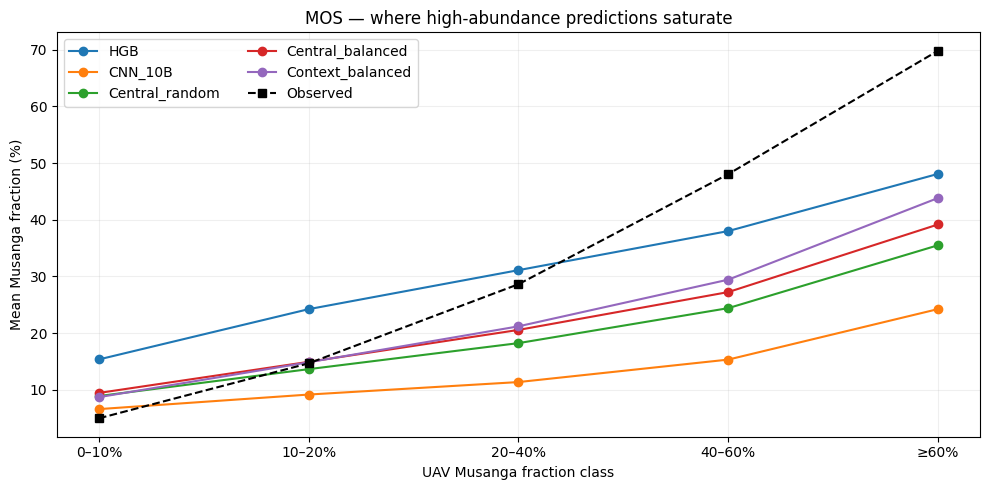

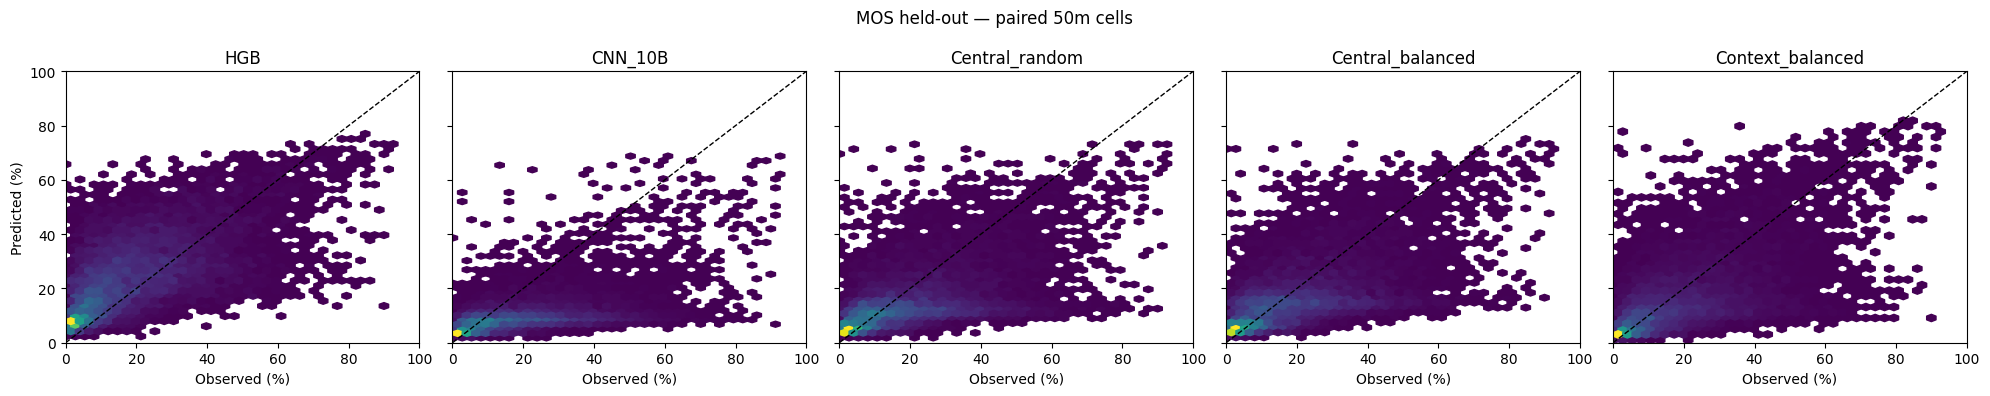

10C COMPLETE — all predictions, metrics, checkpoints and figures in /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/10C_CNN_diagnostics


In [3]:
# 10C — Diagnose native-spatial CNN transfer (NO new raster reads/EE).
# Prerequisites: run updated 10A (variables only); 10B must have FINISHED once.
import os,time,json,hashlib
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader,Dataset
from IPython.display import display
assert 'd10' in globals() and 'root10' in globals() and 'forests10' in globals(), 'Run 10A once; do NOT rerun 10B.'
assert torch.cuda.is_available(), '10C trains 12 small models: choose a GPU runtime in Colab.'
torch.set_num_threads(2)
sites10c=list(forests10); d10c=d10.reset_index(drop=True)
y10c=d10c.target_fraction.to_numpy(dtype=np.float32)
forest10c=d10c.site.to_numpy()
N10c=len(d10c); seed10c=20261026; CAP10c=1500
assert N10c==14454 and len(sites10c)==4 and np.isfinite(y10c).all()
pfile10c=out10/'10B_true_10m_patches_15x15.npy'
marker10c=out10/'10B_native_patches_complete.marker'
assert pfile10c.exists() and marker10c.exists(), 'Run 10B extraction first: patch cache incomplete.'
patch10c=np.load(pfile10c,mmap_mode='r')
assert patch10c.shape==(N10c,79,15,15),patch10c.shape
out10c=root10/'10C_CNN_diagnostics';out10c.mkdir(exist_ok=True,parents=True)
baseline10c=pd.read_parquet(root10/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet')
keys10c=['site','mosaic','row','col']
assert len(baseline10c)==N10c and all(baseline10c[k].equals(d10c[k]) for k in keys10c), 'Frozen cell ordering mismatch'
def load_saved_10b():
    pred=np.full(N10c,np.nan,dtype=np.float32)
    for site in sites10c:
        path=out10/f'10B_LOFO_{site}_seed0.npz'
        assert path.exists(),f'Missing completed 10B {site}: {path}'
        with np.load(path) as z:
            indices=np.flatnonzero(forest10c==site)
            assert np.array_equal(indices,z['test'])
            pred[indices]=z['prediction']
    assert np.isfinite(pred).all()
    return pred
oldpred10c=load_saved_10b()
assert np.isfinite(baseline10c.pred_baseline.to_numpy()).all()
def choose10c(train,kind):
    rng=np.random.default_rng(seed10c)
    if kind=='random':
        # Mirrors 10B's forest-uniform draw, without test-label inspection.
        return np.concatenate([rng.choice(k,min(CAP10c,len(k)),replace=False)
            for s in sites10c if len(k:=train[forest10c[train]==s])]).astype(int)
    # Exact Block 09 baseline draw: 10/20/40% strata; 25% high-cover minimum when available.
    selected=[]
    for site in sites10c:
        ix=train[forest10c[train]==site]
        if not len(ix):continue
        cap=min(CAP10c,len(ix))
        if len(ix)<=cap:
            selected.extend(ix.tolist());continue
        labels=np.digitize(y10c[ix],[.10,.20,.40])
        bins={b:ix[labels==b] for b in range(4)}
        amount=min(len(bins[3]),int(np.ceil(cap*.25)))
        pick=rng.choice(bins[3],amount,replace=False).tolist() if amount else []
        bins[3]=np.setdiff1d(bins[3],pick)
        while len(pick)<cap:
            active=[b for b in bins if len(bins[b])]
            assert active
            for b in active:
                amount=min(len(bins[b]),max(1,(cap-len(pick))//len(active)),cap-len(pick))
                if amount:
                    chosen=rng.choice(bins[b],amount,replace=False)
                    pick.extend(chosen.tolist())
                    bins[b]=np.setdiff1d(bins[b],chosen)
                if len(pick)==cap:break
        selected.extend(pick)
    return np.array(sorted(selected),dtype=int)
class Native10C(nn.Module):
    def __init__(self,context=False):
        super().__init__()
        self.context=context
        self.stem=nn.Sequential(nn.Conv2d(79,48,3,padding=1),nn.GroupNorm(8,48),nn.ReLU())
        self.res=nn.Sequential(nn.Conv2d(48,48,3,padding=1),nn.ReLU(),nn.Conv2d(48,48,3,padding=1))
        # same 48-channel encoder; context model concatenates local + broad summaries
        self.head=nn.Sequential(nn.Linear(96 if context else 48,1),nn.Sigmoid())
    def forward(self,x):
        z=self.stem(x);z=torch.relu(z+self.res(z))
        # Central 5x5 region corresponds to the 50m target footprint.
        if self.context:
            loc=z[:,:,5:10,5:10].mean((2,3))
            broad=z.mean((2,3))
            feat=torch.cat([loc,broad],1)
        else:
            feat=z.mean((2,3))  # x is 5x5 for central-only
        return self.head(feat).squeeze(1)
device10c=torch.device('cuda')
variants10c=['Central_random','Central_balanced','Context_balanced']
results10c={}
source_fingerprint10c=hashlib.sha256(pd.util.hash_pandas_object(
    d10c[keys10c+['target_fraction']],index=False).values.tobytes()).hexdigest()
manifest10c=dict(version='10C_v1',seed=seed10c,cap=CAP10c,
    variants=variants10c,epochs=20,batch=96,lr=0.0007,sha256=source_fingerprint10c,
    n=N10c,patch_shape=list(patch10c.shape),model='Native10C_48_residual')
manifest_path10c=out10c/'manifest.json'
if manifest_path10c.exists():
    assert json.loads(manifest_path10c.read_text())==manifest10c,'10C configuration changed: use another output directory'
else:
    manifest_path10c.write_text(json.dumps(manifest10c,indent=2))
class Patch10C(Dataset):
    def __init__(self,ids,mu,sd,context,with_y):
        self.ids=ids;self.mu=mu;self.sd=sd;self.context=context;self.with_y=with_y
    def __len__(self):return len(self.ids)
    def __getitem__(self,k):
        i=int(self.ids[k])
        arr=np.asarray(patch10c[i],dtype=np.float32)
        if not self.context:arr=arr[:,5:10,5:10]
        arr=np.clip((arr-self.mu[:,None,None])/self.sd[:,None,None],-6,6)
        x=torch.from_numpy(np.ascontiguousarray(arr))
        return (x,torch.tensor(y10c[i])) if self.with_y else (x,)
print(f'10C START: {N10c:,} cached cells; GPU={torch.cuda.get_device_name(0)}; 12 fits maximum.',flush=True)
for held10c in sites10c:
    test10c=np.flatnonzero(forest10c==held10c)
    train10c=np.flatnonzero(forest10c!=held10c)
    selections10c={kind:choose10c(train10c,kind) for kind in ('random','balanced')}
    assert not np.intersect1d(test10c,selections10c['balanced']).size
    print(f'\n10C HOLDOUT {held10c}: test={len(test10c):,} train_draw_random={len(selections10c["random"]):,} balanced={len(selections10c["balanced"]):,}',flush=True)
    for variant10c in variants10c:
        dest10c=out10c/f'{held10c}_{variant10c}.npz'
        context10c=(variant10c=='Context_balanced')
        selected10c=selections10c['random' if variant10c=='Central_random' else 'balanced']
        select_sha10c=hashlib.sha256(selected10c.astype(np.int64).tobytes()).hexdigest()
        if dest10c.exists():
            with np.load(dest10c) as z:
                assert np.array_equal(z['test'],test10c) and str(z['selection_sha'])==select_sha10c
                results10c[(held10c,variant10c)]=z['prediction'].copy()
            print('10C REUSE:',held10c,variant10c,flush=True)
            continue
        tic10c=time.monotonic()
        # Training-forest-only per-band normalization, appropriate to input support.
        seldata10c=np.asarray(patch10c[selected10c],dtype=np.float32)
        if not context10c:seldata10c=seldata10c[:,:,5:10,5:10]
        mu10c=seldata10c.mean(axis=(0,2,3))
        sd10c=np.maximum(seldata10c.std(axis=(0,2,3)),1e-3)
        del seldata10c
        assert np.isfinite(mu10c).all() and np.isfinite(sd10c).all()
        torch.manual_seed(seed10c)
        net10c=Native10C(context10c).to(device10c)
        opt10c=torch.optim.AdamW(net10c.parameters(),lr=.0007)
        trainloader10c=DataLoader(Patch10C(selected10c,mu10c,sd10c,context10c,True),batch_size=96,shuffle=True,num_workers=0)
        for epoch10c in range(20):
            net10c.train()
            total10c=0.;cnt10c=0
            for xb10c,yb10c in trainloader10c:
                xb10c=xb10c.to(device10c);yb10c=yb10c.to(device10c)
                opt10c.zero_grad(set_to_none=True)
                loss10c=((net10c(xb10c)-yb10c)**2).mean()
                loss10c.backward();opt10c.step()
                total10c+=float(loss10c.detach().cpu())*len(xb10c)
                cnt10c+=len(xb10c)
            if epoch10c==0 or (epoch10c+1)%5==0:
                print(f'10C {held10c} {variant10c} epoch {epoch10c+1}/20: train_MSE={total10c/cnt10c:.5f}',flush=True)
        net10c.eval();pieces10c=[]
        with torch.no_grad():
            for (xb10c,) in DataLoader(Patch10C(test10c,mu10c,sd10c,context10c,False),batch_size=128,num_workers=0):
                pieces10c.append(net10c(xb10c.to(device10c)).cpu().numpy())
        pred10c=np.concatenate(pieces10c).clip(0,1)
        assert len(pred10c)==len(test10c) and np.isfinite(pred10c).all()
        tmp10c=dest10c.with_suffix('.partial')
        with tmp10c.open('wb') as fh10c:
            np.savez_compressed(fh10c,test=test10c,prediction=pred10c,
              selection_sha=np.array(select_sha10c),mu=mu10c,sd=sd10c)
        os.replace(tmp10c,dest10c)
        results10c[(held10c,variant10c)]=pred10c
        # Store fitted parameters for reproducibility and possible later inference.
        checkpoint10c=out10c/f'{held10c}_{variant10c}_weights.pt'
        torch.save({'model_state':net10c.state_dict(),'context':context10c,
            'mu':mu10c,'sd':sd10c,'selection_sha':select_sha10c,
            'manifest':manifest10c},checkpoint10c)
        print(f'10C SAVED {held10c} {variant10c}, {time.monotonic()-tic10c:.0f}s',flush=True)
allpred10c={'HGB':baseline10c.pred_baseline.to_numpy(np.float32),'CNN_10B':oldpred10c}
for variant10c in variants10c:
    vec10c=np.full(N10c,np.nan,dtype=np.float32)
    for site10c in sites10c:
        vec10c[forest10c==site10c]=results10c[(site10c,variant10c)]
    assert np.isfinite(vec10c).all()
    allpred10c[variant10c]=vec10c
# Exact UAV abundance bins (left-closed, right-open except final bin).
bins10c=np.array([0.,.10,.20,.40,.60,1.00001])
labels10c=['0–10%','10–20%','20–40%','40–60%','≥60%']
scored10c=[]; binsummary10c=[]
for model10c,v10c in allpred10c.items():
    for site10c in sites10c:
        k10c=forest10c==site10c
        err10c=v10c[k10c]-y10c[k10c]
        for threshold10c in (.4,.6):
            high10c=y10c[k10c]>=threshold10c
            scored10c.append(dict(model=model10c,site=site10c,threshold=threshold10c,
                n=int(k10c.sum()),MAE_pp=float(np.abs(err10c).mean()*100),
                MSE=float((err10c**2).mean()),bias_pp=float(err10c.mean()*100),
                high_n=int(high10c.sum()),
                high_bias_pp=float(err10c[high10c].mean()*100) if high10c.any() else np.nan,
                high_recall=float((v10c[k10c][high10c]>=threshold10c).mean()) if high10c.any() else np.nan))
        for b10c in range(5):
            ix10c=k10c & (y10c>=bins10c[b10c]) & (y10c<bins10c[b10c+1])
            if not ix10c.any():continue
            ee10c=v10c[ix10c]-y10c[ix10c]
            binsummary10c.append(dict(model=model10c,site=site10c,abundance_bin=labels10c[b10c],
                n=int(ix10c.sum()),mean_observed=float(y10c[ix10c].mean()),
                mean_predicted=float(v10c[ix10c].mean()),
                MAE_pp=float(np.abs(ee10c).mean()*100),bias_pp=float(ee10c.mean()*100)))
site_metrics10c=pd.DataFrame(scored10c)
bin_metrics10c=pd.DataFrame(binsummary10c)
global10c=[]
for model10c in allpred10c:
    g10c=site_metrics10c[(site_metrics10c.model==model10c)&(site_metrics10c.threshold==.4)]
    m10c=np.mean([y10c[forest10c==s].mean() for s in sites10c])
    var10c=np.mean([y10c[forest10c==s].var()+(y10c[forest10c==s].mean()-m10c)**2 for s in sites10c])
    mos10c=g10c[g10c.site=='MOS'].iloc[0]
    global10c.append(dict(model=model10c,equal_forest_R2=1-g10c.MSE.mean()/var10c,
        equal_forest_MAE_pp=g10c.MAE_pp.mean(),
        MOS_high40_bias_pp=mos10c.high_bias_pp,
        MOS_high40_recall=mos10c.high_recall))
global10c=pd.DataFrame(global10c)
print('\n10C GLOBAL — independent forest holdouts, no evaluation reweighting',flush=True)
display(global10c.round(3))
print('\n10C MOS ABUNDANCE BIN REPORT',flush=True)
display(bin_metrics10c[bin_metrics10c.site=='MOS'].round(3))
for tag10c,data10c in [('global',global10c),('per_forest',site_metrics10c),
                       ('abundance_bins',bin_metrics10c)]:
    data10c.to_csv(out10c/f'10C_{tag10c}.csv',index=False)
predframe10c=d10c[keys10c+['target_fraction']].copy()
for name10c,v10c in allpred10c.items():
    predframe10c['pred_'+name10c]=v10c
predframe10c.to_parquet(out10c/'10C_paired_predictions.parquet',index=False)
# Figure 1: MOS observed/predicted distributions by abundance bin.
fig10c,ax10c=plt.subplots(figsize=(10,5))
mosbin10c=bin_metrics10c[bin_metrics10c.site=='MOS']
for model10c in allpred10c:
    zz10c=mosbin10c[mosbin10c.model==model10c].set_index('abundance_bin').reindex(labels10c)
    ax10c.plot(labels10c,100*zz10c.mean_predicted,marker='o',label=model10c)
truth10c=mosbin10c[mosbin10c.model=='HGB'].set_index('abundance_bin').reindex(labels10c)
ax10c.plot(labels10c,100*truth10c.mean_observed,color='black',ls='--',marker='s',label='Observed')
ax10c.set(xlabel='UAV Musanga fraction class',ylabel='Mean Musanga fraction (%)',
    title='MOS — where high-abundance predictions saturate')
ax10c.legend(ncol=2);ax10c.grid(alpha=.2);fig10c.tight_layout()
fig10c.savefig(out10c/'10C_MOS_abundance_saturation.png',dpi=180)
plt.show()
# Figure 2: 1-to-1 hex density for MOS; identical cells for all methods.
fig10c,axes10c=plt.subplots(1,len(allpred10c),figsize=(4*len(allpred10c),4),sharex=True,sharey=True)
mos10c=forest10c=='MOS'
for ax10c,(name10c,v10c) in zip(axes10c,allpred10c.items()):
    ax10c.hexbin(y10c[mos10c]*100,v10c[mos10c]*100,gridsize=35,mincnt=1,cmap='viridis')
    ax10c.plot([0,100],[0,100],ls='--',color='black',lw=1)
    ax10c.set_title(name10c);ax10c.set_xlim(0,100);ax10c.set_ylim(0,100)
    ax10c.set_xlabel('Observed (%)')
axes10c[0].set_ylabel('Predicted (%)')
fig10c.suptitle('MOS held-out — paired 50m cells')
fig10c.tight_layout();fig10c.savefig(out10c/'10C_MOS_heldout_hexbin.png',dpi=160)
plt.show()
print('10C COMPLETE — all predictions, metrics, checkpoints and figures in',out10c,flush=True)


## 11A — Lang-inspired dense UAV supervision: native 10 m target preparation and validation

**Purpose:** build dense *UAV-model-derived* Musanga abundance targets on the existing native 10 m Sentinel-2 lattice, before any fully convolutional training. This is **not** Block 11B training and does not replace independent annotation validation.

**Inputs:** frozen NB03 full-mosaic warm-start epoch-02 prediction GeoTIFFs (`uint16`, scale 10,000, nodata 65,535), canonical annual 10 m Sentinel-2 grid for each of the four forests, and the frozen 14,454-cell 50 m table from 10A. MOS uses both MOS1–2 and MOS5–6; overlap is averaged and separately audited, rather than choosing an arbitrary file.

**Products:** four tiled, native-grid GeoTIFFs: `{site}_Musanga_UAVteacher_mean_10m.tif` (float32, nodata -9999), and `{site}_UAVteacher_contributors_10m.tif` (uint8, 0–2), plus per-mosaic and forest QA tables. A contributor is a full-resolution UAV map contributing a valid *warped average* to a 10 m cell; contributor count is **not** subpixel valid-area fraction. Native UAV pixel coverage within a partly valid 10 m cell is *not yet established* and must be verified before dense training. Every output is restartable at the **whole-site** level using a file+configuration signature; incomplete `.partial.tif` files are never treated as complete.

**Reference audit:** reaggregate native 10 m results for the **same frozen 50 m cell centers** using a central 5×5 window, with explicit valid 10 m coverage and mosaic-support checks. A successful grid audit alone does not establish equality with the original 50 m target (the earlier NB04 aggregation may use a different fractional support/ROI mask). Large discrepancies must block 11B until investigated. Prints site-conditional agreement and images; does **not** label UAV-model predictions as ground truth.

**Execution:** run Block 10A once (to initialize paths, datasets and raster metadata), then 11A directly; no 10B or 10C rerun and no GPU required. Dense export may be disk-I/O intensive; prints site and tile progress. No original images, cache or model checkpoints are modified.


11A Baego: grid=721x491, 6 tiles, sources=1
11A Baego: 3/6 tiles; valid pixels 9,624
11A Baego: 6/6 tiles; valid pixels 16,422
11A COMPLETE Baego: valid 10m=16,422, multiple-contributor 10m=0, elapsed 47s
11A MOS: grid=784x913, 16 tiles, sources=2
11A MOS: 4/16 tiles; valid pixels 195,920
11A MOS: 16/16 tiles; valid pixels 388,108
11A COMPLETE MOS: valid 10m=388,108, multiple-contributor 10m=0, elapsed 69s
11A Yangambi: grid=509x187, 2 tiles, sources=1
11A Yangambi: 2/2 tiles; valid pixels 41,199
11A COMPLETE Yangambi: valid 10m=41,199, multiple-contributor 10m=0, elapsed 49s
11A Yoko: grid=320x166, 2 tiles, sources=1
11A Yoko: 2/2 tiles; valid pixels 32,257
11A COMPLETE Yoko: valid 10m=32,257, multiple-contributor 10m=0, elapsed 18s
11A 50m audit complete Baego cells 480
11A 50m audit complete MOS cells 11494
11A 50m audit complete Yangambi cells 1383
11A 50m audit complete Yoko cells 1097

11A — FROZEN 50m TARGET vs native UAV-teacher 10m reaggregation (diagnostic; NOT an independent

,site,n_total,n_90pct_valid,pct_90pct_valid,bias_pp,MAE_pp,RMSE_pp,corr,pct_large10pp,n_overlap_cells,median_grid_phase_x,median_grid_phase_y
0,Baego,480,480,100.0,0.0,0.001,0.001,1.0,0.0,0,0.5,0.5
1,MOS,11494,11494,100.0,-0.0,0.001,0.021,1.0,0.0,0,0.5,0.5
2,Yangambi,1383,1383,100.0,0.0,0.001,0.007,1.0,0.0,0,0.5,0.5
3,Yoko,1097,1097,100.0,0.0,0.001,0.004,1.0,0.0,0,0.5,0.5


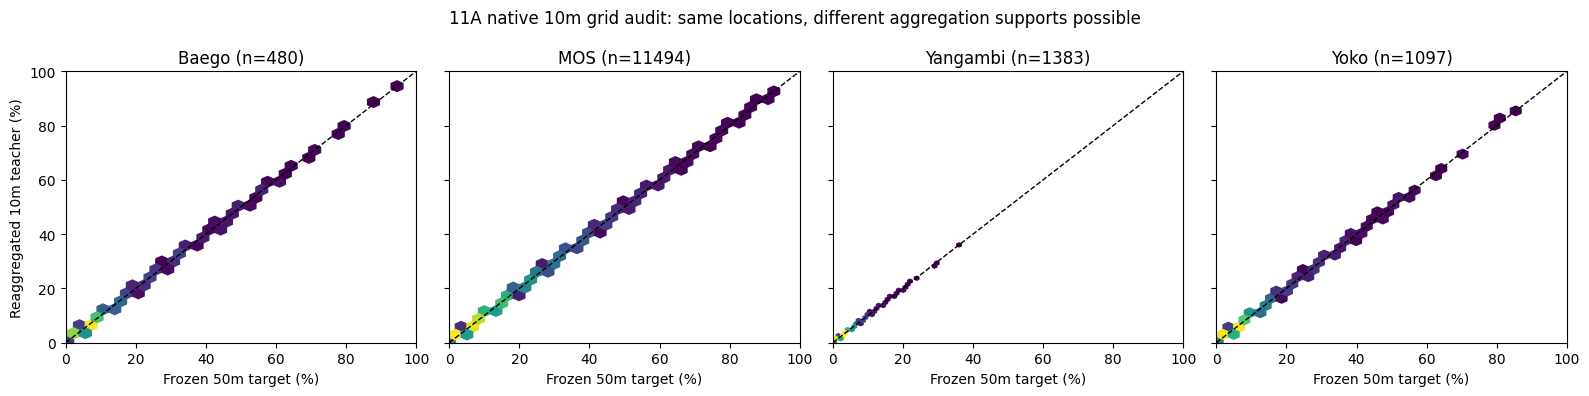

11A TARGET CONSISTENCY GATE: True
Agreement check passed; remaining requirement: quantify native within-10m UAV coverage and independent annotation agreement before 11B.
11A outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/11A_dense_UAV_teacher_10m


In [4]:
# 11A — Frozen UAV-M2 probability maps -> genuine native-S2 10m grid.
# No CNN fit; no new EE calls; no new UAV inference.
from pathlib import Path
import os,json,time,hashlib
import numpy as np,pandas as pd,rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.windows import Window
import matplotlib.pyplot as plt
from IPython.display import display
assert 'root10' in globals() and 's2resolved10' in globals() and 'd10' in globals(), 'Run Block 10A once first.'
sites11=list(forests10)
assert sites11==['Baego','MOS','Yangambi','Yoko']
scale11=10000.; nodata11=65535; output_nodata11=-9999.
tile11=256
base11=root10.parent.parent
mapdir11=base11/'03_M2_warmstart_c6a33504c37efb2ebb84_full_mosaic/probability_maps'
assert mapdir11.is_dir(),('Frozen NB03 probability maps missing',mapdir11)
mosaics11={'Baego':['Baego.tif'],
    'MOS':['Mos_1_2_transparent_mosaic_group1_georef.tif','Mos_5_6_transparent_mosaic_group1_georef.tif'],
    'Yangambi':['Yangambi_georef.tif'],
    'Yoko':['Yoko_kvo_georef.tif']}
paths11={s:[mapdir11/(Path(m).stem+'_M2_warmstart_epoch02_probability_u16_FULL.tif') for m in ms]
         for s,ms in mosaics11.items()}
for site11,paths in paths11.items():
    for path11 in paths:
        assert path11.is_file(),('Missing frozen probability map',site11,path11)
        with rasterio.open(path11) as src11:
            assert src11.count==1 and src11.dtypes[0]=='uint16' and src11.nodata==nodata11,(site11,path11,src11.dtypes,src11.nodata)
assert all(s2resolved10[s].is_file() for s in sites11)
out11=root10/'11A_dense_UAV_teacher_10m'
out11.mkdir(parents=True,exist_ok=True)
cfg11=dict(version='11A_dense_UAV_teacher_native_grid_v1',
    source_scale=scale11,source_nodata=nodata11,
    source_map_dir=str(mapdir11),mosaics=mosaics11,
    tile=tile11,warp_resampling='average',forest_order=sites11,
    output_nodata=output_nodata11)
manifest11=out11/'11A_manifest.json'
if manifest11.exists():assert json.loads(manifest11.read_text())==cfg11,'11A configuration differs; do not reuse old output'
else:manifest11.write_text(json.dumps(cfg11,indent=2))
# Full-resolution UAV data are never loaded as arrays. WarpedVRT uses GDAL tiled on-demand reads.
def signature11(path):
    st=path.stat()
    with rasterio.open(path) as src:
        return dict(path=str(path),bytes=st.st_size,mtime_ns=st.st_mtime_ns,
                    crs=str(src.crs),width=src.width,height=src.height,
                    transform=list(src.transform)[:6],dtype=src.dtypes[0],nodata=src.nodata)
def targets11(site):
    return (out11/f'{site}_Musanga_UAVteacher_mean_10m.tif',
            out11/f'{site}_UAVteacher_contributors_10m.tif',
            out11/f'{site}_complete.json')
def site_signature11(site):
    return dict(config=cfg11,s2=signature11(s2resolved10[site]),
                sources=[signature11(x) for x in paths11[site]])
# Predicted values were saved on a 0..10000 integer scale; WarpedVRT excludes nodata when averaging.
# IMPORTANT: a valid warped average does NOT guarantee 100% valid native UAV coverage.
audit11=[]
for site11 in sites11:
    dest11,contrib11,marker11=targets11(site11)
    sig11=site_signature11(site11)
    if marker11.exists() and dest11.exists() and contrib11.exists():
        assert json.loads(marker11.read_text())==sig11,('Completed 11A output stale or different source',site11)
        print('11A REUSE completed site:',site11,flush=True)
        continue
    marker11.unlink(missing_ok=True)
    for path11 in (dest11,contrib11):
        if path11.exists():
            raise RuntimeError(f'Unmarked existing 11A output: {path11}; inspect before replacing')
    tmpmean11=dest11.with_name(dest11.stem+'.partial.tif')
    tmpcnt11=contrib11.with_name(contrib11.stem+'.partial.tif')
    # Stale partials are explicitly reset. Completed files are never overwritten.
    tmpmean11.unlink(missing_ok=True);tmpcnt11.unlink(missing_ok=True)
    t0=time.monotonic()
    with rasterio.open(s2resolved10[site11]) as grid11:
        profile11=dict(driver='GTiff',width=grid11.width,height=grid11.height,
             count=1,crs=grid11.crs,transform=grid11.transform,
             tiled=True,blockxsize=256,blockysize=256,
             compress='deflate',bigtiff='IF_SAFER')
        srcs11=[rasterio.open(q) for q in paths11[site11]]
        vrts11=[]
        try:
            for src11 in srcs11:
                vrts11.append(WarpedVRT(src11,crs=grid11.crs,transform=grid11.transform,
                    width=grid11.width,height=grid11.height,
                    src_nodata=nodata11,nodata=nodata11,
                    resampling=Resampling.average))
            nrows11=(grid11.height+tile11-1)//tile11
            ncols11=(grid11.width+tile11-1)//tile11
            print(f'11A {site11}: grid={grid11.width}x{grid11.height}, {nrows11*ncols11:,} tiles, sources={len(vrts11)}',flush=True)
            with rasterio.open(tmpmean11,'w',**dict(profile11,dtype='float32',nodata=output_nodata11,predictor=3)) as dst11, \
                 rasterio.open(tmpcnt11,'w',**dict(profile11,dtype='uint8',nodata=0)) as countdst11:
                tiles11=0;valid_total11=0;overlap11=0
                for rr11 in range(0,grid11.height,tile11):
                    hh11=min(tile11,grid11.height-rr11)
                    for cc11 in range(0,grid11.width,tile11):
                        ww11=min(tile11,grid11.width-cc11)
                        win11=Window(cc11,rr11,ww11,hh11)
                        total11=np.zeros((hh11,ww11),dtype=np.float32)
                        count11=np.zeros((hh11,ww11),dtype=np.uint8)
                        for vrt11 in vrts11:
                            raw11=vrt11.read(1,window=win11,masked=True,out_dtype='float32')
                            values11=np.asarray(np.ma.getdata(raw11),dtype=np.float32)
                            ok11=(~np.ma.getmaskarray(raw11)) & np.isfinite(values11) & (values11>=0)&(values11<=scale11)
                            total11+=np.where(ok11,values11,0)
                            count11+=ok11.astype(np.uint8)
                        av11=np.full((hh11,ww11),output_nodata11,dtype=np.float32)
                        np.divide(total11,scale11*np.maximum(count11,1),out=av11,where=count11>0)
                        dst11.write(av11,1,window=win11)
                        countdst11.write(count11,1,window=win11)
                        valid_total11+=int((count11>0).sum())
                        overlap11+=int((count11>1).sum())
                        tiles11+=1
                    if rr11==0 or (rr11//tile11+1)%8==0 or rr11+hh11>=grid11.height:
                        print(f'11A {site11}: {tiles11:,}/{nrows11*ncols11:,} tiles; valid pixels {valid_total11:,}',flush=True)
            os.replace(tmpmean11,dest11);os.replace(tmpcnt11,contrib11)
            marker11.write_text(json.dumps(sig11,indent=2))
            print(f'11A COMPLETE {site11}: valid 10m={valid_total11:,}, multiple-contributor 10m={overlap11:,}, elapsed {time.monotonic()-t0:.0f}s',flush=True)
        finally:
            for vrt11 in vrts11:vrt11.close()
            for src11 in srcs11:src11.close()
# 50m target consistency check: 5x5 native 10m pixels centered on the stored 50m cell center.
# This checks agreement but is not assumed identical to legacy NB04 fractional ROI/valid masks.
rows11=[]
d11=d10.reset_index(drop=True)
for site11 in sites11:
    ids11=np.flatnonzero(d11.site.to_numpy()==site11)
    meanfile11,countfile11,_=targets11(site11)
    with rasterio.open(meanfile11) as teacher11,rasterio.open(countfile11) as cnt11:
        assert teacher11.crs==cnt11.crs and teacher11.transform==cnt11.transform
        with rasterio.open(s2resolved10[site11]) as s2grid11:
            assert teacher11.transform==s2grid11.transform and teacher11.shape==s2grid11.shape,site11
        from rasterio.warp import transform as xytransform11
        source_crs11=str(d11.crs.iloc[ids11[0]]) if 'crs' in d11 else 'EPSG:32635'
        xx11=d11.x.iloc[ids11].to_numpy(float);yy11=d11.y.iloc[ids11].to_numpy(float)
        if source_crs11!=str(teacher11.crs):
            xx11,yy11=xytransform11(source_crs11,teacher11.crs,xx11.tolist(),yy11.tolist())
        for j11,i11 in enumerate(ids11):
            colf11,rowf11=(~teacher11.transform)*(xx11[j11],yy11[j11])
            # NB06 uses cell centers; check support phase explicitly rather than assume exact 50m snap.
            col11=int(np.floor(colf11));row11=int(np.floor(rowf11))
            win11=Window(col11-2,row11-2,5,5)
            data11=teacher11.read(1,window=win11,boundless=True,fill_value=output_nodata11)
            cont11=cnt11.read(1,window=win11,boundless=True,fill_value=0)
            good11=(data11>=0)&(data11<=1)&(cont11>0)
            cov11=float(good11.mean())
            computed11=float(data11[good11].mean()) if good11.any() else np.nan
            rows11.append(dict(index=int(i11),site=site11,mosaic=d11.mosaic.iloc[i11],
                row=d11.row.iloc[i11],col=d11.col.iloc[i11],
                observed50=float(d11.target_fraction.iloc[i11]),teacher10to50=computed11,
                coverage10=cov11,n10=int(good11.sum()),
                offset_x_pixels=float(colf11-np.floor(colf11)),
                offset_y_pixels=float(rowf11-np.floor(rowf11)),
                multi_source_pixels=int((cont11>1).sum())))
        print('11A 50m audit complete',site11,'cells',len(ids11),flush=True)
check11=pd.DataFrame(rows11).sort_values('index')
assert len(check11)==len(d11) and np.array_equal(check11['index'].to_numpy(),np.arange(len(d11)))
check11['delta_pp']=100*(check11.teacher10to50-check11.observed50)
check11.to_parquet(out11/'11A_50m_consistency_all_cells.parquet',index=False)
stats11=[]
for site11,g11 in check11.groupby('site',sort=False):
    valid11=g11[g11.coverage10>=.90].dropna(subset=['teacher10to50'])
    stats11.append(dict(site=site11,n_total=len(g11),n_90pct_valid=len(valid11),
        pct_90pct_valid=100*len(valid11)/len(g11),
        bias_pp=float(valid11.delta_pp.mean()) if len(valid11) else np.nan,
        MAE_pp=float(valid11.delta_pp.abs().mean()) if len(valid11) else np.nan,
        RMSE_pp=float(np.sqrt(np.mean(valid11.delta_pp**2))) if len(valid11) else np.nan,
        corr=float(valid11[['observed50','teacher10to50']].corr().iloc[0,1]) if len(valid11)>2 else np.nan,
        pct_large10pp=float(100*(valid11.delta_pp.abs()>10).mean()) if len(valid11) else np.nan,
        n_overlap_cells=int((valid11.multi_source_pixels>0).sum()),
        median_grid_phase_x=float(g11.offset_x_pixels.median()),
        median_grid_phase_y=float(g11.offset_y_pixels.median())))
summary11=pd.DataFrame(stats11)
summary11.to_csv(out11/'11A_50m_site_summary.csv',index=False)
print('\n11A — FROZEN 50m TARGET vs native UAV-teacher 10m reaggregation (diagnostic; NOT an independent validation)')
display(summary11.round(3))
fig11,axs11=plt.subplots(1,4,figsize=(16,4),sharex=True,sharey=True)
for ax11,site11 in zip(axs11,sites11):
    v11=check11[(check11.site==site11)&(check11.coverage10>=.90)].dropna(subset=['teacher10to50'])
    ax11.hexbin(100*v11.observed50,100*v11.teacher10to50,gridsize=28,mincnt=1,cmap='viridis')
    ax11.plot([0,100],[0,100],ls='--',color='black',lw=1)
    ax11.set(title=f'{site11} (n={len(v11)})',xlim=(0,100),ylim=(0,100),xlabel='Frozen 50m target (%)')
axs11[0].set_ylabel('Reaggregated 10m teacher (%)')
fig11.suptitle('11A native 10m grid audit: same locations, different aggregation supports possible')
fig11.tight_layout()
fig11.savefig(out11/'11A_teacher50_comparison.png',dpi=170)
plt.show()
# Explicit decision gating: conservation of numeric range, >=90% coverage and target consistency.
# This is deliberately stringent; review source alignment / ROI masks before enabling dense labels.
ready11=bool((summary11.pct_90pct_valid>=95).all() and
             (summary11.MAE_pp<=5).all() and (summary11.pct_large10pp<=10).all())
print('11A TARGET CONSISTENCY GATE:',ready11,flush=True)
if not ready11:
    print('DO NOT TRAIN 11B YET. Inspect mosaic/grid phase, ROI/valid-pixel support, and high-difference cases.',flush=True)
else:
    print('Agreement check passed; remaining requirement: quantify native within-10m UAV coverage and independent annotation agreement before 11B.',flush=True)
print('11A outputs:',out11,flush=True)


In [5]:
# 11A2 — Native UAV valid-area fraction + reference polygon agreement.
# 11A must already be completed; run 10A in a fresh runtime to restore paths.
import os,json,math,time
import numpy as np,pandas as pd,rasterio,geopandas as gpd
from rasterio.windows import Window,from_bounds
from rasterio.features import rasterize
from rasterio.transform import Affine
from rasterio.warp import transform_bounds
from shapely.geometry import box
import matplotlib.pyplot as plt
from IPython.display import display
assert 'root10' in globals() and 's2resolved10' in globals() and 'forests10' in globals(),'Run 10A once.'
sites112=list(forests10);folder112=root10/'11A_dense_UAV_teacher_10m'
assert (folder112/'11A_50m_site_summary.csv').exists(),'Run 11A first.'
folder1122=root10/'11A2_native_coverage_annotations';folder1122.mkdir(parents=True,exist_ok=True)
mapdir112=root10.parent.parent/'03_M2_warmstart_c6a33504c37efb2ebb84_full_mosaic/probability_maps'
names112={'Baego':['Baego.tif'],
 'MOS':['Mos_1_2_transparent_mosaic_group1_georef.tif','Mos_5_6_transparent_mosaic_group1_georef.tif'],
 'Yangambi':['Yangambi_georef.tif'],'Yoko':['Yoko_kvo_georef.tif']}
def prob_sources112(site):
 return [mapdir112/(Path(name).stem+'_M2_warmstart_epoch02_probability_u16_FULL.tif') for name in names112[site]]
manifest112=root10.parent.parent/'00_input_audit/00_input_manifest.json'
assert manifest112.is_file(),('Required frozen annotation manifest absent',manifest112)
A112=json.loads(manifest112.read_text())
assert A112.get('schema_version')=='v3_1_input_audit_kvo_final'
cirfile112=Path(A112['exhaustive_annotations']['complete_roi_boundaries'])
posfile112=Path(A112['exhaustive_annotations']['positive_polygons'])
assert cirfile112.is_file() and posfile112.is_file()
cir112=gpd.read_file(cirfile112)
pos112=gpd.read_file(posfile112)
assert cir112.crs is not None and pos112.crs is not None
print('11A2 annotations:',len(cir112),'circle geometries;',len(pos112),'positive crown polygons',flush=True)
# Sample 10m teacher cells in all forests: 200 interior + up to 200 near valid/missing edges,
# with all site observations held for support QA; not a declaration that all cells are valid.
rng112=np.random.default_rng(20261027)
covrows112=[]
for site112 in sites112:
 meanpath112=folder112/f'{site112}_Musanga_UAVteacher_mean_10m.tif'
 cntpath112=folder112/f'{site112}_UAVteacher_contributors_10m.tif'
 with rasterio.open(meanpath112) as teacher112,rasterio.open(cntpath112) as ncon112:
  count112=ncon112.read(1)
  usable112=count112>0
  assert np.array_equal(usable112,teacher112.read_masks(1)>0),('Teacher and contributor mask differ',site112)
  from scipy.ndimage import binary_erosion
  border112=usable112 & ~binary_erosion(usable112,iterations=2,border_value=0)
  interior112=usable112 & ~border112
  picks112=[]
  for typ112,region112 in [('interior',interior112),('edge',border112)]:
   indexes112=np.flatnonzero(region112.ravel())
   take112=rng112.choice(indexes112,min(200,len(indexes112)),replace=False)
   picks112.extend((typ112,int(i//teacher112.width),int(i%teacher112.width)) for i in take112)
  assert len(picks112)>=100,('Insufficient native coverage probes',site112)
  srcs112=[rasterio.open(x) for x in prob_sources112(site112)]
  try:
   for category112,row112,col112 in picks112:
    win112=Window(col112,row112,1,1)
    bounds112=rasterio.windows.bounds(win112,teacher112.transform)
    best112=0.;matched112=False
    for src112 in srcs112:
     bb112=bounds112 if src112.crs==teacher112.crs else transform_bounds(
        teacher112.crs,src112.crs,*bounds112,densify_pts=5)
     bbox112=box(*bb112)
     if not bbox112.intersects(box(*src112.bounds)):continue
     # Bounding native pixels, with no full mosaic load. Map fractional overlap to 10m cell.
     window112=from_bounds(*bb112,transform=src112.transform).round_offsets().round_lengths()
     window112=window112.intersection(Window(0,0,src112.width,src112.height))
     if window112.width<1 or window112.height<1:continue
     native112=src112.dataset_mask(window=window112)
     covered112=float((native112>0).mean())
     best112=max(best112,covered112);matched112=True
    covrows112.append(dict(site=site112,stratum=category112,row=row112,col=col112,
                          approximate_native_valid_fraction=best112,
                          native_source_intersects=matched112))
  finally:
   for source112 in srcs112:source112.close()
  print('11A2 native coverage sampled',site112,'n=',len(picks112),flush=True)
coverage112=pd.DataFrame(covrows112)
coverage112.to_csv(folder1122/'11A2_native_validity_samples.csv',index=False)
# Exhaustive-circle reference: supersample vector geometry by 4x on native 10m grid.
# Only within actual exhaustive-circle footprints are negative crown areas meaningful.
# The original UAV probability map was derived using related annotations; this is NOT independent holdout.
annrows112=[]
for site112 in sites112:
 meanpath112=folder112/f'{site112}_Musanga_UAVteacher_mean_10m.tif'
 with rasterio.open(meanpath112) as teacher112:
  b112=box(*teacher112.bounds)
  circles_site112=cir112.to_crs(teacher112.crs)
  positives_site112=pos112.to_crs(teacher112.crs)
  circles_site112=circles_site112[circles_site112.geometry.intersects(b112)]
  positives_site112=positives_site112[positives_site112.geometry.intersects(b112)]
  for index112,circle112 in circles_site112.geometry.items():
   if circle112 is None or circle112.is_empty:continue
   bb112=circle112.bounds
   win112=from_bounds(*bb112,transform=teacher112.transform).round_offsets().round_lengths()
   win112=win112.intersection(Window(0,0,teacher112.width,teacher112.height))
   win112=Window(int(win112.col_off),int(win112.row_off),int(win112.width),int(win112.height))
   if win112.width<1 or win112.height<1:continue
   hh112=int(win112.height);ww112=int(win112.width)
   if hh112*ww112>50000:
    print('11A2 skipped unexpectedly large circle; inspect',site112,index112,hh112,ww112,flush=True)
    continue
   t112=rasterio.windows.transform(win112,teacher112.transform)
   t4_112=t112*Affine.scale(.25,.25)
   shape112=(hh112*4,ww112*4)
   circlemask112=rasterize([(circle112,1)],out_shape=shape112,transform=t4_112,fill=0,dtype='uint8')
   selectedpos112=positives_site112[positives_site112.geometry.intersects(circle112)]
   crowns112=rasterize(((geom,1) for geom in selectedpos112.geometry if geom is not None and not geom.is_empty),
     out_shape=shape112,transform=t4_112,fill=0,dtype='uint8')
   cfrac112=circlemask112.reshape(hh112,4,ww112,4).mean((1,3))
   truefrac112=(circlemask112*crowns112).reshape(hh112,4,ww112,4).mean((1,3))
   tt112=teacher112.read(1,window=win112,masked=True)
   teacher_data112=np.asarray(tt112.filled(np.nan),dtype=np.float32)
   good112=(cfrac112>=.95)&np.isfinite(teacher_data112)&(teacher_data112>=0)&(teacher_data112<=1)
   if good112.sum()<3:continue
   obs112=truefrac112[good112]/np.maximum(cfrac112[good112],1e-6)
   pred112=teacher_data112[good112]
   annrows112.append(dict(site=site112,circle_index=int(index112),n_pixels=int(good112.sum()),
       reference_cover=float(np.mean(obs112)),teacher_cover=float(np.mean(pred112)),
       MAE_pp=float(100*np.mean(np.abs(pred112-obs112))),
       bias_pp=float(100*np.mean(pred112-obs112)),n_positive_crowns=len(selectedpos112)))
 print('11A2 annotation circle checks',site112,sum(z['site']==site112 for z in annrows112),flush=True)
ann112=pd.DataFrame(annrows112)
ann112.to_csv(folder1122/'11A2_exhaustive_circle_agreement.csv',index=False)
summaries112=[]
for site112 in sites112:
 cc112=coverage112[coverage112.site==site112]
 ee112=cc112[cc112.stratum=='edge']
 ii112=cc112[cc112.stratum=='interior']
 aa112=ann112[ann112.site==site112] if not ann112.empty else pd.DataFrame()
 summaries112.append(dict(site=site112,n_native_probe=len(cc112),
     interior_native_valid_mean=float(ii112.approximate_native_valid_fraction.mean()),
     edge_native_valid_mean=float(ee112.approximate_native_valid_fraction.mean()) if len(ee112) else np.nan,
     fraction_probes_ge95=float((cc112.approximate_native_valid_fraction>=.95).mean()),
     annotation_circles=int(len(aa112)),
     annotation_mean_abs_bias_pp=float(np.abs(aa112.bias_pp).mean()) if len(aa112) else np.nan,
     annotation_mean_MAE_pp=float(aa112.MAE_pp.mean()) if len(aa112) else np.nan))
summary112=pd.DataFrame(summaries112)
summary112.to_csv(folder1122/'11A2_summary.csv',index=False)
display(summary112.round(3))
# No automatic scientific accept/reject on magnitude of the UAV teacher's annotation errors;
# only existence and native coverage; report accuracy separately and inspect before publication.
gate112=bool((summary112.n_native_probe>=100).all() and
             (summary112.interior_native_valid_mean>=.95).all() and
             (summary112.annotation_circles>=1).all() and
             np.isfinite(summary112.annotation_mean_MAE_pp).all())
status112={'gate':gate112,'version':'11A2_v1',
 'site_counts':dict(zip(summary112.site,summary112.annotation_circles.astype(int))),
 'note':'Gate checks coverage and reference presence, not independent teacher accuracy. Review circle errors.'}
(folder1122/'11A2_gate.json').write_text(json.dumps(status112,indent=2))
print('11A2 PRETRAINING DATA-COVERAGE GATE:',gate112,flush=True)
print('CHECK annotation MAE and edge coverage before treating dense UAV pseudo-labels as reliable.',flush=True)
print('11A2 outputs:',folder1122,flush=True)


11A2 annotations: 34 circle geometries; 635 positive crown polygons
11A2 native coverage sampled Baego n= 400
11A2 native coverage sampled MOS n= 400
11A2 native coverage sampled Yangambi n= 400
11A2 native coverage sampled Yoko n= 400
11A2 annotation circle checks Baego 7
11A2 annotation circle checks MOS 11
11A2 annotation circle checks Yangambi 7
11A2 annotation circle checks Yoko 5


,site,n_native_probe,interior_native_valid_mean,edge_native_valid_mean,fraction_probes_ge95,annotation_circles,annotation_mean_abs_bias_pp,annotation_mean_MAE_pp
0,Baego,400,1.000,0.626,0.682,7,3.944,7.482
1,MOS,400,1.000,0.760,0.775,11,6.665,9.871
2,Yangambi,400,1.000,0.725,0.735,7,2.579,3.440
3,Yoko,400,0.999,0.602,0.672,5,2.335,6.001


11A2 PRETRAINING DATA-COVERAGE GATE: True
CHECK annotation MAE and edge coverage before treating dense UAV pseudo-labels as reliable.
11A2 outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/11A2_native_coverage_annotations


## 11B — Dense, full-resolution, fully convolutional Musanga regression

**Run only after 11A and 11A2.** Native 10 m Sentinel-2 (15 bands) + Earth embeddings (64 bands) are predictors. Native 10 m *UAV-teacher fractional cover* is the soft regression target, with invalid pixels masked. A compact residual FCN makes pixel-wise predictions without global pooling or spatial downsampling. Training uses 64×64 pixel patches sampled equally from each of the **three training forests**. Held-out-forest inference is tiled at 10 m, with a halo and whole-site reconstruction. **No reference cells from the held-out forest enter training or normalization.**

Native 10 m target maps are *pseudo-labels*, not independently observed species cover. 11B's scientific benchmark is frozen 50 m LOFO predictions on the *exact same 14,454 reference cells* (HGB from Block 09). A clean comparison does not prove independent 10 m accuracy. Independent exhaustive-circle tests remain necessary for publication.

**Outputs:** four 10 m held-out-forest prediction GeoTIFFs, four reproducible model checkpoints with train-only normalizers, per-site/global LOFO metrics, five cover-class diagnostics, 40% and 60% MOS recall/bias, paired 50 m prediction parquet, and figures. Reuses completed folds. Uses GPU. A completed 11A2 *coverage gate* is required; large annotation errors should be inspected separately before accepting pseudo-label accuracy.

**Interpretation:** primary comparison is between independent 50 m HGB and FCN predictions of a common UAV-teacher target. Prior results cannot establish benefits from spatial context without a no-context ablation; that experiment can follow if 11B is competitive.


11B input Baego (491, 721) valid label+predictor fraction 0.046
11B input MOS (913, 784) valid label+predictor fraction 0.542
11B input Yangambi (187, 509) valid label+predictor fraction 0.433
11B input Yoko (166, 320) valid label+predictor fraction 0.607

11B FIT Baego train sites ['MOS', 'Yangambi', 'Yoko']
11B Baego epoch 1/16: training MSE 0.04423; 1s
11B Baego epoch 2/16: training MSE 0.02906; 2s
11B Baego epoch 4/16: training MSE 0.02402; 4s
11B Baego epoch 6/16: training MSE 0.02513; 6s
11B Baego epoch 8/16: training MSE 0.02274; 8s
11B Baego epoch 10/16: training MSE 0.02259; 10s
11B Baego epoch 12/16: training MSE 0.02086; 12s
11B Baego epoch 14/16: training MSE 0.02143; 13s
11B Baego epoch 16/16: training MSE 0.02129; 15s
11B MODEL SAVED: Baego
11B INFER Baego: 7/35 dense tiles
11B INFER Baego: 28/35 dense tiles
11B INFER Baego: 35/35 dense tiles
11B HELD OUT FOREST DONE: Baego

11B FIT MOS train sites ['Baego', 'Yangambi', 'Yoko']
11B MOS epoch 1/16: training MSE 0.04181; 1s

,model,equal_forest_R2,equal_forest_MAE_pp,MOS_high40_bias_pp,MOS_high40_recall
0,HGB,0.545,6.853,-12.669,0.484
1,Dense_FCN,0.417,7.491,-31.083,0.119


,model,site,threshold,n,MSE,MAE_pp,bias_pp,high_n,high_bias_pp,high_recall
0,HGB,Baego,0.4,480,0.009,6.807,-1.194,57,-17.027,0.439
1,HGB,Baego,0.6,480,0.009,6.807,-1.194,12,-24.026,0.083
2,HGB,MOS,0.4,11494,0.021,11.010,5.071,1449,-12.669,0.484
3,HGB,MOS,0.6,11494,0.021,11.010,5.071,325,-21.735,0.314
4,HGB,Yangambi,0.4,1383,0.002,3.147,1.962,0,NaN,NaN
5,HGB,Yangambi,0.6,1383,0.002,3.147,1.962,0,NaN,NaN
6,HGB,Yoko,0.4,1097,0.009,6.450,1.632,62,-14.198,0.371
7,HGB,Yoko,0.6,1097,0.009,6.450,1.632,11,-23.967,0.182
8,Dense_FCN,Baego,0.4,480,0.014,8.615,1.091,57,-11.460,0.509
9,Dense_FCN,Baego,0.6,480,0.014,8.615,1.091,12,-18.673,0.417



MOS abundance class diagnostic


,model,site,bin,n,observed_pct,predicted_pct,bias_pp,MAE_pp
5,HGB,MOS,0–10%,4004,4.949,15.344,10.394,10.517
6,HGB,MOS,10–20%,2830,14.654,24.217,9.563,11.017
7,HGB,MOS,20–40%,3211,28.620,31.100,2.480,9.402
8,HGB,MOS,40–60%,1124,48.046,37.999,-10.048,14.102
9,HGB,MOS,≥60%,325,69.826,48.091,-21.735,22.202
23,Dense_FCN,MOS,0–10%,4004,4.949,6.352,1.402,3.525
24,Dense_FCN,MOS,10–20%,2830,14.654,10.298,-4.356,6.896
25,Dense_FCN,MOS,20–40%,3211,28.620,14.142,-14.479,15.203
26,Dense_FCN,MOS,40–60%,1124,48.046,19.651,-28.396,28.614
27,Dense_FCN,MOS,≥60%,325,69.826,29.448,-40.378,40.438


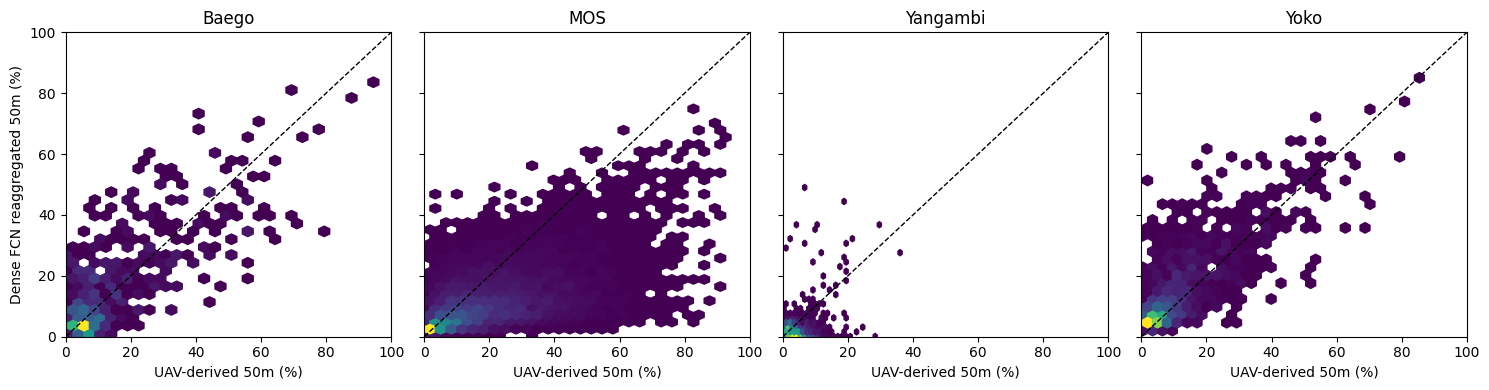

11B COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/11B_dense_FCN_LOFO


In [6]:
# 11B — strict forest LOFO, dense 10m FCN. No EE and no earlier-block retraining.
import os,json,time,hashlib,random
from pathlib import Path
import numpy as np,pandas as pd,rasterio,matplotlib.pyplot as plt,torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from rasterio.windows import Window
from rasterio.warp import transform as project_xy11b
from scipy.ndimage import binary_erosion
from IPython.display import display
assert 'root10' in globals() and 's2resolved10' in globals() and 'emb10' in globals(), 'Run 10A first.'
assert torch.cuda.is_available(),'Select an L4 or T4 GPU runtime for Block 11B.'
torch.set_num_threads(2)
sites11b=list(forests10);d11b=d10.reset_index(drop=True)
N11b=len(d11b);assert N11b==14454
gatefile11b=root10/'11A2_native_coverage_annotations/11A2_gate.json'
assert gatefile11b.is_file(), '11A2 must complete before 11B.'
gate11b=json.loads(gatefile11b.read_text())
assert gate11b['gate'] is True, '11A2 data coverage/annotation availability gate failed. Diagnose before training.'
teacherfolder11b=root10/'11A_dense_UAV_teacher_10m'
for site11b in sites11b:
 assert (teacherfolder11b/f'{site11b}_complete.json').exists(),f'Missing 11A completed teacher {site11b}'
out11b=root10/'11B_dense_FCN_LOFO';out11b.mkdir(exist_ok=True,parents=True)
device11b=torch.device('cuda');seed11b=20261027
torch.manual_seed(seed11b);np.random.seed(seed11b);random.seed(seed11b)
# Frozen experiment settings: no adaptive tuning on held-out forests.
cfg11b=dict(version='11B_dense_FCN_v1',forests=sites11b,seed=seed11b,
    tile=64,per_site_patches_per_epoch=96,epochs=16,batch=12,
    max_valid_centers_per_site=30000,lr=0.0007,
    inference_core=112,halo=16,feature_channels=79,
    target='UAV_teacher_fraction_10m',validation='frozen_50m_LOFO')
cfgpath11b=out11b/'config.json'
if cfgpath11b.exists():assert json.loads(cfgpath11b.read_text())==cfg11b,'Different 11B config: do not mix cached fits'
else:cfgpath11b.write_text(json.dumps(cfg11b,indent=2))
# Load each forest ONCE into local scratch memmaps: avoid repeated random Google Drive reads.
# Read masks explicitly; invalid predictor pixels are set to zero AFTER scaling.
scratch11b=Path('/content/musanga_11b_native_cache');scratch11b.mkdir(exist_ok=True,parents=True)
arrays11b={};truth11b={};valid11b={};shape11b={};metadata11b={}
for site11b in sites11b:
 f11b=scratch11b/f'{site11b}_features.npy'
 t11b=scratch11b/f'{site11b}_teacher.npy'
 m11b=scratch11b/f'{site11b}_valid.npy'
 sigfile11b=scratch11b/f'{site11b}_source_signature.json'
 teacherfile11b=teacherfolder11b/f'{site11b}_Musanga_UAVteacher_mean_10m.tif'
 countfile11b=teacherfolder11b/f'{site11b}_UAVteacher_contributors_10m.tif'
 paths11b=[s2resolved10[site11b],emb10[site11b],teacherfile11b,countfile11b]
 signature11b=[dict(path=str(q),size=q.stat().st_size,mtime_ns=q.stat().st_mtime_ns) for q in paths11b]
 found11b=all(q.exists() for q in (f11b,t11b,m11b,sigfile11b))
 if found11b and json.loads(sigfile11b.read_text())==signature11b:
  print('11B REUSE local input cache:',site11b,flush=True)
 else:
  for q in (f11b,t11b,m11b):
   q.unlink(missing_ok=True)
  sigfile11b.unlink(missing_ok=True)
  with rasterio.open(paths11b[0]) as s2, rasterio.open(paths11b[1]) as emb, \
       rasterio.open(teacherfile11b) as teach, rasterio.open(countfile11b) as cnt:
   assert s2.count==15 and emb.count==64
   assert s2.shape==emb.shape==teach.shape==cnt.shape
   assert s2.crs==emb.crs==teach.crs==cnt.crs
   assert s2.transform==emb.transform==teach.transform==cnt.transform
   hh,ww=s2.shape
   a=np.lib.format.open_memmap(f11b,mode='w+',dtype='float16',shape=(79,hh,ww))
   validpredict=np.ones((hh,ww),dtype=bool)
   for src,lo in ((s2,0),(emb,15)):
    for band in range(1,src.count+1):
     data=src.read(band,masked=True,out_dtype='float32')
     raw=np.asarray(np.ma.getdata(data),dtype=np.float32)
     ok=~np.ma.getmaskarray(data)&np.isfinite(raw)
     validpredict &= ok
     a[lo+band-1]=np.where(ok,raw,0).astype(np.float16)
   yy=teach.read(1,masked=True)
   target=np.asarray(yy.filled(np.nan),dtype=np.float32)
   contributors=cnt.read(1)
   targetok=(~np.ma.getmaskarray(yy))&np.isfinite(target)&(target>=0)&(target<=1)&(contributors>0)
   a.flush()
   ta=np.lib.format.open_memmap(t11b,mode='w+',dtype='float32',shape=(hh,ww))
   ta[:]=np.where(targetok,target,0)
   ta.flush()
   ma=np.lib.format.open_memmap(m11b,mode='w+',dtype='uint8',shape=(hh,ww))
   ma[:]=(validpredict & targetok).astype('uint8')
   ma.flush()
   del a,ta,ma
  sigfile11b.write_text(json.dumps(signature11b,indent=2))
 arrays11b[site11b]=np.load(f11b,mmap_mode='r')
 truth11b[site11b]=np.load(t11b,mmap_mode='r')
 valid11b[site11b]=np.load(m11b,mmap_mode='r').astype(bool)
 shape11b[site11b]=truth11b[site11b].shape
 with rasterio.open(teacherfile11b) as src11b:
  metadata11b[site11b]={'crs':src11b.crs,'transform':src11b.transform,'profile':src11b.profile.copy()}
 assert arrays11b[site11b].shape[0]==79
 print('11B input',site11b,shape11b[site11b],
       'valid label+predictor fraction',round(valid11b[site11b].mean(),3),flush=True)
# Fully-convolutional network; all spatial positions retained (no pooling/downsampling).
class DenseMusanga11B(nn.Module):
 def __init__(self):
  super().__init__()
  self.stem=nn.Sequential(nn.Conv2d(79,48,3,padding=1),nn.ReLU(inplace=True))
  self.blocks=nn.ModuleList([nn.Sequential(
      nn.Conv2d(48,48,3,padding=1),nn.ReLU(inplace=True),
      nn.Conv2d(48,48,3,padding=1)) for _ in range(3)])
  self.out=nn.Conv2d(48,1,1)
 def forward(self,x):
  z=self.stem(x)
  for block in self.blocks:z=torch.relu(z+block(z))
  return torch.sigmoid(self.out(z))[:,0]
def train_scaler11b(training):
 # Same site contribution; only source-forest valid pixels enter normalization.
 means=[];stds=[]
 for site in training:
  rng=np.random.default_rng(seed11b+sites11b.index(site))
  candidates=np.flatnonzero(valid11b[site].ravel())
  assert len(candidates)>1000,('Too few valid training pixels',site)
  picks=rng.choice(candidates,min(30000,len(candidates)),replace=False)
  rr,cc=np.unravel_index(picks,shape11b[site])
  samples=np.asarray(arrays11b[site][:,rr,cc],dtype=np.float32)
  means.append(samples.mean(1));stds.append((samples**2).mean(1))
 mu=np.stack(means).mean(0)
 sd=np.sqrt(np.maximum(np.stack(stds).mean(0)-mu**2,1e-6))
 return mu.astype(np.float32),np.maximum(sd,1e-3).astype(np.float32)
def read_patch11b(site,row,col,size,mu,sd):
 # square centered at (row,col); at real outer boundaries zero-pad normalized features.
 H,W=shape11b[site];half=size//2
 r0=row-half;c0=col-half;r1=r0+size;c1=c0+size
 yr0=max(r0,0);yc0=max(c0,0);yr1=min(r1,H);yc1=min(c1,W)
 x=np.zeros((79,size,size),dtype=np.float32)
 lab=np.zeros((size,size),dtype=np.float32)
 mask=np.zeros((size,size),dtype=np.float32)
 if yr0<yr1 and yc0<yc1:
  slr=slice(yr0-r0,yr1-r0);slc=slice(yc0-c0,yc1-c0)
  block=np.asarray(arrays11b[site][:,yr0:yr1,yc0:yc1],dtype=np.float32)
  norm=np.clip((block-mu[:,None,None])/sd[:,None,None],-6,6)
  good=valid11b[site][yr0:yr1,yc0:yc1]
  x[:,slr,slc]=np.where(good[None,:,:],norm,0)
  lab[slr,slc]=truth11b[site][yr0:yr1,yc0:yc1]
  mask[slr,slc]=good
 return x,lab,mask
class SampledTiles11B(Dataset):
 def __init__(self,forest_list,mu,sd,epoch):
  self.mu=mu;self.sd=sd
  rng=np.random.default_rng(seed11b+epoch)
  self.entries=[]
  for site in forest_list:
   # avoid edge-label artifacts: select centers away from invalid native UAV border.
   candidate=binary_erosion(valid11b[site],iterations=2,border_value=0)
   ids=np.flatnonzero(candidate.ravel())
   assert len(ids)>300,('Too few interior training centers',site)
   selected=rng.choice(ids,cfg11b['per_site_patches_per_epoch'],replace=len(ids)<cfg11b['per_site_patches_per_epoch'])
   rr,cc=np.unravel_index(selected,shape11b[site])
   self.entries.extend((site,int(r),int(c)) for r,c in zip(rr,cc))
  rng.shuffle(self.entries)
 def __len__(self):return len(self.entries)
 def __getitem__(self,i):
  site,row,col=self.entries[i]
  x,y,m=read_patch11b(site,row,col,64,self.mu,self.sd)
  return torch.from_numpy(x),torch.from_numpy(y),torch.from_numpy(m)
def dense_infer11b(site,model,mu,sd,destination):
 # Tiled native 10m inference, halo 16 pixels. No ground truth used in model.
 H,W=shape11b[site];core=cfg11b['inference_core'];halo=cfg11b['halo']
 prof=metadata11b[site]['profile'].copy()
 for key in ('photometric','alpha','extrasamples','NBITS','colorinterp','interleave'):
  prof.pop(key,None)
 prof.update(driver='GTiff',count=1,dtype='float32',nodata=-9999.,
             tiled=True,blockxsize=256,blockysize=256,compress='deflate',predictor=3)
 tmp=destination.with_name(destination.stem+'.partial.tif')
 tmp.unlink(missing_ok=True)
 with rasterio.open(tmp,'w',**prof) as dst:
  step=0;total=((H+core-1)//core)*((W+core-1)//core)
  for row in range(0,H,core):
   for col in range(0,W,core):
    hh=min(core,H-row);ww=min(core,W-col)
    # provide fixed 16-px halo and zero fill outside real raster.
    patchsize=core+2*halo
    centerrow=row+core//2;centercol=col+core//2
    X,_,_=read_patch11b(site,centerrow,centercol,patchsize,mu,sd)
    with torch.no_grad():
     estimate=model(torch.from_numpy(X[None]).to(device11b))[0].cpu().numpy()
    center=estimate[halo:halo+hh,halo:halo+ww]
    mask=valid11b[site][row:row+hh,col:col+ww]
    tile=np.where(mask,center,-9999.).astype('float32')
    dst.write(tile,1,window=Window(col,row,ww,hh))
    step+=1
   if row==0 or (row//core+1)%4==0 or row+hh>=H:
    print(f'11B INFER {site}: {step}/{total} dense tiles',flush=True)
 os.replace(tmp,destination)
# Four held-out forest models. Each can resume from a complete checkpoint.
for held11b in sites11b:
 fit11b=out11b/f'{held11b}_model.pt'
 predpath11b=out11b/f'{held11b}_LOFO_predicted_Musanga_10m.tif'
 complete11b=out11b/f'{held11b}_complete.json'
 training11b=[s for s in sites11b if s!=held11b]
 if complete11b.exists():
  assert fit11b.exists() and predpath11b.exists()
  info11b=json.loads(complete11b.read_text())
  assert info11b['config']==cfg11b and info11b['train_forests']==training11b
  print('11B REUSE completed LOFO:',held11b,flush=True);continue
 mu11b,sd11b=train_scaler11b(training11b)
 model11b=DenseMusanga11B().to(device11b)
 if fit11b.exists():
  pack11b=torch.load(fit11b,map_location='cpu',weights_only=False)
  assert pack11b['config']==cfg11b and pack11b['train_forests']==training11b
  assert np.allclose(pack11b['mu'],mu11b) and np.allclose(pack11b['sd'],sd11b)
  model11b.load_state_dict(pack11b['state_dict'])
  print('11B CHECKPOINT RECOVERED',held11b,flush=True)
 else:
  torch.manual_seed(seed11b)
  model11b=DenseMusanga11B().to(device11b)
  opt11b=torch.optim.AdamW(model11b.parameters(),lr=cfg11b['lr'])
  print('\n11B FIT',held11b,'train sites',training11b,flush=True)
  start11b=time.monotonic()
  for epoch11b in range(cfg11b['epochs']):
   sample11b=SampledTiles11B(training11b,mu11b,sd11b,epoch11b)
   loader11b=DataLoader(sample11b,batch_size=cfg11b['batch'],
                        shuffle=False,num_workers=0)
   model11b.train();loss_total11b=0.;n_total11b=0
   for xx11b,yy11b,mm11b in loader11b:
    xx11b=xx11b.to(device11b);yy11b=yy11b.to(device11b);mm11b=mm11b.to(device11b)
    opt11b.zero_grad(set_to_none=True)
    pp11b=model11b(xx11b)
    loss11b=(((pp11b-yy11b)**2)*mm11b).sum()/mm11b.sum().clamp_min(1)
    loss11b.backward()
    opt11b.step()
    loss_total11b+=float(loss11b.detach())*len(xx11b);n_total11b+=len(xx11b)
   if epoch11b==0 or (epoch11b+1)%2==0:
    print(f'11B {held11b} epoch {epoch11b+1}/{cfg11b["epochs"]}: training MSE {loss_total11b/n_total11b:.5f}; {time.monotonic()-start11b:.0f}s',flush=True)
  checkpoint11b=dict(state_dict={k:v.detach().cpu() for k,v in model11b.state_dict().items()},
       mu=mu11b,sd=sd11b,train_forests=training11b,heldout=held11b,config=cfg11b)
  tmp11b=fit11b.with_suffix('.partial')
  torch.save(checkpoint11b,tmp11b);os.replace(tmp11b,fit11b)
  print('11B MODEL SAVED:',held11b,flush=True)
 model11b.eval()
 dense_infer11b(held11b,model11b,mu11b,sd11b,predpath11b)
 complete11b.write_text(json.dumps(dict(config=cfg11b,train_forests=training11b,
                           prediction=str(predpath11b),model=str(fit11b)),indent=2))
 print('11B HELD OUT FOREST DONE:',held11b,flush=True)
 del model11b
 torch.cuda.empty_cache()
# Strict paired 50m evaluation. Same fixed observations and HGB predictions.
b11b=pd.read_parquet(root10/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet')
keys11b=['site','mosaic','row','col']
assert len(b11b)==N11b and all(b11b[k].equals(d11b[k]) for k in keys11b)
pred11b=np.full(N11b,np.nan,np.float32);cover11b=np.zeros(N11b,np.float32)
for site11b in sites11b:
 ids=np.flatnonzero(d11b.site.to_numpy()==site11b)
 predpath11b=out11b/f'{site11b}_LOFO_predicted_Musanga_10m.tif'
 with rasterio.open(predpath11b) as src11b:
  x=d11b.x.iloc[ids].to_numpy(float);y=d11b.y.iloc[ids].to_numpy(float)
  crs=str(d11b.crs.iloc[ids[0]]) if 'crs' in d11b else 'EPSG:32635'
  if crs!=str(src11b.crs):
   x,y=project_xy11b(crs,src11b.crs,x.tolist(),y.tolist())
  for j,i in enumerate(ids):
   c,r=(~src11b.transform)*(x[j],y[j])
   win=Window(int(np.floor(c))-2,int(np.floor(r))-2,5,5)
   zz=src11b.read(1,window=win,boundless=True,fill_value=-9999.)
   good=(zz>=0)&(zz<=1)&np.isfinite(zz)
   cover11b[i]=good.mean()
   if good.any():pred11b[i]=np.mean(zz[good])
 assert np.all(cover11b[ids]>=.90),(site11b,'incomplete 50m validation support',np.min(cover11b[ids]))
assert np.isfinite(pred11b).all()
y11b=d11b.target_fraction.to_numpy(float)
all11b={'HGB':b11b.pred_baseline.to_numpy(float),'Dense_FCN':pred11b}
metrics11b=[];bins11b=[]
edges11b=[0,.10,.20,.40,.60,1.00001]
labels11b=['0–10%','10–20%','20–40%','40–60%','≥60%']
for name,preds in all11b.items():
 for site in sites11b:
  region=d11b.site.to_numpy()==site
  error=preds[region]-y11b[region]
  for threshold in [.4,.6]:
   high=y11b[region]>=threshold
   metrics11b.append(dict(model=name,site=site,threshold=threshold,
      n=int(region.sum()),MSE=float(np.mean(error**2)),
      MAE_pp=float(100*np.mean(np.abs(error))),bias_pp=float(100*np.mean(error)),
      high_n=int(high.sum()),high_bias_pp=float(100*np.mean(error[high])) if high.any() else np.nan,
      high_recall=float(np.mean(preds[region][high]>=threshold)) if high.any() else np.nan))
  for b in range(5):
   mask=region&(y11b>=edges11b[b])&(y11b<edges11b[b+1])
   if mask.sum()==0:continue
   e=preds[mask]-y11b[mask]
   bins11b.append(dict(model=name,site=site,bin=labels11b[b],n=int(mask.sum()),
      observed_pct=float(100*np.mean(y11b[mask])),predicted_pct=float(100*np.mean(preds[mask])),
      bias_pp=float(100*np.mean(e)),MAE_pp=float(100*np.mean(abs(e)))))
site11b_metrics=pd.DataFrame(metrics11b)
bin11b_metrics=pd.DataFrame(bins11b)
global11b=[]
forestmeans11b=np.array([y11b[d11b.site==s].mean() for s in sites11b])
grandmean11b=forestmeans11b.mean()
variance11b=np.mean([np.mean((y11b[d11b.site==s]-grandmean11b)**2) for s in sites11b])
for name in all11b:
 g=site11b_metrics[(site11b_metrics.model==name)&(site11b_metrics.threshold==.4)]
 mos=g[g.site=='MOS'].iloc[0]
 global11b.append(dict(model=name,equal_forest_R2=1-g.MSE.mean()/variance11b,
    equal_forest_MAE_pp=float(g.MAE_pp.mean()),
    MOS_high40_bias_pp=mos.high_bias_pp,MOS_high40_recall=mos.high_recall))
glob11b=pd.DataFrame(global11b)
print('\n11B — paired STRICT held-out forest comparison (reference=UAV model-derived 50m fractions)',flush=True)
display(glob11b.round(3))
display(site11b_metrics.round(3))
print('\nMOS abundance class diagnostic')
display(bin11b_metrics[bin11b_metrics.site=='MOS'].round(3))
glob11b.to_csv(out11b/'11B_global.csv',index=False)
site11b_metrics.to_csv(out11b/'11B_per_forest.csv',index=False)
bin11b_metrics.to_csv(out11b/'11B_abundance_bins.csv',index=False)
paired11b=d11b[keys11b+['target_fraction']].copy()
paired11b['pred_HGB']=all11b['HGB'];paired11b['pred_Dense_FCN']=pred11b
paired11b['fraction_valid_10m']=cover11b
paired11b.to_parquet(out11b/'11B_paired_50m_predictions.parquet',index=False)
fig,axes=plt.subplots(1,4,figsize=(15,4),sharex=True,sharey=True)
for ax,site in zip(axes,sites11b):
 sel=d11b.site.to_numpy()==site
 ax.hexbin(100*y11b[sel],100*pred11b[sel],gridsize=28,mincnt=1,cmap='viridis')
 ax.plot([0,100],[0,100],'k--',lw=1)
 ax.set(title=site,xlim=(0,100),ylim=(0,100),xlabel='UAV-derived 50m (%)')
axes[0].set_ylabel('Dense FCN reaggregated 50m (%)')
fig.tight_layout();fig.savefig(out11b/'11B_dense_FCN_LOFO_50m_scatter.png',dpi=170);plt.show()
print('11B COMPLETE:',out11b,flush=True)


## 12 — Lang-inspired multitemporal Sentinel-2 ensemble (cached 3-year quarterly composites)

**12A:** Fit four independent seasonal HGB ensembles (one per quarter). Each predictor uses the **same 64 annual embedding bands + exactly one quarterly 10-feature S2 block**, with the quarter's 11th band used only as a clear-observation count. **12B:** Average the four seasonal predictions in a fixed, equal-weight ensemble; compare both seasonal members and their combination against Block 09's original annual+quarterly+embedding HGB. No seasonal weights, calibration, model ranking or MOS-specific hyperparameters are selected using held-out forest labels.

**Key distinction from Lang:** available source is a **3-year aggregated quarterly composite**, not 10 individual Sentinel-2 scenes. This is a first, reproducible ensemble test, *not* yet a scene-level multitemporal implementation. Quarterly composites were built from a three-year lookback window ending in the nominal UAV year; check original image dates before causal or historical change claims.

Frozen 14,454 UAV-derived 50 m references; four strict LOFO folds; same stratified `draw_balanced` recipe, 1,500 training cells per forest maximum and five HGB ensemble members (seeds fixed). Seasonal models use train-only data and preserve all four held-out test forests. All prediction vectors, per-forest scores, MOS 40/60% diagnostics, and abundance-class plots are saved. Restartable on the level of seasonal-member files. **Run Block 12 standalone:** only a mounted Drive and the frozen NB06 reference + Block 09 benchmark are needed; no need to rerun 10–11. CPU sufficient.

**GEDI next (Block 13):** first inspect existing quality-filtered GEDI L2A RH98 and L2B PAI/FHD/PAVD coverage and date consistency; test added structural information or train-only residual correction *after* seasonal benchmarking. Existing direct GEDI–Musanga correlations were weak, and sparse GEDI coverage does not justify assuming wall-to-wall structural information.


12A START: 4 quarters, 4 held-out forests, 5 ensemble members (80 lightweight HGB fits max)
Important: 3-year quarterly composites, not per-scene acquisitions.
12A DONE Baego Q1: 480 held-out cells; 5.5s
12A DONE Baego Q2: 480 held-out cells; 5.4s
12A DONE Baego Q3: 480 held-out cells; 5.4s
12A DONE Baego Q4: 480 held-out cells; 5.3s
12A DONE MOS Q1: 11,494 held-out cells; 6.1s
12A DONE MOS Q2: 11,494 held-out cells; 6.0s
12A DONE MOS Q3: 11,494 held-out cells; 6.1s
12A DONE MOS Q4: 11,494 held-out cells; 6.0s
12A DONE Yangambi Q1: 1,383 held-out cells; 5.2s
12A DONE Yangambi Q2: 1,383 held-out cells; 5.1s
12A DONE Yangambi Q3: 1,383 held-out cells; 5.1s
12A DONE Yangambi Q4: 1,383 held-out cells; 5.2s
12A DONE Yoko Q1: 1,097 held-out cells; 5.1s
12A DONE Yoko Q2: 1,097 held-out cells; 5.1s
12A DONE Yoko Q3: 1,097 held-out cells; 5.0s
12A DONE Yoko Q4: 1,097 held-out cells; 5.1s

12B GLOBAL — four strict held-out forests, same frozen 50m target


,model,equal_forest_R2,equal_forest_MAE_pp,MOS_high40_bias_pp,MOS_high40_recall,MOS_mean_seasonal_disagreement_pp
0,Q1,0.462,7.710,-15.897,0.397,4.361
1,Q2,0.411,8.152,-15.664,0.475,4.361
2,Q3,0.503,7.358,-23.449,0.222,4.361
3,Q4,0.451,7.711,-26.168,0.130,4.361
4,Seasonal_ensemble,0.504,7.464,-20.295,0.264,4.361
5,HGB_baseline,0.545,6.853,-12.669,0.484,4.361



12B PER FOREST


,model,site,threshold,n,MAE_pp,MSE,bias_pp,high_n,high_bias_pp,high_recall
0,Q1,Baego,0.4,480,6.950,0.009,-1.656,57,-18.250,0.333
2,Q1,MOS,0.4,11494,10.893,0.020,3.602,1449,-15.897,0.397
4,Q1,Yangambi,0.4,1383,5.230,0.004,4.817,0,NaN,NaN
6,Q1,Yoko,0.4,1097,7.764,0.014,3.710,62,-9.058,0.645
8,Q2,Baego,0.4,480,6.841,0.009,0.142,57,-12.482,0.561
10,Q2,MOS,0.4,11494,11.601,0.024,4.230,1449,-15.664,0.475
12,Q2,Yangambi,0.4,1383,6.500,0.006,6.286,0,NaN,NaN
14,Q2,Yoko,0.4,1097,7.666,0.013,3.022,62,-10.717,0.516
16,Q3,Baego,0.4,480,6.592,0.009,-1.019,57,-14.177,0.491
18,Q3,MOS,0.4,11494,9.720,0.018,-1.483,1449,-23.449,0.222



12B MOS ABUNDANCE BINS


,model,site,abundance_class,n,mean_observed_pct,mean_predicted_pct,MAE_pp,bias_pp
5,Q1,MOS,0–10%,4004,4.949,14.360,9.663,9.411
6,Q1,MOS,10–20%,2830,14.654,23.276,10.972,8.622
7,Q1,MOS,20–40%,3211,28.620,29.352,9.185,0.732
8,Q1,MOS,40–60%,1124,48.046,35.093,15.543,-12.954
9,Q1,MOS,≥60%,325,69.826,43.752,26.169,-26.074
23,Q2,MOS,0–10%,4004,4.949,14.558,9.813,9.609
24,Q2,MOS,10–20%,2830,14.654,23.771,11.969,9.117
25,Q2,MOS,20–40%,3211,28.620,30.812,10.914,2.192
26,Q2,MOS,40–60%,1124,48.046,35.766,14.436,-12.280
27,Q2,MOS,≥60%,325,69.826,42.458,27.414,-27.368


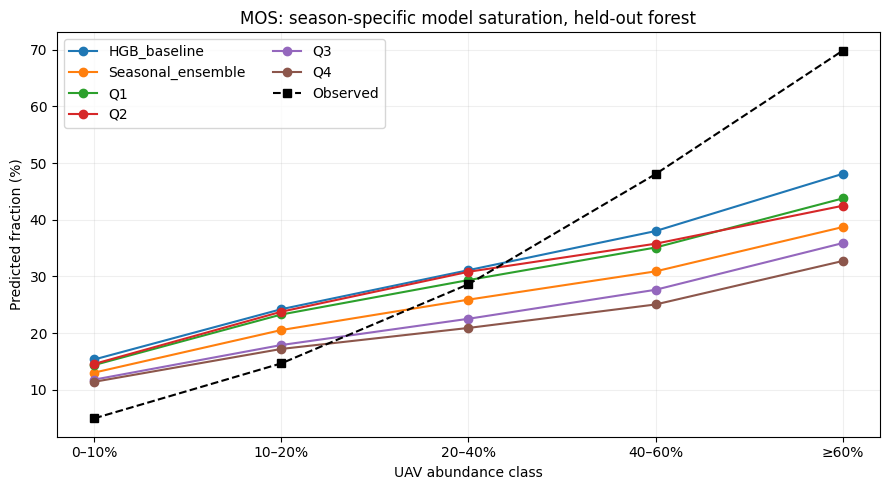

Block 12 COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/12_seasonal_S2_ensemble


In [7]:
# 12A/12B — FOUR season-specific HGB models + FIXED equal-weight temporal ensemble.
# Frozen data, train-only stratified draws, strict LOFO. NO EE extraction.
from pathlib import Path
import os,json,hashlib,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
roots12=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
         Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((q/'frozen_50m_reference.parquet').is_file() for q in roots12):
 from google.colab import drive
 drive.mount('/content/drive')
roots12=[q for q in roots12 if (q/'frozen_50m_reference.parquet').is_file()]
assert len(roots12)==1,('Frozen NB06 reference not uniquely available',roots12)
root12=roots12[0];ref12=pd.read_parquet(root12/'frozen_50m_reference.parquet').reset_index(drop=True)
sites12=['Baego','MOS','Yangambi','Yoko'];keys12=['site','mosaic','row','col']
assert len(ref12)==14454 and not ref12.duplicated(keys12).any()
assert ref12.groupby('site').size().to_dict()=={'Baego':480,'MOS':11494,'Yangambi':1383,'Yoko':1097}
y12=ref12.target_fraction.to_numpy(dtype=float);forest12=ref12.site.to_numpy()
assert np.isfinite(y12).all() and ((y12>=0)&(y12<=1)).all()
cols12=sorted([c for c in ref12 if c.startswith('S2_QUARTERLY_3YR__')])
emb12=sorted([c for c in ref12 if c.startswith('EMB_ANNUAL__')])
annual12=sorted([c for c in ref12 if c.startswith('RAW_ANNUAL__')])
assert len(cols12)==44 and len(emb12)==64 and len(annual12)==15,(len(cols12),len(emb12),len(annual12))
seasons12={}
for quarter12 in range(4):
 qcols=[f'S2_QUARTERLY_3YR__{j:02d}' for j in range(quarter12*11+1,(quarter12+1)*11+1)]
 assert all(c in ref12 for c in qcols),('Expected 11-feature quarterly block',quarter12)
 # Per-quarter bands 1..10 = S2 spectral/indices, band 11 = clear observation count.
 valuecols=qcols[:10];countcol=qcols[10]
 assert (ref12[countcol].to_numpy(float)>=1).all(),('Missing clear observations',quarter12,countcol)
 assert np.isfinite(ref12[valuecols+emb12].to_numpy(dtype=float)).all()
 seasons12[f'Q{quarter12+1}']=dict(features=emb12+valuecols,count=countcol)
basefile12=root12/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet'
assert basefile12.is_file(),'Need baseline Block09 paired LOFO predictions (do not rerun Block09).'
base12=pd.read_parquet(basefile12)
assert len(base12)==len(ref12) and all(base12[k].equals(ref12[k]) for k in keys12)
assert np.isfinite(base12.pred_baseline.to_numpy(float)).all()
out12=root12/'12_seasonal_S2_ensemble';out12.mkdir(parents=True,exist_ok=True)
seed12=20261026;cap12=1500;members12=5
params12=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,min_samples_leaf=35,
              l2_regularization=2,early_stopping=False)
fingerprint12=hashlib.sha256(pd.util.hash_pandas_object(
 ref12[keys12+['target_fraction']+cols12+emb12],index=False).values.tobytes()).hexdigest()
config12=dict(version='12A_12B_quarterly_3yr_separate_HGB_v1',
   seed=seed12,cap=cap12,members=members12,model=params12,
   sites=sites12,quarters=list(seasons12),fingerprint=fingerprint12,
   n=len(ref12),seasonal_feature_count=74,
   combination='arithmetic_mean_unweighted_4_seasons')
configfile12=out12/'config.json'
if configfile12.exists():
 assert json.loads(configfile12.read_text())==config12,'Block 12 cache config mismatch'
else:configfile12.write_text(json.dumps(config12,indent=2))
def draw_balanced12(pool,seed):
 # Identical logic to Block09: seed, per-site cap, bins, 25% high >=40% initial.
 rng=np.random.default_rng(seed);selected=[]
 for name in sites12:
  ix=pool[forest12[pool]==name]
  if not len(ix):continue
  cap=min(cap12,len(ix))
  if len(ix)<=cap:selected.extend(ix.tolist());continue
  labels=np.digitize(y12[ix],[.10,.20,.40])
  bins={b:ix[labels==b] for b in range(4)}
  n=min(len(bins[3]),int(np.ceil(cap*.25)))
  pick=rng.choice(bins[3],n,replace=False).tolist() if n else []
  bins[3]=np.setdiff1d(bins[3],pick)
  while len(pick)<cap:
   active=[b for b in bins if len(bins[b])]
   assert active
   for b in active:
    n=min(len(bins[b]),max(1,(cap-len(pick))//len(active)),cap-len(pick))
    if n:
     take=rng.choice(bins[b],n,replace=False)
     pick.extend(take.tolist());bins[b]=np.setdiff1d(bins[b],take)
    if len(pick)==cap:break
  selected.extend(pick)
 return np.array(sorted(selected),dtype=int)
pred12={q:np.full(len(ref12),np.nan,dtype=np.float32) for q in seasons12}
print('12A START: 4 quarters, 4 held-out forests, 5 ensemble members (80 lightweight HGB fits max)',flush=True)
print('Important: 3-year quarterly composites, not per-scene acquisitions.',flush=True)
for held12 in sites12:
 train12=np.flatnonzero(forest12!=held12);test12=np.flatnonzero(forest12==held12)
 for season12,info12 in seasons12.items():
  f12=out12/f'12A_{held12}_{season12}_5members.npz'
  if f12.exists():
   with np.load(f12) as z:
    assert np.array_equal(z['test'],test12)
    assert z['prediction'].shape==(len(test12),)
    pred12[season12][test12]=z['prediction']
   print('12A REUSE:',held12,season12,flush=True)
   continue
  X12=ref12[info12['features']].to_numpy(np.float32)
  votes12=[]
  started12=time.monotonic()
  for member12 in range(members12):
   # As in Block 09, each model member uses a deterministic train-only draw.
   selected12=draw_balanced12(train12,seed12+member12)
   learner12=HistGradientBoostingRegressor(**params12,random_state=seed12+member12)
   learner12.fit(X12[selected12],y12[selected12])
   votes12.append(learner12.predict(X12[test12]).clip(0,1))
  predictions12=np.mean(votes12,axis=0).astype(np.float32)
  assert np.isfinite(predictions12).all()
  with f12.with_suffix('.partial').open('wb') as fh:
   np.savez_compressed(fh,test=test12,prediction=predictions12,
                      members=np.stack(votes12).astype(np.float32))
  os.replace(f12.with_suffix('.partial'),f12)
  pred12[season12][test12]=predictions12
  print(f'12A DONE {held12} {season12}: {len(test12):,} held-out cells; {time.monotonic()-started12:.1f}s',flush=True)
assert all(np.isfinite(p).all() for p in pred12.values())
pred12['Seasonal_ensemble']=np.mean(np.stack([pred12[q] for q in seasons12]),axis=0)
pred12['HGB_baseline']=base12.pred_baseline.to_numpy(np.float32)
# Test-time disagreement measures seasonal sensitivity, NOT calibrated predictive uncertainty.
seasonalspread12=np.std(np.stack([pred12[q] for q in seasons12]),axis=0,ddof=0)
results12=[];bins12=[]
edges12=[0,.10,.20,.40,.60,1.00001]
labels12=['0–10%','10–20%','20–40%','40–60%','≥60%']
for name12,p12 in pred12.items():
 for site12 in sites12:
  sel12=(forest12==site12);err12=p12[sel12]-y12[sel12]
  for threshold12 in [.4,.6]:
   high12=y12[sel12]>=threshold12
   results12.append(dict(model=name12,site=site12,threshold=threshold12,
      n=int(sel12.sum()),MAE_pp=float(100*np.mean(abs(err12))),
      MSE=float(np.mean(err12**2)),bias_pp=float(100*np.mean(err12)),
      high_n=int(high12.sum()),high_bias_pp=float(100*np.mean(err12[high12])) if high12.any() else np.nan,
      high_recall=float(np.mean(p12[sel12][high12]>=threshold12)) if high12.any() else np.nan))
  for k12 in range(5):
   ix12=sel12&(y12>=edges12[k12])&(y12<edges12[k12+1])
   if ix12.sum()==0:continue
   ee12=p12[ix12]-y12[ix12]
   bins12.append(dict(model=name12,site=site12,abundance_class=labels12[k12],n=int(ix12.sum()),
     mean_observed_pct=float(100*y12[ix12].mean()),
     mean_predicted_pct=float(100*p12[ix12].mean()),
     MAE_pp=float(100*np.abs(ee12).mean()),bias_pp=float(100*ee12.mean())))
per12=pd.DataFrame(results12);classes12=pd.DataFrame(bins12)
refmean12=np.mean([y12[forest12==s].mean() for s in sites12])
refvar12=np.mean([np.mean((y12[forest12==s]-refmean12)**2) for s in sites12])
summary12=[]
for name12 in pred12:
 g12=per12[(per12.model==name12)&(per12.threshold==.4)]
 mos12=g12[g12.site=='MOS'].iloc[0]
 summary12.append(dict(model=name12,equal_forest_R2=1-float(g12.MSE.mean())/refvar12,
  equal_forest_MAE_pp=float(g12.MAE_pp.mean()),MOS_high40_bias_pp=float(mos12.high_bias_pp),
  MOS_high40_recall=float(mos12.high_recall),
  MOS_mean_seasonal_disagreement_pp=float(100*seasonalspread12[forest12=='MOS'].mean())))
summary12=pd.DataFrame(summary12)
print('\n12B GLOBAL — four strict held-out forests, same frozen 50m target',flush=True)
display(summary12.round(3))
print('\n12B PER FOREST',flush=True)
display(per12[per12.threshold==.4].round(3))
print('\n12B MOS ABUNDANCE BINS',flush=True)
display(classes12[classes12.site=='MOS'].round(3))
summary12.to_csv(out12/'12B_global.csv',index=False)
per12.to_csv(out12/'12B_per_forest.csv',index=False)
classes12.to_csv(out12/'12B_abundance_bins.csv',index=False)
paired12=ref12[keys12+['x','y','target_fraction']].copy()
for name12,p12 in pred12.items():paired12['pred_'+name12]=p12
paired12['seasonal_disagreement']=seasonalspread12
paired12.to_parquet(out12/'12B_paired_LOFO_predictions.parquet',index=False)
# Diagnostic: fixed five abundance classes; never use this display to tune the held-out forests.
fig12,ax12=plt.subplots(figsize=(9,5))
mosclass12=classes12[classes12.site=='MOS']
for name12 in ['HGB_baseline','Seasonal_ensemble','Q1','Q2','Q3','Q4']:
 z12=mosclass12[mosclass12.model==name12].set_index('abundance_class').reindex(labels12)
 ax12.plot(labels12,z12.mean_predicted_pct.to_numpy(),marker='o',label=name12)
truth12=mosclass12[mosclass12.model=='HGB_baseline'].set_index('abundance_class').reindex(labels12)
ax12.plot(labels12,truth12.mean_observed_pct.to_numpy(),ls='--',color='black',marker='s',label='Observed')
ax12.set(title='MOS: season-specific model saturation, held-out forest',
         xlabel='UAV abundance class',ylabel='Predicted fraction (%)')
ax12.grid(alpha=.2);ax12.legend(ncol=2)
fig12.tight_layout();fig12.savefig(out12/'12B_MOS_seasonal_saturation.png',dpi=170)
plt.show()
print('Block 12 COMPLETE:',out12,flush=True)


## 13 — Geographic representativeness before GEDI: spatial blocking, MOS novelty and local adaptation

**Purpose:** distinguish within-represented-forest interpolation from **uncalibrated forest-to-forest extrapolation**. Tests the hypothesis that our poor held-out MOS performance is driven in part by geographic training-domain limitations. Keeps original HGB **annual S2 + three-year quarterly S2 + 64D Earth embeddings**, 14,454 frozen 50 m UAV-derived reference cells, and original Block 09 predictions. No new imagery extraction or neural-network training.

**13A — Matched spatial blocks versus forest holdout.** Three deterministic 20%-of-geographic-block test partitions (500 m square grid), 150 m Euclidean exclusion buffer around *all* test cells. HGB trains on remaining forest data with the Block 09 abundance-balanced sample draw. Score its spatial predictions **and the saved strict LOFO HGB** on the *exact same selected test cells*, by site, with repeat variability. This is within-environment interpolation, not independent forest extrapolation.

**13B — MOS novelty.** Using **only Baego, Yangambi and Yoko predictors**, learn robust scaling, a 15-component PCA and nearest-neighbor reference distribution; apply this train-only projection to MOS. A 95th-percentile donor nearest-neighbor distance is a heuristic flag for outside-domain cells. Compare MOS error and ≥40% bias inside and outside the donor domain. MOS labels never determine novelty scores or the threshold.

**13C — MOS geographic learning curve.** Freeze the MOS spatial test blocks selected in 13A. Keep other forests as donors, and progressively add MOS calibration from **0, 1, 2, 4, 8, 16, 32 independent 500 m blocks** outside the 150 m test exclusion buffer, maximum 20 cells/block and 500 MOS cells overall. Geographic calibration blocks and constituent cells are chosen **without looking at MOS target abundance**. Train-only sampling, three independent split repeats, saved predictions and checkpoints at each budget. The zero-MOS curve is a new matched training-budget control, not identical to the already-saved all-MOS LOFO prediction on the full forest.

**Limits:** only 4 forests and 3 geographic repeats; block partitions are not independent statistical replications. A 150 m buffer is a prespecified pragmatic choice, not proof spatial autocorrelation vanishes; sensitivity at other block scales may be needed. Comparing aggregate cells with shared UAV teacher introduces pseudo-label uncertainty. Interpret curves descriptively, not as an independently confirmed optimal MOS calibration budget.

**Run:** single standalone cell after Drive mount. CPU sufficient, prints progress, caches each spatial split and calibration budget. Output folder `CLEAN_NB06/13_geographic_representativeness/`. GEDI structural audit comes *after* reviewing the geographical findings.


13A START: 500m blocks; 150m buffer; 3 repeats; matched 50m HGB vs frozen LOFO.
13A repeat 1/3: 9736 train, 2708 test, 5s
13A repeat 2/3: 9454 train, 2883 test, 5s
13A repeat 3/3: 9652 train, 2842 test, 5s
13A MATCHED SPATIAL vs FOREST LOFO:


,model,site,MAE_pp,sd_MAE_pp,bias_pp,high40_bias_pp,high40_recall
0,Forest_LOFO,Baego,6.237,2.183,-2.050,-16.920,0.342
1,Forest_LOFO,MOS,11.186,0.975,5.834,-12.371,0.496
2,Forest_LOFO,Yangambi,2.750,0.198,1.457,NaN,NaN
3,Forest_LOFO,Yoko,7.526,0.920,1.499,-14.266,0.384
4,Spatial_block,Baego,5.367,1.786,-1.471,-11.718,0.701
5,Spatial_block,MOS,9.446,0.895,3.763,-11.948,0.505
6,Spatial_block,Yangambi,2.239,0.075,-0.312,NaN,NaN
7,Spatial_block,Yoko,7.462,0.325,-0.611,-18.616,0.290


13B MOS out-of-training-domain share: 67.7%; threshold=2.499


,domain,n,MAE_pp,MSE,bias_pp,high_n,high40_bias_pp,high40_recall
0,Inside,3717,7.114,0.009,4.260,214,-4.463,0.780
1,Outside,7777,12.871,0.026,5.459,1235,-14.091,0.432


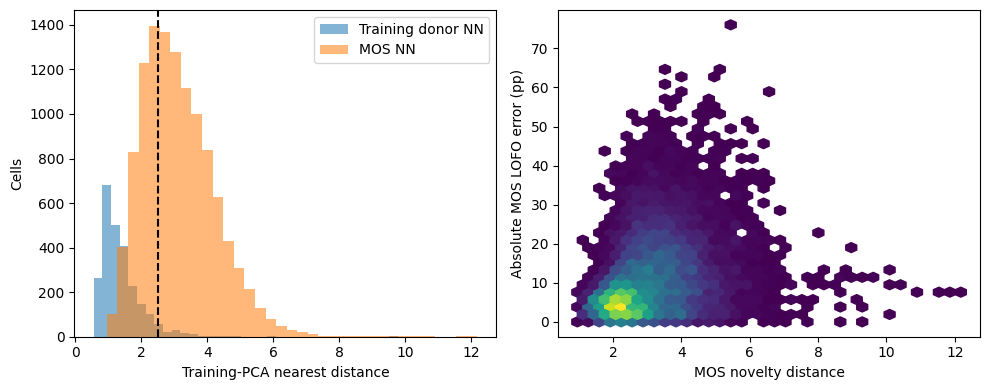

13C START: MOS geographic calibration learning curves; 3 independent test splits.
13C rep=0 budget=0, available_blocks=0, local_cells=0, 5s
13C rep=0 budget=1, available_blocks=1, local_cells=20, 5s
13C rep=0 budget=2, available_blocks=2, local_cells=40, 5s
13C rep=0 budget=4, available_blocks=4, local_cells=80, 5s
13C rep=0 budget=8, available_blocks=8, local_cells=155, 5s
13C rep=0 budget=16, available_blocks=16, local_cells=315, 5s
13C rep=0 budget=32, available_blocks=32, local_cells=500, 5s
13C rep=1 budget=0, available_blocks=0, local_cells=0, 5s
13C rep=1 budget=1, available_blocks=1, local_cells=20, 5s
13C rep=1 budget=2, available_blocks=2, local_cells=40, 5s
13C rep=1 budget=4, available_blocks=4, local_cells=80, 5s
13C rep=1 budget=8, available_blocks=8, local_cells=160, 5s
13C rep=1 budget=16, available_blocks=16, local_cells=318, 5s
13C rep=1 budget=32, available_blocks=32, local_cells=500, 5s
13C rep=2 budget=0, available_blocks=0, local_cells=0, 5s
13C rep=2 budget=1, av

,requested_blocks,used_blocks,calibration_cells,MAE_pp,MAE_sd,high40_bias_pp,high40_recall
0,0,0.0,0.000,11.186,0.975,-12.371,0.496
1,1,1.0,20.000,11.815,2.412,-12.648,0.526
2,2,2.0,40.000,11.174,1.775,-15.012,0.439
3,4,4.0,80.000,10.800,1.907,-16.639,0.370
4,8,8.0,158.333,9.789,1.035,-17.591,0.325
5,16,16.0,317.667,9.321,0.771,-19.651,0.286
6,32,32.0,500.000,9.126,0.937,-19.614,0.282


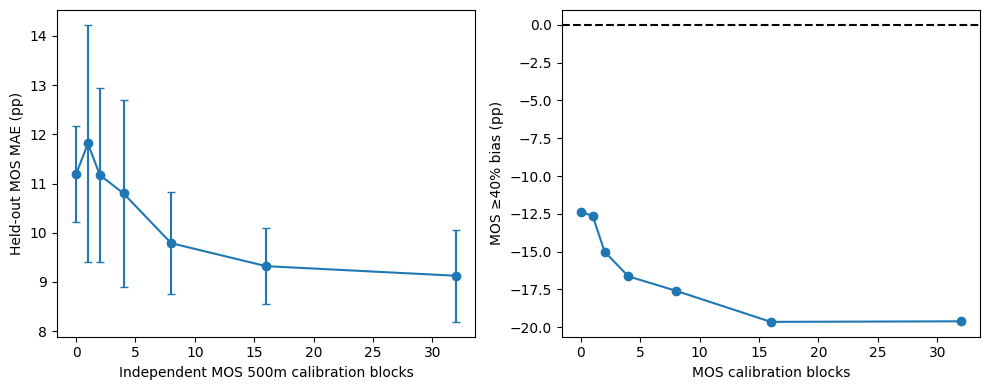

BLOCK 13 COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/13_geographic_representativeness


In [8]:
# 13A–C: geographic holdout, MOS novelty and independent local-calibration curves.
# Run standalone after mounting Drive. CPU only. No imagery extraction or CNN training.
from pathlib import Path
import os,json,hashlib,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
roots13=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'frozen_50m_reference.parquet').is_file() for p in roots13):
 from google.colab import drive
 drive.mount('/content/drive')
roots13=[p for p in roots13 if (p/'frozen_50m_reference.parquet').exists()]
assert len(roots13)==1,roots13
R13=roots13[0];d13=pd.read_parquet(R13/'frozen_50m_reference.parquet').reset_index(drop=True)
sites13=['Baego','MOS','Yangambi','Yoko'];keys13=['site','mosaic','row','col']
assert len(d13)==14454 and not d13.duplicated(keys13).any()
cols13=[c for c in d13 if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__','EMB_ANNUAL__'))]
assert len(cols13)==123,len(cols13)
x13=d13[cols13].to_numpy(np.float32);y13=d13.target_fraction.to_numpy(float)
f13=d13.site.to_numpy();xy13=d13[['x','y']].to_numpy(float)
assert np.isfinite(x13).all() and np.isfinite(xy13).all() and np.isfinite(y13).all()
b13=pd.read_parquet(R13/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet')
assert len(b13)==len(d13) and all(b13[k].equals(d13[k]) for k in keys13)
lofo13=b13.pred_baseline.to_numpy(float)
out13=R13/'13_geographic_representativeness';out13.mkdir(exist_ok=True,parents=True)
seed13=20261026;cap13=1500;members13=3;block13=500;buffer13=150;repeats13=3
param13=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,min_samples_leaf=35,l2_regularization=2,early_stopping=False)
config13=dict(version='v1_geographic',seed=seed13,cap=cap13,members=members13,
 block_m=block13,buffer_m=buffer13,repeats=repeats13,model=param13,
 fingerprint=hashlib.sha256(pd.util.hash_pandas_object(d13[keys13+['x','y','target_fraction']+cols13],index=False).values.tobytes()).hexdigest())
cf13=out13/'config.json'
if cf13.exists():assert json.loads(cf13.read_text())==config13,'Previous configuration differs'
else:cf13.write_text(json.dumps(config13,indent=2))
# Replicate Block09 train-only abundance stratification for HGB.
def draw13(pool,seed):
 rng=np.random.default_rng(seed);result=[]
 for site in sites13:
  ix=pool[f13[pool]==site]
  if not len(ix):continue
  cap=min(cap13,len(ix))
  if len(ix)<=cap:result.extend(ix.tolist());continue
  labels=np.digitize(y13[ix],[.10,.20,.40])
  bins={k:ix[labels==k] for k in range(4)}
  n=min(len(bins[3]),int(np.ceil(.25*cap)))
  chosen=rng.choice(bins[3],n,replace=False).tolist() if n else []
  bins[3]=np.setdiff1d(bins[3],chosen)
  while len(chosen)<cap:
   active=[k for k in bins if len(bins[k])]
   for k in active:
    n=min(len(bins[k]),max(1,(cap-len(chosen))//len(active)),cap-len(chosen))
    if n:
     take=rng.choice(bins[k],n,replace=False)
     chosen.extend(take.tolist());bins[k]=np.setdiff1d(bins[k],take)
    if len(chosen)==cap:break
  result.extend(chosen)
 return np.array(sorted(result),dtype=int)
def fit13(train,test,seed,local=None):
 preds=[]
 for member in range(members13):
  sample=draw13(train,seed+107*member)
  if local is not None and len(local):sample=np.concatenate([sample,local])
  model=HistGradientBoostingRegressor(**param13,random_state=seed13+member)
  model.fit(x13[sample],y13[sample]);preds.append(np.clip(model.predict(x13[test]),0,1))
 return np.mean(preds,axis=0)
# Grid IDs cannot leak across either MOS mosaic because both share one forest key.
bx13=np.floor(xy13[:,0]/block13).astype(int)
by13=np.floor(xy13[:,1]/block13).astype(int)
keysgrid13=np.array([f'{s}:{a}:{b}' for s,a,b in zip(f13,bx13,by13)])
def split13(rep):
 rng=np.random.default_rng(seed13+9001+rep)
 tests=[]
 for site in sites13:
  blocks=np.unique(keysgrid13[f13==site])
  assert len(blocks)>=5,(site,len(blocks))
  pick=rng.choice(blocks,size=max(1,int(np.ceil(.2*len(blocks)))),replace=False)
  tests.extend(np.flatnonzero((f13==site)&np.isin(keysgrid13,pick)).tolist())
 test=np.array(sorted(tests),dtype=int)
 candidates=np.setdiff1d(np.arange(len(d13)),test)
 distances=cKDTree(xy13[test]).query(xy13[candidates],workers=-1)[0]
 train=candidates[distances>=buffer13]
 assert len(train)>1000 and not np.intersect1d(train,test).size
 return train,test
def stats13(actual,pred):
 e=pred-actual;high=actual>=.4
 return dict(n=len(actual),MAE_pp=float(100*np.abs(e).mean()),MSE=float(np.mean(e*e)),
 bias_pp=float(100*e.mean()),high_n=int(high.sum()),
 high40_bias_pp=float(100*e[high].mean()) if high.any() else np.nan,
 high40_recall=float(np.mean(pred[high]>=.4)) if high.any() else np.nan)
splits=[];a13=[];apreds=[]
print('13A START: 500m blocks; 150m buffer; 3 repeats; matched 50m HGB vs frozen LOFO.',flush=True)
for rep in range(repeats13):
 train,test=split13(rep)
 splits.extend([dict(repeat=rep,index=int(i),role='train') for i in train])
 splits.extend([dict(repeat=rep,index=int(i),role='test') for i in test])
 saved=out13/f'13A_repeat{rep}.npz'
 if saved.exists():
  with np.load(saved) as z:
   assert np.array_equal(z['train'],train) and np.array_equal(z['test'],test)
   pred=z['pred'].copy()
  print('13A REUSE',rep,flush=True)
 else:
  start=time.monotonic();pred=fit13(train,test,seed13+rep*1000)
  with saved.with_suffix('.partial').open('wb') as fh:np.savez_compressed(fh,train=train,test=test,pred=pred)
  os.replace(saved.with_suffix('.partial'),saved)
  print(f'13A repeat {rep+1}/{repeats13}: {len(train)} train, {len(test)} test, {time.monotonic()-start:.0f}s',flush=True)
 for site in sites13:
  select=f13[test]==site;ids=test[select]
  for name,p in [('Spatial_block',pred[select]),('Forest_LOFO',lofo13[ids])]:
   a13.append(dict(repeat=rep,model=name,site=site,**stats13(y13[ids],p)))
  apreds.extend(dict(repeat=rep,index=int(i),site=site,observed=float(y13[i]),
      predicted_spatial=float(v),predicted_LOFO=float(lofo13[i])) for i,v in zip(ids,pred[select]))
pd.DataFrame(splits).to_parquet(out13/'13A_splits.parquet',index=False)
pd.DataFrame(apreds).to_parquet(out13/'13A_paired_predictions.parquet',index=False)
a13=pd.DataFrame(a13);a13.to_csv(out13/'13A_per_forest_repeats.csv',index=False)
summary13=a13.groupby(['model','site'],as_index=False).agg(MAE_pp=('MAE_pp','mean'),
 sd_MAE_pp=('MAE_pp','std'),bias_pp=('bias_pp','mean'),
 high40_bias_pp=('high40_bias_pp','mean'),high40_recall=('high40_recall','mean'))
summary13.to_csv(out13/'13A_summary.csv',index=False)
print('13A MATCHED SPATIAL vs FOREST LOFO:',flush=True);display(summary13.round(3))
# 13B: training-forest-derived applicability domain, no use of MOS reference labels in fitting.
donors=np.flatnonzero(f13!='MOS');mos=np.flatnonzero(f13=='MOS')
rng=np.random.default_rng(seed13+77)
sample=np.concatenate([rng.choice(donors[f13[donors]==s],
    min(1000,np.sum(f13[donors]==s)),replace=False) for s in sites13 if s!='MOS'])
scaler=RobustScaler(quantile_range=(10,90)).fit(x13[sample])
trainz=np.clip(scaler.transform(x13[sample]),-10,10)
pca=PCA(n_components=15,random_state=seed13).fit(trainz)
ztrain=pca.transform(trainz);zmos=pca.transform(np.clip(scaler.transform(x13[mos]),-10,10))
nn=NearestNeighbors(n_neighbors=2).fit(ztrain)
within=nn.kneighbors(ztrain)[0][:,1]
distance=NearestNeighbors(n_neighbors=1).fit(ztrain).kneighbors(zmos)[0][:,0]
threshold=float(np.quantile(within,.95));novel=distance>threshold
error=lofo13[mos]-y13[mos]
novel_table=d13.loc[mos,keys13+['x','y','target_fraction']].copy()
novel_table['domain_distance']=distance;novel_table['outside_domain']=novel
novel_table['LOFO_prediction']=lofo13[mos];novel_table['LOFO_error_pp']=100*error
novel_table.to_parquet(out13/'13B_MOS_domain_distances.parquet',index=False)
brows=[]
for label,sel in [('Inside',~novel),('Outside',novel)]:
 if not sel.any():continue
 brows.append(dict(domain=label,**stats13(y13[mos][sel],lofo13[mos][sel])))
btable=pd.DataFrame(brows);btable.to_csv(out13/'13B_novelty_summary.csv',index=False)
print(f'13B MOS out-of-training-domain share: {100*novel.mean():.1f}%; threshold={threshold:.3f}',flush=True)
display(btable.round(3))
fig,axs=plt.subplots(1,2,figsize=(10,4))
axs[0].hist(within,bins=35,alpha=.55,label='Training donor NN');axs[0].hist(distance,bins=35,alpha=.55,label='MOS NN')
axs[0].axvline(threshold,color='black',ls='--');axs[0].set(xlabel='Training-PCA nearest distance',ylabel='Cells');axs[0].legend()
axs[1].hexbin(distance,100*np.abs(error),gridsize=35,mincnt=1,cmap='viridis')
axs[1].set(xlabel='MOS novelty distance',ylabel='Absolute MOS LOFO error (pp)')
fig.tight_layout();fig.savefig(out13/'13B_novelty.png',dpi=170);plt.show()
# 13C: predeclared geographic budgets. Calibration blocks are selected WITHOUT MOS target values.
budgets13=[0,1,2,4,8,16,32];perblock13=20;caplocal13=500
curves=[];cpreds=[]
print('13C START: MOS geographic calibration learning curves; 3 independent test splits.',flush=True)
for rep in range(repeats13):
 train,test_all=split13(rep)
 test=test_all[f13[test_all]=='MOS']
 localpool=train[f13[train]=='MOS']
 external=np.flatnonzero(f13!='MOS')
 blocks=np.unique(keysgrid13[localpool])
 assert len(blocks)>=3,(rep,len(blocks))
 order=np.random.default_rng(seed13+13579+rep).permutation(blocks)
 for budget in budgets13:
  chosenblocks=order[:min(budget,len(order))]
  local=[]
  for rank,k in enumerate(chosenblocks):
   ix=localpool[keysgrid13[localpool]==k]
   rng=np.random.default_rng(seed13+rep*10000+rank)
   local.extend(rng.choice(ix,min(perblock13,len(ix)),replace=False).tolist())
  local=np.array(local[:caplocal13],dtype=int)
  assert not np.intersect1d(local,test).size
  if len(local):
   assert np.all(cKDTree(xy13[test]).query(xy13[local],workers=-1)[0]>=buffer13)
  dest=out13/f'13C_repeat{rep}_blocks{budget}.npz'
  if dest.exists():
   with np.load(dest) as z:
    assert np.array_equal(z['test'],test) and np.array_equal(z['local'],local)
    p=z['pred'].copy()
   print('13C REUSE',rep,budget,flush=True)
  else:
   start=time.monotonic()
   # Use the same external, abundance-balanced donor sample as baseline and append MOS local cells.
   p=fit13(external,test,seed13+rep*1000,local=local)
   with dest.with_suffix('.partial').open('wb') as fh:np.savez_compressed(fh,test=test,local=local,pred=p)
   os.replace(dest.with_suffix('.partial'),dest)
   print(f'13C rep={rep} budget={budget}, available_blocks={len(chosenblocks)}, local_cells={len(local)}, {time.monotonic()-start:.0f}s',flush=True)
  curves.append(dict(repeat=rep,requested_blocks=budget,used_blocks=len(chosenblocks),
                     calibration_cells=len(local),test_cells=len(test),**stats13(y13[test],p)))
  cpreds.extend(dict(repeat=rep,budget=budget,index=int(i),reference=float(y13[i]),
                     prediction=float(v)) for i,v in zip(test,p))
curve=pd.DataFrame(curves)
curve.to_csv(out13/'13C_MOS_learning_curve_repeats.csv',index=False)
pd.DataFrame(cpreds).to_parquet(out13/'13C_MOS_paired_predictions.parquet',index=False)
mean=curve.groupby('requested_blocks',as_index=False).agg(
 used_blocks=('used_blocks','mean'),calibration_cells=('calibration_cells','mean'),
 MAE_pp=('MAE_pp','mean'),MAE_sd=('MAE_pp','std'),
 high40_bias_pp=('high40_bias_pp','mean'),high40_recall=('high40_recall','mean'))
mean.to_csv(out13/'13C_MOS_learning_curve_summary.csv',index=False)
print('13C MOS ADAPTATION CURVE:',flush=True);display(mean.round(3))
fig,axs=plt.subplots(1,2,figsize=(10,4))
axs[0].errorbar(mean.used_blocks,mean.MAE_pp,yerr=mean.MAE_sd,marker='o',capsize=3)
axs[0].set(xlabel='Independent MOS 500m calibration blocks',ylabel='Held-out MOS MAE (pp)')
axs[1].plot(mean.used_blocks,mean.high40_bias_pp,marker='o')
axs[1].axhline(0,color='black',ls='--')
axs[1].set(xlabel='MOS calibration blocks',ylabel='MOS ≥40% bias (pp)')
fig.tight_layout();fig.savefig(out13/'13C_MOS_learning_curve.png',dpi=170);plt.show()
print('BLOCK 13 COMPLETE:',out13,flush=True)


## 13D — Where should we collect additional UAV calibration data?

**Hypothesis:** geographic calibration improves average MOS MAE but fails to recover high-abundance stands because unstratified local sampling underrepresents the relevant spectral/abundance conditions. Compare **spatially independent 500 m calibration blocks**, holding the *exact same MOS test splits and 150 m exclusion buffers* as 13A/C. Up to 20 MOS reference cells per calibration block; equal cell budgets across strategies wherever possible.

The five policies are:
1. **Random geographic:** archived Block 13C, recovered exactly, not refitted.
2. **Predictor diversity:** greedy farthest-first selection of 500 m block centroids in robust-scaled donor-trained PCA space, starting from the donor-feature centroid. Only unlabeled MOS satellite predictors decide blocks.
3. **Predicted-high-cover:** choose blocks using the highest *MOS-free baseline HGB* predicted cover (mean of the highest fifth of cells in each block); this is deployable as a prospective survey-targeting heuristic but may fail when high cover is spectrally novel.
4. **Combined:** 50% coverage of satellite predictor space + 50% normalized predicted-high-cover ranking, with a greedy novelty term. No held-out labels.
5. **Oracle-high-cover (non-deployable):** uses *candidate MOS UAV target fractions* to prioritize blocks with the most true ≥40% cover. This is a retrospective **upper-bound diagnostic only**; not a valid deployable acquisition strategy or proof that unseen high-cover patches can be located from satellites.

Use budgets **0, 2, 4, 8, 16, 32 blocks** (0: existing saved Block 13C LOFO-like fit). **Nested sets within each strategy and repeat**, no held-out MOS test labels used in selection or fitting. To avoid data leakage, all spatial test splits are loaded and checked against the archived Block 13A/13C manifests; donor-only PCA/scaling uses non-MOS cells. Prediction targets are unchanged and test splits identical across strategies. Baseline HGB hyperparameters and training-only abundance sampling are identical to Block 13C.

**Critical interpretation:** The oracle uses local candidate reference labels at selection time; compare it only to quantify whether identifying high-cover acquisition sites *could* help. The apparent rarity/abundance of Mosanga within the unlabeled pool is unknown in real deployment. These 3 spatial repeats are descriptive and share geographic training observations. No optimization on MOS test performance.

**Execution:** after Drive is mounted, run **13D alone**; it reuses the saved 13A/13C inputs and defines its own functions. CPU; outputs are independent and restartable in `CLEAN_NB06/13_geographic_representativeness/13D_selection_strategies`. Includes detailed selection manifests, complete repeated-fit predictions, paired 50 m MAE and high-cover precision/recall/bias, inside/outside-domain error, and figures. No new Google Earth Engine requests or CNN fits.

13D START: strategies= ['Random_geographic', 'Predictor_diversity', 'Predicted_high', 'Diversity_plus_predicted_high', 'Oracle_reference_high'] budgets= [0, 2, 4, 8, 16, 32]
13D repetition 1 candidate blocks 116 MOS test cells 2159
13D DONE rep=0 strategy=Predictor_diversity blocks=2 local=40 time=4.6s
13D DONE rep=0 strategy=Predictor_diversity blocks=4 local=80 time=4.7s
13D DONE rep=0 strategy=Predictor_diversity blocks=8 local=158 time=4.7s
13D DONE rep=0 strategy=Predictor_diversity blocks=16 local=299 time=4.8s
13D DONE rep=0 strategy=Predictor_diversity blocks=32 local=500 time=4.8s
13D DONE rep=0 strategy=Predicted_high blocks=2 local=40 time=4.6s
13D DONE rep=0 strategy=Predicted_high blocks=4 local=80 time=4.6s
13D DONE rep=0 strategy=Predicted_high blocks=8 local=160 time=4.6s
13D DONE rep=0 strategy=Predicted_high blocks=16 local=320 time=4.7s
13D DONE rep=0 strategy=Predicted_high blocks=32 local=500 time=4.8s
13D DONE rep=0 strategy=Diversity_plus_predicted_high blocks=2 

,strategy,budget_blocks,n_local,MAE_pp,MAE_sd,high40_bias_pp,high40_recall,high40_precision
0,Diversity_plus_predicted_high,0,0.000,11.186,0.975,-12.371,0.496,0.364
1,Diversity_plus_predicted_high,2,40.000,11.714,0.466,-12.881,0.454,0.326
2,Diversity_plus_predicted_high,4,80.000,10.227,0.612,-17.956,0.286,0.485
3,Diversity_plus_predicted_high,8,160.000,9.740,0.676,-18.861,0.251,0.617
4,Diversity_plus_predicted_high,16,318.667,9.542,0.894,-17.851,0.289,0.608
5,Diversity_plus_predicted_high,32,500.000,9.293,0.774,-18.421,0.267,0.678
6,Oracle_reference_high,0,0.000,11.186,0.975,-12.371,0.496,0.364
7,Oracle_reference_high,2,40.000,11.330,0.622,-12.039,0.490,0.383
8,Oracle_reference_high,4,80.000,12.359,1.001,-11.049,0.523,0.283
9,Oracle_reference_high,8,156.667,11.951,0.752,-11.369,0.510,0.328



13D INSIDE/OUTSIDE DONOR DOMAIN


,strategy,domain,MAE_pp,high40_bias_pp,high40_recall
0,Diversity_plus_predicted_high,All,9.542,-17.851,0.289
1,Diversity_plus_predicted_high,Inside_donor,6.150,-14.645,0.474
2,Diversity_plus_predicted_high,Outside_donor,11.020,-18.547,0.250
3,Oracle_reference_high,All,10.896,-13.842,0.392
4,Oracle_reference_high,Inside_donor,6.515,-12.153,0.502
5,Oracle_reference_high,Outside_donor,12.849,-14.211,0.367
6,Predicted_high,All,9.394,-20.420,0.232
7,Predicted_high,Inside_donor,6.005,-16.943,0.333
8,Predicted_high,Outside_donor,10.854,-21.157,0.210
9,Predictor_diversity,All,9.943,-17.799,0.285


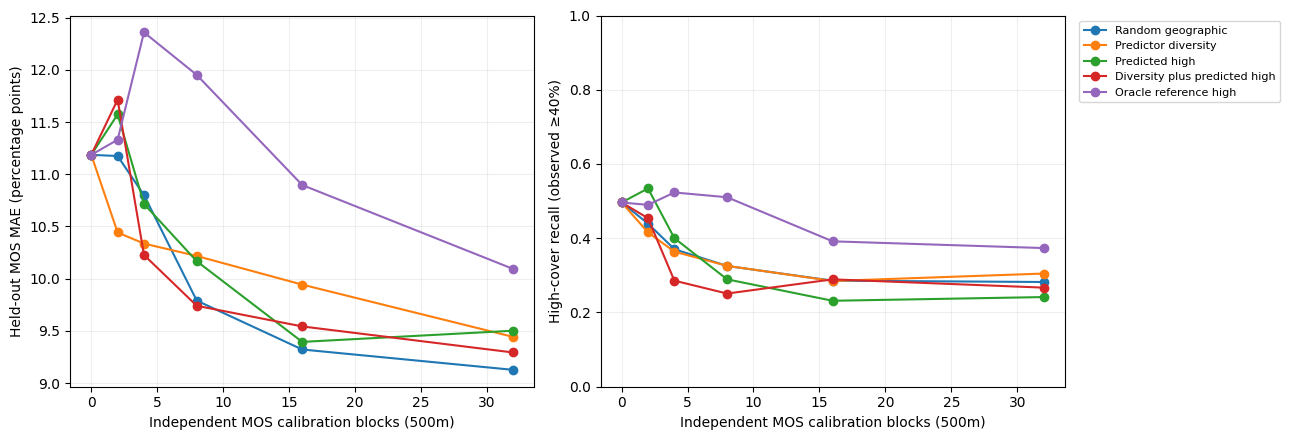

13D COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/13_geographic_representativeness/13D_selection_strategies


In [9]:
# 13D — Compare geographically independent MOS calibration selection strategies.
# No 13A-C rerun required. Source Block13C random fits are reused, not duplicated.
from pathlib import Path
import json,os,hashlib,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
paths13d=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'13_geographic_representativeness/13C_MOS_learning_curve_repeats.csv').exists() for p in paths13d):
 from google.colab import drive
 drive.mount('/content/drive')
roots13d=[p for p in paths13d if (p/'13_geographic_representativeness/13C_MOS_learning_curve_repeats.csv').exists()]
assert len(roots13d)==1,('Run 13A–C and check Drive mount',roots13d)
root13d=roots13d[0];prior13d=root13d/'13_geographic_representativeness'
out13d=prior13d/'13D_selection_strategies';out13d.mkdir(parents=True,exist_ok=True)
d13d=pd.read_parquet(root13d/'frozen_50m_reference.parquet').reset_index(drop=True)
sites13d=['Baego','MOS','Yangambi','Yoko'];keys13d=['site','mosaic','row','col']
assert len(d13d)==14454 and not d13d.duplicated(keys13d).any()
cols13d=[c for c in d13d if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__','EMB_ANNUAL__'))]
assert len(cols13d)==123
X13d=d13d[cols13d].to_numpy(np.float32);y13d=d13d.target_fraction.to_numpy(float)
forest13d=d13d.site.to_numpy();xy13d=d13d[['x','y']].to_numpy(float)
assert np.isfinite(X13d).all() and np.isfinite(xy13d).all() and np.isfinite(y13d).all()
base13d=pd.read_parquet(root13d/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet')
assert len(base13d)==len(d13d) and all(base13d[k].equals(d13d[k]) for k in keys13d)
pbase13d=base13d.pred_baseline.to_numpy(float)
assert np.isfinite(pbase13d).all()
prevconfig13d=json.loads((prior13d/'config.json').read_text())
assert prevconfig13d['block_m']==500 and prevconfig13d['buffer_m']==150 and prevconfig13d['repeats']==3
seed13d=prevconfig13d['seed'];CAP13d=prevconfig13d['cap'];MEM13d=prevconfig13d['members']
PARAM13d=prevconfig13d['model']
assert CAP13d==1500 and MEM13d==3
block13d=500;buffer13d=150;budgets13d=[0,2,4,8,16,32]
strategies13d=['Random_geographic','Predictor_diversity','Predicted_high',
               'Diversity_plus_predicted_high','Oracle_reference_high']
work13d={'version':'13D_v1','source_fingerprint':prevconfig13d['fingerprint'],
 'seed':seed13d,'budgets':budgets13d,'strategies':strategies13d,
 'per_block_cells':20,'maximum_local_cells':500,'members':MEM13d,
 'domain_pca':15,'block_pca':12}
cfg13d=out13d/'config.json'
if cfg13d.exists():assert json.loads(cfg13d.read_text())==work13d,'13D cache incompatible'
else:cfg13d.write_text(json.dumps(work13d,indent=2))
# Same 500 m block IDs and exact prior 13A test partitions.
blockkeys13d=np.array([f'{s}:{int(np.floor(x/500))}:{int(np.floor(y/500))}'
 for s,(x,y) in zip(forest13d,xy13d)])
manifest13d=pd.read_parquet(prior13d/'13A_splits.parquet')
def archived_split13d(rep):
 mm=manifest13d[manifest13d.repeat==rep]
 train=mm.loc[mm.role=='train','index'].to_numpy(int)
 test=mm.loc[mm.role=='test','index'].to_numpy(int)
 assert not np.intersect1d(train,test).size
 assert len(np.unique(train))==len(train) and len(np.unique(test))==len(test)
 assert np.all(cKDTree(xy13d[test]).query(xy13d[train],workers=-1)[0]>=buffer13d-1e-7)
 return np.sort(train),np.sort(test)
def draw13d(pool,seed):
 # Exact 13C train-only, forest-balanced / abundance-stratified donor draw.
 rng=np.random.default_rng(seed);result=[]
 for site in sites13d:
  ix=pool[forest13d[pool]==site]
  if not len(ix):continue
  cap=min(CAP13d,len(ix))
  if len(ix)<=cap:result.extend(ix.tolist());continue
  labels=np.digitize(y13d[ix],[.10,.20,.40])
  bins={k:ix[labels==k] for k in range(4)}
  n=min(len(bins[3]),int(np.ceil(.25*cap)))
  chosen=rng.choice(bins[3],n,replace=False).tolist() if n else []
  bins[3]=np.setdiff1d(bins[3],chosen)
  while len(chosen)<cap:
   active=[k for k in bins if len(bins[k])]
   for k in active:
    n=min(len(bins[k]),max(1,(cap-len(chosen))//len(active)),cap-len(chosen))
    if n:
     take=rng.choice(bins[k],n,replace=False)
     chosen.extend(take.tolist());bins[k]=np.setdiff1d(bins[k],take)
    if len(chosen)==cap:break
  result.extend(chosen)
 return np.array(sorted(result),dtype=int)
def model13d(test,local,rep):
 external=np.flatnonzero(forest13d!='MOS')
 votes=[]
 for member in range(MEM13d):
  sample=draw13d(external,seed13d+rep*1000+107*member)
  if len(local):sample=np.concatenate([sample,local])
  estimator=HistGradientBoostingRegressor(**PARAM13d,random_state=seed13d+member)
  estimator.fit(X13d[sample],y13d[sample])
  votes.append(np.clip(estimator.predict(X13d[test]),0,1))
 return np.mean(votes,axis=0)
def metrics13d(obs,pred):
 e=pred-obs;high=obs>=.40;called=pred>=.40
 return {'n':int(len(obs)),'MAE_pp':100*float(np.abs(e).mean()),
  'RMSE_pp':100*float(np.sqrt(np.mean(e*e))),
  'bias_pp':100*float(e.mean()),'high40_n':int(high.sum()),
  'high40_bias_pp':100*float(e[high].mean()) if high.any() else np.nan,
  'high40_recall':float(np.mean(called[high])) if high.any() else np.nan,
  'high40_precision':float(np.mean(high[called])) if called.any() else np.nan}
# Fit PCA using non-MOS donor predictor information only (never MOS targets).
donor13d=np.flatnonzero(forest13d!='MOS')
r13d=np.random.default_rng(seed13d+77)
sample13d=np.concatenate([r13d.choice(donor13d[forest13d[donor13d]==s],
 min(1000,int(np.sum(forest13d[donor13d]==s))),replace=False)
 for s in sites13d if s!='MOS'])
scaler13d=RobustScaler(quantile_range=(10,90)).fit(X13d[sample13d])
scaled13d=np.clip(scaler13d.transform(X13d[sample13d]),-10,10)
pca13d=PCA(n_components=15,random_state=seed13d).fit(scaled13d)
donorz13d=pca13d.transform(scaled13d)
mos13d=np.flatnonzero(forest13d=='MOS')
mosz13d=pca13d.transform(np.clip(scaler13d.transform(X13d[mos13d]),-10,10))
# Unlabeled novelty scores relative to donor training; 95th percentile donor internal NN threshold.
within13d=NearestNeighbors(n_neighbors=2).fit(donorz13d).kneighbors(donorz13d)[0][:,1]
threshold13d=float(np.quantile(within13d,.95))
dist13d=NearestNeighbors(n_neighbors=1).fit(donorz13d).kneighbors(mosz13d)[0][:,0]
domain13d=np.full(len(d13d),False)
domain13d[mos13d]=dist13d>threshold13d
z13d=np.zeros((len(d13d),15),dtype=np.float32);z13d[mos13d]=mosz13d.astype(np.float32)
# Original Block13C random block ranking: identical seed and candidates.
def block_data13d(localpool,rep):
 b=np.unique(blockkeys13d[localpool])
 block_ix={k:localpool[blockkeys13d[localpool]==k] for k in b}
 centroid=np.vstack([z13d[block_ix[k]].mean(axis=0) for k in b])
 # Mean highest quintile of *MOS-free* HGB predictions, no MOS labels.
 predscore=np.array([np.mean(np.sort(pbase13d[block_ix[k]])[-max(1,int(np.ceil(.2*len(block_ix[k])))):]) for k in b])
 # Oracle uses labels from candidate calibration areas (never test blocks).
 oracle=np.array([np.mean(y13d[block_ix[k]]>=.4) for k in b])
 return b,block_ix,centroid,predscore,oracle
def normalized13d(arr):
 lo=float(np.quantile(arr,.05));hi=float(np.quantile(arr,.95))
 return np.clip((arr-lo)/max(hi-lo,1e-8),0,1)
def ranked13d(strategy,b,features,predscore,oracle,rep):
 n=len(b);rng=np.random.default_rng(seed13d+13579+rep)
 if strategy=='Random_geographic':
  return rng.permutation(n)
 if strategy=='Predicted_high':
  return np.argsort(-predscore,kind='stable')
 if strategy=='Oracle_reference_high':
  return np.lexsort((rng.random(n),-oracle))
 # Greedy satellite-space cover relative to candidate blocks; no candidate target information.
 v=(features-features.mean(axis=0))/np.maximum(features.std(axis=0),1e-6)
 # Whitened PCA feature coordinates; clip to avoid a single extreme outlier.
 v=np.clip(v,-4,4)
 distance=np.linalg.norm(v,axis=1)
 start=int(np.argmax(distance))
 selected=[];minimum=np.full(n,np.inf);rawpred=normalized13d(predscore)
 for i in range(n):
  if i==0:
   choice=start if strategy=='Predictor_diversity' else int(np.argmax(.5*normalized13d(distance)+.5*rawpred))
  else:
   ds=normalized13d(minimum)
   score=ds if strategy=='Predictor_diversity' else .5*ds+.5*rawpred
   score[selected]=-np.inf
   choice=int(np.argmax(score))
  selected.append(choice)
  minimum=np.minimum(minimum,np.linalg.norm(v-v[choice],axis=1))
 return np.array(selected,int)
def sampled_cells13d(indices,blocks,block_ix,rep):
 selected=[]
 for rank,k in enumerate(blocks):
  ix=block_ix[k];rng=np.random.default_rng(seed13d+rep*10000+rank)
  selected.extend(rng.choice(ix,min(20,len(ix)),replace=False).tolist())
 return np.asarray(selected[:500],dtype=int)
# Read all archived 13C random predictions; zero baseline is shared across strategies.
selection_rows13d=[];scores13d=[];paired13d=[]
print('13D START: strategies=',strategies13d,'budgets=',budgets13d,flush=True)
for rep13d in range(3):
 train13d,testall13d=archived_split13d(rep13d)
 test13d=testall13d[forest13d[testall13d]=='MOS']
 pool13d=train13d[forest13d[train13d]=='MOS']
 assert len(test13d)>100 and len(pool13d)>100
 b13d,bix13d,cent13d,predscore13d,oracle13d=block_data13d(pool13d,rep13d)
 print('13D repetition',rep13d+1,'candidate blocks',len(b13d),'MOS test cells',len(test13d),flush=True)
 ranks13d={s:ranked13d(s,b13d,cent13d,predscore13d,oracle13d,rep13d) for s in strategies13d}
 for strategy13d in strategies13d:
  order13d=ranks13d[strategy13d]
  for budget13d in budgets13d:
   blockselection13d=b13d[order13d[:min(budget13d,len(order13d))]]
   # For the archived random baseline, preserve EXACT same sampled cells from original 13C.
   if strategy13d=='Random_geographic' or budget13d==0:
    archived13d=prior13d/f'13C_repeat{rep13d}_blocks{budget13d}.npz'
   else:archived13d=None
   if archived13d is not None and not archived13d.exists():
    raise FileNotFoundError(f'Archived original 13C prediction required: {archived13d}')
   if archived13d is not None:
    with np.load(archived13d) as zz:
     assert np.array_equal(zz['test'],test13d)
     loc13d=zz['local'].astype(int);prediction13d=zz['pred'].astype(float)
    if strategy13d=='Random_geographic' and budget13d:
     expected13d=np.random.default_rng(seed13d+13579+rep13d).permutation(b13d)[:budget13d]
     assert set(blockselection13d)==set(expected13d)
   else:
    loc13d=sampled_cells13d(None,blockselection13d,bix13d,rep13d)
    assert len(loc13d)<=500
    dest13d=out13d/f'13D_r{rep13d}_{strategy13d}_b{budget13d}.npz'
    if dest13d.exists():
     with np.load(dest13d) as zz:
      assert np.array_equal(zz['test'],test13d) and np.array_equal(zz['local'],loc13d)
      prediction13d=zz['pred'].astype(float)
     print('13D REUSE',rep13d,strategy13d,budget13d,flush=True)
    else:
     t13d=time.monotonic();prediction13d=model13d(test13d,loc13d,rep13d)
     with dest13d.with_suffix('.partial').open('wb') as fh:
      np.savez_compressed(fh,test=test13d,local=loc13d,pred=prediction13d)
     os.replace(dest13d.with_suffix('.partial'),dest13d)
     print(f'13D DONE rep={rep13d} strategy={strategy13d} blocks={budget13d} local={len(loc13d)} time={time.monotonic()-t13d:.1f}s',flush=True)
   assert np.all(forest13d[loc13d]=='MOS')
   assert not np.intersect1d(loc13d,test13d).size
   if len(loc13d):
    assert cKDTree(xy13d[test13d]).query(xy13d[loc13d],workers=-1)[0].min()>=buffer13d-1e-7
   for rank13d,k13d in enumerate(blockselection13d):
    cells=bix13d[k13d]
    selection_rows13d.append(dict(repeat=rep13d,strategy=strategy13d,budget=budget13d,
      selected_rank=rank13d+1,block_id=k13d,
      block_n=len(cells),block_observed_high40_share=float(np.mean(y13d[cells]>=.4)),
      block_predicted_high_score=float(predscore13d[np.where(b13d==k13d)[0][0]])))
   general13d=metrics13d(y13d[test13d],prediction13d)
   for domainlabel,mask in [('All',np.ones(len(test13d),bool)),
                             ('Inside_donor',~domain13d[test13d]),
                             ('Outside_donor',domain13d[test13d])]:
    if not np.any(mask):continue
    scores13d.append(dict(repeat=rep13d,strategy=strategy13d,budget_blocks=budget13d,
       used_blocks=len(blockselection13d),local_cells=len(loc13d),domain=domainlabel,
       **metrics13d(y13d[test13d][mask],prediction13d[mask])))
   paired13d.extend(dict(repeat=rep13d,strategy=strategy13d,budget_blocks=budget13d,
                         row_id=int(i),observed=float(y13d[i]),predicted=float(p),
                         outside_domain=bool(domain13d[i]))
                  for i,p in zip(test13d,prediction13d))
pd.DataFrame(selection_rows13d).to_csv(out13d/'13D_block_selection_audit.csv',index=False)
scoreframe13d=pd.DataFrame(scores13d)
scoreframe13d.to_csv(out13d/'13D_repeated_metrics.csv',index=False)
pd.DataFrame(paired13d).to_parquet(out13d/'13D_paired_predictions.parquet',index=False)
overall13d=scoreframe13d[scoreframe13d.domain=='All']
summary13d=overall13d.groupby(['strategy','budget_blocks'],as_index=False).agg(
 n_local=('local_cells','mean'),MAE_pp=('MAE_pp','mean'),MAE_sd=('MAE_pp','std'),
 high40_bias_pp=('high40_bias_pp','mean'),high40_recall=('high40_recall','mean'),
 high40_precision=('high40_precision','mean'))
summary13d.to_csv(out13d/'13D_strategy_summary.csv',index=False)
print('\n13D MOS STRATEGY SUMMARY (3 repeated fixed geographic test splits)',flush=True)
display(summary13d.round(3))
print('\n13D INSIDE/OUTSIDE DONOR DOMAIN',flush=True)
display(scoreframe13d[scoreframe13d.budget_blocks==16].groupby(
 ['strategy','domain'],as_index=False)[['MAE_pp','high40_bias_pp','high40_recall']].mean().round(3))
fig13d,axs13d=plt.subplots(1,2,figsize=(13,4.5))
for strategy in strategies13d:
 t=summary13d[summary13d.strategy==strategy].sort_values('budget_blocks')
 label=strategy.replace('_',' ')
 axs13d[0].plot(t.budget_blocks,t.MAE_pp,marker='o',label=label)
 axs13d[1].plot(t.budget_blocks,t.high40_recall,marker='o',label=label)
axs13d[0].set(xlabel='Independent MOS calibration blocks (500m)',
               ylabel='Held-out MOS MAE (percentage points)')
axs13d[1].set(xlabel='Independent MOS calibration blocks (500m)',
               ylabel='High-cover recall (observed ≥40%)',ylim=(0,1))
for ax in axs13d:ax.grid(alpha=.2)
axs13d[1].legend(fontsize=8,bbox_to_anchor=(1.02,1),loc='upper left')
fig13d.tight_layout();fig13d.savefig(out13d/'13D_sampling_strategy_curves.png',dpi=170,bbox_inches='tight');plt.show()
print('13D COMPLETE:',out13d,flush=True)


## 13E — Does training-abundance representation explain MOS high-cover underprediction?

**13E.1 — Retrospective sampling audit (cached only).** Recover the **exact calibration cell indices** from the cached Block 13C random and Block 13D selection-strategy prediction files, at budgets 0/2/4/8/16/32 geographic blocks across three fixed MOS test partitions. Quantify observed ≥40% and ≥60% cell shares and counts, calibration mean cover, and the share of test high-cover samples lying outside the donor predictor domain. This distinguishes selecting high-cover *blocks* from actually adding high-cover *cells* to the training set. Observed calibration abundance is inspected **after selection**; no test labels enter sampling.

**13E.2 — One controlled HGB abundance-weight experiment at 16 calibration blocks.** Compare two previously selected strategies (**random geographic**, **oracle reference-high**, where the oracle is deliberately non-deployable). Hold **every training and test cell fixed**, the original donor-balanced training draw, HGB architecture/hyperparameters, all three test partitions and three ensemble seeds. Reuse existing Block 13C/13D uniform-weight predictions and fit just **one predeclared alternative**: multiply the regression weight of locally calibrated MOS reference cells with observed Musanga cover ≥40% by **2×** (all other samples weight 1). This is deliberately modest, not a parameter search. Both models are scored on **exactly matched held-out MOS 50 m cells**, reporting MAE, RMSE, bias, high-cover bias, recall, precision and split-to-split variability; compare inside and outside donor predictor domain.

This identifies whether the 13D tradeoff can be shifted with the *same calibration sample*. It does not demonstrate independent dense UAV-label accuracy, and the oracle is an upper-bound thought experiment, not a practical acquisition policy. Metrics are descriptive across three geographical partitions; do **not** tune the 2× weight based on their performance.

**Run 13E standalone** in Colab after Drive is mounted. Inputs: frozen reference + completed 13A, 13C, 13D caches. No new satellite extraction or repeat of earlier fits. CPU sufficient. Saves cell-level audits, paired held-out predictions, repeat metrics, summary tables and plots in `13_geographic_representativeness/13E_abundance_weighting/`. Training outputs are resumable per repeat/strategy.

13E.1 — EXACT CELL-LEVEL CALIBRATION COMPOSITION (16 blocks):


,strategy,cells,high40_n,high40_share,high60_n,mean_cover_pct
0,Diversity_plus_predicted_high,318.667,83.667,0.263,21.667,29.489
1,Oracle_reference_high,316.667,114.333,0.361,29.000,34.046
2,Predicted_high,320.000,84.333,0.264,25.333,29.509
3,Predictor_diversity,302.667,45.000,0.149,5.333,21.674
4,Random_geographic,317.667,36.333,0.115,9.667,19.130


/tmp/ipykernel_997/1981670533.py:136: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  outside13e=m13e.outside_domain.fillna(False).to_numpy(bool)


13E FIT rep=0 strategy=Random_geographic, 315 local, time=4.7s
13E FIT rep=0 strategy=Oracle_reference_high, 320 local, time=4.7s
13E FIT rep=1 strategy=Random_geographic, 318 local, time=4.8s
13E FIT rep=1 strategy=Oracle_reference_high, 320 local, time=4.8s
13E FIT rep=2 strategy=Random_geographic, 320 local, time=4.7s
13E FIT rep=2 strategy=Oracle_reference_high, 310 local, time=4.7s

13E.2 MATCHED MOS WEIGHT COMPARISON (16 geographic calibration blocks)


,strategy,weighting,MAE_pp,MAE_sd,high40_bias_pp,high40_recall,high40_precision,high60_bias_pp
0,Oracle_reference_high,Local_high40_2x,11.074,0.528,-13.008,0.438,0.376,-21.196
1,Oracle_reference_high,Uniform_archived,10.896,0.601,-13.842,0.392,0.396,-22.350
2,Random_geographic,Local_high40_2x,9.436,0.765,-18.936,0.308,0.583,-26.488
3,Random_geographic,Uniform_archived,9.321,0.771,-19.651,0.286,0.618,-27.141



13E INSIDE/OUTSIDE-DOMAIN PERFORMANCE


,strategy,weighting,domain,MAE_pp,high40_bias_pp,high40_recall
0,Oracle_reference_high,Local_high40_2x,Inside_donor,6.527,-11.607,0.570
1,Oracle_reference_high,Local_high40_2x,Outside_donor,13.117,-13.313,0.409
2,Oracle_reference_high,Uniform_archived,Inside_donor,6.515,-12.153,0.502
3,Oracle_reference_high,Uniform_archived,Outside_donor,12.849,-14.211,0.367
4,Random_geographic,Local_high40_2x,Inside_donor,6.097,-13.582,0.492
5,Random_geographic,Local_high40_2x,Outside_donor,10.964,-20.068,0.270
6,Random_geographic,Uniform_archived,Inside_donor,6.030,-14.863,0.447
7,Random_geographic,Uniform_archived,Outside_donor,10.819,-20.667,0.252



13E WEIGHTED MINUS UNWEIGHTED CHANGES (paired by test split)


,strategy,delta_MAE_pp,delta_high40_bias_pp,delta_high40_recall,delta_high40_precision
0,Oracle_reference_high,0.177,0.834,0.047,-0.020
1,Random_geographic,0.115,0.715,0.023,-0.035


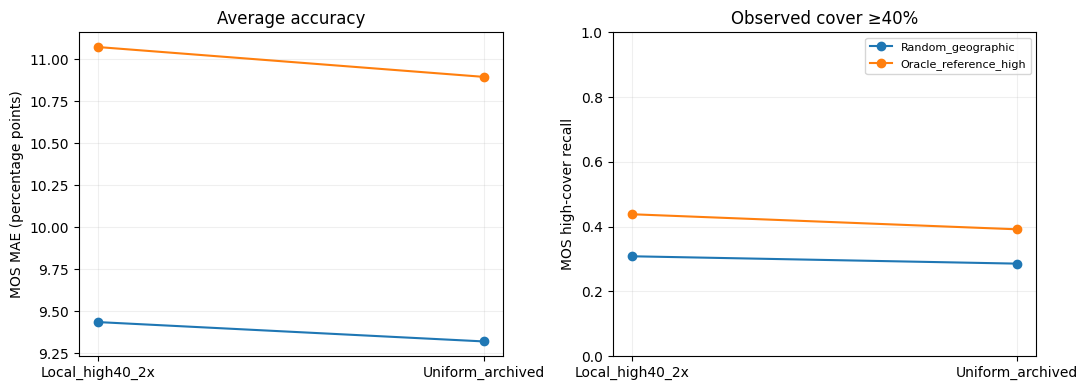

BLOCK 13E COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/13_geographic_representativeness/13E_abundance_weighting


In [10]:
# 13E: retrospective sample-abundance audit + ONE predetermined 2x high-local weight test.
# Standalone; reuses 13C/13D uniform-weight prediction files; no EE or CNN.
import os,json,time,hashlib
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
candidates13e=[
 Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
 Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
if not any((p/'13_geographic_representativeness/13D_selection_strategies/13D_strategy_summary.csv').is_file() for p in candidates13e):
 from google.colab import drive
 drive.mount('/content/drive')
roots13e=[p for p in candidates13e if
 (p/'13_geographic_representativeness/13D_selection_strategies/13D_strategy_summary.csv').is_file()]
assert len(roots13e)==1,('Complete Block 13D and mount Drive first',roots13e)
root13e=roots13e[0];parent13e=root13e/'13_geographic_representativeness'
dir13d=parent13e/'13D_selection_strategies'
out13e=parent13e/'13E_abundance_weighting';out13e.mkdir(parents=True,exist_ok=True)
d13e=pd.read_parquet(root13e/'frozen_50m_reference.parquet').reset_index(drop=True)
keys13e=['site','mosaic','row','col'];sites13e=['Baego','MOS','Yangambi','Yoko']
assert len(d13e)==14454 and not d13e.duplicated(keys13e).any()
features13e=[c for c in d13e if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__','EMB_ANNUAL__'))]
assert len(features13e)==123,len(features13e)
X13e=d13e[features13e].to_numpy(np.float32);y13e=d13e.target_fraction.to_numpy(float)
forest13e=d13e.site.to_numpy();xy13e=d13e[['x','y']].to_numpy(float)
assert np.isfinite(X13e).all() and np.isfinite(y13e).all() and np.isfinite(xy13e).all()
baseconfig13e=json.loads((parent13e/'config.json').read_text())
cfg13d=json.loads((dir13d/'config.json').read_text())
assert baseconfig13e['repeats']==3 and baseconfig13e['block_m']==500 and baseconfig13e['buffer_m']==150
assert cfg13d['source_fingerprint']==baseconfig13e['fingerprint']
seed13e=baseconfig13e['seed'];cap13e=baseconfig13e['cap'];members13e=baseconfig13e['members']
assert cap13e==1500 and members13e==3
params13e=baseconfig13e['model']
strategies13e=cfg13d['strategies'];budgets13e=cfg13d['budgets']
assert 16 in budgets13e and 0 in budgets13e
config13e=dict(version='13E_fixed_weight_2x_v1',base_fingerprint=baseconfig13e['fingerprint'],
 high_threshold=.4,weight_local_high=2.,budget_blocks=16,repeats=3,
 strategies_fit=['Random_geographic','Oracle_reference_high'],members=members13e,
 seed=seed13e)
cp13e=out13e/'config.json'
if cp13e.is_file():assert json.loads(cp13e.read_text())==config13e,'Cached 13E config mismatch'
else:cp13e.write_text(json.dumps(config13e,indent=2))
split13e=pd.read_parquet(parent13e/'13A_splits.parquet')
def indices13e(rep):
 a=split13e[split13e.repeat==rep]
 train=np.sort(a.loc[a.role=='train','index'].to_numpy(int))
 test=np.sort(a.loc[a.role=='test','index'].to_numpy(int))
 assert len(np.unique(train))==len(train) and len(np.unique(test))==len(test)
 assert len(np.intersect1d(train,test))==0
 return train,test[test.astype(int)>=0][forest13e[test]=='MOS']
def cache13e(rep,strategy,budget):
 if budget==0 or strategy=='Random_geographic':
  return parent13e/f'13C_repeat{rep}_blocks{budget}.npz'
 return dir13d/f'13D_r{rep}_{strategy}_b{budget}.npz'
def load13e(rep,strategy,budget,test):
 f=cache13e(rep,strategy,budget)
 assert f.is_file(),('Missing archived calibration fit',f)
 with np.load(f,allow_pickle=False) as z:
  assert np.array_equal(z['test'],test),('Held-out cohort mismatch',f)
  local=z['local'].astype(int).copy()
  p=z['pred'].astype(float).copy()
 assert len(local)==len(np.unique(local))
 assert np.all(forest13e[local]=='MOS') and not np.intersect1d(local,test).size
 return local,p
def donor_draw13e(pool,seed):
 # Exact 13C and 13D stratified draw, no held-out MOS samples.
 rng=np.random.default_rng(seed);selected=[]
 for site in sites13e:
  ix=pool[forest13e[pool]==site]
  if not len(ix):continue
  cap=min(cap13e,len(ix))
  if len(ix)<=cap:selected.extend(ix.tolist());continue
  labels=np.digitize(y13e[ix],[.10,.20,.40])
  bins={k:ix[labels==k] for k in range(4)}
  n=min(len(bins[3]),int(np.ceil(cap*.25)))
  picked=rng.choice(bins[3],n,replace=False).tolist() if n else []
  bins[3]=np.setdiff1d(bins[3],picked)
  while len(picked)<cap:
   active=[k for k in bins if len(bins[k])]
   assert active
   for k in active:
    n=min(len(bins[k]),max(1,(cap-len(picked))//len(active)),cap-len(picked))
    if n:
     take=rng.choice(bins[k],n,replace=False)
     picked.extend(take.tolist());bins[k]=np.setdiff1d(bins[k],take)
    if len(picked)==cap:break
  selected.extend(picked)
 return np.array(sorted(selected),dtype=int)
def metrics13e(obs,pred):
 err=pred-obs;high=obs>=.4;vhigh=obs>=.6;called=pred>=.4
 return dict(n=int(len(obs)),MAE_pp=float(100*np.mean(abs(err))),
   RMSE_pp=float(100*np.sqrt(np.mean(err**2))),bias_pp=float(100*np.mean(err)),
   high40_n=int(high.sum()),high40_bias_pp=float(100*np.mean(err[high])) if high.any() else np.nan,
   high40_recall=float(np.mean(called[high])) if high.any() else np.nan,
   high40_precision=float(np.mean(high[called])) if called.any() else np.nan,
   high60_n=int(vhigh.sum()),high60_bias_pp=float(100*np.mean(err[vhigh])) if vhigh.any() else np.nan)
# 13E.1 FULL AUDIT — evaluate composition of ACTUALLY selected reference CELLS, not mean of block labels.
audits13e=[];audit_cells13e=[]
for rep in range(3):
 tr,test=indices13e(rep)
 for strategy in strategies13e:
  for budget in budgets13e:
   local,p=load13e(rep,strategy,budget,test)
   if len(local):
    assert cKDTree(xy13e[test]).query(xy13e[local],workers=-1)[0].min()>=150-1e-7
   audits13e.append(dict(repeat=rep,strategy=strategy,budget_blocks=budget,n_calibration=len(local),
     n_geographic_blocks=int(len(np.unique([
       (int(np.floor(x/500)),int(np.floor(y/500))) for x,y in xy13e[local]
      ],axis=0))) if len(local) else 0,
     actual_high40_n=int((y13e[local]>=.4).sum()),
     actual_high40_share=float(np.mean(y13e[local]>=.4)) if len(local) else np.nan,
     actual_high60_n=int((y13e[local]>=.6).sum()),
     actual_high60_share=float(np.mean(y13e[local]>=.6)) if len(local) else np.nan,
     mean_local_cover_pct=float(100*np.mean(y13e[local])) if len(local) else np.nan))
   audit_cells13e.extend(dict(repeat=rep,strategy=strategy,budget_blocks=budget,
     row_id=int(i),target_fraction=float(y13e[i])) for i in local)
audit13e=pd.DataFrame(audits13e)
audit13e.to_csv(out13e/'13E_actual_calibration_abundance.csv',index=False)
pd.DataFrame(audit_cells13e).to_parquet(out13e/'13E_selected_calibration_cells.parquet',index=False)
print('13E.1 — EXACT CELL-LEVEL CALIBRATION COMPOSITION (16 blocks):',flush=True)
display(audit13e[audit13e.budget_blocks==16].groupby('strategy',as_index=False).agg(
 cells=('n_calibration','mean'),high40_n=('actual_high40_n','mean'),
 high40_share=('actual_high40_share','mean'),high60_n=('actual_high60_n','mean'),
 mean_cover_pct=('mean_local_cover_pct','mean')).round(3))
# Pre-existing inside/outside donor domain score; no fitting to held-out MOS targets.
novelfile13e=parent13e/'13B_MOS_domain_distances.parquet'
novel13e=pd.read_parquet(novelfile13e)
assert not novel13e.duplicated(keys13e).any()
m13e=d13e[keys13e].merge(novel13e[keys13e+['outside_domain']],
 on=keys13e,how='left',sort=False,validate='one_to_one')
assert m13e.loc[forest13e=='MOS','outside_domain'].notna().all()
outside13e=m13e.outside_domain.fillna(False).to_numpy(bool)
# 13E.2: fixed high-cover weight only among the MOS local calibration cells.
external13e=np.flatnonzero(forest13e!='MOS')
fits13e=[];paired13e=[]
for rep in range(3):
 tr,test=indices13e(rep)
 for strategy in config13e['strategies_fit']:
  local,uniform=load13e(rep,strategy,16,test)
  cache=out13e/f'13E_r{rep}_{strategy}_highLocal2x.npz'
  if cache.exists():
   with np.load(cache,allow_pickle=False) as z:
    assert np.array_equal(z['test'],test) and np.array_equal(z['local'],local)
    weighted=z['pred'].astype(float)
   print('13E REUSE',rep,strategy,flush=True)
  else:
   member_predictions=[];start=time.monotonic()
   for member in range(members13e):
    selected=donor_draw13e(external13e,seed13e+rep*1000+107*member)
    full=np.concatenate([selected,local])
    weights=np.ones(len(full),np.float64)
    weights[len(selected):]=np.where(y13e[local]>=.4,2.,1.)
    assert (weights>0).all()
    model=HistGradientBoostingRegressor(**params13e,random_state=seed13e+member)
    model.fit(X13e[full],y13e[full],sample_weight=weights)
    member_predictions.append(np.clip(model.predict(X13e[test]),0,1))
   weighted=np.mean(member_predictions,axis=0)
   with cache.with_suffix('.partial').open('wb') as fh:
    np.savez_compressed(fh,test=test,local=local,pred=weighted,
                        member_predictions=np.stack(member_predictions).astype('float32'))
   os.replace(cache.with_suffix('.partial'),cache)
   print(f'13E FIT rep={rep} strategy={strategy}, {len(local)} local, time={time.monotonic()-start:.1f}s',flush=True)
  for modelname,pred in [('Uniform_archived',uniform),('Local_high40_2x',weighted)]:
   for domain,mask in [('All',np.ones(len(test),bool)),('Inside_donor',~outside13e[test]),
                       ('Outside_donor',outside13e[test])]:
    if not mask.any():continue
    fits13e.append(dict(repeat=rep,strategy=strategy,weighting=modelname,domain=domain,
      local_cells=len(local),local_high40=int((y13e[local]>=.4).sum()),
      **metrics13e(y13e[test][mask],pred[mask])))
   paired13e.extend(dict(repeat=rep,strategy=strategy,weighting=modelname,
        row_id=int(i),reference=float(y13e[i]),predicted=float(v),
        outside_domain=bool(outside13e[i])) for i,v in zip(test,pred))
fitframe13e=pd.DataFrame(fits13e)
fitframe13e.to_csv(out13e/'13E_weighting_repeats.csv',index=False)
pd.DataFrame(paired13e).to_parquet(out13e/'13E_weighting_paired_predictions.parquet',index=False)
summary13e=fitframe13e[fitframe13e.domain=='All'].groupby(
 ['strategy','weighting'],as_index=False).agg(MAE_pp=('MAE_pp','mean'),
 MAE_sd=('MAE_pp','std'),high40_bias_pp=('high40_bias_pp','mean'),
 high40_recall=('high40_recall','mean'),high40_precision=('high40_precision','mean'),
 high60_bias_pp=('high60_bias_pp','mean'))
summary13e.to_csv(out13e/'13E_weighting_summary.csv',index=False)
print('\n13E.2 MATCHED MOS WEIGHT COMPARISON (16 geographic calibration blocks)',flush=True)
display(summary13e.round(3))
print('\n13E INSIDE/OUTSIDE-DOMAIN PERFORMANCE',flush=True)
display(fitframe13e[fitframe13e.domain!='All'].groupby(
 ['strategy','weighting','domain'],as_index=False)[['MAE_pp','high40_bias_pp','high40_recall']].mean().round(3))
# Paired repeat-level difference to avoid pooling correlated 50m cells as independent replicates.
deltas13e=[]
for strategy in config13e['strategies_fit']:
 for rep in range(3):
  rows=fitframe13e[(fitframe13e.strategy==strategy)&(fitframe13e.repeat==rep)&(fitframe13e.domain=='All')]
  un=rows[rows.weighting=='Uniform_archived'].iloc[0]
  ww=rows[rows.weighting=='Local_high40_2x'].iloc[0]
  deltas13e.append(dict(strategy=strategy,repeat=rep,
    delta_MAE_pp=ww.MAE_pp-un.MAE_pp,
    delta_high40_bias_pp=ww.high40_bias_pp-un.high40_bias_pp,
    delta_high40_recall=ww.high40_recall-un.high40_recall,
    delta_high40_precision=ww.high40_precision-un.high40_precision))
deltas13e=pd.DataFrame(deltas13e)
deltas13e.to_csv(out13e/'13E_paired_repeat_deltas.csv',index=False)
print('\n13E WEIGHTED MINUS UNWEIGHTED CHANGES (paired by test split)',flush=True)
display(deltas13e.groupby('strategy',as_index=False).mean(numeric_only=True).drop(columns=['repeat']).round(3))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for strategy in config13e['strategies_fit']:
 grp=summary13e[summary13e.strategy==strategy]
 axs[0].plot(grp.weighting,grp.MAE_pp,marker='o',label=strategy)
 axs[1].plot(grp.weighting,grp.high40_recall,marker='o',label=strategy)
axs[0].set(ylabel='MOS MAE (percentage points)',title='Average accuracy')
axs[1].set(ylabel='MOS high-cover recall',title='Observed cover ≥40%',ylim=(0,1))
axs[1].legend(fontsize=8)
for ax in axs:ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(out13e/'13E_weighting_results.png',dpi=170);plt.show()
print('BLOCK 13E COMPLETE:',out13e,flush=True)


## 14 — GEDI synthesis using **existing Blocks 06–08** (no re-extraction)

The GEDI coverage map (06A/B), tree-height screen (07A), GEDI L2A RH98/RH50 matching (08A), and L2B canopy-cover / PAI / FHD / PAVD analysis (08B) **have already been done**. Block 14 only consolidates cached outputs against frozen HGB-LOFO 50 m predictions and the MOS predictor-domain novelty flag (13B). It does **not** call Earth Engine, extract imagery, or fit another unpaired exploratory correlation.

**14A — Exact matched-cohort audit:** join by `site,mosaic,row,col`, verify reference values and source masks, count available GEDI L2A and L2B reference cells by forest, inspect target-abundance selection bias, quantify the relationship of structural features with signed/absolute *held-out* satellite errors and with MOS inside/outside-domain status. Plots are descriptive; no causal interpretation.

**14B — Conditional fair GEDI test:** only if **at least three forests have ≥30 quality-matched L2B cells** and adequate variation, compare a compact HGB model with `annual + quarterly S2 + 64 embedding` versus the same HGB plus cached GEDI structure on exactly the *same* GEDI-matched 50 m cells under strict leave-one-forest-out. Training/normalization and any missing-value treatment remain inside donor forests. Compare the **retrained matched-subset satellite baseline**, not the full-data HGB directly, to isolate the added information. Report full-data frozen HGB performance on the same support as a separate context benchmark. If sparse, print a clear unsupported-result notice and only perform 14A.

**Scientific limits:** GEDI monthly raster-grid locations are **not exact shot footprints**; L2A and L2B raster observations may not be simultaneous; GEDI/UAV observation dates and full-shot QA have not been reconciled; and a GEDI-assisted model is only applicable at GEDI-matched cells without a wall-to-wall structural predictor. Treat any improvement as exploratory, not operational evidence for regional wall-to-wall mapping.

**Run Block 14 standalone** after mounting Drive and completing 08A, 08B, 09 and 13B. Outputs in `CLEAN_NB06/14_GEDI_cached_synthesis/`. All original GEDI outputs remain unchanged.

In [11]:
# BLOCK 14 — GEDI cached-only synthesis.  No Earth Engine.
from pathlib import Path
import json,os,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
threadpool_limits(1)
options14=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
needed14=lambda root:(root/'08_GEDI_UAV_matching/08A_all_14454_cells.parquet').exists() and (
 root/'08B_GEDI_vertical_structure/08B_all_frozen_cells.parquet').exists()
if not any(needed14(r) for r in options14):
 from google.colab import drive
 drive.mount('/content/drive')
roots14=[r for r in options14 if needed14(r)]
assert len(roots14)==1,('Missing required cached GEDI 08A or 08B outputs; do not re-extract automatically',roots14)
root14=roots14[0];out14=root14/'14_GEDI_cached_synthesis';out14.mkdir(exist_ok=True,parents=True)
keys14=['site','mosaic','row','col'];sites14=['Baego','MOS','Yangambi','Yoko']
ref14=pd.read_parquet(root14/'frozen_50m_reference.parquet').reset_index(drop=True)
assert len(ref14)==14454 and not ref14.duplicated(keys14).any()
pred14=pd.read_parquet(root14/'09_abundance_weighted_LOFO/EXP1_paired_LOFO_predictions.parquet')
assert len(pred14)==len(ref14) and all(ref14[k].equals(pred14[k]) for k in keys14)
t14=ref14[keys14+['target_fraction']].copy()
t14['pred_LOFO']=pred14.pred_baseline.to_numpy(float)
t14['error_pp']=100*(t14.pred_LOFO-t14.target_fraction)
t14['absolute_error_pp']=abs(t14.error_pp)
l2a14=pd.read_parquet(root14/'08_GEDI_UAV_matching/08A_all_14454_cells.parquet')
l2b14=pd.read_parquet(root14/'08B_GEDI_vertical_structure/08B_all_frozen_cells.parquet')
for name,data in [('08A',l2a14),('08B',l2b14)]:
 assert len(data)==len(ref14) and all(data[k].equals(ref14[k]) for k in keys14),(name,'row identity differs')
 assert np.allclose(data.target_fraction.to_numpy(float),ref14.target_fraction.to_numpy(float),equal_nan=True)
feature14=['rh98_m','rh50_m','cover','pai','fhd_normal','pavd_low_0_10',
          'pavd_mid_15_25','pavd_high_30plus','pavd_mid_fraction','pavd_high_fraction']
assert all(c in l2b14.columns for c in feature14)
t14['has_L2A']=l2a14.has_gedi.to_numpy(bool)
t14['has_L2B']=l2b14.has_L2B.to_numpy(bool)
for col in feature14:t14[col]=pd.to_numeric(l2b14[col],errors='coerce').to_numpy(float)
t14['structure_complete']=t14.has_L2B & np.isfinite(t14[feature14].to_numpy(float)).all(axis=1)
novelpath14=root14/'13_geographic_representativeness/13B_MOS_domain_distances.parquet'
assert novelpath14.exists(),'Run 13B MOS predictor-domain audit first.'
novel14=pd.read_parquet(novelpath14)
assert not novel14.duplicated(keys14).any()
t14=t14.merge(novel14[keys14+['outside_domain','domain_distance']],
              on=keys14,how='left',sort=False,validate='one_to_one')
assert t14.loc[t14.site=='MOS','outside_domain'].notna().all()
t14['outside_domain']=t14.outside_domain.astype('boolean')
coverage14=[]
for site in sites14:
 z=t14[t14.site==site]
 for label,mask in [('All',np.ones(len(z),bool)),('L2A',z.has_L2A.to_numpy()),
                    ('L2B',z.has_L2B.to_numpy()),('Complete_L2B',z.structure_complete.to_numpy())]:
  yy=z.target_fraction.to_numpy(float)[mask]
  coverage14.append(dict(site=site,cohort=label,n=int(mask.sum()),
   percent_site=float(100*mask.mean()),mean_abundance_pct=float(100*yy.mean()) if len(yy) else np.nan,
   high40_fraction=float((yy>=.4).mean()) if len(yy) else np.nan,
   MAE_pp=float(z.absolute_error_pp.to_numpy()[mask].mean()) if len(yy) else np.nan))
cov14=pd.DataFrame(coverage14)
cov14.to_csv(out14/'14A_coverage_and_selection_bias.csv',index=False)
print('14A EXACT 50m GEDI MATCHED SUPPORT + SATELLITE ERROR',flush=True)
display(cov14.round(3))
corrrows14=[]
for site,z in [('ALL',t14[t14.structure_complete])]+list(t14[t14.structure_complete].groupby('site')):
 for v in feature14:
  for outcome in ['target_fraction','error_pp','absolute_error_pp']:
   tmp=z[[v,outcome]].replace([np.inf,-np.inf],np.nan).dropna()
   if len(tmp)<12 or tmp[v].std()<1e-8 or tmp[outcome].std()<1e-8:continue
   corrrows14.append(dict(site=site,feature=v,outcome=outcome,n=len(tmp),
      pearson_r=float(tmp[v].corr(tmp[outcome])),
      spearman_r=float(spearmanr(tmp[v],tmp[outcome]).statistic)))
corr14=pd.DataFrame(corrrows14)
corr14.to_csv(out14/'14A_structure_correlations.csv',index=False)
print('14A GEDI relationships with *already held-out* HGB error:',flush=True)
display(corr14[(corr14.outcome=='error_pp')].round(3))
m14=t14[(t14.site=='MOS')&t14.structure_complete].copy()
bydomain14=m14.groupby('outside_domain',dropna=False,observed=True).agg(
 n=('target_fraction','size'),mean_cover=('target_fraction','mean'),
 MAE_pp=('absolute_error_pp','mean'),RH98_m=('rh98_m','mean'),
 PAI=('pai','mean'),FHD=('fhd_normal','mean')).reset_index()
bydomain14['mean_cover']=bydomain14.mean_cover*100
bydomain14.to_csv(out14/'14A_MOS_GEDI_inside_outside_domain.csv',index=False)
print('14A MOS GEDI structure by satellite applicability domain:',flush=True)
display(bydomain14.round(3))
t14.to_parquet(out14/'14A_joined_GEDI_HGB_domain_14454.parquet',index=False)
# 14B: strict LOFO on identical matched support for both fits. Conditional sample-size gate.
available14=t14[t14.structure_complete].copy()
counts14=available14.groupby('site').size().reindex(sites14,fill_value=0)
eligible14=counts14[counts14>=30].index.tolist()
# Restrict comparison to all four forests: fewer than three sites would make LOFO extrapolation uninterpretable.
gate14=len(eligible14)>=3 and len(available14)>=180
print('14B GEDI LOFO candidate counts:',counts14.to_dict(),'eligible forests:',eligible14,flush=True)
if not gate14:
 print('14B NOT RUN: insufficient across-forest GEDI L2B samples for a meaningful held-out comparison.',flush=True)
 print('14A results have been saved. Avoid interpreting in-sample correlations as GEDI prediction skill.')
else:
 from sklearn.impute import SimpleImputer
 sensor14=[c for c in ref14 if c.startswith(('RAW_ANNUAL__','S2_QUARTERLY_3YR__','EMB_ANNUAL__'))]
 assert len(sensor14)==123
 available14=available14[available14.site.isin(eligible14)].copy()
 originalindices14=available14.index.to_numpy(int)
 Xsat14=ref14.loc[originalindices14,sensor14].to_numpy(float)
 Xstr14=available14[feature14].to_numpy(float)
 Y14=available14.target_fraction.to_numpy(float)
 F14=available14.site.to_numpy()
 assert np.isfinite(Xsat14).all() and np.isfinite(Xstr14).all()
 params14=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
               min_samples_leaf=10,l2_regularization=2,early_stopping=False)
 # With small GEDI subset minimum leaf=10 instead of 35; held constant across arms.
 # Equal per-donor-site cap 300; fixed random sampling, no test-target access.
 fitted14=[];paired14=[]
 for held in eligible14:
  test=np.flatnonzero(F14==held)
  train=np.flatnonzero(F14!=held)
  predictions={}
  for tag,XX in [('S2_EMB_on_GEDI_support',Xsat14),
                 ('S2_EMB_plus_GEDI',np.column_stack([Xsat14,Xstr14]))]:
   cache=out14/f'14B_LOFO_{held}_{tag}.npz'
   if cache.exists():
    with np.load(cache) as z:
     assert np.array_equal(z['test'],test)
     pp=z['pred'].astype(float)
    print('14B REUSE',held,tag,flush=True)
   else:
    votes=[]
    for member in range(3):
     rng=np.random.default_rng(20261027+member)
     chosen=[]
     for donor in eligible14:
      if donor==held:continue
      ix=train[F14[train]==donor]
      chosen.extend(rng.choice(ix,min(len(ix),300),replace=False).tolist())
     model=HistGradientBoostingRegressor(**params14,random_state=20261027+member)
     model.fit(XX[chosen],Y14[chosen])
     votes.append(np.clip(model.predict(XX[test]),0,1))
    pp=np.mean(votes,axis=0)
    with cache.with_suffix('.partial').open('wb') as fh:
     np.savez_compressed(fh,test=test,pred=pp)
    os.replace(cache.with_suffix('.partial'),cache)
    print('14B DONE',held,tag,len(test),flush=True)
   predictions[tag]=pp
  predictions['Frozen_full_data_HGB_same_support']=available14.iloc[test].pred_LOFO.to_numpy(float)
  for tag,pp in predictions.items():
   err=pp-Y14[test];high=Y14[test]>=.4
   fitted14.append(dict(model=tag,site=held,n=len(test),
       MAE_pp=float(100*np.mean(abs(err))),MSE=float(np.mean(err*err)),
       bias_pp=float(100*np.mean(err)),
       high40_n=int(high.sum()),
       high40_bias_pp=float(100*np.mean(err[high])) if high.any() else np.nan,
       high40_recall=float(np.mean(pp[high]>=.4)) if high.any() else np.nan))
   paired14.extend(dict(site=held,model=tag,reference=float(yy),predicted=float(pred))
                   for yy,pred in zip(Y14[test],pp))
 score14=pd.DataFrame(fitted14);score14.to_csv(out14/'14B_matched_LOFO_per_forest.csv',index=False)
 pd.DataFrame(paired14).to_parquet(out14/'14B_matched_LOFO_predictions.parquet',index=False)
 print('14B MATCHED-COVERAGE FOREST HOLDOUT (GEDI subset only):',flush=True)
 display(score14.round(3))
 print('Caution: sparse selective GEDI support; no wall-to-wall extrapolation demonstrated.')
print('BLOCK 14 COMPLETE:',out14,flush=True)


14A EXACT 50m GEDI MATCHED SUPPORT + SATELLITE ERROR


,site,cohort,n,percent_site,mean_abundance_pct,high40_fraction,MAE_pp
0,Baego,All,480,100.000,17.240,0.119,6.807
1,Baego,L2A,46,9.583,25.794,0.261,8.472
2,Baego,L2B,46,9.583,25.794,0.261,8.472
3,Baego,Complete_L2B,46,9.583,25.794,0.261,8.472
4,MOS,All,11494,100.000,20.000,0.126,11.010
5,MOS,L2A,1021,8.883,19.911,0.133,10.809
6,MOS,L2B,1021,8.883,19.911,0.133,10.809
7,MOS,Complete_L2B,1021,8.883,19.911,0.133,10.809
8,Yangambi,All,1383,100.000,4.760,0.000,3.147
9,Yangambi,L2A,101,7.303,4.785,0.000,3.117


14A GEDI relationships with *already held-out* HGB error:


,site,feature,outcome,n,pearson_r,spearman_r
1,ALL,rh98_m,error_pp,1241,-0.126,-0.188
4,ALL,rh50_m,error_pp,1241,-0.129,-0.200
7,ALL,cover,error_pp,1241,-0.126,-0.175
10,ALL,pai,error_pp,1241,-0.121,-0.176
13,ALL,fhd_normal,error_pp,1241,-0.116,-0.190
16,ALL,pavd_low_0_10,error_pp,1241,-0.061,-0.099
19,ALL,pavd_mid_15_25,error_pp,1241,-0.128,-0.195
22,ALL,pavd_high_30plus,error_pp,1241,-0.070,-0.156
25,ALL,pavd_mid_fraction,error_pp,1241,-0.135,-0.194
28,ALL,pavd_high_fraction,error_pp,1241,-0.076,-0.154


14A MOS GEDI structure by satellite applicability domain:


,outside_domain,n,mean_cover,MAE_pp,RH98_m,PAI,FHD
0,False,335,11.932,6.754,22.638,3.547,2.823
1,True,686,23.808,12.790,15.173,1.956,2.391


14B GEDI LOFO candidate counts: {'Baego': 46, 'MOS': 1021, 'Yangambi': 100, 'Yoko': 74} eligible forests: ['Baego', 'MOS', 'Yangambi', 'Yoko']
14B DONE Baego S2_EMB_on_GEDI_support 46
14B DONE Baego S2_EMB_plus_GEDI 46
14B DONE MOS S2_EMB_on_GEDI_support 1021
14B DONE MOS S2_EMB_plus_GEDI 1021
14B DONE Yangambi S2_EMB_on_GEDI_support 100
14B DONE Yangambi S2_EMB_plus_GEDI 100
14B DONE Yoko S2_EMB_on_GEDI_support 74
14B DONE Yoko S2_EMB_plus_GEDI 74
14B MATCHED-COVERAGE FOREST HOLDOUT (GEDI subset only):


,model,site,n,MAE_pp,MSE,bias_pp,high40_n,high40_bias_pp,high40_recall
0,S2_EMB_on_GEDI_support,Baego,46,9.700,0.017,-6.043,12,-19.313,0.250
1,S2_EMB_plus_GEDI,Baego,46,9.539,0.018,-6.175,12,-19.896,0.500
2,Frozen_full_data_HGB_same_support,Baego,46,8.472,0.013,-4.002,12,-17.796,0.333
3,S2_EMB_on_GEDI_support,MOS,1021,10.701,0.020,-0.331,136,-23.230,0.265
4,S2_EMB_plus_GEDI,MOS,1021,10.791,0.020,0.093,136,-22.934,0.265
5,Frozen_full_data_HGB_same_support,MOS,1021,10.809,0.021,5.046,136,-11.842,0.507
6,S2_EMB_on_GEDI_support,Yangambi,100,6.816,0.008,6.506,0,NaN,NaN
7,S2_EMB_plus_GEDI,Yangambi,100,6.953,0.009,6.720,0,NaN,NaN
8,Frozen_full_data_HGB_same_support,Yangambi,100,3.136,0.003,1.877,0,NaN,NaN
9,S2_EMB_on_GEDI_support,Yoko,74,6.821,0.008,2.136,8,-12.092,0.375


Caution: sparse selective GEDI support; no wall-to-wall extrapolation demonstrated.
BLOCK 14 COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/14_GEDI_cached_synthesis
